# EnMAP Hyperspectral Mapping of Alteration and Secondary Minerals

## 0 · Environment check and plotting style

In [1]:
# 0 · Environment check and core imports
import os, sys, importlib
from importlib import metadata as _metadata

REQUIRED = {"numpy": "numpy", "pandas": "pandas", "scipy": "scipy", "sklearn": "scikit-learn",
            "matplotlib": "matplotlib", "rasterio": "rasterio"}
OPTIONAL = {}
IS_CONDA = os.path.isdir(os.path.join(sys.prefix, "conda-meta"))

def _check_packages():
    missing, broken = [], []
    for mod, pkg in {**REQUIRED, **OPTIONAL}.items():
        required = mod in REQUIRED
        try:
            version = getattr(importlib.import_module(mod), "__version__", "")
            print(f"  ok        {mod:<11} {version}")
        except ModuleNotFoundError as err:
            top = (err.name or "").split(".")[0]
            if err.name == mod:
                print(f"  {'MISSING' if required else 'absent':<9} {mod}")
                if required:
                    missing.append(pkg)
            elif top != mod and top in REQUIRED:
                print(f"  BROKEN    {mod:<11} because {top} is broken (fixed together with {top})")
            else:
                print(f"  BROKEN    {mod:<11} {err}")
                if required:
                    broken.append(pkg)
        except Exception as err:
            print(f"  BROKEN    {mod:<11} {type(err).__name__}: {err}")
            if required:
                broken.append(pkg)
    return missing, broken

def _pinned(pkg):
    try:
        return f'"{pkg}=={_metadata.version(pkg)}"'
    except Exception:
        return pkg

def _fix_instructions(missing, broken, is_conda):
    exe = f'"{sys.executable}"'
    repair = f"--force-reinstall --no-deps {' '.join(_pinned(p) for p in broken)}" if broken else ""
    add = [p for p in missing if not (is_conda and p == "rasterio")]
    lines = ["This kernel's Python environment is incomplete.",
             "Fix from the notebook: RESTART THE KERNEL, then run ONLY a new first cell containing:"]
    if repair:
        lines.append(f"    %pip install {repair}")
    if add:
        lines.append(f"    %{'conda install -y' if is_conda else 'pip install'} {' '.join(add)}")
    lines += ["  then restart the kernel again and run the notebook from the top.",
              "If that reports 'Access is denied': close VS Code and run the same in a terminal"
              + (" (Anaconda Prompt, as administrator)" if is_conda else "") + ":"]
    if repair:
        lines.append(f"    {exe} -m pip install {repair}")
    if add:
        lines.append(f"    {'conda install -y -p ' + chr(34) + sys.prefix + chr(34) if is_conda else exe + ' -m pip install'} {' '.join(add)}")
    return "\n".join(lines)

print(f"Python {sys.version.split()[0]}  ·  {sys.executable}  ·  {'conda' if IS_CONDA else 'pip'} environment")
_missing, _broken = _check_packages()
if _missing or _broken:
    raise RuntimeError(_fix_instructions(_missing, _broken, IS_CONDA))
print("Environment OK")

import re, math, json, time, textwrap, zipfile, warnings
from pathlib import Path
import xml.etree.ElementTree as ET

import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib import cm
from matplotlib.colors import ListedColormap, LinearSegmentedColormap
from matplotlib.patches import FancyArrow, Rectangle
from matplotlib.ticker import FuncFormatter, MaxNLocator

import rasterio
from rasterio.features import geometry_mask
from rasterio.transform import from_origin
from rasterio.warp import transform_geom, reproject, Resampling
from rasterio.warp import transform as warp_transform
from rasterio.windows import Window
from scipy import stats, linalg
from scipy.signal import savgol_filter
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

FIG_DPI      = 400
NODATA_COLOR = "#f2f1ee"
INK, INK_2, MUTED, GRID = "#0b0b0b", "#52514e", "#898781", "#e1e0d9"
SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#4a3aa7", "#e34948"]
DIVERGING = LinearSegmentedColormap.from_list("blue_grey_red", ["#2a78d6", "#f0efec", "#e34948"])
SEQ_BLUE  = LinearSegmentedColormap.from_list("seq_blue", ["#cde2fb", "#2a78d6", "#0d366b"])

plt.rcParams.update({
    "figure.dpi": 120, "savefig.dpi": FIG_DPI, "savefig.bbox": "tight", "savefig.pad_inches": 0.05,
    "figure.facecolor": "white", "savefig.facecolor": "white", "font.family": "DejaVu Sans", "font.size": 10,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.labelsize": 10, "axes.linewidth": 0.9,
    "axes.edgecolor": "0.12", "xtick.labelsize": 8, "ytick.labelsize": 8, "xtick.direction": "out",
    "ytick.direction": "out", "xtick.major.size": 3.5, "ytick.major.size": 3.5, "grid.color": GRID,
    "grid.linewidth": 0.6, "grid.linestyle": "-", "image.interpolation": "nearest", "legend.frameon": False,
    "mathtext.default": "regular", "pdf.fonttype": 42,
})

def style_chart(ax, grid_axis="y"):
    ax.set_axisbelow(True)
    if grid_axis:
        ax.grid(True, axis=grid_axis, color=GRID, lw=0.6)
    for s in ("top", "right"):
        ax.spines[s].set_visible(False)
    for s in ("left", "bottom"):
        ax.spines[s].set_color("#c3c2b7")
    ax.tick_params(colors=INK_2, labelcolor=INK_2)
    ax.xaxis.label.set_color(INK); ax.yaxis.label.set_color(INK); ax.title.set_color(INK)

print(f"Plot style set · export DPI = {FIG_DPI}")

Python 3.12.3  ·  c:\anaconda3\python.exe  ·  conda environment
  ok        numpy       1.26.4
  ok        pandas      3.0.2
  ok        scipy       1.15.2
  ok        sklearn     1.6.1
  ok        matplotlib  3.10.9
  ok        rasterio    1.4.3
Environment OK
Plot style set · export DPI = 400


## 1 · Configuration

In [2]:
#  CONFIG
SITE_NAME = "Tharsis-Lagunazo"
ACQ_DATE  = "auto"                                # "auto": from file names, header or metadata XML; or e.g. "2023-07-14"

# INPUT: ENVI cube (+ .hdr) or the EnMAP L2A product GeoTIFF (+ METADATA_XML)
DATA_DIR       = Path(".")
ENMAP_FILE     = "enmap_tharsis_lagunazo.bsq"
ENMAP_HDR      = "enmap_tharsis_lagunazo.hdr"     # None for a GeoTIFF
METADATA_XML   = None                             # e.g. "ENMAP01-____L2A-..._METADATA.XML"
QUALITY_LAYERS = {}                               # binary masks (1 = flagged), not QL_QUALITY_CLASSES; e.g. {"cloud": "..._QL_QUALITY_CLOUD.TIF", "cloud shadow": "..._QL_QUALITY_CLOUDSHADOW.TIF",
                                                  #       "haze": "..._QL_QUALITY_HAZE.TIF", "cirrus": "..._QL_QUALITY_CIRRUS.TIF"}
CRS_EPSG       = 32629                            # used when the header carries no CRS
USE_BUILTIN_BAND_TABLE = False                    # True = accept the EnMAP L2A v01.05.06 band table if wavelengths are missing

# SCALING AND NO DATA (EnMAP L2A: int16, reflectance x 10000, fill -32768)
REFL_SCALE = "auto"                               # "auto": 1e-4 for integer data, 1.0 for float reflectance
NODATA     = "auto"                               # "auto": header 'data ignore value', else -32768

# AREA OF INTEREST
AOI_KMZ = "aoi_boundary.kmz"                      # None = full scene

# SPECTRAL QUALITY
EXCLUDE_RANGES_NM  = [(1330, 1470), (1770, 1975), (2440, 2500)]   # water-vapour windows, noisy array end
ARTEFACT_RANGES_NM = [(752, 775), (1100, 1170), (1990, 2025)]     # residual O2-A, H2O 1.13 µm, CO2 ~2.01 µm
OVERLAP_NM         = (895, 1005)                  # VNIR/SWIR detector overlap: gain alignment + 3-band moving average; None = off
MAX_FILL_FRACTION  = 0.05                         # drop bands with more fill/invalid pixels than this inside the AOI
SMOOTH_WINDOW      = 5                            # Savitzky-Golay window (bands) before continuum removal; 0 = off. Wider windows
                                                  # flatten narrow features (gypsum 1.75 µm, kaolinite doublet) and shift positions

# ANALYSIS MASKS
NDVI_VEG_THRESHOLD = 0.30                         # NDVI from mean 800-870 nm and 650-680 nm
CAI_NPV_THRESHOLD  = 0.02                         # CAI = 0.5(R2030 + R2210) - R2100 (reflectance units): dry plant material
WATER_NDWI_MIN     = 0.0                          # NDWI (550-570 vs 850-870 nm) above this ...
WATER_NIR_MAX      = 0.08                         # ... and NIR below this = water
DARK_MEAN_MAX      = 0.04                         # mean reflectance below this = dark / shadow

# ABSORPTION FEATURES (convex-hull continuum removal inside each window)
WINDOWS_NM = {"VNIR": (470, 1250), "SWIR1": (1500, 1770), "SWIR2": (2025, 2435)}
FEATURES = {
    #  key          window    search range   depth floor  label
    "Fe3_900":   ("VNIR",  (840, 980),   0.040, "Fe³⁺ crystal field (0.84–0.98 µm)"),
    "SO4_1750":  ("SWIR1", (1735, 1765), 0.015, "1.75 µm (gypsum, alunite)"),
    "AlOH_2200": ("SWIR2", (2160, 2235), 0.030, "Al-OH (2.16–2.235 µm)"),
    "FeOH_2265": ("SWIR2", (2245, 2290), 0.020, "2.26 µm (jarosite; also gypsum, Fe-chlorite)"),
    "MgOH_2330": ("SWIR2", (2295, 2365), 0.030, "2.30–2.36 µm (Mg-OH, carbonate, mica secondary)"),
}
DEPTH_NOISE_K     = 3.0                           # detected if depth >= floor + k x pixel noise (continuum-removed units)
FE_DEEPEST_NM     = (750, 1250)                   # the Fe3+ minimum must also be the deepest point of this range (rejects Fe2+ bands)
KAOLINITE_DOUBLET = 0.40                          # depth at 2.155-2.18 µm / Al-OH depth at or above this = kaolinite-like doublet
FE_POSITION_NM    = (890, 905, 950)               # Fe3+ minimum: < 890 hematite-like; 890-905 intermediate; 905-950 goethite/jarosite-like
WHITE_MICA_NM     = (2190, 2230)                  # Al-OH position range of white mica / illite

# MNF AND SPECTRAL DOMAINS
N_MNF       = 12                                  # MNF components kept for clustering
K_RANGE     = range(4, 11)
AUTO_K      = True
N_CLUSTERS  = 6
RANDOM_STATE = 42

# SPECTRAL LIBRARY : continuum-removed SAM in the SWIR2 window
USGS_WAVELENGTH_FILE = None                       # USGS splib07 wavelength file matching the spectra below
USGS_SPECTRA         = {}                         # {"Jarosite": "s07..._Jarosite_...txt", "Kaolinite": "...", ...}
LIBRARY_CSV          = None                       # alternative: wavelength_nm + one column per mineral (reflectance 0-1)
SAM_MAX_ANGLE        = 0.40                       # rad, between absorption spectra (1 - CR); farther = unclassified
SAM_AMBIGUITY_MARGIN = 0.05                       # rad; best and second best closer than this = ambiguous

# ROBUSTNESS AND CROSS-SENSOR COMPARISON
THRESHOLD_FACTORS = (0.5, 0.75, 1.25, 1.5, 2.0)   # detection thresholds scaled by these factors (§11)
TOP_PERCENT       = 10                            # §12: composition of the top-% pixels of each simulated ratio

# USER SPECTRA : field sites or other points of interest in UTM
USER_SAMPLE_POINTS = []                           # e.g. [dict(label="Jarosite crust site A", easting=667020, northing=4163410)]
SAMPLE_WINDOW      = 3                            # n x n pixel window

# VALIDATION
SAMPLES_CSV       = None
SAMPLE_X_COL      = "easting"
SAMPLE_Y_COL      = "northing"
SAMPLE_CRS        = "EPSG:32629"
SAMPLE_VALUE_COLS = []                            # e.g. ["Fe_pct", "S_pct", "As_ppm"]
SAMPLE_CLASS_COL  = None                          # e.g. "FTIR_mineral"
REFERENCE_RASTERS = {}                            # {"Sentinel-2 B11/B12 (r4)": "idx_OH_SO4_B11B12.tif", "Landsat B4/B2 (r6)": "idx_Fe3_B4B2.tif"}

# SPECTRAL UNMIXING, TARGET DETECTION AND CRM HOST PHASES (§14-§19)
N_ENDMEMBERS          = "auto"                    # total incl. the GV and NPV references; "auto" = smallest p in EM_P_RANGE with
EM_P_RANGE            = range(6, 17, 2)           # < 2 % of pixels above UNMIX_MAX_RMSE and every endmember used (§14)
VEG_REF_PERCENTILE    = 99.5                      # GV: NDVI above this percentile; NPV: CAI above it among NDVI < NDVI_VEG_THRESHOLD
EM_NEIGHBOURS         = 5                         # endmember spectrum = median of the vertex pixel and its nearest MNF neighbours
EM_MIN_SUPPORT        = 5                         # image endmembers with fewer pixels of FCLS abundance >= 0.5 are removed
UNMIX_MAX_RMSE        = 0.025                     # reflectance RMSE above which a pixel is poorly modelled
MESMA_FRACTION_LIMITS = (-0.05, 1.05)             # accepted MESMA fractions (small tolerance for noise)
MESMA_MAX_SHADE       = 0.80                      # accepted MESMA shade fraction
MESMA_MIN_GAIN        = 0.001                     # RMSE gain a MESMA model with one more endmember must reach (~ sensor noise)
MESMA_MIN_SUBSTRATE   = 0.50                      # substrate named only where its shade-normalised fraction reaches this
STRIP_MAX_GV          = 0.15                      # §16: vegetation-stripped spectra are interpreted only where the FCLS GV ...
STRIP_MAX_NPV         = 0.15                      # ... and NPV fractions are at or below these values
N_SYNTHETIC           = 3000                      # §17: synthetic mixtures per noise scenario
LOD_LEVELS            = (0.0, 0.02, 0.05, 0.10, 0.15, 0.20, 0.30)
LOD_REPLICATES        = 200                       # synthetic pixels per endmember and level
MTMF_MIN_EIGENVALUE   = 3.0                       # §18: MNF components with eigenvalue above this enter MTMF
MTMF_TARGET_QUANTILE  = 0.80                      # target = median spectrum of the class pixels above this depth quantile
MTMF_MF_K             = 3.0                       # detection: MF >= median + k x robust SD of the scores, and feasible
EM_HOST_OVERRIDE      = {}                        # §19: e.g. {"EM5": "Fe-Mg-OH phyllosilicate (chlorite-like)"} after checking tab_27
WASTE_UNITS_FILE      = None                      # §19: KML/KMZ/GeoJSON polygons of waste units (one name per polygon)
WASTE_UNIT_NAME_FIELD = "name"                    # GeoJSON property with the unit name (KML/KMZ use <name>)

# OUTPUT
OUTPUT_DIR = Path("enmap_outputs_r8")
FIG_DIR, RASTER_DIR, TABLE_DIR = OUTPUT_DIR / "figures", OUTPUT_DIR / "rasters", OUTPUT_DIR / "tables"
EXPORT_GEOTIFF = True
for _d in (FIG_DIR, RASTER_DIR, TABLE_DIR):
    _d.mkdir(parents=True, exist_ok=True)
RUN_STARTED = time.time()

print(f"Input  : {DATA_DIR / ENMAP_FILE}  ({'ENVI' if ENMAP_HDR else 'GeoTIFF'})")
print(f"AOI    : {AOI_KMZ or 'full scene'} · quality layers: {', '.join(QUALITY_LAYERS) or 'none'}")
print(f"Output : {OUTPUT_DIR.resolve()}")
print(f"Library: {'on' if (USGS_SPECTRA or LIBRARY_CSV) else 'off'} · samples: {'on' if SAMPLES_CSV else 'off'}   ·   "
      f"reference rasters: {len(REFERENCE_RASTERS)}")

Input  : enmap_tharsis_lagunazo.bsq  (ENVI)
AOI    : aoi_boundary.kmz · quality layers: none
Output : C:\Users\Debbie Novalina\Documents\Backup September 2026\Debbie's Master Thesis - 2026\Spatial_analysis\Hyperspectral_Tharsis_Lagunazo\enmap_outputs_r8
Library: off · samples: off   ·   reference rasters: 0


## 2 · Figure helpers

In [3]:
CONT_BG      = "#cfcdc6"  # background where there is neither data nor greyscale image
SENSOR_LABEL = "EnMAP HSI"  # set in §3
MODE_LABEL   = ""  # set in §3
PIXEL_NOTE   = ""  # set in §3
CRS_LABEL    = ""  # set in §3
UNDERLAY     = None  # greyscale image of the cube, set in §5
AOI_RINGS    = []  # AOI outline(s) in the cube CRS, set in §3
PAGE_W, PAGE_H = 8.8, 8.6
_coord_fmt = FuncFormatter(lambda v, pos: f"{v:,.0f}")

def pct_stretch(a, lo=2, hi=98):
    """NaN-safe linear percentile stretch to [0, 1]."""
    a = np.asarray(a, dtype="float32")
    finite = np.isfinite(a)
    if finite.sum() == 0:
        return a
    p_lo, p_hi = np.percentile(a[finite], [lo, hi])
    if p_hi <= p_lo:
        p_hi = p_lo + 1e-6
    out = np.clip((a - p_lo) / (p_hi - p_lo), 0, 1)
    out[~finite] = np.nan
    return out

def make_rgb(r, g, b, lo=2, hi=98):
    """Stack three layers into an RGB array with independent percentile stretches (NaN kept)."""
    return np.dstack([pct_stretch(r, lo, hi), pct_stretch(g, lo, hi), pct_stretch(b, lo, hi)])

def save_fig(fig, name):
    """Save each figure as a high-resolution PNG and a vector PDF."""
    png, pdf = FIG_DIR / f"{name}.png", FIG_DIR / f"{name}.pdf"
    fig.savefig(png, dpi=FIG_DPI, bbox_inches="tight", pad_inches=0.05, facecolor="white")
    fig.savefig(pdf, bbox_inches="tight", pad_inches=0.05, facecolor="white")
    print(f"  saved  {png.name}  +  {pdf.name}   ({FIG_DPI} dpi)")

def _map_box(max_w):
    xmin, xmax, ymin, ymax = EXTENT
    aspect = (ymax - ymin) / (xmax - xmin)
    w = max_w
    h = w * PAGE_W * aspect / PAGE_H
    if h > 0.58:
        h = 0.58
        w = h * PAGE_H / (aspect * PAGE_W)
    return [0.09, 0.86 - h, w, h]

def _context_layer(ax):
    """Greyscale image of the cube under the data. Returns the line for the map information block."""
    if UNDERLAY is not None:
        cmap_g = plt.get_cmap("gray").copy(); cmap_g.set_bad(CONT_BG)
        ax.imshow(np.ma.masked_invalid(UNDERLAY), cmap=cmap_g, vmin=0, vmax=1, extent=EXTENT, origin="upper",
                  interpolation="nearest", zorder=0)
        return "Masked pixels: greyscale image of this cube"
    ax.set_facecolor(CONT_BG)
    return "Grey: masked pixels"

def _frame(ax):
    ax.set_xlim(EXTENT[0], EXTENT[1]); ax.set_ylim(EXTENT[2], EXTENT[3]); ax.set_autoscale_on(False)
    for ring in AOI_RINGS:
        ax.plot(ring[:, 0], ring[:, 1], color="white", lw=1.5, ls="--", zorder=7)
        ax.plot(ring[:, 0], ring[:, 1], color="#111111", lw=0.6, ls="--", zorder=7)
    ax.xaxis.set_major_locator(MaxNLocator(nbins=4, prune="both"))
    ax.yaxis.set_major_locator(MaxNLocator(nbins=4, prune="both"))
    ax.xaxis.set_major_formatter(_coord_fmt); ax.yaxis.set_major_formatter(_coord_fmt)
    ax.tick_params(direction="out", length=4, width=0.9, color="0.30", labelsize=8.5, labelcolor="0.25")
    for s in ax.spines.values():
        s.set_linewidth(1.6); s.set_edgecolor("black"); s.set_zorder(8)
    ax.grid(True, color="white", lw=0.6, ls=(0, (1, 2)), alpha=0.8, zorder=6)
    ax.set_axisbelow(False)
    for lab in ax.get_yticklabels():
        lab.set_rotation(90); lab.set_va("center")

def _title(fig, box, title):
    lines = [l.strip() for l in title.split("\n") if l.strip()]
    top = box[1] + box[3]
    if len(lines) > 1:
        fig.text(box[0], top + 0.012, " · ".join(lines[1:]), ha="left", va="bottom", fontsize=10.5,
                 fontweight="bold", color="0.30")
        fig.text(box[0], top + 0.040, lines[0], ha="left", va="bottom", fontsize=13.5, fontweight="bold", color="0.05")
    else:
        fig.text(box[0], top + 0.012, lines[0], ha="left", va="bottom", fontsize=13.5, fontweight="bold", color="0.05")

def _furniture(fig, box, extra, context_line, caption):
    lines = [CRS_LABEL, SENSOR_LABEL, f"{MODE_LABEL} · {PIXEL_NOTE}"]
    for e in extra or []:
        if e:
            lines += textwrap.wrap(str(e), 58)
    lines.append(context_line)
    fig.text(box[0], box[1] - 0.050, "\n".join(lines), ha="left", va="top", fontsize=7.8, color="0.20",
             linespacing=1.45)
    width_m = EXTENT[1] - EXTENT[0]
    nice = [100, 200, 250, 500, 1000, 1500, 2000, 2500, 5000, 10000, 20000, 25000, 50000]
    bar_m = max([n for n in nice if n <= width_m / 3.5] or [nice[0]])
    bar_w = bar_m / width_m * box[2]
    x0, y0, bh = box[0] + box[2] * 0.58, box[1] - 0.080, 0.011
    for k in range(4):
        fig.add_artist(Rectangle((x0 + k * bar_w / 4, y0), bar_w / 4, bh, transform=fig.transFigure,
                                 facecolor="0.05" if k % 2 == 0 else "white", edgecolor="0.05", lw=0.8))
    for frac in (0.0, 0.5, 1.0):
        v = frac * bar_m
        fig.text(x0 + frac * bar_w, y0 - 0.006, f"{v/1000:g}" if bar_m >= 1000 else f"{v:g}", ha="center", va="top",
                 fontsize=8, color="0.10")
    fig.text(x0 + bar_w / 2, y0 - 0.030, "Kilometres" if bar_m >= 1000 else "Metres", ha="center", va="top",
             fontsize=8.3, color="0.10")
    nx = box[0] + box[2] - 0.012
    fig.add_artist(FancyArrow(nx, box[1] - 0.105, 0, 0.050, width=0.0016, head_width=0.013, head_length=0.016,
                              length_includes_head=True, transform=fig.transFigure, color="0.05"))
    fig.text(nx, box[1] - 0.050, "N", ha="center", va="bottom", fontsize=12, fontweight="bold", color="0.05")
    if caption:
        n_info = len(lines)
        y_cap = min(box[1] - 0.050 - 0.0165 * n_info, box[1] - 0.125) - 0.018
        fig.text(box[0], y_cap, "\n".join(textwrap.wrap(caption, 118)), ha="left", va="top", fontsize=7.8,
                 style="italic", color="0.30", linespacing=1.35)

def _colorbar(fig, box, cmap, vmin, vmax, label):
    cax = fig.add_axes([box[0] + box[2] + 0.018, box[1], 0.022, box[3]])
    sm = cm.ScalarMappable(mpl.colors.Normalize(vmin, vmax), cmap)
    cb = fig.colorbar(sm, cax=cax)
    cb.set_label(label, rotation=270, labelpad=15, fontsize=9.5, color="0.12")
    cb.outline.set_linewidth(1.0); cb.outline.set_edgecolor("0.05")
    cb.ax.tick_params(labelsize=8, width=0.8, color="0.05", labelcolor="0.15")

def _class_key(fig, box, colors, labels, title="Classes"):
    kax = fig.add_axes([box[0] + box[2] + 0.020, box[1], 0.27, box[3]]); kax.axis("off")
    kax.set_xlim(0, 1); kax.set_ylim(0, 1)
    kax.text(0.0, 1.0, title, ha="left", va="top", fontsize=9.5, fontweight="bold", color="0.12")
    wrapped = [textwrap.wrap(str(l), 26) or [""] for l in labels]
    need = sum(0.034 + 0.032 * len(w) for w in wrapped)
    s = min(1.0, 0.90 / need) if need > 0 else 1.0
    fs = max(6.5, 8.3 * s ** 0.5)
    y = 0.925
    hgt = 0.042 * min(1.0, 1.15 * s)
    for color, w in zip(colors, wrapped):
        y_c = y - 0.007 * s
        kax.add_patch(Rectangle((0.02, y_c - hgt / 2), 0.12, hgt, facecolor=color, edgecolor="0.15", lw=0.6, clip_on=False))
        kax.text(0.19, y_c, "\n".join(w), ha="left", va="center", fontsize=fs, color="0.12", linespacing=1.15)
        y -= s * (0.034 + 0.032 * len(w))

def _new_map(title, max_w):
    fig = plt.figure(figsize=(PAGE_W, PAGE_H))
    box = _map_box(max_w)
    ax = fig.add_axes(box)
    ax.set_xlim(EXTENT[0], EXTENT[1]); ax.set_ylim(EXTENT[2], EXTENT[3]); ax.set_autoscale_on(False)
    _title(fig, box, title)
    return fig, ax, box

def plot_single_band(arr, title, cbar_label, cmap="inferno", lo=2, hi=98, fname=None, extra=None, caption=None,
                     vmin=None, vmax=None, blank=None, blank_label="White: analysed, feature not detected"):
    """Continuous map: opaque data, masked pixels transparent over the greyscale image; optional white 'blank' pixels."""
    disp = np.asarray(arr, dtype="float32"); finite = np.isfinite(disp)
    if vmin is None or vmax is None:
        p_lo, p_hi = np.percentile(disp[finite], [lo, hi]) if finite.any() else (0.0, 1.0)
        vmin = p_lo if vmin is None else vmin
        vmax = p_hi if vmax is None else vmax
        stretch = f"Stretch: linear {lo}-{hi} % of mapped pixels"
    else:
        stretch = f"Fixed range {vmin:g} to {vmax:g}"
    if vmax <= vmin:
        vmax = vmin + 1e-6
    fig, ax, box = _new_map(title, 0.72)
    ctx_line = _context_layer(ax)
    if blank is not None:
        ax.imshow(np.ma.masked_where(~np.asarray(blank, bool), np.ones(disp.shape)), cmap=ListedColormap(["white"]),
                  vmin=0, vmax=1, extent=EXTENT, origin="upper", interpolation="nearest", zorder=4)
        extra = [blank_label] + list(extra or [])
    cmap_obj = (plt.get_cmap(cmap) if isinstance(cmap, str) else cmap).copy()
    cmap_obj.set_bad(color=(0, 0, 0, 0))
    ax.imshow(np.ma.masked_invalid(disp), cmap=cmap_obj, vmin=vmin, vmax=vmax, extent=EXTENT, origin="upper",
              interpolation="nearest", zorder=5)
    _frame(ax); _colorbar(fig, box, cmap_obj, vmin, vmax, cbar_label)
    _furniture(fig, box, [stretch] + list(extra or []), ctx_line, caption)
    if fname:
        save_fig(fig, fname)
    return fig

def plot_rgb(rgb, title, subtitle=None, fname=None, extra=None, caption=None):
    """RGB composite: opaque, NaN pixels transparent over the greyscale image."""
    arr = np.asarray(rgb, dtype="float32")
    fig, ax, box = _new_map(title, 0.72)
    ctx_line = _context_layer(ax)
    valid = np.isfinite(arr).all(axis=2)
    rgba = np.dstack([np.nan_to_num(np.clip(arr, 0, 1)), valid.astype("float32")])
    ax.imshow(rgba, extent=EXTENT, origin="upper", interpolation="nearest", zorder=5)
    _frame(ax)
    _furniture(fig, box, ([subtitle] if subtitle else []) + list(extra or []), ctx_line, caption)
    if fname:
        save_fig(fig, fname)
    return fig

def plot_categorical(label_img, title, colors, class_labels, fname=None, key_title="Classes", points=None,
                     extra=None, caption=None):
    """Classified map (-1 = masked) with a class key; optional points (x, y)."""
    lab = np.ma.masked_less(np.asarray(label_img), 0)
    n = len(colors)
    fig, ax, box = _new_map(title, 0.60)
    ctx_line = _context_layer(ax)
    cmap_k = ListedColormap(colors); cmap_k.set_bad(color=(0, 0, 0, 0))
    ax.imshow(lab, cmap=cmap_k, vmin=-0.5, vmax=n - 0.5, extent=EXTENT, origin="upper", interpolation="nearest",
              zorder=5)
    if points is not None:
        ax.scatter(points[0], points[1], s=34, marker="o", facecolor=INK, edgecolor="white", linewidth=1.4, zorder=9)
    _frame(ax); _class_key(fig, box, colors, class_labels, key_title)
    _furniture(fig, box, list(extra or []), ctx_line, caption)
    if fname:
        save_fig(fig, fname)
    return fig

def panel_maps(layers, titles, cmaps, suptitle, fname=None, lo=2, hi=98, ncols=3, cbar_labels=None, symmetric=False):
    """Small multiples for supplementary layers; masked pixels in a neutral fill (symmetric: stretch centred on 0)."""
    n = len(layers); ncols = min(ncols, n); nrows = int(math.ceil(n / ncols))
    aspect = (EXTENT[3] - EXTENT[2]) / (EXTENT[1] - EXTENT[0])
    fig, axes = plt.subplots(nrows, ncols, figsize=(4.2 * ncols, (4.2 * aspect + 0.9) * nrows + 0.7), squeeze=False,
                             layout="constrained")
    for i, ax in enumerate(axes.ravel()):
        if i >= n:
            ax.axis("off"); continue
        a = np.asarray(layers[i], dtype="float32"); f = np.isfinite(a)
        vmin, vmax = np.percentile(a[f], [lo, hi]) if f.any() else (0, 1)
        if symmetric:
            vmax = max(abs(vmin), abs(vmax)); vmin = -vmax
        if vmax <= vmin:
            vmax = vmin + 1e-6
        cmo = (plt.get_cmap(cmaps[i]) if isinstance(cmaps[i], str) else cmaps[i]).copy()
        cmo.set_bad(NODATA_COLOR)
        im = ax.imshow(np.ma.masked_invalid(a), cmap=cmo, vmin=vmin, vmax=vmax, extent=EXTENT, origin="upper",
                       interpolation="nearest")
        ax.set_title("\n".join(textwrap.wrap(titles[i], 34)), fontsize=10, color=INK)
        ax.set_xticks([]); ax.set_yticks([])
        for s in ax.spines.values():
            s.set_edgecolor("#c3c2b7")
        cb = fig.colorbar(im, ax=ax, orientation="horizontal", fraction=0.06, pad=0.02, aspect=30)
        cb.ax.tick_params(labelsize=7, colors=INK_2)
        if cbar_labels:
            cb.set_label(cbar_labels[i], fontsize=8, color=INK_2)
    fig.suptitle(suptitle, fontsize=12, fontweight="bold", color=INK)
    fig.supxlabel(f"{SENSOR_LABEL} · linear {lo}-{hi} % stretch per panel" + (", centred on 0" if symmetric else "")
                  + " · light grey = masked", fontsize=8, color=INK_2)
    if fname:
        save_fig(fig, fname)
    return fig

# spectral plots
def with_gaps(x, y):
    """Insert NaN where bands between two plotted bands were left out, so lines break across excluded ranges."""
    x = np.asarray(x, float); y = np.asarray(y, float)
    if x.size < 2:
        return x, y
    pos = np.searchsorted(WL, x)
    brk = np.where(np.diff(pos) > 1)[0]
    xs, ys, start = [], [], 0
    for b in brk:
        xs += [x[start:b + 1], [np.nan]]; ys += [y[start:b + 1], [np.nan]]
        start = b + 1
    xs.append(x[start:]); ys.append(y[start:])
    return np.concatenate(xs), np.concatenate(ys)

def shade_ranges(ax, excluded=True, artefacts=True):
    """Shade excluded (grey) and artefact (hatched) wavelength ranges on a spectral axis in nm."""
    lo, hi = ax.get_xlim()
    if excluded:
        for a, b in EXCLUDE_RANGES_NM:
            if b > lo and a < hi:
                ax.axvspan(max(a, lo), min(b, hi), color="#e1e0d9", alpha=0.8, lw=0, zorder=0)
    if artefacts:
        for a, b in ARTEFACT_RANGES_NM:
            if b > lo and a < hi:
                ax.axvspan(max(a, lo), min(b, hi), facecolor="none", edgecolor="#c3c2b7", hatch="////", lw=0, zorder=0)

def mark_wavelengths(ax, marks, y_frac=0.98, fontsize=7.5):
    """Dashed reference lines with rotated labels: marks = [(nm, label), ...]."""
    lo, hi = ax.get_xlim(); y0, y1 = ax.get_ylim()
    for nm, lab in marks:
        if lo < nm < hi:
            ax.axvline(nm, color=MUTED, lw=0.7, ls=(0, (4, 3)), zorder=1)
            ax.text(nm, y0 + y_frac * (y1 - y0), f" {lab}", rotation=90, ha="center", va="top", fontsize=fontsize,
                    color=INK_2, zorder=6, bbox=dict(boxstyle="square,pad=0.1", fc="white", ec="none", alpha=0.75))

print("Figure helpers defined (thesis layout, opaque data, greyscale image under masked pixels).")

Figure helpers defined (thesis layout, opaque data, greyscale image under masked pixels).


## 3 · Load the cube, mask no-data, check scaling and band quality

In [4]:
_L2A_WL_NM = np.array([
    418.42, 424.04, 429.46, 434.69, 439.76, 444.70, 449.54, 454.31, 459.03, 463.73, 468.41, 473.08,
    477.74, 482.41, 487.09, 491.78, 496.50, 501.24, 506.02, 510.83, 515.67, 520.55, 525.47, 530.42,
    535.42, 540.46, 545.55, 550.69, 555.87, 561.11, 566.41, 571.76, 577.17, 582.64, 588.17, 593.77,
    599.45, 605.19, 611.02, 616.92, 622.92, 628.99, 635.11, 641.29, 647.54, 653.84, 660.21, 666.64,
    673.13, 679.69, 686.32, 693.01, 699.78, 706.62, 713.52, 720.50, 727.54, 734.65, 741.83, 749.06,
    756.35, 763.70, 771.11, 778.57, 786.08, 793.64, 801.25, 808.90, 816.61, 824.35, 832.14, 839.98,
    847.85, 855.76, 863.70, 871.68, 879.69, 887.73, 895.79, 901.96, 903.87, 911.57, 911.97, 920.08,
    921.32, 928.20, 931.20, 936.34, 941.22, 944.47, 951.36, 952.61, 960.75, 961.63, 968.89, 972.02,
    977.04, 982.52, 985.19, 993.14, 993.34, 1003.88, 1014.72, 1025.66, 1036.70, 1047.84, 1059.07, 1070.39,
    1081.79, 1093.26, 1104.81, 1116.43, 1128.11, 1139.84, 1151.62, 1163.44, 1175.31, 1187.20, 1199.11, 1211.05,
    1223.00, 1234.97, 1246.95, 1258.93, 1270.92, 1282.92, 1294.91, 1306.90, 1318.88, 1330.86, 1342.82, 1354.76,
    1366.69, 1378.60, 1390.48, 1449.43, 1461.11, 1472.74, 1484.34, 1495.89, 1507.40, 1518.87, 1530.29, 1541.68,
    1553.01, 1564.31, 1575.55, 1586.76, 1597.91, 1609.02, 1620.09, 1631.11, 1642.08, 1653.00, 1663.87, 1674.70,
    1685.47, 1696.20, 1706.87, 1717.50, 1728.08, 1738.60, 1749.08, 1759.51, 1769.89, 1780.22, 1967.66, 1977.08,
    1986.45, 1995.79, 2005.08, 2014.33, 2023.54, 2032.71, 2041.83, 2050.92, 2059.96, 2068.97, 2077.93, 2086.86,
    2095.74, 2104.59, 2113.40, 2122.17, 2130.90, 2139.60, 2148.26, 2156.88, 2165.47, 2174.02, 2182.53, 2191.01,
    2199.46, 2207.86, 2216.24, 2224.58, 2232.89, 2241.16, 2249.40, 2257.61, 2265.79, 2273.93, 2282.04, 2290.12,
    2298.17, 2306.19, 2314.18, 2322.13, 2330.05, 2337.94, 2345.81, 2353.64, 2361.44, 2369.21, 2376.95, 2384.66,
    2392.34, 2400.00, 2407.62, 2415.21, 2422.78, 2430.32, 2437.83, 2445.30,
])

_L2A_FWHM_NM = np.array([
    7.00, 6.67, 6.42, 6.25, 6.13, 6.06, 6.01, 5.98, 5.95, 5.92, 5.89, 5.86,
    5.83, 5.81, 5.80, 5.80, 5.81, 5.84, 5.87, 5.91, 5.96, 6.01, 6.07, 6.12,
    6.18, 6.24, 6.29, 6.35, 6.41, 6.47, 6.53, 6.58, 6.64, 6.70, 6.76, 6.82,
    6.88, 6.95, 7.02, 7.10, 7.18, 7.25, 7.33, 7.41, 7.48, 7.55, 7.62, 7.69,
    7.76, 7.83, 7.90, 7.97, 8.05, 8.13, 8.21, 8.29, 8.38, 8.47, 8.55, 8.64,
    8.72, 8.80, 8.88, 8.96, 9.03, 9.10, 9.17, 9.24, 9.30, 9.37, 9.44, 9.51,
    9.58, 9.66, 9.74, 9.82, 9.91, 9.99, 10.08, 9.18, 10.16, 9.32, 10.25, 10.34,
    9.45, 10.42, 9.58, 10.51, 9.71, 10.59, 9.83, 10.66, 10.72, 9.94, 10.75, 10.06,
    10.75, 10.16, 10.72, 10.27, 10.64, 10.37, 10.48, 10.58, 10.68, 10.77, 10.86, 10.94,
    11.02, 11.08, 11.14, 11.20, 11.24, 11.28, 11.31, 11.34, 11.37, 11.38, 11.40, 11.41,
    11.42, 11.43, 11.43, 11.43, 11.43, 11.43, 11.42, 11.41, 11.39, 11.38, 11.36, 11.34,
    11.32, 11.30, 11.27, 11.12, 11.09, 11.05, 11.02, 10.98, 10.94, 10.90, 10.86, 10.82,
    10.77, 10.73, 10.69, 10.64, 10.60, 10.55, 10.51, 10.46, 10.42, 10.37, 10.33, 10.28,
    10.23, 10.19, 10.14, 10.10, 10.05, 10.01, 9.96, 9.92, 9.88, 9.83, 9.05, 9.01,
    8.97, 8.93, 8.89, 8.85, 8.81, 8.78, 8.74, 8.70, 8.66, 8.63, 8.59, 8.55,
    8.52, 8.48, 8.44, 8.41, 8.37, 8.34, 8.30, 8.27, 8.23, 8.20, 8.16, 8.13,
    8.10, 8.06, 8.03, 8.00, 7.97, 7.94, 7.91, 7.88, 7.85, 7.82, 7.79, 7.76,
    7.73, 7.70, 7.67, 7.64, 7.61, 7.59, 7.56, 7.53, 7.50, 7.47, 7.44, 7.41,
    7.38, 7.35, 7.32, 7.29, 7.26, 7.22, 7.19, 7.16,
])
print(f"Built-in band table: {len(_L2A_WL_NM)} bands, {_L2A_WL_NM[0]:.1f}-{_L2A_WL_NM[-1]:.1f} nm (fallback only)")

Built-in band table: 224 bands, 418.4-2445.3 nm (fallback only)


In [5]:
ENVI_DTYPES = {1: np.uint8, 2: np.int16, 3: np.int32, 4: np.float32, 5: np.float64, 12: np.uint16, 13: np.uint32,
               14: np.int64, 15: np.uint64}
ENMAP_NAME_RE = re.compile(r"ENMAP0\d-_*L(1B|1C|2A)-DT\d+_(\d{8})T\d{6}Z_\d+_V(\d{6})", re.I)

def _resolve(p):
    if p is None:
        return None
    p = Path(str(p))
    return p if p.is_absolute() or not (DATA_DIR / p).exists() else DATA_DIR / p

def parse_envi_header(path):
    """ENVI header -> dict with lower-case keys; brace values may span several lines."""
    text = Path(path).read_text(encoding="utf-8", errors="replace")
    if not text.lstrip().upper().startswith("ENVI"):
        raise ValueError(f"{Path(path).name} is not an ENVI header (the first word must be ENVI)")
    meta, key, buf = {}, None, ""
    for line in text.splitlines()[1:]:
        if key is None:
            if "=" not in line:
                continue
            k, v = line.split("=", 1)
            key, buf = k.strip().lower(), v.strip()
        else:
            buf += " " + line.strip()
        if buf.count("{") <= buf.count("}"):
            val = buf.strip()
            if val.startswith("{") and val.endswith("}"):
                val = val[1:-1].strip()
            meta[key] = val
            key, buf = None, ""
    return meta

def _hdr_floats(meta, key):
    if key not in meta or not meta[key].strip():
        return None
    try:
        return np.array([float(t) for t in meta[key].replace("\n", " ").split(",") if t.strip()], dtype=float)
    except ValueError:
        return None

def envi_georef(meta):
    """Affine transform and CRS from 'map info' (and 'coordinate system string' when present)."""
    mi = meta.get("map info")
    if not mi:
        raise ValueError("The ENVI header has no 'map info', so the cube cannot be georeferenced. Export it with map "
                         "information; the notebook does not write rasters at a placeholder origin.")
    p = [s.strip() for s in mi.split(",")]
    ref_x, ref_y, e, n, dx, dy = map(float, p[1:7])
    rot = [s for s in p if s.lower().startswith("rotation")]
    if rot and abs(float(rot[0].split("=")[1])) > 1e-9:
        raise ValueError("Rotated ENVI grids are not supported; export the cube north-up.")
    tr = from_origin(e - (ref_x - 1.0) * dx, n + (ref_y - 1.0) * dy, dx, dy)
    crs_, why = None, ""
    if meta.get("coordinate system string"):
        try:
            crs_, why = rasterio.crs.CRS.from_wkt(meta["coordinate system string"]), "header coordinate system string"
        except Exception:
            crs_ = None
    if crs_ is None and p[0].lower() == "utm" and len(p) >= 10 and "wgs" in p[9].lower():
        zone, north = int(float(p[7])), p[8].lower().startswith("n")
        crs_ = rasterio.crs.CRS.from_epsg((32600 if north else 32700) + zone)
        why = f"map info (UTM zone {zone}{'N' if north else 'S'}, WGS 84)"
    if crs_ is None:
        crs_, why = rasterio.crs.CRS.from_epsg(CRS_EPSG), f"CRS_EPSG = {CRS_EPSG} (no usable CRS in the header)"
    return tr, crs_, why

def read_aoi_geometries(path, dst_crs):
    """Parse every Polygon in a .kmz/.kml (EPSG:4326) and reproject to dst_crs (GeoJSON dicts)."""
    p = str(path)
    if p.lower().endswith(".kmz"):
        with zipfile.ZipFile(p) as z:
            kml_name = next(n for n in z.namelist() if n.lower().endswith(".kml"))
            kml_bytes = z.read(kml_name)
    else:
        with open(p, "rb") as f:
            kml_bytes = f.read()
    root = ET.fromstring(kml_bytes)
    local = lambda e: e.tag.split('}')[-1]
    rings = []
    for poly in (e for e in root.iter() if local(e) == "Polygon"):
        coords_text = None
        for ob in (e for e in poly.iter() if local(e) == "outerBoundaryIs"):
            for c in (e for e in ob.iter() if local(e) == "coordinates"):
                coords_text = c.text; break
        if coords_text is None:
            for c in (e for e in poly.iter() if local(e) == "coordinates"):
                coords_text = c.text; break
        if not coords_text:
            continue
        ring = [[float(t.split(",")[0]), float(t.split(",")[1])] for t in coords_text.replace("\n", " ").split()]
        if ring and ring[0] != ring[-1]:
            ring.append(ring[0])
        if len(ring) >= 4:
            rings.append(ring)
    if not rings:
        raise ValueError(f"No polygon coordinates found in AOI file: {p}")
    return [transform_geom("EPSG:4326", dst_crs, {"type": "Polygon", "coordinates": [r]}) for r in rings]

def aoi_window(tr, width, height, crs_):
    """Pixel window covering the AOI polygons plus a 2-pixel margin (whole cube without an AOI)."""
    if not AOI_KMZ:
        return Window(0, 0, width, height), None
    geoms = read_aoi_geometries(_resolve(AOI_KMZ), crs_)
    pts = np.concatenate([np.asarray(g["coordinates"][0], dtype=float) for g in geoms])
    (x0, y0), (x1, y1) = pts.min(axis=0), pts.max(axis=0)
    inv = ~tr
    cols_, rows_ = zip(*[inv * (x, y) for x, y in [(x0, y0), (x0, y1), (x1, y0), (x1, y1)]])
    c0, c1 = max(int(math.floor(min(cols_))) - 2, 0), min(int(math.ceil(max(cols_))) + 2, width)
    r0, r1 = max(int(math.floor(min(rows_))) - 2, 0), min(int(math.ceil(max(rows_))) + 2, height)
    if c1 <= c0 or r1 <= r0:
        raise ValueError("The AOI does not overlap the cube - check AOI_KMZ, the CRS and the file.")
    return Window(c0, r0, c1 - c0, r1 - r0), geoms

def read_envi_window(data_path, meta, win):
    """Memory-mapped read of a window of a BSQ/BIL/BIP ENVI cube -> float32 (rows, cols, bands)."""
    rows_, cols_, nb = int(meta["lines"]), int(meta["samples"]), int(meta["bands"])
    dt = np.dtype(ENVI_DTYPES[int(meta["data type"])]).newbyteorder("<" if int(meta.get("byte order", 0)) == 0 else ">")
    off = int(meta.get("header offset", 0))
    il = meta.get("interleave", "bsq").strip().lower()
    shape = {"bsq": (nb, rows_, cols_), "bil": (rows_, nb, cols_), "bip": (rows_, cols_, nb)}.get(il)
    if shape is None:
        raise ValueError(f"Unsupported interleave: {il}")
    need = off + int(np.prod(shape)) * dt.itemsize
    if Path(data_path).stat().st_size < need:
        raise ValueError(f"{Path(data_path).name} is smaller than the header implies ({Path(data_path).stat().st_size:,} "
                         f"< {need:,} bytes): wrong header, data type or interleave.")
    mm = np.memmap(data_path, dtype=dt, mode="r", offset=off, shape=shape)
    r0, r1 = int(win.row_off), int(win.row_off + win.height)
    c0, c1 = int(win.col_off), int(win.col_off + win.width)
    if il == "bsq":
        sub = mm[:, r0:r1, c0:c1].transpose(1, 2, 0)
    elif il == "bil":
        sub = mm[r0:r1, :, c0:c1].transpose(0, 2, 1)
    else:
        sub = mm[r0:r1, c0:c1, :]
    out = np.array(sub, dtype="float32")
    del mm
    return out, dt.name

def read_metadata_xml(path):
    """Band table (number, centre nm, FWHM nm, gain, offset) and acquisition date from an EnMAP METADATA.XML."""
    root = ET.parse(path).getroot()
    local = lambda e: e.tag.split('}')[-1]
    rows_, seen, date = [], set(), None
    for el in root.iter():
        tag = local(el)
        if date is None and tag.lower() in ("starttime", "acquisitiondate", "acquisitiontime") and el.text:
            m = re.search(r"(\d{4}-\d{2}-\d{2})", el.text)
            date = m.group(1) if m else None
        if tag != "bandID":
            continue
        kids = {local(c): (c.text or "").strip() for c in el}
        if "wavelengthCenterOfBand" not in kids:
            continue
        num = int(el.attrib.get("number", len(rows_) + 1))
        if num in seen:
            continue
        seen.add(num)
        f = lambda k: float(kids[k]) if kids.get(k) not in (None, "") else np.nan
        rows_.append((num, f("wavelengthCenterOfBand"), f("FWHMOfBand"), f("GainOfBand"), f("OffsetOfBand")))
    if not rows_:
        raise ValueError(f"No bandCharacterisation/bandID wavelengths found in {Path(path).name}")
    t = pd.DataFrame(rows_, columns=["band", "wavelength", "fwhm", "gain", "offset"]).sort_values("band")
    return t, date

# open the cube
cube_path = _resolve(ENMAP_FILE)
if not Path(cube_path).exists():
    raise FileNotFoundError(f"Cube not found: {cube_path}")
HDR, XML_TABLE, XML_DATE, NODATA_FILE, HDR_SCALE = {}, None, None, None, None
if ENMAP_HDR:
    HDR = parse_envi_header(_resolve(ENMAP_HDR))
    TR_FULL, CRS, CRS_WHY = envi_georef(HDR)
    FULL_W, FULL_H, NB_FILE = int(HDR["samples"]), int(HDR["lines"]), int(HDR["bands"])
    # Avoid rasterio resolving the broken EPSG database for the KML/KMZ WGS84 source CRS.
    _WGS84_WKT = (
        'GEOGCRS["WGS 84",DATUM["World Geodetic System 1984",'
        'ELLipsoid["WGS 84",6378137,298.257223563]],'
        'PRIMEM["Greenwich",0],CS[ellipsoidal,2],'
        'AXIS["geodetic latitude (Lat)",north],'
        'AXIS["geodetic longitude (Lon)",east],'
        'ANGLEUNIT["degree",0.0174532925199433]]'
    )
    _WGS84_CRS = rasterio.crs.CRS.from_wkt(_WGS84_WKT)
    _transform_geom_original = transform_geom

    def transform_geom(source_crs, destination_crs, geometry, *args, **kwargs):
        if str(source_crs).upper() in {"EPSG:4326", "OGC:CRS84"}:
            source_crs = _WGS84_CRS
        return _transform_geom_original(
            source_crs, destination_crs, geometry, *args, **kwargs
        )

    WINDOW, AOI_GEOMS = aoi_window(TR_FULL, FULL_W, FULL_H, CRS)
    RAW, FILE_DTYPE = read_envi_window(cube_path, HDR, WINDOW)
    if "data ignore value" in HDR:
        NODATA_FILE = float(HDR["data ignore value"])
    if "reflectance scale factor" in HDR:
        HDR_SCALE = float(HDR["reflectance scale factor"])
    FORMAT = f"ENVI {HDR.get('interleave', 'bsq').upper()}"
else:
    with rasterio.open(cube_path) as src:
        TR_FULL = src.transform
        CRS = src.crs if src.crs is not None else rasterio.crs.CRS.from_epsg(CRS_EPSG)
        CRS_WHY = "GeoTIFF tags" if src.crs is not None else f"CRS_EPSG = {CRS_EPSG} (no CRS in the file)"
        FULL_W, FULL_H, NB_FILE = src.width, src.height, src.count
        WINDOW, AOI_GEOMS = aoi_window(TR_FULL, FULL_W, FULL_H, CRS)
        RAW = src.read(window=WINDOW).astype("float32").transpose(1, 2, 0)
        FILE_DTYPE, NODATA_FILE = src.dtypes[0], src.nodata
        _band_tags = [src.tags(b + 1) for b in range(src.count)]
    FORMAT = "GeoTIFF"
if METADATA_XML:
    XML_TABLE, XML_DATE = read_metadata_xml(_resolve(METADATA_XML))

TRANSFORM = TR_FULL * rasterio.Affine.translation(WINDOW.col_off, WINDOW.row_off)
H, W, NB = RAW.shape
PIXEL_M = abs(TRANSFORM.a)

# wavelengths and FWHM 
WL_SOURCE, WL, FWHM = None, None, None
if HDR and _hdr_floats(HDR, "wavelength") is not None:
    WL, FWHM, WL_SOURCE = _hdr_floats(HDR, "wavelength"), _hdr_floats(HDR, "fwhm"), "ENVI header"
    if "micro" in HDR.get("wavelength units", "").lower() or np.nanmax(WL) < 100:
        WL = WL * 1000.0
        FWHM = FWHM * 1000.0 if FWHM is not None else None
elif XML_TABLE is not None:
    WL, FWHM, WL_SOURCE = XML_TABLE["wavelength"].to_numpy(float), XML_TABLE["fwhm"].to_numpy(float), "metadata XML"
    if np.nanmax(WL) < 100:
        WL, FWHM = WL * 1000.0, FWHM * 1000.0
elif not HDR and any("wavelength" in {k.lower() for k in t} for t in _band_tags):
    _get = lambda t, k: next((float(v) for kk, v in t.items() if kk.lower() == k), np.nan)
    WL = np.array([_get(t, "wavelength") for t in _band_tags]); FWHM = np.array([_get(t, "fwhm") for t in _band_tags])
    WL_SOURCE = "GeoTIFF band metadata"
    if np.nanmax(WL) < 100:
        WL, FWHM = WL * 1000.0, FWHM * 1000.0
elif USE_BUILTIN_BAND_TABLE and NB == len(_L2A_WL_NM):
    WL, FWHM, WL_SOURCE = _L2A_WL_NM.copy(), _L2A_FWHM_NM.copy(), "built-in EnMAP L2A v01.05.06 table (WARNING)"
    print("WARNING: wavelengths taken from the built-in EnMAP L2A processor v01.05.06 band table. Band centres can "
          "differ between processor versions - supply METADATA_XML for the thesis results.")
if WL is None:
    raise ValueError("No band wavelengths found (header, METADATA_XML or GeoTIFF band metadata). Set METADATA_XML to "
                     "the product's METADATA.XML, or USE_BUILTIN_BAND_TABLE = True for a 224-band EnMAP L2A cube. "
                     "r6's linear 420-2450 nm fallback was wrong for EnMAP's gaps and is not used.")
if len(WL) != NB:
    raise ValueError(f"{len(WL)} wavelengths for {NB} bands - the wavelength source does not match the cube.")
if FWHM is None or not np.isfinite(FWHM).all():
    _sp = np.gradient(WL)
    FWHM = np.where(np.isfinite(FWHM), FWHM, _sp) if FWHM is not None else _sp
    print("NOTE: FWHM missing for some or all bands; band spacing used instead (affects library convolution only).")
_order = np.arange(NB)
if np.any(np.diff(WL) <= 0):
    _order = np.argsort(WL, kind="stable")
    RAW, WL, FWHM = RAW[:, :, _order], WL[_order], FWHM[_order]
    print("NOTE: bands were not in wavelength order (detector order?) and have been sorted by wavelength.")
BAND_NO = _order + 1                                      # band numbers as stored in the file

# no data and scale
NODATA_VALUE = float(NODATA) if NODATA != "auto" else (NODATA_FILE if NODATA_FILE is not None else -32768.0)
RAW[~np.isfinite(RAW) | (RAW == NODATA_VALUE)] = np.nan
_p99_raw = float(np.nanpercentile(RAW[::4, ::4, ::6], 99))
_plausible = lambda g: np.isfinite(g).all() and (np.all((g >= 1e-5) & (g <= 1e-3)) or np.all((g >= 1e3) & (g <= 1e5)))
SCALE, SCALE_OFFSET = 1.0, 0.0
if isinstance(REFL_SCALE, str) and REFL_SCALE == "auto":
    _hdr_gain = _hdr_floats(HDR, "data gain values") if HDR else None
    _xml_gain = XML_TABLE["gain"].to_numpy(float) if XML_TABLE is not None else None
    if _xml_gain is not None and len(_xml_gain) == NB:
        _xml_gain = _xml_gain[_order]                     # same band order as the (sorted) cube
    if HDR_SCALE:
        SCALE, SCALE_WHY = 1.0 / HDR_SCALE, f"header 'reflectance scale factor' = {HDR_SCALE:g}"
    elif _hdr_gain is not None and len(_hdr_gain) == NB and _plausible(_hdr_gain):
        _g = _hdr_gain[_order]; SCALE = np.where(_g < 1, _g, 1.0 / _g)
        _off = _hdr_floats(HDR, "data offset values")
        SCALE_OFFSET = _off[_order] if _off is not None and len(_off) == NB else 0.0
        SCALE_WHY = f"header 'data gain values' ({np.min(_g):g}-{np.max(_g):g})"
    elif _xml_gain is not None and len(_xml_gain) == NB and _plausible(_xml_gain):
        SCALE = np.where(_xml_gain < 1, _xml_gain, 1.0 / _xml_gain)
        SCALE_OFFSET = np.nan_to_num(XML_TABLE["offset"].to_numpy(float))[_order]
        SCALE_WHY = f"metadata XML GainOfBand = {np.min(_xml_gain):g}-{np.max(_xml_gain):g}, OffsetOfBand = {np.min(SCALE_OFFSET):g}"
    elif np.dtype(FILE_DTYPE).kind in "iu":
        SCALE, SCALE_WHY = 1e-4, f"integer data ({FILE_DTYPE}): EnMAP L2A convention reflectance x 10,000"
        if _xml_gain is not None:
            SCALE_WHY += f" (XML GainOfBand {np.nanmin(_xml_gain):g}-{np.nanmax(_xml_gain):g} is not a reflectance scale and was ignored)"
    elif _p99_raw > 2.0:
        SCALE, SCALE_WHY = 1e-4, f"floating-point data with a 99th percentile of {_p99_raw:.0f}: taken as reflectance x 10,000"
    else:
        SCALE, SCALE_WHY = 1.0, f"floating-point data with a 99th percentile of {_p99_raw:.3f}: already reflectance"
    _scaled_p99 = _p99_raw * float(np.median(SCALE))
    if _scaled_p99 > 2.0 and 0.05 < _p99_raw * 1e-4 < 1.5:
        SCALE, SCALE_OFFSET = 1e-4, 0.0
        SCALE_WHY += f" -> gave a 99th percentile of {_scaled_p99:.1f}, so reflectance x 10,000 (scale 1e-4) is used instead"
    elif _scaled_p99 < 0.02 and 0.05 < _p99_raw < 1.5:
        SCALE, SCALE_OFFSET = 1.0, 0.0
        SCALE_WHY += f" -> gave a 99th percentile of {_scaled_p99:.4f}; the data are already reflectance (scale 1)"
else:
    SCALE, SCALE_WHY = float(REFL_SCALE), "set in CONFIG"
RAW *= np.asarray(SCALE, dtype="float32")
if np.any(np.asarray(SCALE_OFFSET) != 0):
    RAW += np.asarray(SCALE_OFFSET, dtype="float32")
CUBE = RAW                                                # scaled in place: no second copy of the cube
del RAW

# AOI and grid
AOI_MASK = (geometry_mask(AOI_GEOMS, out_shape=(H, W), transform=TRANSFORM, invert=True) if AOI_GEOMS
            else np.ones((H, W), bool))
AOI_RINGS = [np.asarray(g["coordinates"][0], dtype=float) for g in AOI_GEOMS] if AOI_GEOMS else []
GRID_BOUNDS = (TRANSFORM.c, TRANSFORM.f + H * TRANSFORM.e, TRANSFORM.c + W * TRANSFORM.a, TRANSFORM.f)
EXTENT = (GRID_BOUNDS[0], GRID_BOUNDS[2], GRID_BOUNDS[1], GRID_BOUNDS[3])
PIXEL_AREA_KM2 = PIXEL_M ** 2 / 1e6
def _utm_epsg(crs_, meta):
    """EPSG code of a WGS 84 UTM grid, also when the PROJ database cannot identify it (ENVI 'unnamed' WKT)."""
    try:
        e = crs_.to_epsg()
        if e:
            return int(e)
    except Exception:
        pass
    mi = [s.strip() for s in (meta or {}).get("map info", "").split(",")]
    if len(mi) >= 10 and mi[0].lower() == "utm" and "wgs" in mi[9].lower():
        return (32600 if mi[8].lower().startswith("n") else 32700) + int(float(mi[7]))
    w = crs_.to_wkt()
    p_ = {k: re.search(k + r'"?\s*,\s*(-?[\d.]+)', w, re.I) for k in ("central_meridian", "scale_factor", "false_easting",
                                                                         "false_northing")}
    if all(p_.values()) and "WGS" in w.upper() and abs(float(p_["scale_factor"].group(1)) - 0.9996) < 1e-6 \
            and abs(float(p_["false_easting"].group(1)) - 5e5) < 1e-3:
        return (32700 if float(p_["false_northing"].group(1)) > 0 else 32600) + int(round((float(p_["central_meridian"].group(1)) + 183) / 6))
    return None

CUBE_UTM_EPSG = _utm_epsg(CRS, HDR)
if CUBE_UTM_EPSG and (32601 <= CUBE_UTM_EPSG <= 32660 or 32701 <= CUBE_UTM_EPSG <= 32760):
    CRS_LABEL = f"Map projection: UTM zone {CUBE_UTM_EPSG % 100}{'N' if CUBE_UTM_EPSG < 32700 else 'S'} · Datum: WGS 84"
else:
    CRS_LABEL = "CRS: " + textwrap.shorten(CRS.to_string(), 90)

# band quality
def _robust_sd(v):
    v = v[np.isfinite(v)]
    return float(1.4826 * np.median(np.abs(v - np.median(v)))) if v.size > 10 else np.nan

in_aoi = AOI_MASK
band_rows = []
BBL = _hdr_floats(HDR, "bbl") if HDR else None
if BBL is not None and len(BBL) == NB:
    BBL = BBL[_order]
for b in range(NB):
    band = CUBE[:, :, b]
    v = band[in_aoi]
    finite = np.isfinite(v)
    fill_frac = 1.0 - finite.mean() if v.size else 1.0
    vv = v[finite]
    dx = (band[:, 1:] - band[:, :-1])[in_aoi[:, 1:] & in_aoi[:, :-1]]
    noise = _robust_sd(dx) / math.sqrt(2) if vv.size else np.nan
    med = float(np.median(vv)) if vv.size else np.nan
    band_rows.append({"band": int(BAND_NO[b]), "wavelength_nm": round(float(WL[b]), 2), "fwhm_nm": round(float(FWHM[b]), 2),
                      "fill_pct": round(100 * fill_frac, 2), "negative_pct": round(100 * float((vv < 0).mean()), 2) if vv.size else np.nan,
                      "median": med, "p99": float(np.percentile(vv, 99)) if vv.size else np.nan, "noise_sd": noise,
                      "snr_proxy": med / noise if (vv.size and noise and noise > 0) else np.nan})
BANDQ = pd.DataFrame(band_rows)

EXCLUDED = np.zeros(NB, bool); ART = np.zeros(NB, bool); status = np.array(["used"] * NB, dtype=object)
for a, b in EXCLUDE_RANGES_NM:
    sel = (WL >= a) & (WL <= b)
    status[sel & ~EXCLUDED] = "excluded: water vapour / array end"; EXCLUDED |= sel
_fill_bad = BANDQ["fill_pct"].to_numpy() > 100 * MAX_FILL_FRACTION
status[_fill_bad & ~EXCLUDED] = f"excluded: fill > {100 * MAX_FILL_FRACTION:g} %"; EXCLUDED |= _fill_bad
status[_fill_bad] = np.where(BANDQ["fill_pct"].to_numpy()[_fill_bad] > 99.9, "excluded: fill only", status[_fill_bad])
if BBL is not None and len(BBL) == NB:
    status[(BBL == 0) & ~EXCLUDED] = "excluded: header bad-band list"; EXCLUDED |= (BBL == 0)
GOOD = ~EXCLUDED
for a, b in ARTEFACT_RANGES_NM:
    ART |= (WL >= a) & (WL <= b)
status[ART & GOOD] = "artefact: display only"
BANDQ["status"] = status


# VNIR / SWIR detector overlap
def vnir_sequence(wl, overlap):
    """Band indices of the VNIR detector: all bands below the overlap plus the bands that continue its regular spacing."""
    below = np.where(wl < overlap[0])[0]
    if below.size < 3:
        return None
    chain = [int(below[-1])]
    step = wl[below[-1]] - wl[below[-2]]
    dstep = step - (wl[below[-2]] - wl[below[-3]])
    while True:
        pred = wl[chain[-1]] + step + dstep
        cand = list(range(chain[-1] + 1, min(chain[-1] + 6, len(wl))))
        if not cand:
            break
        j = min(cand, key=lambda k: abs(wl[k] - pred))
        if abs(wl[j] - pred) > 0.25 * step or wl[j] > overlap[1]:
            break
        new_step = wl[j] - wl[chain[-1]]
        dstep, step = new_step - step, new_step
        chain.append(j)
    is_vnir = np.zeros(len(wl), bool)
    is_vnir[:chain[-1] + 1] = True
    is_vnir[[k for k in range(chain[0], chain[-1] + 1) if k not in chain]] = False
    return is_vnir

OVERLAP_RAW, SWIR_GAIN, OV_BANDS, IS_VNIR = None, 1.0, np.array([], int), None
DETECTOR = np.array([""] * NB, dtype=object)
if OVERLAP_NM:
    OV_BANDS = np.where((WL >= OVERLAP_NM[0]) & (WL <= OVERLAP_NM[1]))[0]
    IS_VNIR = vnir_sequence(WL, OVERLAP_NM)
    ok_seq = (IS_VNIR is not None and 60 <= IS_VNIR.sum() <= NB - 60
              and np.any(~IS_VNIR[OV_BANDS]) and np.any(IS_VNIR[OV_BANDS]))
    if ok_seq and OV_BANDS.size >= 6:
        DETECTOR = np.where(IS_VNIR, "VNIR", "SWIR")
        OVERLAP_RAW = CUBE[:, :, OV_BANDS].copy()
        v_idx = [j for j in OV_BANDS if IS_VNIR[j] and GOOD[j]]
        s_idx = [j for j in OV_BANDS if not IS_VNIR[j] and GOOD[j]]
        s_sel = [j for j in s_idx if WL[v_idx[0]] <= WL[j] <= WL[v_idx[-1]]]
        _few = np.where(GOOD)[0][::10]
        with warnings.catch_warnings():
            warnings.simplefilter("ignore", RuntimeWarning)          # all-NaN fill pixels at the scene edge
            bright = AOI_MASK & np.isfinite(CUBE[:, :, _few]).all(axis=2) & (np.nanmean(CUBE[:, :, _few], axis=2) > 0.05)
        pix = np.flatnonzero(bright.ravel())
        if pix.size > 4000:
            pix = np.random.default_rng(RANDOM_STATE).choice(pix, 4000, replace=False)
        interleaved = len(s_sel) >= 3
        if interleaved and pix.size < 50:
            interleaved = False
            print("Detector overlap : fewer than 50 bright valid pixels - gain not estimated (check the scale).")
        if interleaved:
            flat = CUBE.reshape(-1, NB)[pix]
            iv = np.stack([np.interp(WL[s_sel], WL[v_idx], row) for row in flat[:, v_idx]])
            SWIR_GAIN = float(np.median(iv.sum(axis=1) / flat[:, s_sel].sum(axis=1)))
            for j in np.where(~IS_VNIR)[0]:
                CUBE[:, :, j] *= np.float32(SWIR_GAIN)
        lo_, hi_ = max(OV_BANDS[0] - 1, 0), min(OV_BANDS[-1] + 1, NB - 1)
        tmp = CUBE[:, :, lo_:hi_ + 1].copy()
        for j in OV_BANDS:
            k = j - lo_
            CUBE[:, :, j] = tmp[:, :, max(k - 1, 0):k + 2].mean(axis=2)
        del tmp
        if interleaved:
            print(f"Detector overlap : {len(v_idx)} VNIR and {len(s_idx)} SWIR bands interleaved between "
                  f"{WL[OV_BANDS[0]]:.0f} and {WL[OV_BANDS[-1]]:.0f} nm; VNIR/SWIR gain = {SWIR_GAIN:.4f} "
                  f"(SWIR bands scaled by it), then a 3-band moving average inside {OVERLAP_NM[0]}-{OVERLAP_NM[1]} nm")
        elif len(s_sel) < 3:
            print(f"Detector overlap : the bands in {OVERLAP_NM[0]}-{OVERLAP_NM[1]} nm do not interleave (VNIR-only or "
                  "SWIR-only export?): no gain estimated; 3-band moving average only. Check the overlap panel in §5.")
    else:
        print("Detector overlap : no interleaved VNIR/SWIR sequence recognised - overlap left unchanged "
              "(check the saw-tooth in §5).")
BANDQ["detector"] = DETECTOR
BANDQ.to_csv(TABLE_DIR / "tab_00_band_quality.csv", index=False, float_format="%.5f", encoding="utf-8-sig")


# labels and report
_names = " ".join(str(x) for x in [cube_path, METADATA_XML or "", HDR.get("description", "") if HDR else ""])
_m = ENMAP_NAME_RE.search(_names)
LEVEL = f"L{_m.group(1).upper()}" if _m else "L2A"
PROCESSOR = f"v{int(_m.group(3)[:2])}.{_m.group(3)[2:4]}.{_m.group(3)[4:]}" if _m else None
if ACQ_DATE != "auto":
    DATE = ACQ_DATE
else:
    DATE = (f"{_m.group(2)[:4]}-{_m.group(2)[4:6]}-{_m.group(2)[6:]}" if _m else None) or XML_DATE
    if DATE is None and HDR.get("acquisition time"):
        _d = re.search(r"(\d{4}-\d{2}-\d{2})", HDR["acquisition time"]); DATE = _d.group(1) if _d else None
N_GOOD = int(GOOD.sum())
VALID_ALL = np.ones((H, W), bool)
for _b in np.where(GOOD)[0]:
    VALID_ALL &= np.isfinite(CUBE[:, :, _b])
SENSOR_LABEL = f"EnMAP HSI {LEVEL}" + (f" · {DATE}" if DATE else "") + (f" · processor {PROCESSOR}" if PROCESSOR else "")
MODE_LABEL = f"VNIR + SWIR · {N_GOOD} of {NB} bands used"
PIXEL_NOTE = f"Pixel {PIXEL_M:g} m"

print(f"Input            : {FORMAT} · {Path(cube_path).name} · full cube {FULL_H} x {FULL_W} x {NB_FILE}")
print(f"Window read      : rows {WINDOW.row_off}-{WINDOW.row_off + WINDOW.height}, cols {WINDOW.col_off}-"
      f"{WINDOW.col_off + WINDOW.width} -> {H} x {W} x {NB} ({CUBE.nbytes / 1e6:.0f} MB as float32)")
print(f"Product          : {SENSOR_LABEL}" + ("" if DATE else " (date not found: set ACQ_DATE)"))
print(f"Wavelengths      : {WL_SOURCE}; {WL[0]:.1f}-{WL[-1]:.1f} nm; FWHM {np.nanmin(FWHM):.1f}-{np.nanmax(FWHM):.1f} nm")
print(f"No data          : value {NODATA_VALUE:g} -> NaN")
print(f"Scale            : {float(np.median(SCALE)):g} (+{float(np.median(SCALE_OFFSET)):g}) - {SCALE_WHY}")
_v = CUBE[::3, ::3][(AOI_MASK & VALID_ALL)[::3, ::3]][:, GOOD]
if _v.size:
    _p = np.percentile(_v, [1, 50, 99])
    print(f"Reflectance      : 1st / 50th / 99th percentile over good bands and valid AOI pixels = "
          f"{_p[0]:.3f} / {_p[1]:.3f} / {_p[2]:.3f}")
    if _p[2] > 1.2 or _p[1] > 0.8:
        print("WARNING: reflectance above the physical range - check REFL_SCALE before continuing.")
del _v
print(f"AOI              : {int(AOI_MASK.sum()):,} pixels inside the polygon ({AOI_MASK.sum() * PIXEL_AREA_KM2:.2f} km²); "
      f"{int((AOI_MASK & VALID_ALL).sum()):,} with valid data in all good bands")
print(f"Bands            : {N_GOOD} used, {int((ART & GOOD).sum())} of them artefact-affected (display only), "
      f"{int(EXCLUDED.sum())} excluded")
print(BANDQ["status"].value_counts().to_string())
_bad = BANDQ[(BANDQ["status"] == "used") & (BANDQ["snr_proxy"] < 10)]
if len(_bad):
    print(f"NOTE: {len(_bad)} used band(s) with SNR proxy < 10: "
          + ", ".join(f"{w:.0f}" for w in _bad["wavelength_nm"]) + " nm. Consider adding them to EXCLUDE_RANGES_NM.")

Detector overlap : 13 VNIR and 11 SWIR bands interleaved between 896 and 1004 nm; VNIR/SWIR gain = 0.9651 (SWIR bands scaled by it), then a 3-band moving average inside 895-1005 nm
Input            : ENVI BSQ · enmap_tharsis_lagunazo.bsq · full cube 1179 x 1206 x 224
Window read      : rows 188-407, cols 345-641 -> 219 x 296 x 224 (58 MB as float32)
Product          : EnMAP HSI L2A · 2025-06-29 · processor v1.05.06
Wavelengths      : ENVI header; 418.4-2445.3 nm; FWHM 5.8-11.4 nm
No data          : value -32768 -> NaN
Scale            : 0.0001 (+0) - header 'data gain values' (0.0001-0.0001)
Reflectance      : 1st / 50th / 99th percentile over good bands and valid AOI pixels = 0.024 / 0.212 / 0.460
AOI              : 59,442 pixels inside the polygon (53.50 km²); 59,442 with valid data in all good bands
Bands            : 213 used, 13 of them artefact-affected (display only), 11 excluded
status
used                                  200
artefact: display only                 13
excluded:

  saved  fig_00_band_quality.png  +  fig_00_band_quality.pdf   (400 dpi)


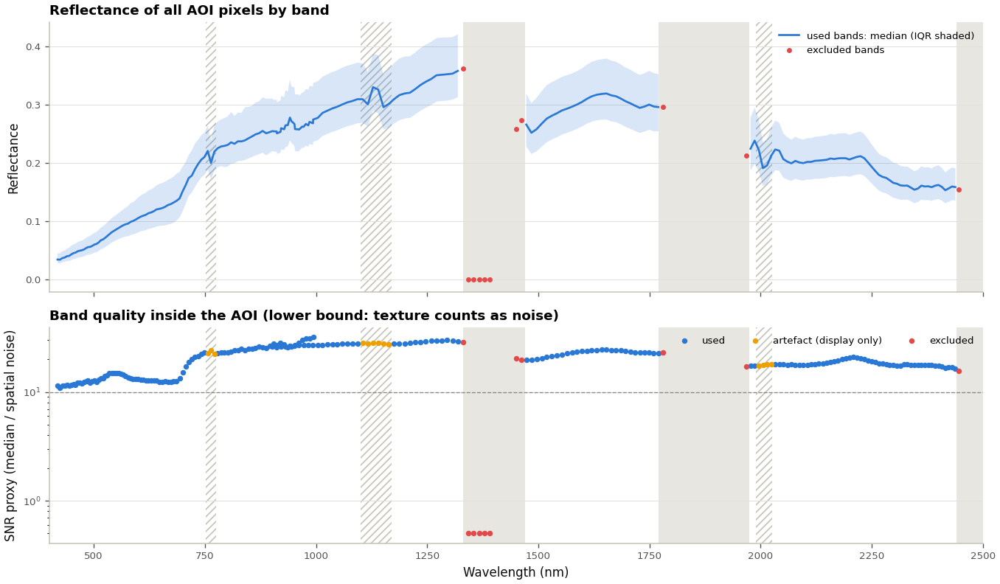

In [6]:
fig, axes = plt.subplots(2, 1, figsize=(11.5, 6.8), sharex=True, gridspec_kw={"height_ratios": [1.25, 1]})
_valid_px = AOI_MASK & VALID_ALL
_med = np.array([np.nanmedian(CUBE[:, :, b][AOI_MASK]) if np.isfinite(CUBE[:, :, b][AOI_MASK]).any() else np.nan
                 for b in range(NB)])
_q1 = np.array([np.nanpercentile(CUBE[:, :, b][AOI_MASK], 25) if np.isfinite(CUBE[:, :, b][AOI_MASK]).any() else np.nan
                for b in range(NB)])
_q3 = np.array([np.nanpercentile(CUBE[:, :, b][AOI_MASK], 75) if np.isfinite(CUBE[:, :, b][AOI_MASK]).any() else np.nan
                for b in range(NB)])
ax = axes[0]
ax.set_xlim(400, 2500)
shade_ranges(ax)
_xg, _yg = with_gaps(WL[GOOD], _med[GOOD]); _, _q1g = with_gaps(WL[GOOD], _q1[GOOD]); _, _q3g = with_gaps(WL[GOOD], _q3[GOOD])
ax.fill_between(_xg, _q1g, _q3g, color=SERIES[0], alpha=0.18, lw=0)
ax.plot(_xg, _yg, color=SERIES[0], lw=1.6, label="used bands: median (IQR shaded)")
ax.scatter(WL[EXCLUDED], np.nan_to_num(_med[EXCLUDED], nan=0.0), s=10, color=SERIES[7], zorder=5, label="excluded bands")
ax.set_ylabel("Reflectance"); ax.set_title("Reflectance of all AOI pixels by band", fontsize=11, loc="left")
style_chart(ax); ax.legend(fontsize=8, loc="upper right")
ax = axes[1]
_snr = BANDQ["snr_proxy"].to_numpy()
for lab, sel, col in [("used", BANDQ["status"].eq("used").to_numpy(), SERIES[0]),
                      ("artefact (display only)", BANDQ["status"].str.startswith("artefact").to_numpy(), SERIES[3]),
                      ("excluded", EXCLUDED, SERIES[7])]:
    ax.scatter(WL[sel], np.clip(np.nan_to_num(_snr[sel], nan=0.5), 0.5, None), s=12, color=col, label=lab, zorder=4)
ax.set_yscale("log"); ax.axhline(10, color=MUTED, lw=0.8, ls="--")
ax.set_ylabel("SNR proxy (median / spatial noise)"); ax.set_xlabel("Wavelength (nm)")
ax.set_title("Band quality inside the AOI (lower bound: texture counts as noise)", fontsize=11, loc="left")
shade_ranges(ax); style_chart(ax); ax.legend(fontsize=8, loc="upper right", ncol=3)
fig.tight_layout(); save_fig(fig, "fig_00_band_quality"); plt.show()

## 4 · Analysis masks: quality layers, water, vegetation, dry plant material and dark pixels

No quality layers supplied (QUALITY_LAYERS = {}): check the natural-colour composite for cloud and haze.
                   class  pixels  area_km2  percent_of_AOI
                Analysed   17050    15.345            28.7
 Green vegetation (NDVI)   29768    26.791            50.1
Dry plant material (CAI)   11999    10.799            20.2
 Open water (NDWI + NIR)     519     0.467             0.9
           Dark / shadow     106     0.095             0.2
Quality layer or no data       0     0.000             0.0

All percentages and areas below refer to the 17,050 analysed pixels (15.34 km²) unless stated otherwise.
  saved  fig_01_analysis_mask.png  +  fig_01_analysis_mask.pdf   (400 dpi)


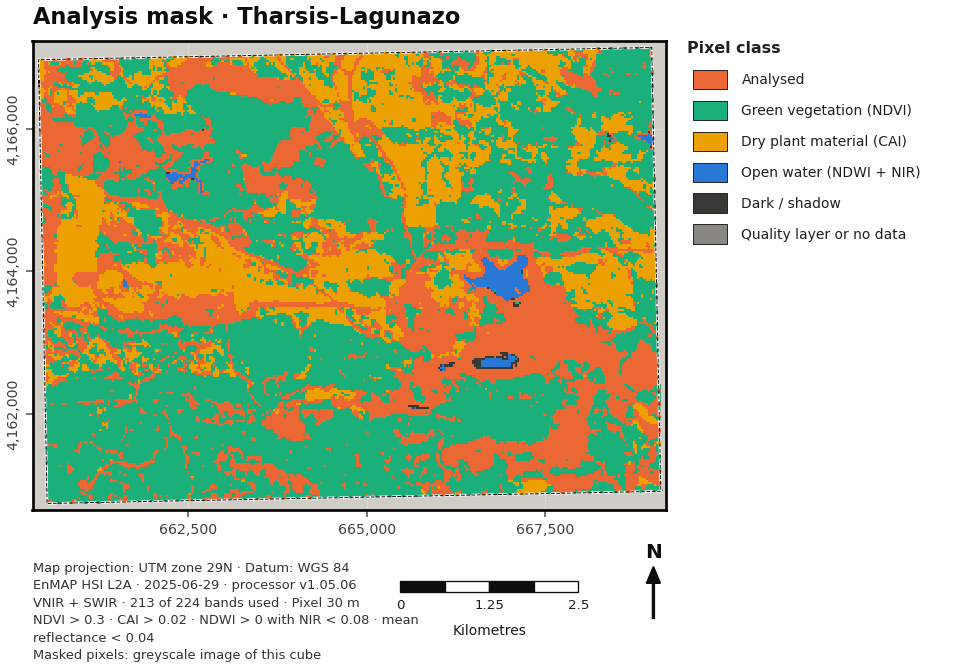

  saved  fig_02_mask_indices.png  +  fig_02_mask_indices.pdf   (400 dpi)


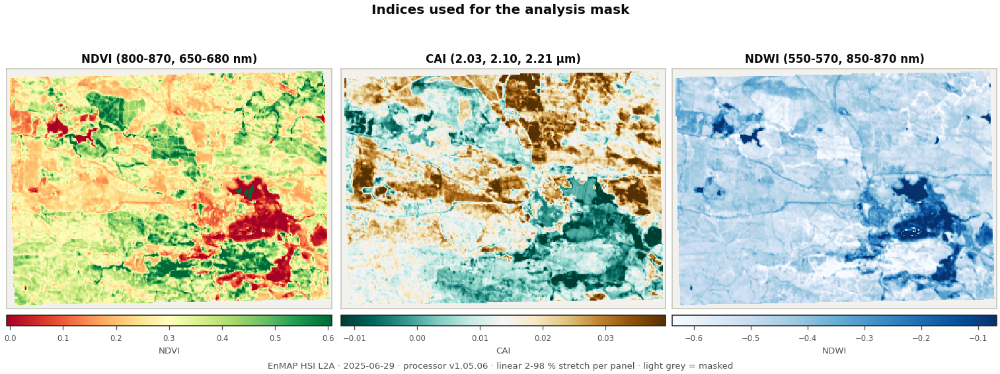

In [7]:
def band_mean(lo, hi, cube=None):
    """Mean reflectance over used, non-artefact bands with centres in [lo, hi] nm."""
    idx = np.where(GOOD & ~ART & (WL >= lo) & (WL <= hi))[0]
    if idx.size == 0:
        idx = np.where(GOOD & (WL >= lo) & (WL <= hi))[0]
    if idx.size == 0:
        raise ValueError(f"No usable band between {lo} and {hi} nm")
    c = CUBE if cube is None else cube
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", RuntimeWarning)
        return np.nanmean(c[:, :, idx], axis=2)

def read_layer_to_grid(path, categorical=True):
    """Read a raster onto the cube grid (nearest for classes, average for finer continuous rasters)."""
    dst = np.full((H, W), np.nan, dtype="float32")
    with rasterio.open(_resolve(path)) as src:
        a = abs(src.transform.a)
        method = Resampling.nearest if categorical or a >= 0.95 * PIXEL_M else Resampling.average
        reproject(source=rasterio.band(src, 1), destination=dst, src_transform=src.transform, src_crs=src.crs or CRS,
                  src_nodata=src.nodata, dst_transform=TRANSFORM, dst_crs=CRS, dst_nodata=np.nan, resampling=method)
    return dst

with np.errstate(divide="ignore", invalid="ignore"), warnings.catch_warnings():
    R_G, R_RED, R_NIR = band_mean(550, 570), band_mean(650, 680), band_mean(800, 870)
    R_NIRW = band_mean(850, 870)
    NDVI = ((R_NIR - R_RED) / (R_NIR + R_RED)).astype("float32")
    NDWI = ((R_G - R_NIRW) / (R_G + R_NIRW)).astype("float32")
    CAI = (0.5 * (band_mean(2015, 2045) + band_mean(2195, 2225)) - band_mean(2085, 2115)).astype("float32")
    ALBEDO = np.zeros((H, W), "float32")
    for _b in np.where(GOOD & ~ART)[0]:
        ALBEDO += CUBE[:, :, _b]
    ALBEDO /= np.float32((GOOD & ~ART).sum())  # NaN where any used band is fill
for _a in (NDVI, NDWI, CAI, ALBEDO):
    _a[~AOI_MASK] = np.nan
_lum = band_mean(640, 660) * 0.30 + band_mean(550, 570) * 0.59 + band_mean(460, 480) * 0.11
UNDERLAY = 0.35 + 0.45 * pct_stretch(np.where(AOI_MASK & VALID_ALL, _lum, np.nan))  # mid grey: white classes stay visible

QL_BAD = np.zeros((H, W), bool)
ql_rows = []
for name, path in QUALITY_LAYERS.items():
    lay = read_layer_to_grid(path, categorical=True)
    flag = AOI_MASK & np.isfinite(lay) & (lay == 1)
    QL_BAD |= flag
    ql_rows.append(f"{name}: {int(flag.sum()):,} px")
    if flag.sum() > 0.5 * AOI_MASK.sum():
        print(f"WARNING: quality layer '{name}' flags {100 * flag.sum() / AOI_MASK.sum():.0f} % of the AOI. Check that the "
              "file is the right layer and that 1 means 'flagged' (EnMAP QL_QUALITY_* masks: 0 = clear, 1 = flagged).")
if ql_rows:
    print("Quality layers inside the AOI: " + "; ".join(ql_rows))
else:
    print("No quality layers supplied (QUALITY_LAYERS = {}): check the natural-colour composite for cloud and haze.")

INVALID = AOI_MASK & ~VALID_ALL
WATER = AOI_MASK & VALID_ALL & (NDWI > WATER_NDWI_MIN) & (R_NIRW < WATER_NIR_MAX)
VEG   = AOI_MASK & VALID_ALL & (NDVI > NDVI_VEG_THRESHOLD)
NPV   = AOI_MASK & VALID_ALL & (CAI > CAI_NPV_THRESHOLD)
DARK  = AOI_MASK & VALID_ALL & (ALBEDO < DARK_MEAN_MAX)

MASK_CODE = np.full((H, W), -1, dtype=np.int16)
MASK_CODE[AOI_MASK] = 0
MASK_CODE[DARK] = 4
MASK_CODE[NPV] = 2
MASK_CODE[VEG] = 1
MASK_CODE[WATER] = 3
MASK_CODE[QL_BAD | INVALID] = 5
MASK_NAMES  = ["Analysed", "Green vegetation (NDVI)", "Dry plant material (CAI)", "Open water (NDWI + NIR)",
               "Dark / shadow", "Quality layer or no data"]
MASK_COLORS = ["#eb6834", "#1baf7a", "#eda100", "#2a78d6", "#383835", "#898781"]
ANALYSED = MASK_CODE == 0
N_AN = int(ANALYSED.sum())
if N_AN < 100:
    raise RuntimeError(f"Only {N_AN} analysed pixels - check the AOI, the scaling (§3) and the mask thresholds.")

n_aoi = int(AOI_MASK.sum())
MASK_TABLE = pd.DataFrame([{"class": n, "pixels": int((MASK_CODE == k).sum()),
                            "area_km2": round(int((MASK_CODE == k).sum()) * PIXEL_AREA_KM2, 3),
                            "percent_of_AOI": round(100 * int((MASK_CODE == k).sum()) / max(n_aoi, 1), 1)}
                           for k, n in enumerate(MASK_NAMES)])
MASK_TABLE.to_csv(TABLE_DIR / "tab_01_mask_summary.csv", index=False, encoding="utf-8-sig")
print(MASK_TABLE.to_string(index=False))
print(f"\nAll percentages and areas below refer to the {N_AN:,} analysed pixels ({N_AN * PIXEL_AREA_KM2:.2f} km²) "
      f"unless stated otherwise.")
if N_AN < 0.15 * n_aoi:
    print(f"NOTE: only {100 * N_AN / n_aoi:.1f} % of the AOI is analysed; results describe the bare surfaces of this scene.")

fig = plot_categorical(MASK_CODE, f"Analysis mask · {SITE_NAME}", MASK_COLORS, MASK_NAMES, fname="fig_01_analysis_mask",
                       key_title="Pixel class",
                       extra=[f"NDVI > {NDVI_VEG_THRESHOLD:g} · CAI > {CAI_NPV_THRESHOLD:g} · NDWI > {WATER_NDWI_MIN:g} "
                              f"with NIR < {WATER_NIR_MAX:g} · mean reflectance < {DARK_MEAN_MAX:g}"])
plt.show()
fig = panel_maps([NDVI, CAI, NDWI], ["NDVI (800-870, 650-680 nm)", "CAI (2.03, 2.10, 2.21 µm)",
                                    "NDWI (550-570, 850-870 nm)"], ["RdYlGn", "BrBG_r", "Blues"],
                 "Indices used for the analysis mask", fname="fig_02_mask_indices", cbar_labels=["NDVI", "CAI", "NDWI"])
plt.show()

## 5 · Colour composites and the mean spectra

Composites show all valid AOI pixels (no analysis mask), each band averaged over ±10 nm.

* **Natural colour** (R 640–660, G 550–570, B 460–480 nm) for context and a visual check for cloud and haze.
* **Colour infrared** (R 850–870, G 640–660, B 550–570 nm): vegetation red.
* **SWIR composite** (R 2190–2210, G 1640–1660, B 850–870 nm): bare waste units in contrasting hues. Hues depend on
  mineralogy, moisture and grain size, so they are context, not classification.

The mean-spectra figure shows the median spectrum of the analysed pixels and zooms into the detector overlap before
and after harmonisation.

  saved  fig_03_natural_colour.png  +  fig_03_natural_colour.pdf   (400 dpi)


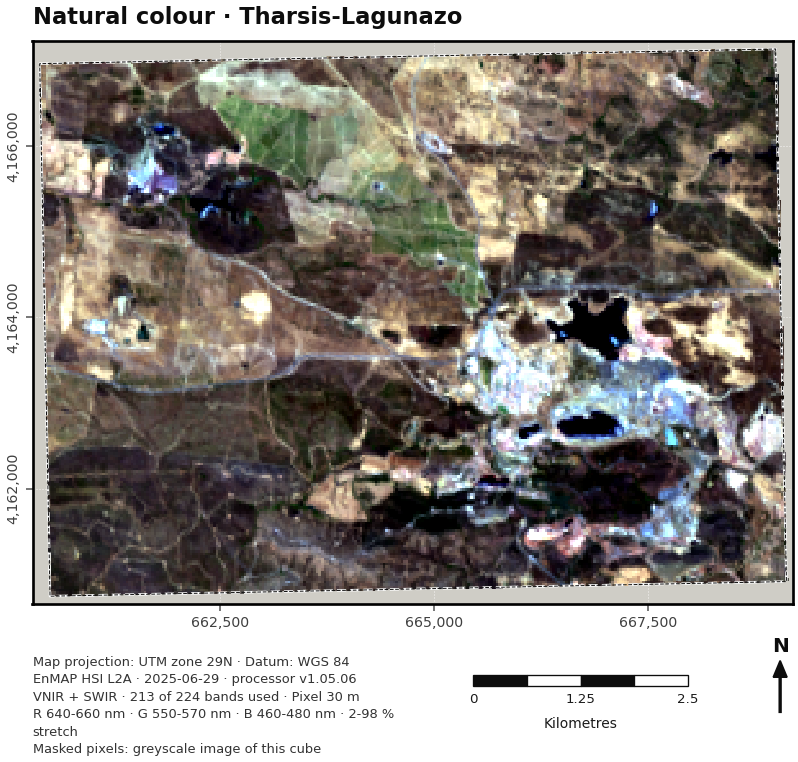

  saved  fig_04_colour_infrared.png  +  fig_04_colour_infrared.pdf   (400 dpi)


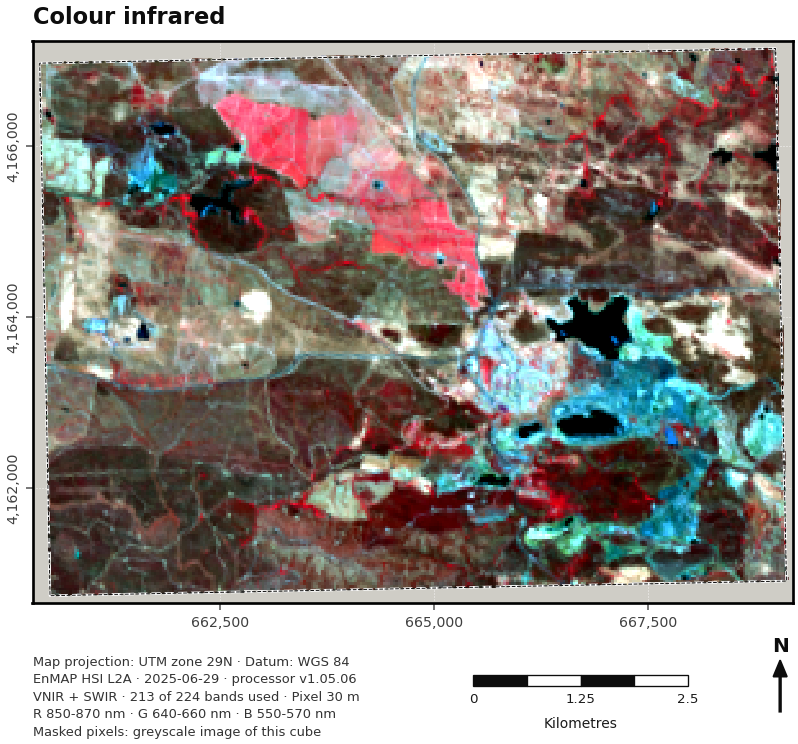

  saved  fig_05_swir_composite.png  +  fig_05_swir_composite.pdf   (400 dpi)


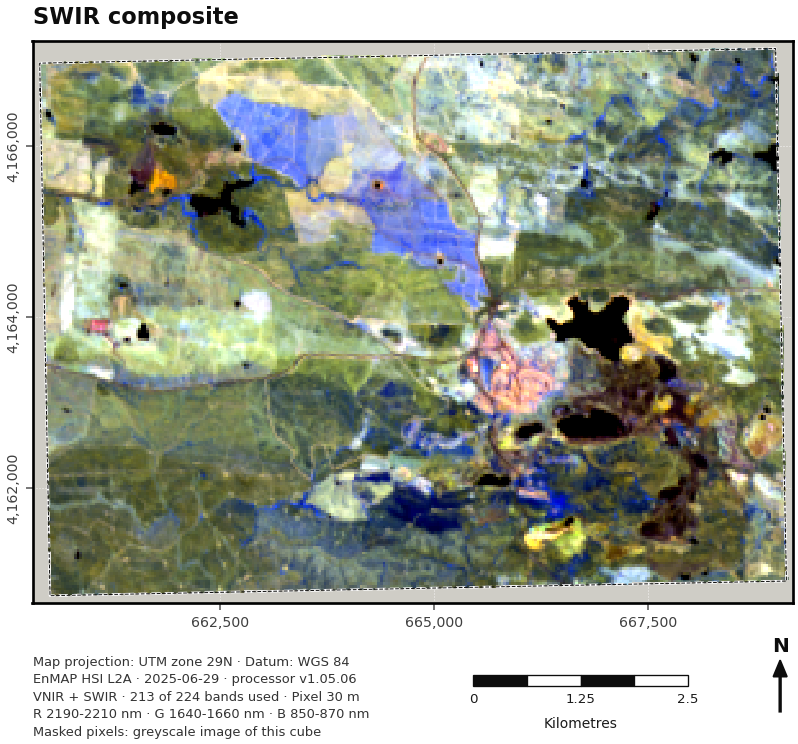

  saved  fig_06_mean_spectra_overlap.png  +  fig_06_mean_spectra_overlap.pdf   (400 dpi)


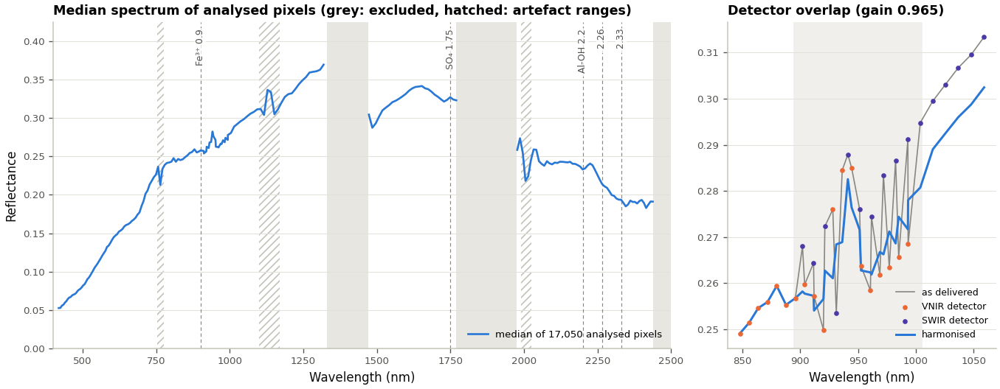

In [8]:
def _ctx(arr):
    out = np.array(arr, dtype="float32", copy=True); out[~(AOI_MASK & VALID_ALL)] = np.nan
    return out

fig = plot_rgb(make_rgb(_ctx(band_mean(640, 660)), _ctx(band_mean(550, 570)), _ctx(band_mean(460, 480))),
               f"Natural colour · {SITE_NAME}", subtitle="R 640-660 nm · G 550-570 nm · B 460-480 nm · 2-98 % stretch",
               fname="fig_03_natural_colour")
plt.show()
fig = plot_rgb(make_rgb(_ctx(band_mean(850, 870)), _ctx(band_mean(640, 660)), _ctx(band_mean(550, 570))),
               "Colour infrared", subtitle="R 850-870 nm · G 640-660 nm · B 550-570 nm", fname="fig_04_colour_infrared")
plt.show()
fig = plot_rgb(make_rgb(_ctx(band_mean(2190, 2210)), _ctx(band_mean(1640, 1660)), _ctx(band_mean(850, 870))),
               "SWIR composite", subtitle="R 2190-2210 nm · G 1640-1660 nm · B 850-870 nm", fname="fig_05_swir_composite")
plt.show()

XA = CUBE[ANALYSED]                                     # (analysed pixels, bands), used from §6 on
med_an = np.full(NB, np.nan); med_an[GOOD] = np.median(XA[:, GOOD], axis=0)
fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.6), gridspec_kw={"width_ratios": [2.3, 1]})
ax = axes[0]; ax.set_xlim(400, 2500)
shade_ranges(ax)
ax.plot(*with_gaps(WL[GOOD], med_an[GOOD]), color=SERIES[0], lw=1.6, label=f"median of {N_AN:,} analysed pixels")
ax.set_ylim(0, np.nanmax(med_an[GOOD]) * 1.15)
mark_wavelengths(ax, [(900, "Fe³⁺ 0.9"), (1750, "SO₄ 1.75"), (2200, "Al-OH 2.2"), (2265, "2.26"), (2330, "2.33")])
ax.set_xlabel("Wavelength (nm)"); ax.set_ylabel("Reflectance")
ax.set_title("Median spectrum of analysed pixels (grey: excluded, hatched: artefact ranges)", fontsize=10.5, loc="left")
style_chart(ax); ax.legend(fontsize=8, loc="lower right")
ax = axes[1]
if OVERLAP_RAW is not None:
    sel_z = np.where((WL >= 840) & (WL <= 1060))[0]
    raw_z = med_an[sel_z].copy()
    ov_pos = {j: k for k, j in enumerate(OV_BANDS)}
    raw_ov = np.nanmedian(OVERLAP_RAW[ANALYSED], axis=0)
    for i, j in enumerate(sel_z):
        if j in ov_pos:
            raw_z[i] = raw_ov[ov_pos[j]]
        elif not IS_VNIR[j]:
            raw_z[i] = med_an[j] / SWIR_GAIN
    vs = IS_VNIR[sel_z]
    ax.plot(WL[sel_z], raw_z, color=MUTED, lw=1.0, label="as delivered")
    ax.scatter(WL[sel_z][vs], raw_z[vs], s=9, color=SERIES[1], zorder=4, label="VNIR detector")
    ax.scatter(WL[sel_z][~vs], raw_z[~vs], s=9, color=SERIES[6], zorder=4, label="SWIR detector")
    ax.plot(WL[sel_z], med_an[sel_z], color=SERIES[0], lw=1.8, label="harmonised")
    ax.axvspan(OVERLAP_NM[0], OVERLAP_NM[1], color="#f0efec", zorder=0)
    ax.set_title(f"Detector overlap (gain {SWIR_GAIN:.3f})", fontsize=10.5, loc="left")
    ax.legend(fontsize=7.5, loc="lower right")
else:
    ax.text(0.5, 0.5, "overlap not harmonised", ha="center", va="center", transform=ax.transAxes, color=INK_2)
ax.set_xlabel("Wavelength (nm)"); style_chart(ax)
fig.tight_layout(); save_fig(fig, "fig_06_mean_spectra_overlap"); plt.show()

## 6 · Continuum removal and absorption-feature parameters

**Continuum removal.** In each window (`WINDOWS_NM`) the continuum is the upper convex hull of the spectrum, and the
continuum-removed spectrum is CR = R / hull (Clark & Roush, 1984). The hull is computed over used, non-artefact
bands only, so fill bands, water-vapour windows and residual O₂/H₂O/CO₂ features cannot become shoulders. Before
the hull, each run of consecutive bands is smoothed with a Savitzky–Golay filter (`SMOOTH_WINDOW` bands, quadratic;
Savitzky & Golay, 1964).

**Feature parameters** (van der Meer, 2004; van Ruitenbeek et al., 2014; Hecker et al., 2019). For every feature in
`FEATURES`:

* **band minimum**: the deepest *local* minimum of CR inside the search range (lower than both neighbouring bands).
  A minimum at the edge of the range that continues to fall outside it is not a feature of this range;
* **depth** = 1 − CR at that minimum;
* **wavelength position**: vertex of the parabola through the minimum and its two neighbouring bands.

**Pixel noise and detection.** For each pixel and window, the reflectance noise σ_R is the robust standard
deviation of the second differences across consecutive bands (outside the detector overlap). Converted to
continuum-removed units it becomes σ_CR = σ_R × g / R_continuum, where g is the noise reduction of the smoothing
filter (0.70 for 5 bands) and R_continuum the continuum reflectance at the minimum. Dark pixels therefore need
deeper absorptions than bright ones. A feature is **detected** where

  depth ≥ depth floor + `DEPTH_NOISE_K` × σ_CR.

The floor absorbs systematic effects that do not average out (residual water vapour, calibration). The k term
covers noise, including the tendency of the deepest of several noisy bands to look like a feature. Two further
rules:

* **Fe³⁺ (0.9 µm)**: the band minimum must also be the deepest point of CR between `FE_DEEPEST_NM` (750–1250 nm).
  This rejects Fe²⁺-bearing silicates (chlorite, amphibole, pyroxene), whose broad 1.0–1.1 µm band would otherwise
  yield a false "minimum" where the 0.94 µm water-vapour residual cuts its short-wavelength wing.
* **Kaolinite doublet**: ratio of the depth at 2.155–2.18 µm to the Al-OH depth (kaolinite 2.165/2.206 µm;
  Clark et al., 1990).

The cell also checks the 0.94 µm water-vapour residual on pixels without an Fe³⁺ feature: a dip there biases Fe³⁺
positions of shallow features towards goethite.

> The five feature keys (`Fe3_900`, `SO4_1750`, `AlOH_2200`, `FeOH_2265`, `MgOH_2330`) are used by the rules in §7.
> Change their ranges and floors in CONFIG, not their names.

Continuum removal and features for 17,050 analysed pixels in 5.6 s (Savitzky-Golay 5 bands, noise factor 0.70)
  window VNIR  470-1250 nm: 103 bands (473-1247 nm)
  window SWIR1 1500-1770 nm: 25 bands (1507-1770 nm)
  window SWIR2 2025-2435 nm: 49 bands (2033-2430 nm)

Detection summary (percentages of analysed pixels):
  feature window search_nm  depth_floor  median_sigma_CR  median_threshold  p90_threshold  local_min_found_pct  detected_px  detected_pct  detected_km2  median_depth_detected  p10_position_nm  median_position_nm  p90_position_nm
  Fe3_900   VNIR   840-980        0.040           0.0025            0.0475         0.0503                100.0        16877          99.0        15.189                 0.0838         916.2600            957.4422         964.1658
 SO4_1750  SWIR1 1735-1765        0.015           0.0024            0.0221         0.0253                  3.0           59           0.3         0.053                 0.0343        1734.6734           1741.2211        1

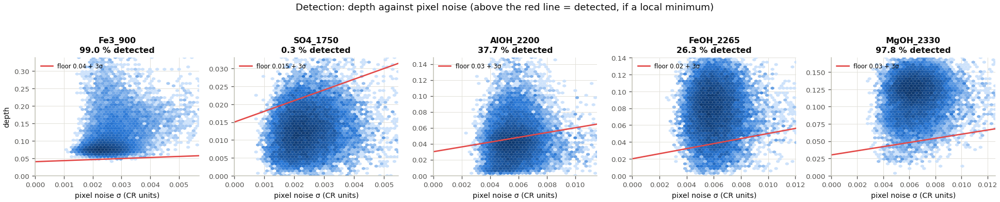

In [9]:
from scipy.signal import savgol_coeffs

REQUIRED_FEATURES = ["Fe3_900", "SO4_1750", "AlOH_2200", "FeOH_2265", "MgOH_2330"]
_missing_f = [k for k in REQUIRED_FEATURES if k not in FEATURES]
if _missing_f:
    raise KeyError(f"FEATURES is missing {_missing_f}; §7 needs all five keys.")
WIN_BANDS = {w: np.where(GOOD & ~ART & (WL >= lo) & (WL <= hi))[0] for w, (lo, hi) in WINDOWS_NM.items()}
for w, idx in WIN_BANDS.items():
    if idx.size < 8:
        raise ValueError(f"Window {w} {WINDOWS_NM[w]} has only {idx.size} usable bands - check EXCLUDE/ARTEFACT ranges.")
SG_WIN = int(SMOOTH_WINDOW) if SMOOTH_WINDOW and int(SMOOTH_WINDOW) >= 3 else 0
if SG_WIN and SG_WIN % 2 == 0:
    SG_WIN += 1
SG_NOISE_FACTOR = float(np.sqrt(np.sum(savgol_coeffs(SG_WIN, 2) ** 2))) if SG_WIN else 1.0
KAOLINITE_MAIN_MIN_NM = 2195   # kaolinite-like needs its main Al-OH minimum at >= 2.195 µm (kaolinite 2.206 µm)
DOUBLET_RANGE_NM = (2155, 2180)

def contiguous_runs(idx):
    """Positions in idx grouped into runs of consecutive band numbers."""
    idx = np.asarray(idx)
    return np.split(np.arange(idx.size), np.where(np.diff(idx) > 1)[0] + 1)

def smooth_spectra(Y, idx):
    if not SG_WIN:
        return Y
    Y = Y.copy()
    for run in contiguous_runs(idx):
        if run.size >= SG_WIN:
            Y[:, run] = savgol_filter(Y[:, run], SG_WIN, 2, axis=1, mode="interp")
    return Y

def upper_hull_continuum(x, Y, max_iter=1000):
    """Upper convex hull of each row of Y (N x M) over wavelengths x, interpolated to every band (vectorised)."""
    N, M = Y.shape
    keep = np.ones((N, M), bool)
    ar = np.arange(M)
    for _ in range(max_iter):
        prev = np.maximum.accumulate(np.where(keep, ar, -1), axis=1)
        prev = np.concatenate([np.full((N, 1), -1), prev[:, :-1]], axis=1)
        nxt = np.minimum.accumulate(np.where(keep, ar, M)[:, ::-1], axis=1)[:, ::-1]
        nxt = np.concatenate([nxt[:, 1:], np.full((N, 1), M)], axis=1)
        inner = keep & (prev >= 0) & (nxt < M)
        p, n = np.clip(prev, 0, M - 1), np.clip(nxt, 0, M - 1)
        yp, yn = np.take_along_axis(Y, p, 1), np.take_along_axis(Y, n, 1)
        with np.errstate(invalid="ignore", divide="ignore"):
            chord = yp + (yn - yp) * (x[None, :] - x[p]) / (x[n] - x[p])
        drop = inner & (Y < chord - 1e-12 * np.abs(chord))
        if not drop.any():
            break
        keep &= ~drop
    prev = np.maximum.accumulate(np.where(keep, ar, -1), axis=1)
    nxt = np.minimum.accumulate(np.where(keep, ar, M)[:, ::-1], axis=1)[:, ::-1]
    yp, yn = np.take_along_axis(Y, prev, 1), np.take_along_axis(Y, nxt, 1)
    with np.errstate(invalid="ignore", divide="ignore"):
        t = np.where(x[nxt] > x[prev], (x[None, :] - x[prev]) / (x[nxt] - x[prev]), 0.0)
    return yp + (yn - yp) * t

def window_cr(X, w, smooth=True):
    idx = WIN_BANDS[w]
    Y = X[:, idx].astype("float64")
    if smooth:
        Y = smooth_spectra(Y, idx)
    with np.errstate(invalid="ignore", divide="ignore"):
        return (Y / upper_hull_continuum(WL[idx], Y)).astype("float32")

def pixel_noise(X, idx):
    """Per-pixel robust noise (reflectance units) from second differences of consecutive bands outside the overlap."""
    use = [j for j in idx if not (OVERLAP_NM and OVERLAP_NM[0] <= WL[j] <= OVERLAP_NM[1])]
    trip = [(a, b, c) for a, b, c in zip(use[:-2], use[1:-1], use[2:]) if b == a + 1 and c == b + 1]
    if len(trip) < 5:
        return np.full(len(X), np.nan, dtype="float32")
    a, b, c = (np.array(t) for t in zip(*trip))
    wa = (WL[c] - WL[b]) / (WL[c] - WL[a]); wc = 1.0 - wa
    e = (X[:, b] - (wa * X[:, a] + wc * X[:, c])) / np.sqrt(1 + wa ** 2 + wc ** 2)
    return (1.4826 * np.median(np.abs(e), axis=1)).astype("float32")

def feature_parameters(cr, x, rng):
    """Deepest local minimum of CR inside rng: index, depth, parabolic position; plus the deepest point regardless."""
    N, M = cr.shape
    rows_ = np.arange(N)
    loc = np.zeros((N, M), bool)
    loc[:, 1:-1] = (cr[:, 1:-1] <= cr[:, :-2]) & (cr[:, 1:-1] <= cr[:, 2:]) & (cr[:, 1:-1] < 1 - 1e-6)
    inr = (x >= rng[0]) & (x <= rng[1])
    masked = np.where(loc & inr[None, :], cr, np.inf)
    k = masked.argmin(axis=1)
    has = np.isfinite(masked[rows_, k])
    k_any = np.where(inr[None, :], cr, np.inf).argmin(axis=1)
    kk = np.where(has, k, k_any)
    k1 = np.clip(kk, 1, M - 2)
    x0, x1, x2 = x[k1 - 1], x[k1], x[k1 + 1]
    y0, y1, y2 = cr[rows_, k1 - 1], cr[rows_, k1], cr[rows_, k1 + 1]
    num = (x1 - x0) ** 2 * (y1 - y2) - (x1 - x2) ** 2 * (y1 - y0)
    den = (x1 - x0) * (y1 - y2) - (x1 - x2) * (y1 - y0)
    with np.errstate(invalid="ignore", divide="ignore"):
        pos = x1 - 0.5 * num / den
    pos = np.where(np.isfinite(pos), np.clip(pos, x0, x2), x1)
    return {"k": kk, "has": has, "depth": np.where(has, 1 - cr[rows_, kk], 0.0).astype("float32"),
            "depth_any": (1 - cr[rows_, k_any]).astype("float32"), "pos": np.where(has, pos, np.nan).astype("float32")}

def analyse_spectra(X, smooth=True, keep_cr=True, chunk=40000):
    """Continuum removal, feature parameters, pixel noise and the extra Fe3+ rule for spectra X (N x bands)."""
    N = len(X)
    res = {f: {"depth": np.zeros(N, "float32"), "depth_any": np.zeros(N, "float32"), "pos": np.zeros(N, "float32"),
               "sigma": np.zeros(N, "float32"), "has": np.zeros(N, bool), "rule_ok": np.ones(N, bool)} for f in FEATURES}
    res["doublet"] = np.zeros(N, "float32")
    crs = {w: np.zeros((N, WIN_BANDS[w].size), "float32") for w in WIN_BANDS} if keep_cr else None
    g_sg = SG_NOISE_FACTOR if (smooth and SG_WIN) else 1.0
    for s0 in range(0, N, chunk):
        Xc = np.asarray(X[s0:s0 + chunk], dtype="float64")
        n = len(Xc); rows_ = np.arange(n)
        crc = {w: window_cr(Xc, w, smooth) for w in WIN_BANDS}
        noise = {w: pixel_noise(Xc, WIN_BANDS[w]) for w in WIN_BANDS}
        for f, (w, rng, floor, label) in FEATURES.items():
            idx, x = WIN_BANDS[w], WL[WIN_BANDS[w]]
            r = feature_parameters(crc[w], x, rng)
            level = Xc[rows_, idx[r["k"]]] / np.maximum(crc[w][rows_, r["k"]], 1e-3)
            sl = slice(s0, s0 + n)
            res[f]["depth"][sl], res[f]["depth_any"][sl], res[f]["pos"][sl] = r["depth"], r["depth_any"], r["pos"]
            res[f]["has"][sl] = r["has"]
            res[f]["sigma"][sl] = noise[w] * g_sg / np.maximum(level, 1e-4)
            if f == "Fe3_900":
                broad = (x >= FE_DEEPEST_NM[0]) & (x <= FE_DEEPEST_NM[1])
                gpos = x[np.where(broad[None, :], crc[w], np.inf).argmin(axis=1)]
                res[f]["rule_ok"][sl] = (gpos >= rng[0]) & (gpos <= rng[1])
        x2 = WL[WIN_BANDS["SWIR2"]]
        dsel = (x2 >= DOUBLET_RANGE_NM[0]) & (x2 <= DOUBLET_RANGE_NM[1])
        d_al = res["AlOH_2200"]["depth"][s0:s0 + n]
        with np.errstate(invalid="ignore", divide="ignore"):
            res["doublet"][s0:s0 + n] = np.where(d_al > 0, (1 - crc["SWIR2"][:, dsel].min(axis=1)) / d_al, 0.0)
        if keep_cr:
            for w in WIN_BANDS:
                crs[w][s0:s0 + n] = crc[w]
    return res, crs

def thresholds(res, factor=1.0):
    return {f: factor * (FEATURES[f][2] + DEPTH_NOISE_K * res[f]["sigma"]) for f in FEATURES}

def detect(res, factor=1.0):
    thr = thresholds(res, factor)
    return {f: res[f]["has"] & res[f]["rule_ok"] & (res[f]["depth"] >= thr[f]) for f in FEATURES}

def to_map(v, fill=np.nan, dtype="float32", mask=None):
    m = ANALYSED if mask is None else mask
    out = np.full((H, W), fill, dtype=dtype)
    out[m] = v
    return out

import time as _time
_t0 = _time.time()
RES, CRW = analyse_spectra(XA)
DET = detect(RES)
THR = thresholds(RES)
print(f"Continuum removal and features for {N_AN:,} analysed pixels in {_time.time() - _t0:.1f} s "
      f"(Savitzky-Golay {SG_WIN or 'off'} bands, noise factor {SG_NOISE_FACTOR:.2f})")
for w, idx in WIN_BANDS.items():
    print(f"  window {w:<5} {WINDOWS_NM[w][0]}-{WINDOWS_NM[w][1]} nm: {idx.size} bands ({WL[idx[0]]:.0f}-{WL[idx[-1]]:.0f} nm)")

feat_rows = []
for f, (w, rng, floor, label) in FEATURES.items():
    d = DET[f]; n_det = int(d.sum())
    feat_rows.append({"feature": f, "label": label, "window": w, "search_nm": f"{rng[0]}-{rng[1]}", "depth_floor": floor,
                      "k": DEPTH_NOISE_K, "median_sigma_CR": float(np.median(RES[f]["sigma"])),
                      "median_threshold": float(np.median(THR[f])), "p90_threshold": float(np.percentile(THR[f], 90)),
                      "local_min_found_pct": round(100 * RES[f]["has"].mean(), 1),
                      "detected_px": n_det, "detected_pct": round(100 * n_det / N_AN, 1),
                      "detected_km2": round(n_det * PIXEL_AREA_KM2, 3),
                      "median_depth_detected": float(np.median(RES[f]["depth"][d])) if n_det else np.nan,
                      "p10_position_nm": float(np.percentile(RES[f]["pos"][d], 10)) if n_det else np.nan,
                      "median_position_nm": float(np.median(RES[f]["pos"][d])) if n_det else np.nan,
                      "p90_position_nm": float(np.percentile(RES[f]["pos"][d], 90)) if n_det else np.nan})
FEAT_TABLE = pd.DataFrame(feat_rows)
FEAT_TABLE.to_csv(TABLE_DIR / "tab_02_feature_detection.csv", index=False, float_format="%.4f", encoding="utf-8-sig")
print("\nDetection summary (percentages of analysed pixels):")
print(FEAT_TABLE.drop(columns=["label", "k"]).round(4).to_string(index=False))
_fe_rej = int((RES["Fe3_900"]["has"] & ~RES["Fe3_900"]["rule_ok"]).sum())
print(f"\nFe³⁺ local minima rejected because a deeper absorption lies outside 840-980 nm within "
      f"{FE_DEEPEST_NM[0]}-{FE_DEEPEST_NM[1]} nm: {_fe_rej:,} px")

# 0.94 µm water-vapour residual on pixels without an Fe3+ feature
_nofe = ~DET["Fe3_900"]
if _nofe.sum() >= 50:
    def _bm(lo, hi):
        j = np.where(GOOD & (WL >= lo) & (WL <= hi))[0]
        return XA[_nofe][:, j].mean(axis=1), WL[j].mean()
    (_a, _wa), (_c, _wc), (_b, _wb) = _bm(900, 915), _bm(930, 950), _bm(965, 980)
    _interp = _a + (_b - _a) * (_wc - _wa) / (_wb - _wa)
    H2O_094_NOTCH = float(np.median(1 - _c / _interp))
    print(f"0.94 µm residual on {int(_nofe.sum()):,} pixels without an Fe³⁺ feature: median notch depth "
          f"{H2O_094_NOTCH:+.3f}")
    if H2O_094_NOTCH > 0.01:
        print(f"  WARNING: a water-vapour residual of ~{100 * H2O_094_NOTCH:.1f} % sits at 0.94 µm. It is below the Fe³⁺ "
              f"floor ({FEATURES['Fe3_900'][2]:g}) but pulls band minima of shallow Fe³⁺ features towards 0.93-0.94 µm, "
              "i.e. towards 'goethite/jarosite-like'. Treat Fe³⁺ positions of features shallower than ~0.08 with caution.")
else:
    H2O_094_NOTCH = np.nan

fig, axes = plt.subplots(1, len(FEATURES), figsize=(3.3 * len(FEATURES), 3.4), squeeze=False)
for ax, (f, (w, rng, floor, label)) in zip(axes.ravel(), FEATURES.items()):
    s_ = RES[f]["sigma"]; d_ = np.where(RES[f]["has"], RES[f]["depth"], RES[f]["depth_any"])
    ok_ = np.isfinite(s_) & np.isfinite(d_)
    x_hi = np.percentile(s_[ok_], 99); y_hi = max(np.percentile(d_[ok_], 99.5), floor * 2)
    hb = ax.hexbin(s_[ok_], d_[ok_], gridsize=45, extent=(0, x_hi, 0, y_hi), bins="log", cmap=SEQ_BLUE, mincnt=1,
                   linewidths=0)
    xs = np.linspace(0, x_hi, 50)
    ax.plot(xs, floor + DEPTH_NOISE_K * xs, color=SERIES[7], lw=1.6, label=f"floor {floor:g} + {DEPTH_NOISE_K:g}σ")
    ax.set_xlim(0, x_hi); ax.set_ylim(0, y_hi)
    ax.set_title(f"{f}\n{100 * DET[f].mean():.1f} % detected", fontsize=9.5)
    ax.set_xlabel("pixel noise σ (CR units)", fontsize=8.5); ax.set_ylabel("depth" if ax is axes[0, 0] else "", fontsize=8.5)
    style_chart(ax, grid_axis="both"); ax.legend(fontsize=7, loc="upper left")
fig.suptitle("Detection: depth against pixel noise (above the red line = detected, if a local minimum)", fontsize=11,
             color=INK)
fig.tight_layout(rect=(0, 0, 1, 0.95)); save_fig(fig, "fig_07_detection_diagnostics"); plt.show()

## 7 · Mineral-feature maps, SWIR groups, Fe³⁺ classes and the Fe-mineral assemblage

**Depth and position maps** show each feature only where it is detected (white: analysed, not detected). Positions
are the physically most informative parameter: the Al-OH minimum shifts from ~2.165–2.18 µm (alunite,
pyrophyllite) through ~2.206 µm (kaolinite) and 2.195–2.21 µm (muscovite/illite) to 2.215–2.225 µm (phengite)
(Duke, 1994; van Ruitenbeek et al., 2014). The Fe³⁺ crystal-field minimum lies near 0.85–0.89 µm in hematite and
0.90–0.94 µm in goethite, jarosite, schwertmannite and ferrihydrite (Morris et al., 1985; Crowley et al., 2003).

**SWIR groups** (rule-based, from detected features only):

| Code | Group | Rule |
|---|---|---|
| 1 | Jarosite-like | 2.25–2.29 µm is the deepest detected SWIR feature, no 1.75 µm band |
| 2 | Sulphate-like (gypsum, alunite) | 1.75 µm band plus a 2.16–2.29 µm band, Mg-OH not deepest |
| 3 | Kaolinite-like | Al-OH deepest, minimum ≥ 2.195 µm, doublet ratio ≥ `KAOLINITE_DOUBLET` |
| 4 | White mica/illite-like | Al-OH deepest, minimum inside `WHITE_MICA_NM`, no doublet |
| 5 | Other Al-OH | Al-OH deepest, other positions |
| 6 | Mg-OH/carbonate/chlorite-like | 2.30–2.36 µm deepest |
| 0 | No diagnostic SWIR feature | none detected |

**Fe³⁺ classes** by band-minimum position (`FE_POSITION_NM`): hematite-like (< 890 nm), intermediate (890–905 nm;
goethite–hematite mixtures or fine-grained goethite), goethite/jarosite-like (905–950 nm), long-wavelength (> 950 nm;
Fe²⁺ or mixed).

**Fe-mineral assemblage** in the sense of Swayze et al. (2000): jarosite-like where the SWIR group is jarosite-like
**and** an Fe³⁺ band lies at ≥ 890 nm, otherwise the Fe³⁺ class, otherwise "SWIR feature only". Around oxidising
sulphide waste this sequence records decreasing acidity: jarosite precipitates at pH below about 3, schwertmannite
at about pH 3–4.5 and ferrihydrite above about 5, while goethite forms over a wide range and as a transformation
product, and hematite indicates aged or dehydrated material (Bigham et al., 1996; Swayze et al., 2000). The map
shows where these spectral assemblages occur. It does **not** measure acid generation, pH or metal content.

In [10]:
GROUP_NAMES = ["No diagnostic SWIR feature", "Jarosite-like (2.26 µm deepest)", "Sulphate-like (1.75 µm + 2.2 µm)",
               "Kaolinite-like (2.17/2.21 µm doublet)", "White mica/illite-like", "Other Al-OH",
               "Mg-OH/carbonate/chlorite-like"]
GROUP_COLORS = ["#ffffff", "#eda100", "#e87ba4", "#2a78d6", "#1baf7a", "#4a3aa7", "#e34948"]
FE_NAMES  = ["No Fe³⁺ band", f"Hematite-like (< {FE_POSITION_NM[0]} nm)",
             f"Intermediate ({FE_POSITION_NM[0]}-{FE_POSITION_NM[1]} nm)",
             f"Goethite/jarosite-like ({FE_POSITION_NM[1]}-{FE_POSITION_NM[2]} nm)", f"Long-wavelength (> {FE_POSITION_NM[2]} nm)"]
FE_COLORS = ["#ffffff", "#b3202a", "#eb6834", "#eda100", "#4a3aa7"]
ASSEMBLAGE_NAMES = ["No diagnostic feature", "Jarosite-like (2.26 µm + Fe³⁺ ≥ 890 nm)", "Goethite-like Fe³⁺ (905-950 nm)",
                    "Intermediate Fe³⁺ (890-905 nm)", "Hematite-like Fe³⁺ (< 890 nm)", "Long-wavelength Fe band (> 950 nm)",
                    "SWIR feature only (no Fe³⁺ band)"]
ASSEMBLAGE_COLORS = ["#ffffff", "#eda100", "#9c5b1c", "#eb6834", "#b3202a", "#4a3aa7", "#2a78d6"]

def swir_groups(res, det):
    d = np.stack([np.where(det[k], res[k]["depth"], 0.0) for k in ("AlOH_2200", "FeOH_2265", "MgOH_2330")], axis=1)
    any_ = d.max(axis=1) > 0
    deep = d.argmax(axis=1)
    p_al = res["AlOH_2200"]["pos"]
    g = np.zeros(len(deep), dtype=np.int16)
    g[any_ & (deep == 1)] = 1
    g[any_ & (deep == 0)] = 5
    g[any_ & (deep == 0) & (p_al >= WHITE_MICA_NM[0]) & (p_al <= WHITE_MICA_NM[1])] = 4
    g[any_ & (deep == 0) & (p_al >= KAOLINITE_MAIN_MIN_NM) & (res["doublet"] >= KAOLINITE_DOUBLET)] = 3
    g[any_ & (deep == 2)] = 6
    g[any_ & det["SO4_1750"] & (deep != 2)] = 2
    return g

def fe_classes(res, det):
    p, d = res["Fe3_900"]["pos"], det["Fe3_900"]
    a, b, e = FE_POSITION_NM
    c = np.zeros(len(p), dtype=np.int16)
    c[d & (p < a)] = 1
    c[d & (p >= a) & (p <= b)] = 2
    c[d & (p > b) & (p <= e)] = 3
    c[d & (p > e)] = 4
    return c

def assemblage(g, fe):
    a = np.zeros(len(g), dtype=np.int16)
    a[g > 0] = 6
    a[fe == 4] = 5
    a[fe == 1] = 4
    a[fe == 2] = 3
    a[fe == 3] = 2
    a[(g == 1) & ((fe == 2) | (fe == 3))] = 1
    return a

def area_table(codes, names, label):
    rows_ = []
    for k, n in enumerate(names):
        c = int((codes == k).sum())
        rows_.append({label: n, "pixels": c, "area_km2": round(c * PIXEL_AREA_KM2, 3),
                      "percent_of_analysed": round(100 * c / max(len(codes), 1), 1)})
    return pd.DataFrame(rows_)

GROUPS = swir_groups(RES, DET)
FECLS = fe_classes(RES, DET)
ASSEM = assemblage(GROUPS, FECLS)
GROUP_MAP, FE_MAP, ASSEM_MAP = (to_map(v, -1, "int16") for v in (GROUPS, FECLS, ASSEM))
GROUP_TABLE = area_table(GROUPS, GROUP_NAMES, "swir_group")
FE_TABLE = area_table(FECLS, FE_NAMES, "fe3_class")
ASSEM_TABLE = area_table(ASSEM, ASSEMBLAGE_NAMES, "assemblage")
for t, name in [(GROUP_TABLE, "tab_03_swir_groups"), (FE_TABLE, "tab_04_fe3_classes"), (ASSEM_TABLE, "tab_05_assemblage")]:
    t.to_csv(TABLE_DIR / f"{name}.csv", index=False, encoding="utf-8-sig")
    print(t.to_string(index=False)); print()
print(pd.crosstab(pd.Series([GROUP_NAMES[v] for v in GROUPS], name="SWIR group"),
                  pd.Series([FE_NAMES[v] for v in FECLS], name="Fe³⁺ class")).to_string())

                           swir_group  pixels  area_km2  percent_of_analysed
           No diagnostic SWIR feature     201     0.181                  1.2
      Jarosite-like (2.26 µm deepest)     183     0.165                  1.1
     Sulphate-like (1.75 µm + 2.2 µm)       4     0.004                  0.0
Kaolinite-like (2.17/2.21 µm doublet)     378     0.340                  2.2
               White mica/illite-like     496     0.446                  2.9
                          Other Al-OH       1     0.001                  0.0
        Mg-OH/carbonate/chlorite-like   15787    14.208                 92.6

                          fe3_class  pixels  area_km2  percent_of_analysed
                       No Fe³⁺ band     173     0.156                  1.0
           Hematite-like (< 890 nm)     112     0.101                  0.7
          Intermediate (890-905 nm)       2     0.002                  0.0
Goethite/jarosite-like (905-950 nm)    2180     1.962                 12.8
        

  saved  fig_08a_depth_Fe3_900.png  +  fig_08a_depth_Fe3_900.pdf   (400 dpi)


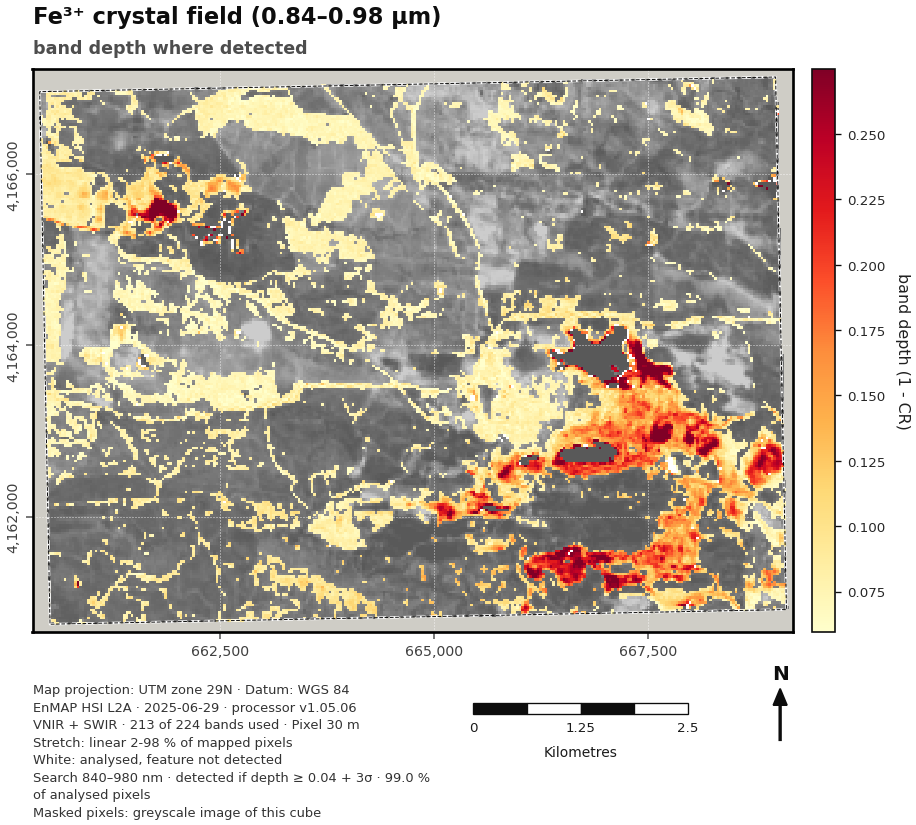

  saved  fig_08b_depth_SO4_1750.png  +  fig_08b_depth_SO4_1750.pdf   (400 dpi)


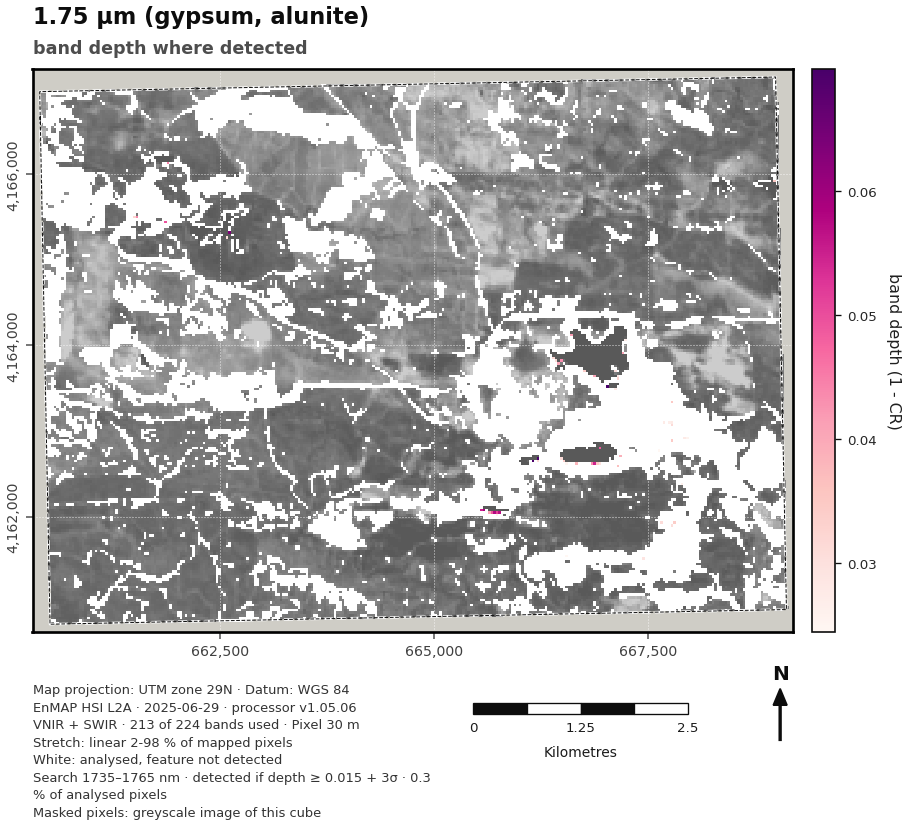

  saved  fig_08c_depth_AlOH_2200.png  +  fig_08c_depth_AlOH_2200.pdf   (400 dpi)


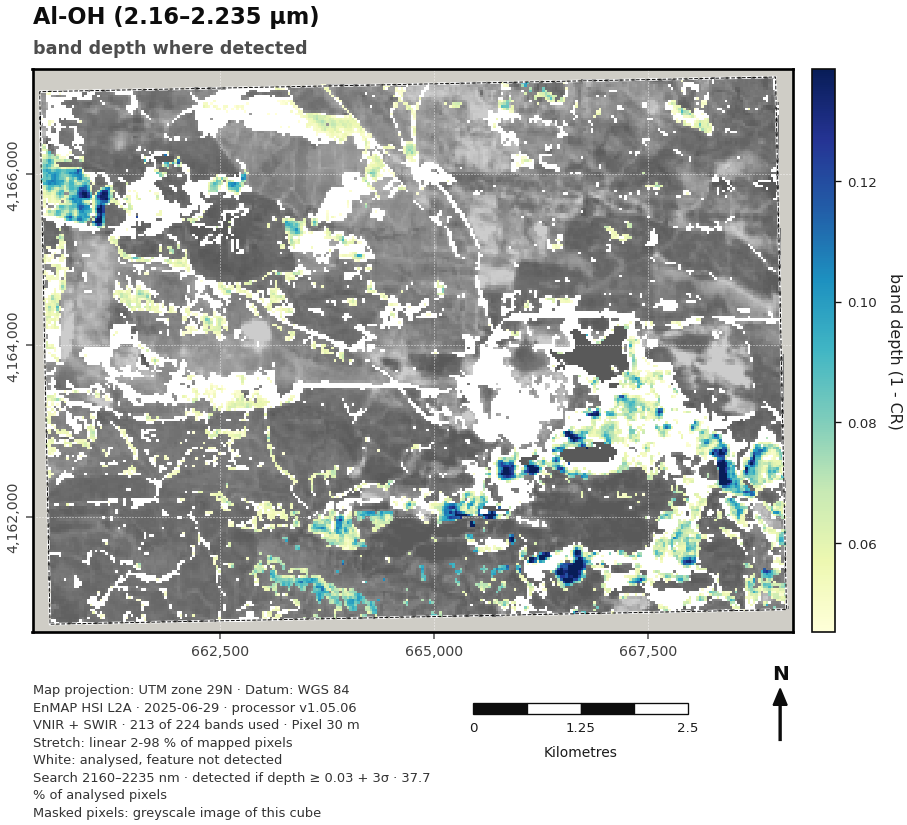

  saved  fig_08d_depth_FeOH_2265.png  +  fig_08d_depth_FeOH_2265.pdf   (400 dpi)


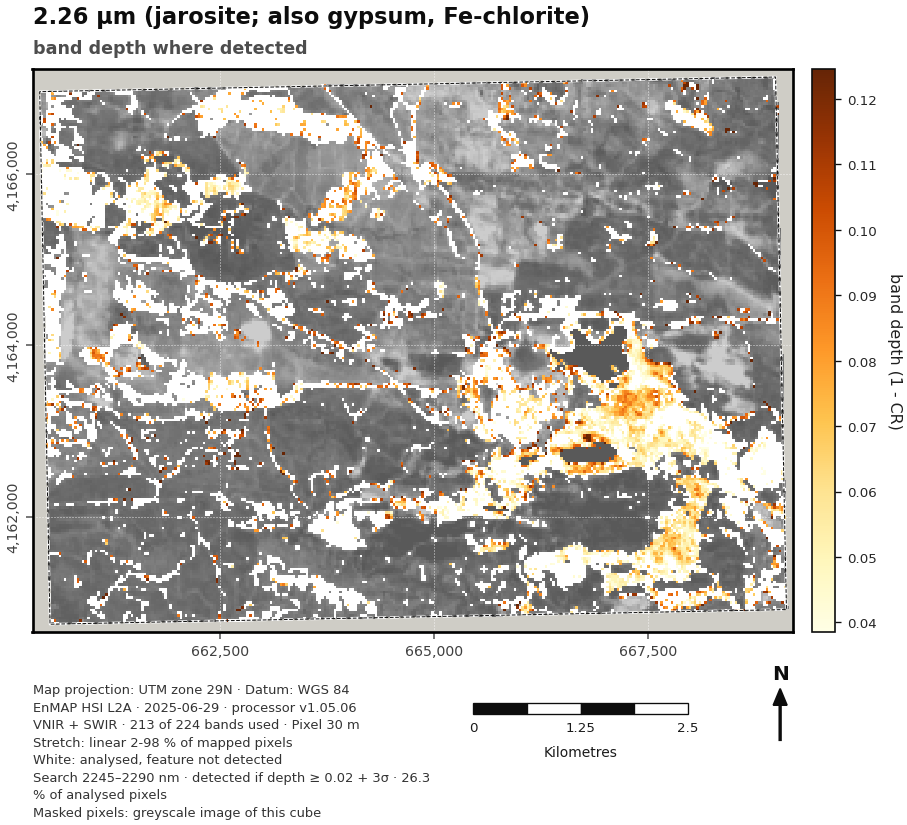

  saved  fig_08e_depth_MgOH_2330.png  +  fig_08e_depth_MgOH_2330.pdf   (400 dpi)


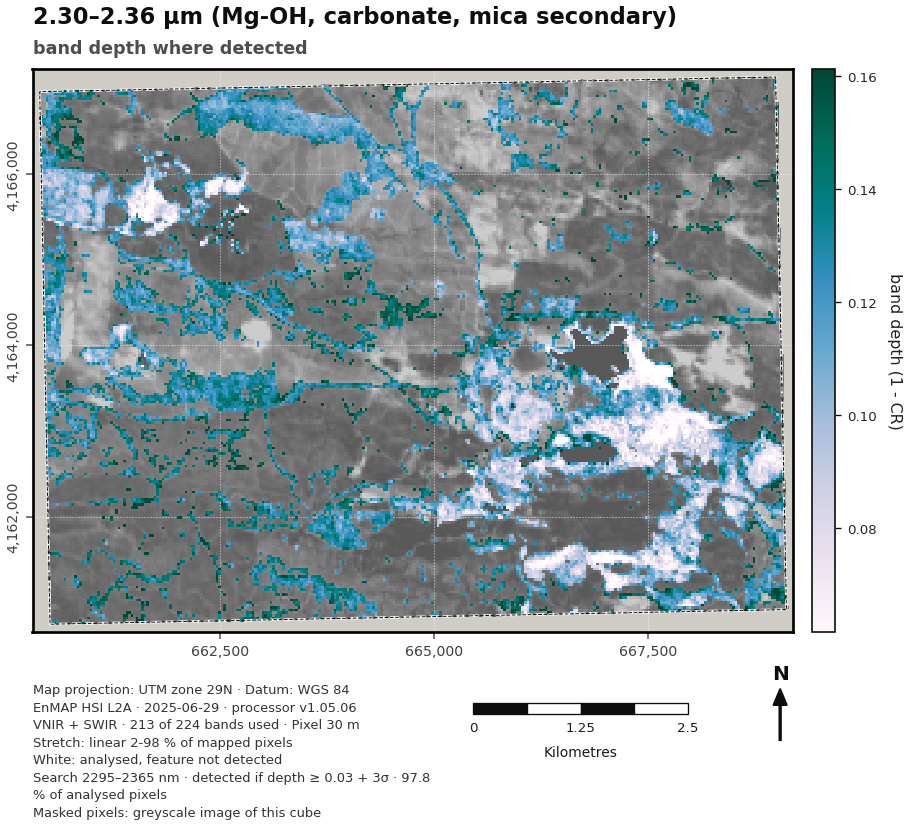

  saved  fig_09a_position_Fe3.png  +  fig_09a_position_Fe3.pdf   (400 dpi)


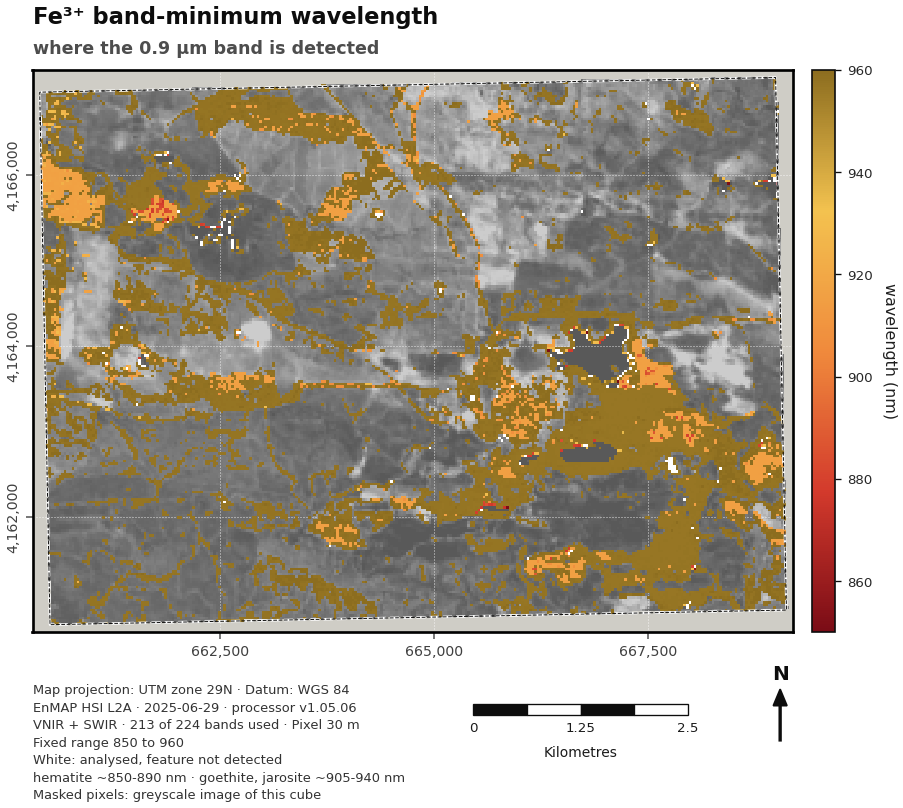

  saved  fig_09b_position_AlOH.png  +  fig_09b_position_AlOH.pdf   (400 dpi)


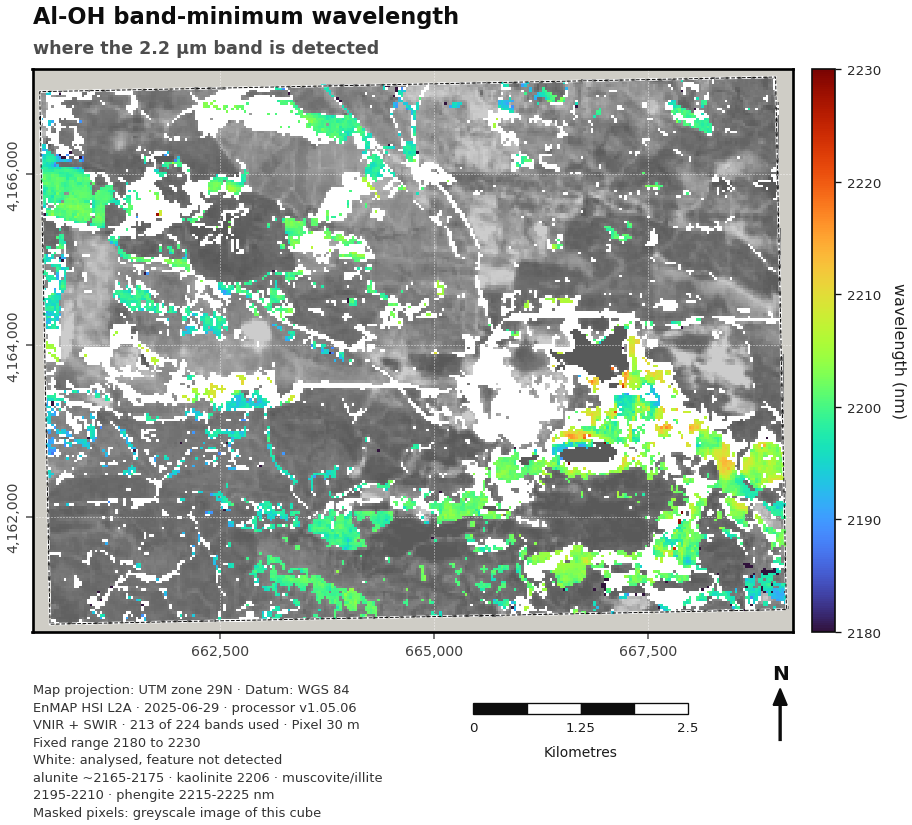

  saved  fig_10_position_histograms.png  +  fig_10_position_histograms.pdf   (400 dpi)


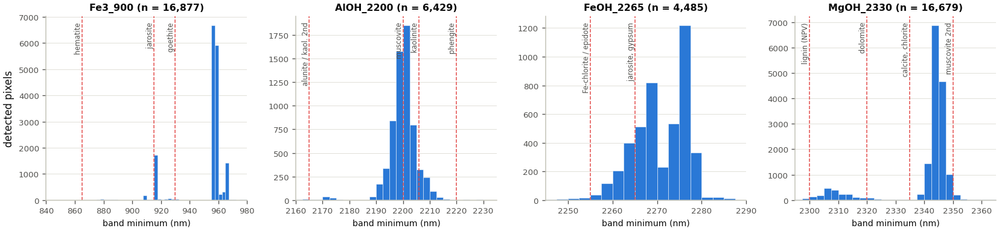

  saved  fig_11_swir_groups.png  +  fig_11_swir_groups.pdf   (400 dpi)


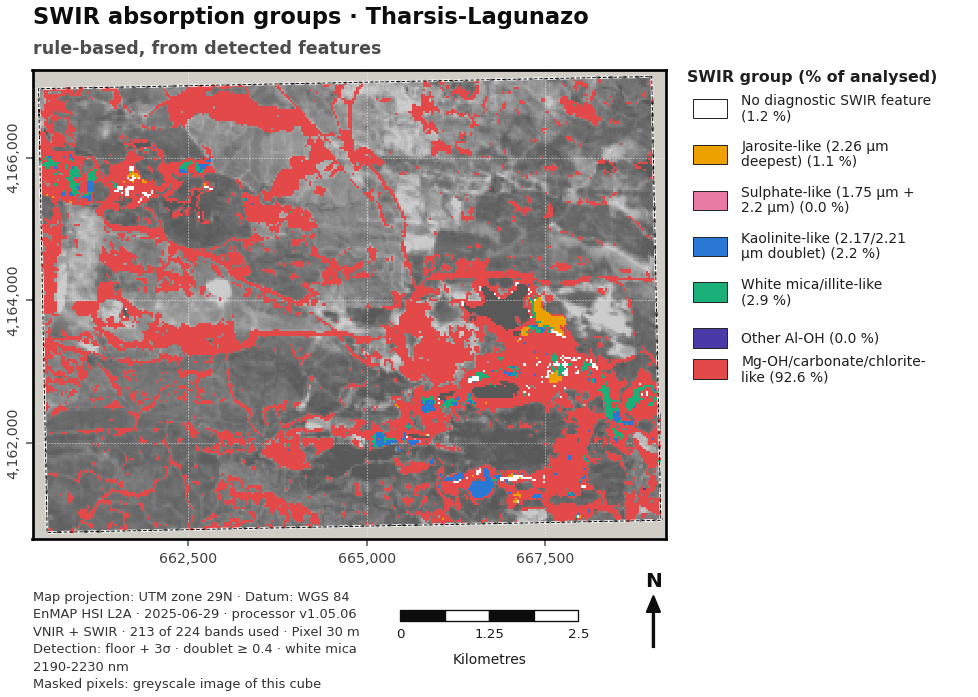

  saved  fig_12_fe3_classes.png  +  fig_12_fe3_classes.pdf   (400 dpi)


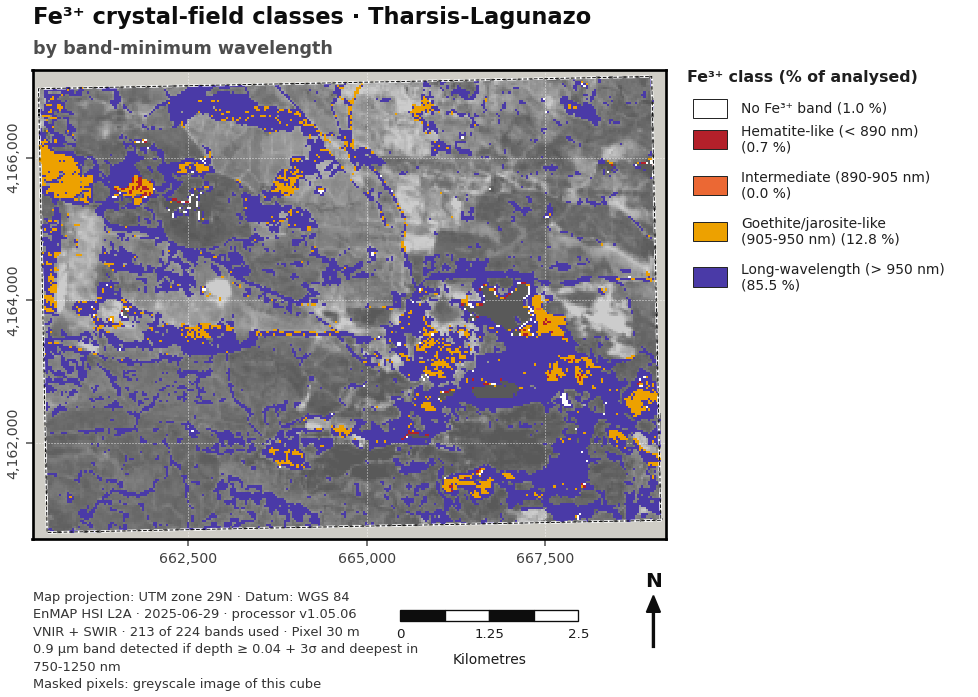

  saved  fig_13_fe_mineral_assemblage.png  +  fig_13_fe_mineral_assemblage.pdf   (400 dpi)


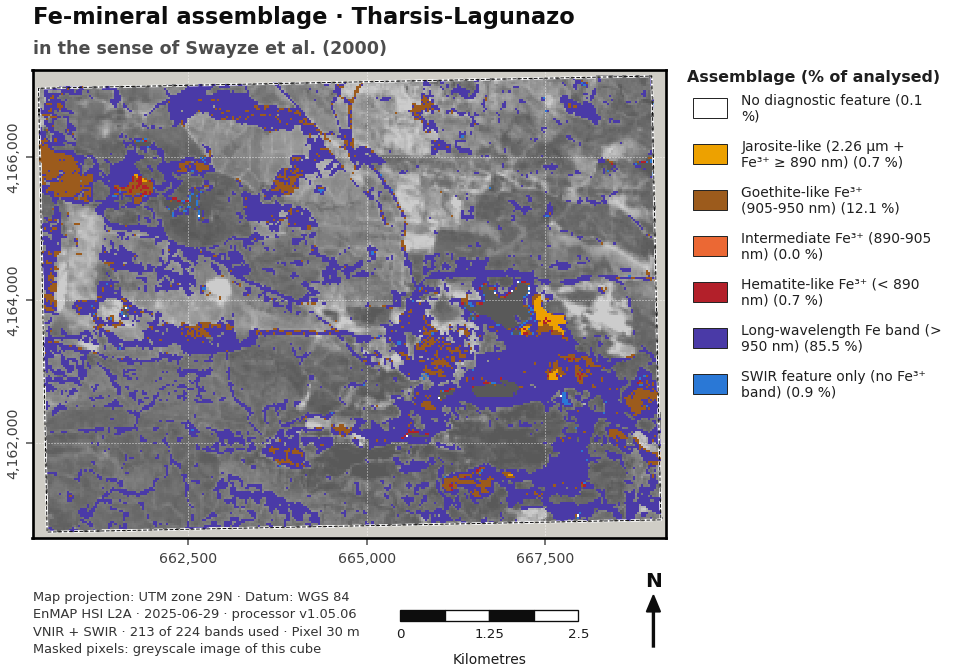

  saved  fig_14_depth_rgb.png  +  fig_14_depth_rgb.pdf   (400 dpi)


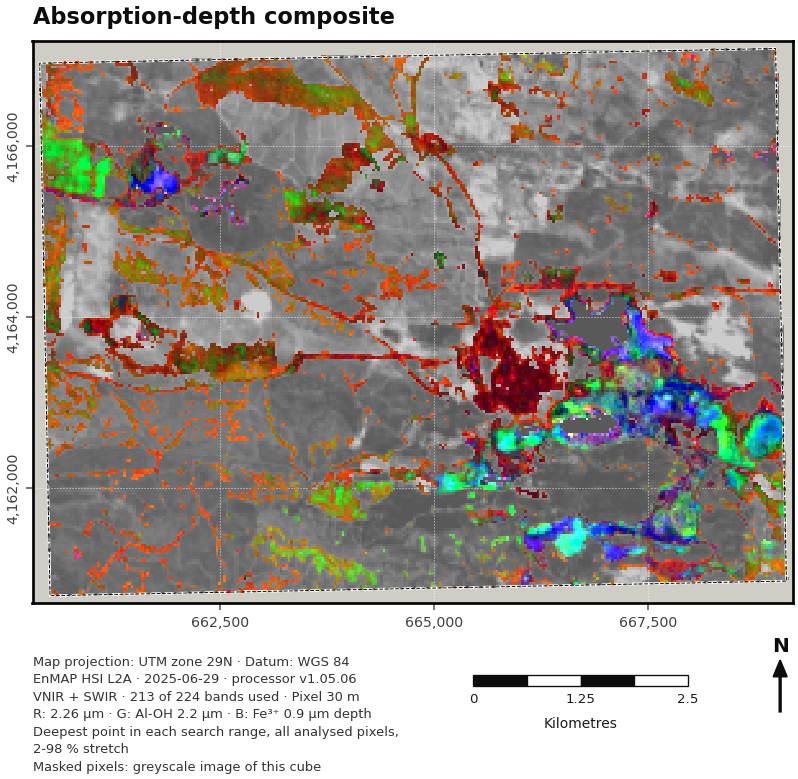

In [11]:
DEPTH_CMAPS = {"Fe3_900": "YlOrRd", "SO4_1750": "RdPu", "AlOH_2200": "YlGnBu", "FeOH_2265": "YlOrBr", "MgOH_2330": "PuBuGn"}
for i, (f, (w, rng, floor, label)) in enumerate(FEATURES.items()):
    dm = to_map(np.where(DET[f], RES[f]["depth"], np.nan))
    fig = plot_single_band(dm, f"{label}\nband depth where detected", "band depth (1 - CR)", cmap=DEPTH_CMAPS.get(f, "viridis"),
                           fname=f"fig_08{'abcde'[i]}_depth_{f}", blank=ANALYSED & ~to_map(DET[f], False, bool),
                           extra=[f"Search {rng[0]}–{rng[1]} nm · detected if depth ≥ {floor:g} + {DEPTH_NOISE_K:g}σ · "
                                  f"{100 * DET[f].mean():.1f} % of analysed pixels"])
    plt.show()

FE_POS_CMAP = LinearSegmentedColormap.from_list("fe_pos", ["#7a0c16", "#d33a2c", "#f08a3c", "#f3c24f", "#8c6d1f"])
fig = plot_single_band(to_map(np.where(DET["Fe3_900"], RES["Fe3_900"]["pos"], np.nan)),
                       "Fe³⁺ band-minimum wavelength\nwhere the 0.9 µm band is detected", "wavelength (nm)", cmap=FE_POS_CMAP,
                       vmin=850, vmax=960, fname="fig_09a_position_Fe3", blank=ANALYSED & ~to_map(DET["Fe3_900"], False, bool),
                       extra=["hematite ~850-890 nm · goethite, jarosite ~905-940 nm"])
plt.show()
fig = plot_single_band(to_map(np.where(DET["AlOH_2200"], RES["AlOH_2200"]["pos"], np.nan)),
                       "Al-OH band-minimum wavelength\nwhere the 2.2 µm band is detected", "wavelength (nm)", cmap="turbo",
                       vmin=2180, vmax=2230, fname="fig_09b_position_AlOH", blank=ANALYSED & ~to_map(DET["AlOH_2200"], False, bool),
                       extra=["alunite ~2165-2175 · kaolinite 2206 · muscovite/illite 2195-2210 · phengite 2215-2225 nm"])
plt.show()

REF_POS = {"Fe3_900": [(865, "hematite"), (915, "jarosite"), (930, "goethite")],
           "AlOH_2200": [(2165, "alunite / kaol. 2nd"), (2206, "kaolinite"), (2200, "muscovite"), (2220, "phengite")],
           "FeOH_2265": [(2255, "Fe-chlorite / epidote"), (2265, "jarosite, gypsum")],
           "MgOH_2330": [(2300, "lignin (NPV)"), (2320, "dolomite"), (2335, "calcite, chlorite"), (2350, "muscovite 2nd")]}
fig, axes = plt.subplots(1, 4, figsize=(14, 3.4))
for ax, f in zip(axes, REF_POS):
    rng = FEATURES[f][1]; p = RES[f]["pos"][DET[f]]
    bins = np.arange(rng[0], rng[1] + 2.5, 2.5)
    ax.hist(p, bins=bins, color=SERIES[0], edgecolor="white", linewidth=0.3)
    ax.set_xlim(rng[0], rng[1])
    ymax = ax.get_ylim()[1]
    for nm, lab in REF_POS[f]:
        ax.axvline(nm, color=SERIES[7], lw=0.9, ls="--")
        ax.text(nm, ymax * 0.97, f" {lab}", rotation=90, va="top", ha="right", fontsize=7, color=INK_2)
    ax.set_title(f"{f} (n = {p.size:,})", fontsize=9.5); ax.set_xlabel("band minimum (nm)", fontsize=8.5)
    style_chart(ax)
axes[0].set_ylabel("detected pixels")
fig.tight_layout(); save_fig(fig, "fig_10_position_histograms"); plt.show()

fig = plot_categorical(GROUP_MAP, f"SWIR absorption groups · {SITE_NAME}\nrule-based, from detected features",
                       GROUP_COLORS, [f"{n} ({p:.1f} %)" for n, p in zip(GROUP_NAMES, GROUP_TABLE['percent_of_analysed'])],
                       fname="fig_11_swir_groups", key_title="SWIR group (% of analysed)",
                       extra=[f"Detection: floor + {DEPTH_NOISE_K:g}σ · doublet ≥ {KAOLINITE_DOUBLET:g} · white mica "
                              f"{WHITE_MICA_NM[0]}-{WHITE_MICA_NM[1]} nm"])
plt.show()
fig = plot_categorical(FE_MAP, f"Fe³⁺ crystal-field classes · {SITE_NAME}\nby band-minimum wavelength", FE_COLORS,
                       [f"{n} ({p:.1f} %)" for n, p in zip(FE_NAMES, FE_TABLE['percent_of_analysed'])],
                       fname="fig_12_fe3_classes", key_title="Fe³⁺ class (% of analysed)",
                       extra=[f"0.9 µm band detected if depth ≥ {FEATURES['Fe3_900'][2]:g} + {DEPTH_NOISE_K:g}σ and deepest "
                              f"in {FE_DEEPEST_NM[0]}-{FE_DEEPEST_NM[1]} nm"])
plt.show()
fig = plot_categorical(ASSEM_MAP, f"Fe-mineral assemblage · {SITE_NAME}\nin the sense of Swayze et al. (2000)",
                       ASSEMBLAGE_COLORS, [f"{n} ({p:.1f} %)" for n, p in zip(ASSEMBLAGE_NAMES, ASSEM_TABLE['percent_of_analysed'])],
                       fname="fig_13_fe_mineral_assemblage", key_title="Assemblage (% of analysed)")
plt.show()

_rgb = [to_map(np.clip(RES[f]["depth_any"], 0, None)) for f in ("FeOH_2265", "AlOH_2200", "Fe3_900")]
fig = plot_rgb(make_rgb(*_rgb), "Absorption-depth composite", subtitle="R: 2.26 µm · G: Al-OH 2.2 µm · B: Fe³⁺ 0.9 µm depth",
               fname="fig_14_depth_rgb", extra=["Deepest point in each search range, all analysed pixels, 2-98 % stretch"])
plt.show()

## 8 · Class spectra: the evidence behind every group name

For each SWIR group and Fe³⁺ class the figures show the **median** reflectance and continuum-removed spectra with
the interquartile range. A group name is supported only if its median spectrum shows the diagnostic absorptions at
the stated wavelengths. Look for:

* jarosite-like: 2.265 µm minimum with a weaker 2.215 µm band; Fe³⁺ band near 0.92 µm (Bishop & Murad, 2005);
* sulphate-like: 1.75 µm band; gypsum also 2.215/2.265 µm, alunite 1.76, 2.17 and 2.32 µm (Bishop & Murad, 2005);
* kaolinite-like: 2.165/2.206 µm doublet; white mica: single 2.20 µm band with a 2.35 µm band;
* Mg-OH/carbonate/chlorite-like: 2.33–2.35 µm band, chlorite with 2.25 µm; dry plant material at 2.10 and 2.30 µm.

`USER_SAMPLE_POINTS` (field sites, UTM) are processed through the same continuum removal, feature and rule functions
on the mean spectrum of a `SAMPLE_WINDOW` × `SAMPLE_WINDOW` window of valid pixels. This replaces r6's automatic
picking, which chose points from the same indices it then "confirmed".

  saved  fig_15_swir_group_spectra.png  +  fig_15_swir_group_spectra.pdf   (400 dpi)


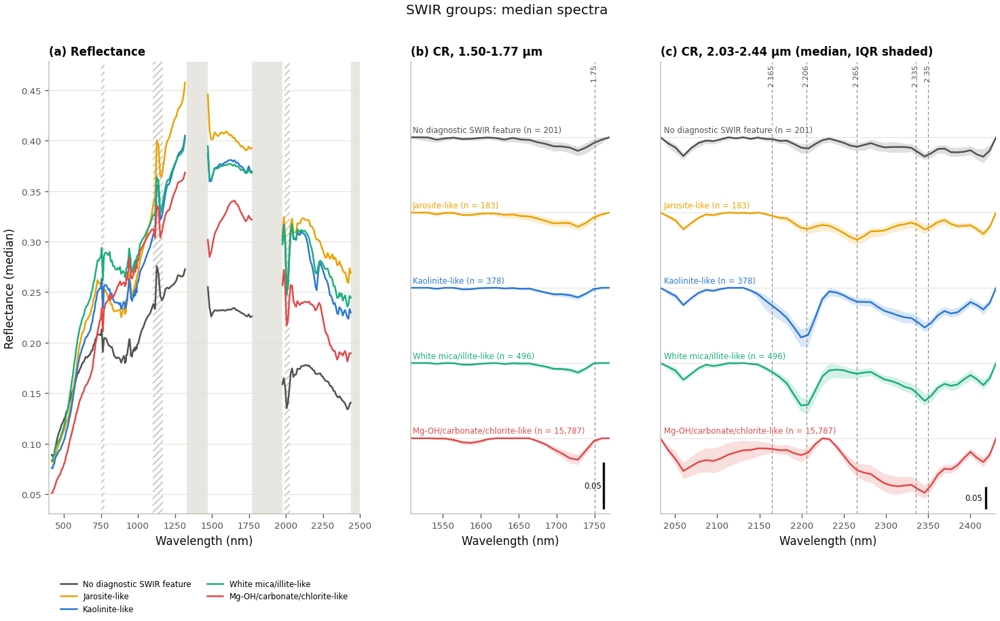

  saved  fig_16_fe3_class_spectra.png  +  fig_16_fe3_class_spectra.pdf   (400 dpi)


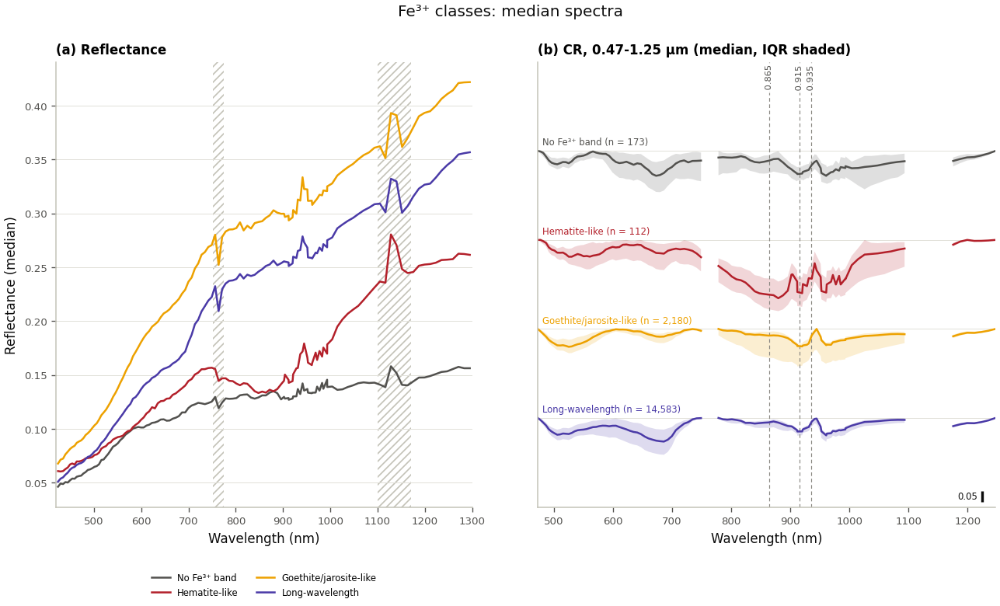

Median reflectance spectra per class written to tab_06_class_median_reflectance.csv


In [12]:
def median_iqr(M):
    return np.nanpercentile(M, [25, 50, 75], axis=0) if len(M) else np.full((3, M.shape[1]), np.nan)

def stacked_cr(ax, labels, names, colors, window, marks, min_n=5, title=""):
    """Median continuum-removed spectra (IQR shaded) of each class, offset vertically, with a 0.05 depth scale bar."""
    x = WL[WIN_BANDS[window]]
    shown = [k for k in range(len(names)) if (labels == k).sum() >= min_n]
    if not shown:
        ax.text(0.5, 0.5, "no class with enough pixels", ha="center", va="center", transform=ax.transAxes); return shown
    q_all = {k: median_iqr(CRW[window][labels == k]) for k in shown}
    depth_max = max(float(np.nanmax(1 - q_all[k][0])) for k in shown)
    step = max(0.08, 1.25 * depth_max)
    for i, k in enumerate(shown):
        q = q_all[k]; off = -i * step
        col = colors[k] if colors[k].lower() != "#ffffff" else INK_2
        xg, lo_ = with_gaps(x, q[0] + off); _, hi_ = with_gaps(x, q[2] + off); _, md_ = with_gaps(x, q[1] + off)
        ax.fill_between(xg, lo_, hi_, color=col, alpha=0.18, lw=0)
        ax.plot(xg, md_, color=col, lw=1.5)
        ax.axhline(1 + off, color=GRID, lw=0.6, zorder=0)
        ax.text(x[0] + 0.01 * (x[-1] - x[0]), 1 + off + 0.04 * step,
                f"{names[k].split(' (')[0]} (n = {(labels == k).sum():,})", fontsize=7, color=col, va="bottom", ha="left",
                bbox=dict(boxstyle="square,pad=0.05", fc="white", ec="none", alpha=0.7))
    bottom = 1 - (len(shown) - 1) * step - step
    ax.set_xlim(x[0], x[-1]); ax.set_ylim(bottom, 1 + 1.0 * step)
    mark_wavelengths(ax, marks, y_frac=0.995, fontsize=6.8)
    xb = x[-1] - 0.03 * (x[-1] - x[0]); yb = bottom + 0.06 * step
    ax.plot([xb, xb], [yb, yb + 0.05], color=INK, lw=2, solid_capstyle="butt")
    ax.text(xb - 0.01 * (x[-1] - x[0]), yb + 0.025, "0.05", fontsize=7, va="center", ha="right", color=INK)
    ax.set_yticks([]); ax.set_xlabel("Wavelength (nm)"); ax.set_title(title, fontsize=10, loc="left")
    style_chart(ax, grid_axis=None)
    return shown

def reflectance_panel(ax, labels, names, colors, xlim, min_n=5, title=""):
    ax.set_xlim(*xlim); shade_ranges(ax)
    sel_b = GOOD & (WL >= xlim[0]) & (WL <= xlim[1])
    for k in range(len(names)):
        if (labels == k).sum() < min_n:
            continue
        q = median_iqr(XA[labels == k][:, sel_b])
        col = colors[k] if colors[k].lower() != "#ffffff" else INK_2
        ax.plot(*with_gaps(WL[sel_b], q[1]), color=col, lw=1.5, label=names[k].split(" (")[0])
    ax.set_xlabel("Wavelength (nm)"); ax.set_ylabel("Reflectance (median)")
    ax.set_title(title, fontsize=10, loc="left"); style_chart(ax)
    ax.legend(fontsize=7, loc="upper center", bbox_to_anchor=(0.5, -0.13), ncol=2, frameon=False)

fig = plt.figure(figsize=(15, 7.2))
gs = fig.add_gridspec(1, 3, width_ratios=[1.25, 0.8, 1.35], wspace=0.18)
reflectance_panel(fig.add_subplot(gs[0, 0]), GROUPS, GROUP_NAMES, GROUP_COLORS, (400, 2500), title="(a) Reflectance")
stacked_cr(fig.add_subplot(gs[0, 1]), GROUPS, GROUP_NAMES, GROUP_COLORS, "SWIR1", [(1750, "1.75")],
           title="(b) CR, 1.50-1.77 µm")
stacked_cr(fig.add_subplot(gs[0, 2]), GROUPS, GROUP_NAMES, GROUP_COLORS, "SWIR2",
           [(2165, "2.165"), (2206, "2.206"), (2265, "2.265"), (2335, "2.335"), (2350, "2.35")],
           title="(c) CR, 2.03-2.44 µm (median, IQR shaded)")
fig.suptitle("SWIR groups: median spectra", fontsize=12, color=INK)
save_fig(fig, "fig_15_swir_group_spectra"); plt.show()

fig = plt.figure(figsize=(13, 6.2))
gs = fig.add_gridspec(1, 2, width_ratios=[1, 1.1], wspace=0.15)
reflectance_panel(fig.add_subplot(gs[0, 0]), FECLS, FE_NAMES, FE_COLORS, (420, 1300), title="(a) Reflectance")
stacked_cr(fig.add_subplot(gs[0, 1]), FECLS, FE_NAMES, FE_COLORS, "VNIR", [(865, "0.865"), (915, "0.915"), (935, "0.935")],
           title="(b) CR, 0.47-1.25 µm (median, IQR shaded)")
fig.suptitle("Fe³⁺ classes: median spectra", fontsize=12, color=INK)
save_fig(fig, "fig_16_fe3_class_spectra"); plt.show()

_spec = {"wavelength_nm": WL, "used": GOOD.astype(int)}
for labels_, names_, pre in [(GROUPS, GROUP_NAMES, "swir"), (FECLS, FE_NAMES, "fe3"), (ASSEM, ASSEMBLAGE_NAMES, "assem")]:
    for k, n in enumerate(names_):
        if (labels_ == k).sum() >= 5:
            _med = np.full(NB, np.nan); _med[GOOD] = np.median(XA[labels_ == k][:, GOOD], axis=0)
            _spec[f"{pre}{k}_{n.split(' (')[0]}"] = _med
pd.DataFrame(_spec).to_csv(TABLE_DIR / "tab_06_class_median_reflectance.csv", index=False, float_format="%.5f",
                           encoding="utf-8-sig")
print("Median reflectance spectra per class written to tab_06_class_median_reflectance.csv")

In [13]:
POINTS_TABLE = None
if not USER_SAMPLE_POINTS:
    print("No USER_SAMPLE_POINTS: add field sites as dict(label=..., easting=..., northing=...) in UTM to plot their spectra.")
else:
    half = SAMPLE_WINDOW // 2
    spectra, rows_ = [], []
    for sp in USER_SAMPLE_POINTS:
        col_f, row_f = ~TRANSFORM * (float(sp["easting"]), float(sp["northing"]))
        r0, c0 = int(math.floor(row_f)), int(math.floor(col_f))
        if not (0 <= r0 < H and 0 <= c0 < W):
            print(f"  [skip] {sp['label']}: outside the loaded window"); continue
        rs, cs = slice(max(r0 - half, 0), min(r0 + half + 1, H)), slice(max(c0 - half, 0), min(c0 + half + 1, W))
        ok_w = VALID_ALL[rs, cs] & AOI_MASK[rs, cs]
        if not ok_w.any():
            print(f"  [skip] {sp['label']}: no valid pixels in the window"); continue
        spec = CUBE[rs, cs][ok_w].mean(axis=0)
        spectra.append((sp["label"], spec))
        codes_w = MASK_CODE[rs, cs][ok_w]
        rows_.append({"label": sp["label"], "easting": sp["easting"], "northing": sp["northing"], "n_valid": int(ok_w.sum()),
                      "n_analysed": int((codes_w == 0).sum()),
                      "mask_class_centre": MASK_NAMES[int(MASK_CODE[r0, c0])] if MASK_CODE[r0, c0] >= 0 else "outside AOI"})
    if spectra:
        Xp = np.stack([s for _, s in spectra])
        rp, crp = analyse_spectra(Xp)
        dp = detect(rp)
        gp, fp = swir_groups(rp, dp), fe_classes(rp, dp)
        ap = assemblage(gp, fp)
        for i, row in enumerate(rows_):
            for f in FEATURES:
                row[f"{f}_depth"] = round(float(rp[f]["depth"][i]), 4)
                row[f"{f}_position_nm"] = round(float(rp[f]["pos"][i]), 1) if dp[f][i] else np.nan
                row[f"{f}_detected"] = bool(dp[f][i])
            row["swir_group"], row["fe3_class"], row["assemblage"] = GROUP_NAMES[gp[i]], FE_NAMES[fp[i]], ASSEMBLAGE_NAMES[ap[i]]
        POINTS_TABLE = pd.DataFrame(rows_)
        POINTS_TABLE.to_csv(TABLE_DIR / "tab_07_user_points.csv", index=False, encoding="utf-8-sig")
        print(POINTS_TABLE[["label", "n_valid", "n_analysed", "mask_class_centre", "swir_group", "fe3_class"]].to_string(index=False))
        if (POINTS_TABLE["n_analysed"] == 0).any():
            print("  NOTE: points without analysed pixels (vegetation, water, dark) are shown but their groups are not "
                  "comparable with the maps.")
        fig, axes = plt.subplots(1, 3, figsize=(15, 4.8), gridspec_kw={"width_ratios": [1.3, 1, 1]})
        axes[0].set_xlim(400, 2500); shade_ranges(axes[0])
        usable = [i for i, row in enumerate(rows_) if row["n_analysed"] > 0]
        step_p = max([0.1] + [1.2 * float(np.nanmax(1 - crp[w][i])) for i in usable for w in ("VNIR", "SWIR2")])
        for i, (lab, s) in enumerate(spectra):
            col = SERIES[i % len(SERIES)]
            axes[0].plot(*with_gaps(WL[GOOD], s[GOOD]), color=col, lw=1.4, ls="-" if i in usable else "--",
                         label=lab if i in usable else f"{lab} (not analysed: reflectance only)")
            if i in usable:
                j = usable.index(i)
                for ax, w in ((axes[1], "VNIR"), (axes[2], "SWIR2")):
                    ax.plot(*with_gaps(WL[WIN_BANDS[w]], crp[w][i] - step_p * j), color=col, lw=1.4)
        axes[0].set_ylabel("Reflectance"); axes[0].legend(fontsize=7.5)
        axes[0].set_title(f"(a) Window means ({SAMPLE_WINDOW} x {SAMPLE_WINDOW} px)", fontsize=10, loc="left")
        axes[1].set_title(f"(b) CR 0.47-1.25 µm (offset {step_p:.2f})", fontsize=10, loc="left")
        axes[2].set_title(f"(c) CR 2.03-2.44 µm (offset {step_p:.2f})", fontsize=10, loc="left")
        for ax, marks in ((axes[1], [(865, "0.865"), (930, "0.93")]),
                          (axes[2], [(2165, "2.165"), (2206, "2.206"), (2265, "2.265"), (2335, "2.335")])):
            mark_wavelengths(ax, marks, fontsize=7)
        for ax in axes:
            ax.set_xlabel("Wavelength (nm)"); style_chart(ax)
        fig.tight_layout(); save_fig(fig, "fig_17_user_point_spectra"); plt.show()
        fig = plot_categorical(ASSEM_MAP, "User points over the Fe-mineral assemblage", ASSEMBLAGE_COLORS, ASSEMBLAGE_NAMES,
                               fname="fig_18_user_points_map", key_title="Assemblage",
                               points=(POINTS_TABLE["easting"].astype(float), POINTS_TABLE["northing"].astype(float)),
                               extra=[f"{len(POINTS_TABLE)} points (black dots)"])
        plt.show()

No USER_SAMPLE_POINTS: add field sites as dict(label=..., easting=..., northing=...) in UTM to plot their spectra.


## 9 · MNF transform and spectral domains

r6 ran PCA on standardised spectra, which gives noisy bands the same weight as informative ones; its PC1 (80 %) and
K-means clusters followed brightness. Here the **minimum noise fraction** (MNF) transform (Green et al., 1988) orders
components by signal-to-noise ratio instead of variance. The noise covariance is estimated from differences between
adjacent analysed pixels (horizontal and vertical), and the MNF solves Σ_signal v = λ Σ_noise v on used,
non-artefact bands outside the detector overlap (the moving average there correlates the noise of adjacent bands). Eigenvalue λ ≈ SNR + 1 of each component; components with λ close to 1 carry noise only.

**Spectral domains** are K-means clusters of the first `N_MNF` MNF components (k by silhouette if `AUTO_K`). They are
**not** mineral classes. The domain table summarises each domain by its absorption features (detection rates, band
positions, dominant SWIR group and Fe³⁺ class) and by NDVI and CAI, which is what makes a domain interpretable.
Domains are numbered by decreasing median Fe³⁺ depth.

MNF on 176 bands (used, non-artefact, outside the detector overlap) and 17,050 analysed pixels; noise from 26,863 adjacent pixel pairs
Eigenvalues (≈ SNR + 1) of the first 15 components: 44.9, 15.7, 12.9, 12.2, 9.8, 9.1, 8.5, 7.3, 6.8, 6.4, 5.6, 5.0, 5.0, 4.7, 4.5
Components with eigenvalue > 2: 46; kept for clustering: 12
  saved  fig_19_mnf_eigenvalues_loadings.png  +  fig_19_mnf_eigenvalues_loadings.pdf   (400 dpi)


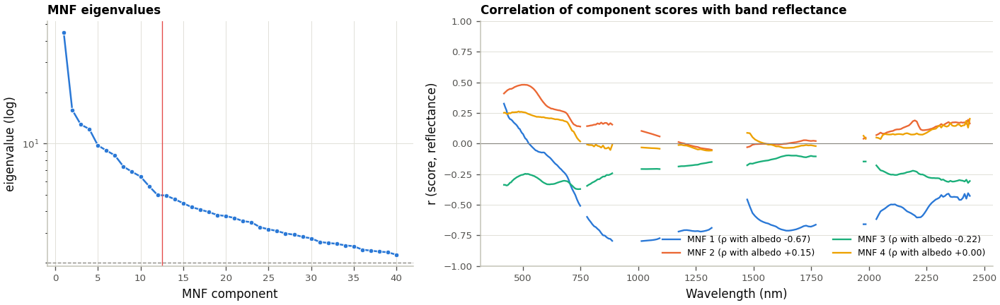

  saved  fig_20_mnf_components.png  +  fig_20_mnf_components.pdf   (400 dpi)


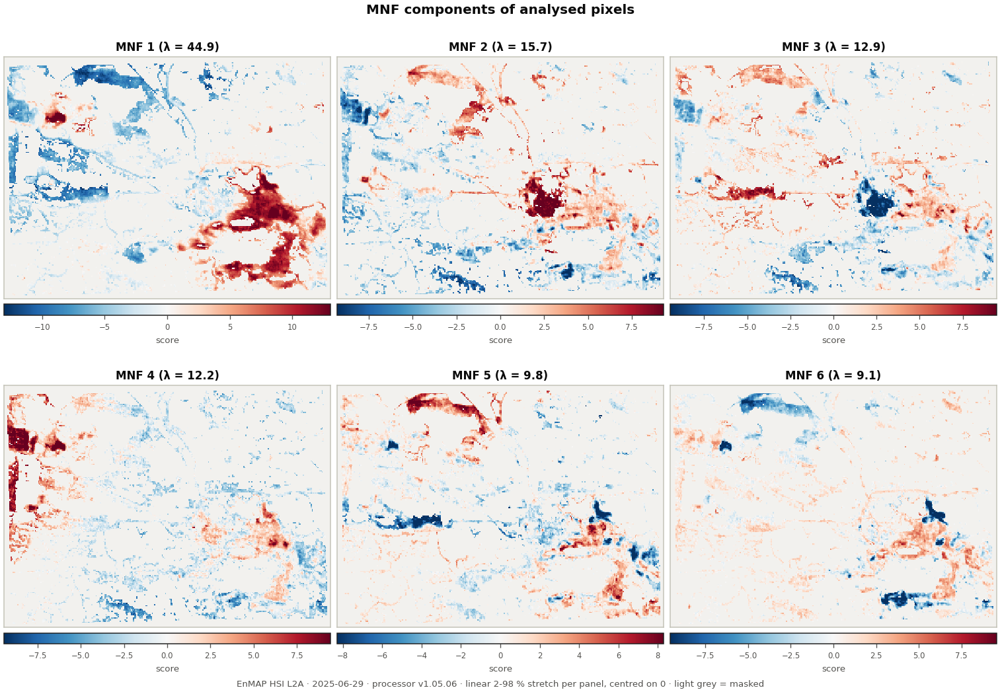

Silhouette by k: 4: 0.164, 5: 0.183, 6: 0.193, 7: 0.178, 8: 0.198, 9: 0.204, 10: 0.204  ->  k = 9
  NOTE: all silhouettes < 0.25 - the domains subdivide a continuum rather than separate distinct groups.
 domain  pixels  percent_of_analysed  median_albedo  median_NDVI  median_CAI  Fe3_900_detected_pct  SO4_1750_detected_pct  AlOH_2200_detected_pct  FeOH_2265_detected_pct  MgOH_2330_detected_pct  Fe3_900_median_position_nm  AlOH_2200_median_position_nm  FeOH_2265_median_position_nm  MgOH_2330_median_position_nm             dominant_swir_group  dominant_swir_group_share_pct                  dominant_fe3_class  dominant_fe3_class_share_pct
      1     322                  1.9          0.248        0.009      -0.010                  99.7                    0.6                    34.5                    75.8                    51.9                     915.970                      2209.196                      2264.677                      2345.231 Jarosite-like (2.26 µm deepest)             

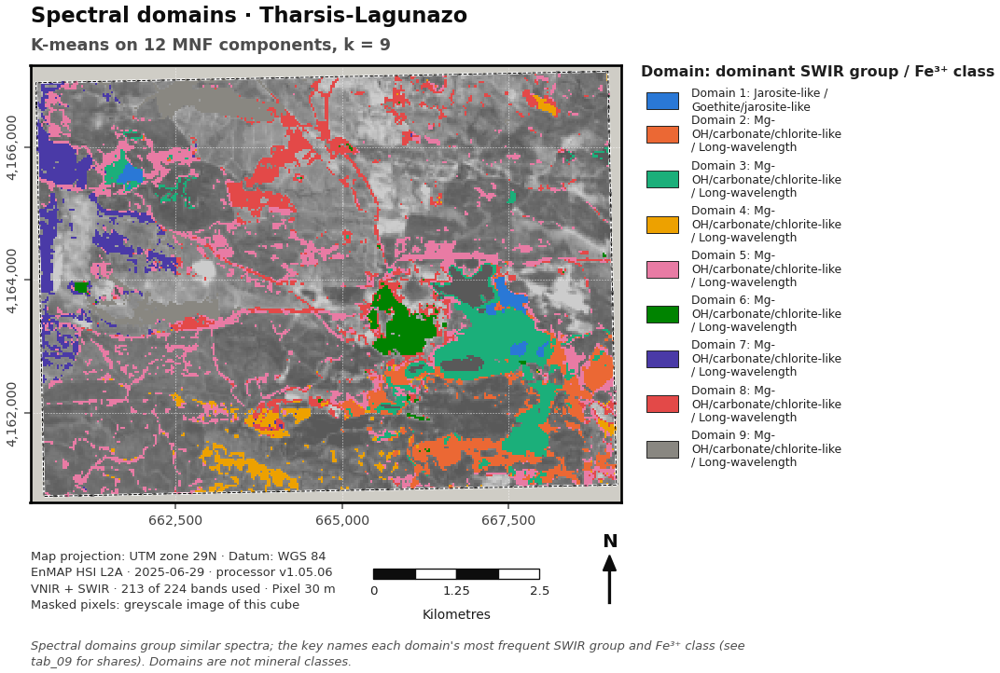

  saved  fig_22_domain_spectra.png  +  fig_22_domain_spectra.pdf   (400 dpi)


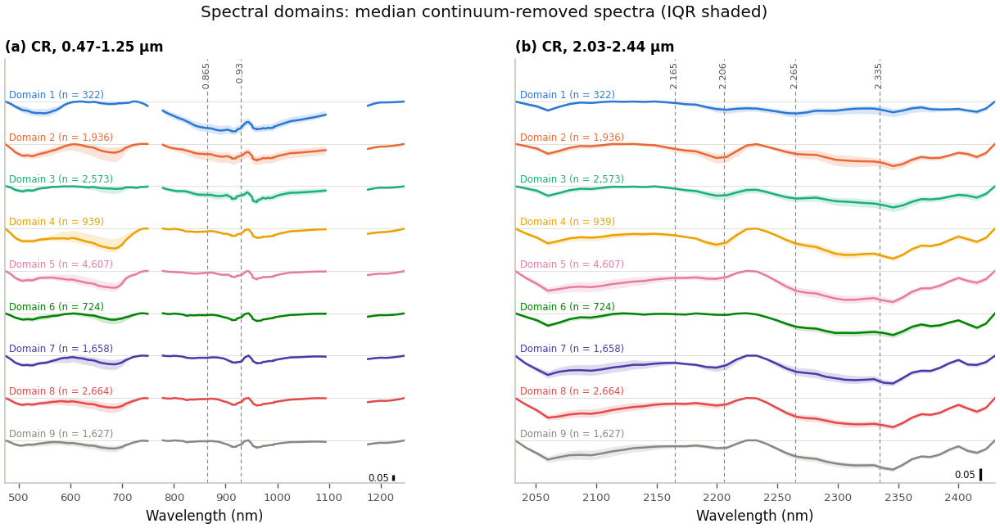

In [14]:
_in_overlap = (WL >= OVERLAP_NM[0]) & (WL <= OVERLAP_NM[1]) if OVERLAP_NM else np.zeros(NB, bool)
MNF_BANDS = np.where(GOOD & ~ART & ~_in_overlap)[0]
Xm = XA[:, MNF_BANDS].astype("float64")
_idx_map = to_map(np.arange(N_AN), -1, "int64")
_pairs = []
for a_, b_ in [(_idx_map[:, :-1], _idx_map[:, 1:]), (_idx_map[:-1, :], _idx_map[1:, :])]:
    ok_ = (a_ >= 0) & (b_ >= 0)
    _pairs.append((a_[ok_], b_[ok_]))
_l = np.concatenate([p[0] for p in _pairs]); _r = np.concatenate([p[1] for p in _pairs])
if _l.size < 10 * len(MNF_BANDS):
    raise RuntimeError(f"Only {_l.size} adjacent analysed pixel pairs - too few to estimate the MNF noise covariance.")
if _l.size > 300000:
    _s = np.random.default_rng(RANDOM_STATE).choice(_l.size, 300000, replace=False); _l, _r = _l[_s], _r[_s]
NOISE_COV = np.cov(Xm[_r] - Xm[_l], rowvar=False) / 2.0
SIGNAL_COV = np.cov(Xm, rowvar=False)
NOISE_COV += np.eye(len(MNF_BANDS)) * 1e-9 * np.trace(NOISE_COV) / len(MNF_BANDS)
_ev, _vec = linalg.eigh(SIGNAL_COV, NOISE_COV)
_o = np.argsort(_ev)[::-1]
MNF_EIG, MNF_VEC = _ev[_o], _vec[:, _o]
for j in range(MNF_VEC.shape[1]):
    if MNF_VEC[np.argmax(np.abs(MNF_VEC[:, j])), j] < 0:
        MNF_VEC[:, j] *= -1
N_KEEP = int(min(N_MNF, len(MNF_EIG)))
MNF = ((Xm - Xm.mean(axis=0)) @ MNF_VEC[:, :N_KEEP]).astype("float32")
del Xm
n_signal = int((MNF_EIG > 2.0).sum())
print(f"MNF on {len(MNF_BANDS)} bands (used, non-artefact, outside the detector overlap) and {N_AN:,} analysed pixels; "
      f"noise from {_l.size:,} adjacent pixel pairs")
print("Eigenvalues (≈ SNR + 1) of the first 15 components: " + ", ".join(f"{v:.1f}" for v in MNF_EIG[:15]))
print(f"Components with eigenvalue > 2: {n_signal}; kept for clustering: {N_KEEP}")
if n_signal < N_KEEP:
    print(f"  NOTE: components {n_signal + 1}-{N_KEEP} are close to noise level; consider N_MNF = {max(n_signal, 3)}.")
MNF_TABLE = pd.DataFrame({"component": np.arange(1, len(MNF_EIG) + 1), "eigenvalue": MNF_EIG,
                          "rho_with_albedo": [stats.spearmanr(MNF[:, j], ALBEDO[ANALYSED])[0] if j < N_KEEP else np.nan
                                              for j in range(len(MNF_EIG))]})
MNF_TABLE.to_csv(TABLE_DIR / "tab_08_mnf_eigenvalues.csv", index=False, float_format="%.4f", encoding="utf-8-sig")

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), gridspec_kw={"width_ratios": [1, 1.4]})
ax = axes[0]
ax.semilogy(np.arange(1, min(40, len(MNF_EIG)) + 1), MNF_EIG[:40], "-o", color=SERIES[0], ms=4, mec="white", mew=0.6)
ax.axhline(2, color=MUTED, lw=0.8, ls="--"); ax.axvline(N_KEEP + 0.5, color=SERIES[7], lw=0.8)
ax.set_xlabel("MNF component"); ax.set_ylabel("eigenvalue (log)"); ax.set_title("MNF eigenvalues", fontsize=10, loc="left")
style_chart(ax, grid_axis="both")
ax = axes[1]
_sub_c = np.random.default_rng(RANDOM_STATE).choice(N_AN, min(N_AN, 20000), replace=False)
_Xc = XA[_sub_c][:, MNF_BANDS]; _Xc = (_Xc - _Xc.mean(axis=0)) / _Xc.std(axis=0)
for j in range(min(4, N_KEEP)):
    _sc = MNF[_sub_c, j]; _sc = (_sc - _sc.mean()) / _sc.std()
    ax.plot(*with_gaps(WL[MNF_BANDS], (_Xc * _sc[:, None]).mean(axis=0)), color=SERIES[j], lw=1.4,
            label=f"MNF {j + 1} (ρ with albedo {MNF_TABLE.rho_with_albedo[j]:+.2f})")
ax.axhline(0, color=MUTED, lw=0.7)
ax.set_ylim(-1, 1); ax.set_xlabel("Wavelength (nm)"); ax.set_ylabel("r (score, reflectance)")
ax.set_title("Correlation of component scores with band reflectance", fontsize=10, loc="left")
style_chart(ax); ax.legend(fontsize=7.5, loc="lower right", ncol=2)
fig.tight_layout(); save_fig(fig, "fig_19_mnf_eigenvalues_loadings"); plt.show()
fig = panel_maps([to_map(MNF[:, j]) for j in range(min(6, N_KEEP))],
                 [f"MNF {j + 1} (λ = {MNF_EIG[j]:.1f})" for j in range(min(6, N_KEEP))], ["RdBu_r"] * min(6, N_KEEP),
                 "MNF components of analysed pixels", fname="fig_20_mnf_components", cbar_labels=["score"] * min(6, N_KEEP),
                 symmetric=True)
plt.show()

rng_ = np.random.default_rng(RANDOM_STATE)
_sub = rng_.choice(N_AN, min(4000, N_AN), replace=False)
SIL = {}
if AUTO_K:
    for k in K_RANGE:
        lab_ = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit_predict(MNF[_sub])
        SIL[k] = float(silhouette_score(MNF[_sub], lab_))
    K_BEST = max(SIL, key=SIL.get)
    print("Silhouette by k: " + ", ".join(f"{k}: {v:.3f}" for k, v in SIL.items()) + f"  ->  k = {K_BEST}")
    if K_BEST == max(K_RANGE):
        print(f"  NOTE: the silhouette is highest at the largest k tested ({K_BEST}); more domains would split the data "
              "further. Choose k from the domain spectra and table (AUTO_K = False, N_CLUSTERS) rather than extending K_RANGE.")
    if max(SIL.values()) < 0.25:
        print("  NOTE: all silhouettes < 0.25 - the domains subdivide a continuum rather than separate distinct groups.")
else:
    K_BEST = int(N_CLUSTERS)
km = KMeans(n_clusters=K_BEST, n_init=10, random_state=RANDOM_STATE).fit(MNF)
_raw_lab = km.labels_
_fe_depth = np.clip(RES["Fe3_900"]["depth_any"], 0, None)
_order = np.argsort([-np.median(_fe_depth[_raw_lab == c]) for c in range(K_BEST)])
_remap = np.empty(K_BEST, int); _remap[_order] = np.arange(K_BEST)
DOMAINS = _remap[_raw_lab].astype(np.int16)
DOMAIN_MAP = to_map(DOMAINS, -1, "int16")
DOMAIN_COLORS = (SERIES + ["#898781", "#0d366b", "#9c5b1c", "#383835"])[:K_BEST]
DOMAIN_NAMES = [f"Domain {d + 1}" for d in range(K_BEST)]

dom_rows = []
for d in range(K_BEST):
    s_ = DOMAINS == d; n_ = int(s_.sum())
    g_counts = np.bincount(GROUPS[s_], minlength=len(GROUP_NAMES)); f_counts = np.bincount(FECLS[s_], minlength=len(FE_NAMES))
    row = {"domain": d + 1, "pixels": n_, "percent_of_analysed": round(100 * n_ / N_AN, 1),
           "median_albedo": float(np.median(ALBEDO[ANALYSED][s_])),
           "median_NDVI": float(np.median(NDVI[ANALYSED][s_])), "median_CAI": float(np.median(CAI[ANALYSED][s_]))}
    for f in FEATURES:
        row[f"{f}_detected_pct"] = round(100 * DET[f][s_].mean(), 1)
    for f in ("Fe3_900", "AlOH_2200", "FeOH_2265", "MgOH_2330"):
        p_ = RES[f]["pos"][s_ & DET[f]]
        row[f"{f}_median_position_nm"] = float(np.median(p_)) if p_.size >= 10 else np.nan
    row["dominant_swir_group"] = GROUP_NAMES[int(g_counts.argmax())]
    row["dominant_swir_group_share_pct"] = round(100 * g_counts.max() / n_, 1)
    row["dominant_fe3_class"] = FE_NAMES[int(f_counts.argmax())]
    row["dominant_fe3_class_share_pct"] = round(100 * f_counts.max() / n_, 1)
    dom_rows.append(row)
DOMAIN_TABLE = pd.DataFrame(dom_rows)
DOMAIN_TABLE.to_csv(TABLE_DIR / "tab_09_spectral_domains.csv", index=False, float_format="%.4f", encoding="utf-8-sig")
with pd.option_context("display.width", 250, "display.max_columns", 40):
    print(DOMAIN_TABLE.round(3).to_string(index=False))

fig = plot_categorical(DOMAIN_MAP, f"Spectral domains · {SITE_NAME}\nK-means on {N_KEEP} MNF components, k = {K_BEST}",
                       DOMAIN_COLORS, [f"{n}: {r.dominant_swir_group.split(' (')[0]} / {r.dominant_fe3_class.split(' (')[0]}"
                                       for n, r in zip(DOMAIN_NAMES, DOMAIN_TABLE.itertuples())],
                       fname="fig_21_spectral_domains", key_title="Domain: dominant SWIR group / Fe³⁺ class",
                       caption="Spectral domains group similar spectra; the key names each domain's most frequent SWIR group "
                               "and Fe³⁺ class (see tab_09 for shares). Domains are not mineral classes.")
plt.show()
fig = plt.figure(figsize=(13, 5.6))
gs = fig.add_gridspec(1, 2, width_ratios=[1, 1.2], wspace=0.25)
stacked_cr(fig.add_subplot(gs[0, 0]), DOMAINS, DOMAIN_NAMES, DOMAIN_COLORS, "VNIR", [(865, "0.865"), (930, "0.93")],
           title="(a) CR, 0.47-1.25 µm")
stacked_cr(fig.add_subplot(gs[0, 1]), DOMAINS, DOMAIN_NAMES, DOMAIN_COLORS, "SWIR2",
           [(2165, "2.165"), (2206, "2.206"), (2265, "2.265"), (2335, "2.335")], title="(b) CR, 2.03-2.44 µm")
fig.suptitle("Spectral domains: median continuum-removed spectra (IQR shaded)", fontsize=12, color=INK)
save_fig(fig, "fig_22_domain_spectra"); plt.show()

## 10 · Continuum-removed SAM against a spectral library (optional)

Library spectra (USGS Spectral Library v7 ASCII with its wavelength file, Kokaly et al., 2017, or a CSV) are
interpolated to 1 nm and **convolved with a Gaussian response of each EnMAP band's FWHM**. Pixel and library spectra
are continuum-removed in the 2.03–2.44 µm window, and the spectral angle (Kruse et al., 1993) is measured between
their **absorption spectra, 1 − CR**. The angle therefore compares the shape and position of the absorptions and
ignores brightness and continuum slope.

* Only pixels with a detected 2.2–2.36 µm feature (§6) are matched; the others are "no SWIR2 feature".
* Library entries whose deepest absorption in the window is below 0.02 (e.g. goethite, hematite) cannot be matched
  here and are dropped with a note.
* The **separability** table gives the angle between every pair of library spectra. Pairs closer than
  `SAM_MAX_ANGLE` cannot be separated by SAM.
* A pixel is *ambiguous* when its best and second-best matches differ by less than `SAM_AMBIGUITY_MARGIN`, and
  *unclassified* when its best angle exceeds `SAM_MAX_ANGLE`. Noise and mixing widen the angles: on the synthetic
  test scene, pure surfaces matched at about 0.1–0.25 rad, mixed pixels at 0.3–0.45 rad and noise-only spectra at
  0.6–1.0 rad. Read the angle histogram (figure 23) before fixing `SAM_MAX_ANGLE`, and keep `SMOOTH_WINDOW` as in
  the final run, because unsmoothed spectra give larger angles.

Suggested library for this setting: jarosite, alunite, gypsum, kaolinite, muscovite/illite, montmorillonite,
chlorite, calcite/dolomite and a dry-grass spectrum (to catch residual plant litter).

In [15]:
def read_ascii_column(path):
    vals = []
    with open(path, "r", encoding="utf-8", errors="replace") as f:
        for line in f:
            tok = line.strip().split()
            if not tok:
                continue
            try:
                vals.append(float(tok[0]))
            except ValueError:
                continue
    a = np.array(vals, dtype=float)
    a[a < -1e30] = np.nan
    return a

def convolve_to_bands(wl_lib, refl, band_idx):
    """Resample a library spectrum to EnMAP bands with Gaussian band responses (FWHM from §3)."""
    wl_lib = np.asarray(wl_lib, float); refl = np.asarray(refl, float)
    if np.nanmax(wl_lib) < 100:
        wl_lib = wl_lib * 1000.0
    ok = np.isfinite(wl_lib) & np.isfinite(refl)
    wl_lib, refl = wl_lib[ok], refl[ok]
    o = np.argsort(wl_lib); wl_lib, refl = wl_lib[o], refl[o]
    fine = np.arange(np.ceil(wl_lib[0]), np.floor(wl_lib[-1]) + 1, 1.0)
    rf = np.interp(fine, wl_lib, refl)
    out = np.full(len(band_idx), np.nan)
    for i, j in enumerate(band_idx):
        s = FWHM[j] / 2.3548
        wgt = np.exp(-0.5 * ((fine - WL[j]) / s) ** 2)
        full = s * math.sqrt(2 * math.pi)
        if wgt.sum() >= 0.9 * full:
            out[i] = (rf * wgt).sum() / wgt.sum()
    return out

def spectral_angle(A, B):
    num = A @ B.T
    den = np.linalg.norm(A, axis=1)[:, None] * np.linalg.norm(B, axis=1)[None, :]
    with np.errstate(invalid="ignore", divide="ignore"):
        return np.arccos(np.clip(num / den, -1, 1))

SAM_CLASS, SAM_ANGLE, LIB_NAMES = None, None, []
LIB_RAW = {}
_b2 = WIN_BANDS["SWIR2"]
if LIBRARY_CSV:
    _lib = pd.read_csv(_resolve(LIBRARY_CSV))
    _wcol = next((c for c in _lib.columns if c.lower() in ("wavelength_nm", "wavelength", "wavelength_um")), None)
    if _wcol is None:
        raise ValueError("LIBRARY_CSV needs a 'wavelength_nm' (or 'wavelength') column")
    for c in _lib.columns:
        if c != _wcol:
            LIB_RAW[str(c)] = convolve_to_bands(_lib[_wcol].to_numpy(float), _lib[c].to_numpy(float), _b2)
if USGS_SPECTRA:
    if not USGS_WAVELENGTH_FILE:
        raise ValueError("USGS_SPECTRA needs USGS_WAVELENGTH_FILE (the wavelength file of the same spectrometer/version)")
    _wl_usgs = read_ascii_column(_resolve(USGS_WAVELENGTH_FILE))
    for name, path in USGS_SPECTRA.items():
        _rf = read_ascii_column(_resolve(path))
        if _rf.size != _wl_usgs.size:
            raise ValueError(f"{name}: {_rf.size} values but the wavelength file has {_wl_usgs.size}")
        LIB_RAW[name] = convolve_to_bands(_wl_usgs, _rf, _b2)

if not LIB_RAW:
    print("Library SAM skipped: set USGS_SPECTRA (+ USGS_WAVELENGTH_FILE) or LIBRARY_CSV in CONFIG.")
else:
    _bad = [n for n, v in LIB_RAW.items() if not np.isfinite(v).all()]
    if _bad:
        raise ValueError(f"Library spectra do not cover 2.03-2.44 µm: {_bad}")
    _L = np.stack(list(LIB_RAW.values()))
    LIB_CR = (_L / upper_hull_continuum(WL[_b2], _L)).astype("float32")
    _depth_lib = 1 - LIB_CR.min(axis=1)
    keep = _depth_lib >= 0.02
    for n, d, k in zip(LIB_RAW, _depth_lib, keep):
        if not k:
            print(f"  dropped from SAM: {n} (deepest 2.03-2.44 µm absorption {d:.3f} < 0.02)")
    LIB_NAMES = [n for n, k in zip(LIB_RAW, keep) if k]
    LIB_ABS = 1 - LIB_CR[keep]
    if len(LIB_NAMES) == 0:
        print("No library spectrum has a 2.03-2.44 µm absorption: SAM skipped.")
    else:
        SEP = spectral_angle(LIB_ABS, LIB_ABS)
        SEP_TABLE = pd.DataFrame(SEP, index=LIB_NAMES, columns=LIB_NAMES)
        SEP_TABLE.to_csv(TABLE_DIR / "tab_10_library_separability_rad.csv", float_format="%.4f", encoding="utf-8-sig")
        print("Angle between library absorption spectra (rad):")
        print(SEP_TABLE.round(3).to_string())
        for i, a in enumerate(LIB_NAMES):
            for j, b in enumerate(LIB_NAMES):
                if j > i and SEP[i, j] < SAM_MAX_ANGLE:
                    print(f"  NOT SEPARABLE at SAM_MAX_ANGLE = {SAM_MAX_ANGLE}: {a} vs {b} ({SEP[i, j]:.3f} rad)")
        SAM_PIX = DET["AlOH_2200"] | DET["FeOH_2265"] | DET["MgOH_2330"]
        nL = len(LIB_NAMES)
        cls_ = np.full(N_AN, nL + 2, dtype=np.int16)           # no SWIR2 feature
        best_ang = np.full(N_AN, np.nan, dtype="float32")
        pix = np.flatnonzero(SAM_PIX)
        for s0 in range(0, pix.size, 50000):
            p_ = pix[s0:s0 + 50000]
            ang = spectral_angle(1 - CRW["SWIR2"][p_].astype("float64"), LIB_ABS.astype("float64"))
            srt = np.sort(ang, axis=1)
            b_ = ang.argmin(axis=1); a1 = srt[:, 0]
            a2 = srt[:, 1] if nL > 1 else np.full(len(p_), np.inf)
            c_ = np.where(a1 <= SAM_MAX_ANGLE, b_, nL + 1)
            c_ = np.where((a1 <= SAM_MAX_ANGLE) & (a2 - a1 < SAM_AMBIGUITY_MARGIN), nL, c_)
            cls_[p_], best_ang[p_] = c_, a1
        SAM_CLASS, SAM_ANGLE = cls_, best_ang
        SAM_NAMES = LIB_NAMES + [f"Ambiguous (< {SAM_AMBIGUITY_MARGIN:g} rad apart)", f"Unclassified (> {SAM_MAX_ANGLE:g} rad)",
                                 "No 2.2-2.36 µm feature"]
        SAM_COLORS = [SERIES[i % len(SERIES)] for i in range(nL)] + ["#898781", "#383835", "#ffffff"]
        SAM_TABLE = area_table(SAM_CLASS, SAM_NAMES, "sam_class")
        SAM_TABLE["median_angle_rad"] = [float(np.nanmedian(SAM_ANGLE[SAM_CLASS == k])) if (SAM_CLASS == k).any() and k <= nL + 1
                                         else np.nan for k in range(len(SAM_NAMES))]
        SAM_TABLE.to_csv(TABLE_DIR / "tab_11_sam_library_classes.csv", index=False, float_format="%.4f", encoding="utf-8-sig")
        print(SAM_TABLE.to_string(index=False))

        fig, axes = plt.subplots(1, 2, figsize=(12, 4.6), gridspec_kw={"width_ratios": [1, 1.25]})
        ax = axes[0]
        for i, n in enumerate(LIB_NAMES):
            ax.plot(WL[_b2], LIB_CR[keep][i] - 0.25 * i, color=SAM_COLORS[i], lw=1.5)
            ax.text(WL[_b2][-1] + 5, 1 - 0.25 * i, n, fontsize=7.5, color=SAM_COLORS[i], va="center")
        ax.set_xlim(WL[_b2][0], WL[_b2][-1] + 110); ax.set_yticks([])
        mark_wavelengths(ax, [(2165, "2.165"), (2206, "2.206"), (2265, "2.265"), (2335, "2.335")], fontsize=7)
        ax.set_title("(a) Library, EnMAP bands, continuum removed", fontsize=10, loc="left"); ax.set_xlabel("Wavelength (nm)")
        style_chart(ax, grid_axis=None)
        ax = axes[1]
        ax.hist(SAM_ANGLE[np.isfinite(SAM_ANGLE)], bins=60, color=SERIES[0], edgecolor="white", lw=0.3)
        ax.axvline(SAM_MAX_ANGLE, color=SERIES[7], lw=1.2, label=f"SAM_MAX_ANGLE {SAM_MAX_ANGLE:g}")
        ax.set_xlabel("best spectral angle (rad)"); ax.set_ylabel("pixels"); ax.legend(fontsize=8)
        ax.set_title("(b) Best angle of pixels with a 2.2-2.36 µm feature", fontsize=10, loc="left"); style_chart(ax)
        fig.tight_layout(); save_fig(fig, "fig_23_library_and_angles"); plt.show()

        fig = plot_categorical(to_map(SAM_CLASS, -1, "int16"), "Continuum-removed SAM: library matches\nabsorption spectra, 2.03-2.44 µm",
                               SAM_COLORS, SAM_NAMES, fname="fig_24_sam_library_classes", key_title="Best match",
                               extra=[f"max angle {SAM_MAX_ANGLE:g} rad · ambiguity margin {SAM_AMBIGUITY_MARGIN:g} rad"],
                               caption="Similarity of absorption shape to library spectra at EnMAP resolution, restricted "
                                       "to pixels with a detected SWIR2 feature. Not a mineral identification.")
        plt.show()
        _ct = pd.crosstab(pd.Series([GROUP_NAMES[v] for v in GROUPS[SAM_PIX]], name="SWIR group"),
                          pd.Series([SAM_NAMES[v] for v in SAM_CLASS[SAM_PIX]], name="SAM class"), normalize="index") * 100
        _ct.to_csv(TABLE_DIR / "tab_12_sam_vs_swir_groups_pct.csv", float_format="%.1f", encoding="utf-8-sig")
        fig, ax = plt.subplots(figsize=(1.6 + 0.85 * _ct.shape[1], 1.0 + 0.5 * _ct.shape[0]))
        im = ax.imshow(_ct.to_numpy(), cmap=SEQ_BLUE, vmin=0, vmax=100, aspect="auto")
        ax.set_xticks(range(_ct.shape[1])); ax.set_xticklabels(_ct.columns, rotation=40, ha="right", fontsize=8)
        ax.set_yticks(range(_ct.shape[0])); ax.set_yticklabels(_ct.index, fontsize=8)
        for i in range(_ct.shape[0]):
            for j in range(_ct.shape[1]):
                ax.text(j, i, f"{_ct.iat[i, j]:.0f}", ha="center", va="center", fontsize=7.5,
                        color="white" if _ct.iat[i, j] > 60 else INK)
        fig.colorbar(im, ax=ax, fraction=0.04, pad=0.02).set_label("% of the SWIR group", color=INK_2)
        ax.set_title("Agreement: rule-based SWIR groups vs library SAM", fontsize=10, loc="left")
        fig.tight_layout(); save_fig(fig, "fig_25_sam_vs_swir_groups"); plt.show()

Library SAM skipped: set USGS_SPECTRA (+ USGS_WAVELENGTH_FILE) or LIBRARY_CSV in CONFIG.


## 11 · Robustness checks

1. **Detection thresholds.** All thresholds (floor + kσ) are scaled by `THRESHOLD_FACTORS` and the group and class
   maps are rebuilt. The Jaccard index with the default maps shows which classes are stable (≥ 0.7) and which depend
   on the threshold choice.
2. **Smoothing.** Features and groups without Savitzky–Golay smoothing.
3. **Detector overlap.** The Fe³⁺ band positions and classes recomputed from the spectra as delivered (no gain
   correction, no moving average).
4. **Residual vegetation and plant litter.** Spearman ρ of every feature depth with NDVI and CAI inside the analysed
   pixels, and the median CAI of each SWIR group. A depth that **rises** with NDVI or CAI (ρ ≥ 0.5), or a group
   median CAI above half of `CAI_NPV_THRESHOLD`, flags a layer or group that partly tracks plant material. Negative
   ρ between the Al-OH depth and CAI is expected: CAI uses the 2.21 µm band, which Al-OH minerals absorb.
5. **r6's fixed-band indices against the r7 features.** The four r6 band depths and R850/R650 are recomputed from
   the delivered spectra and compared with the r7 feature depths, NDVI and CAI. r6's percentile classes (top 25 % or
   20 %) are compared with the r7 detections.

Jaccard index with the default maps when all detection thresholds are scaled:
factor                                            0.50  0.75  1.00  1.25  1.50  2.00
type       class                                                                    
Fe³⁺ class Goethite/jarosite-like (905-950 nm)    1.00  1.00   1.0  0.97  0.78  0.41
           Hematite-like (< 890 nm)               1.00  1.00   1.0  1.00  1.00  1.00
           Intermediate (890-905 nm)              1.00  1.00   1.0  1.00  1.00  1.00
           Long-wavelength (> 950 nm)             1.00  1.00   1.0  0.98  0.82  0.35
           No Fe³⁺ band                           0.97  0.97   1.0  0.35  0.05  0.02
SWIR group Jarosite-like (2.26 µm deepest)        0.87  0.87   1.0  0.71  0.51  0.25
           Kaolinite-like (2.17/2.21 µm doublet)  0.96  0.98   1.0  0.98  0.91  0.71
           Mg-OH/carbonate/chlorite-like          0.99  0.99   1.0  0.98  0.94  0.79
           No diagnostic SWIR feature             0.05  0.28   1.0  0.36

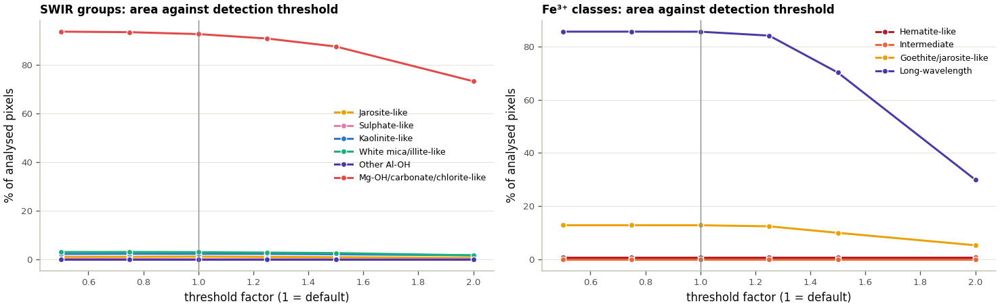


With vs without Savitzky–Golay smoothing:
      type                                 class  percent_smoothed  percent_unsmoothed  jaccard  median_abs_position_shift_nm
SWIR group            No diagnostic SWIR feature             1.179               1.179    0.621                           NaN
SWIR group       Jarosite-like (2.26 µm deepest)             1.073               0.903    0.685                           NaN
SWIR group      Sulphate-like (1.75 µm + 2.2 µm)             0.023               0.106    0.100                           NaN
SWIR group Kaolinite-like (2.17/2.21 µm doublet)             2.217               1.906    0.662                           NaN
SWIR group                White mica/illite-like             2.909               2.839    0.647                           NaN
SWIR group                           Other Al-OH             0.006               0.018    0.333                           NaN
SWIR group         Mg-OH/carbonate/chlorite-like            92.592         

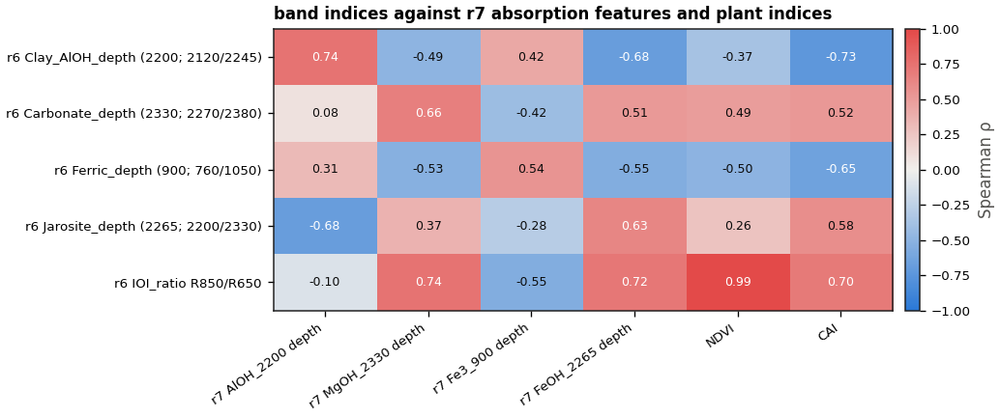

In [16]:
def jaccard(a, b):
    u = (a | b).sum()
    return float((a & b).sum() / u) if u else np.nan

rob_rows = []
for fac in sorted(set(THRESHOLD_FACTORS) | {1.0}):
    det_ = detect(RES, fac)
    g_, fe_ = swir_groups(RES, det_), fe_classes(RES, det_)
    for names_, base_, new_, kind in [(GROUP_NAMES, GROUPS, g_, "SWIR group"), (FE_NAMES, FECLS, fe_, "Fe³⁺ class")]:
        for k, n in enumerate(names_):
            rob_rows.append({"factor": fac, "type": kind, "class": n, "percent_of_analysed": 100 * (new_ == k).mean(),
                             "jaccard_vs_default": jaccard(new_ == k, base_ == k)})
ROB_THR = pd.DataFrame(rob_rows)
ROB_THR.to_csv(TABLE_DIR / "tab_13_threshold_sensitivity.csv", index=False, float_format="%.3f", encoding="utf-8-sig")
_piv = ROB_THR.pivot_table(index=["type", "class"], columns="factor", values="jaccard_vs_default")
print("Jaccard index with the default maps when all detection thresholds are scaled:")
print(_piv.round(2).to_string())

fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.0))
for ax, (kind, names_, colors_, plural) in zip(axes, [("SWIR group", GROUP_NAMES, GROUP_COLORS, "SWIR groups"),
                                                     ("Fe³⁺ class", FE_NAMES, FE_COLORS, "Fe³⁺ classes")]):
    for k, n in enumerate(names_):
        if k == 0:
            continue
        t_ = ROB_THR[(ROB_THR["type"] == kind) & (ROB_THR["class"] == n)]
        ax.plot(t_["factor"], t_["percent_of_analysed"], "-o", color=colors_[k], lw=1.8, ms=5, mec="white", mew=0.8,
                label=n.split(" (")[0])
    ax.axvline(1.0, color=MUTED, lw=0.8)
    ax.set_xlabel("threshold factor (1 = default)"); ax.set_ylabel("% of analysed pixels")
    ax.set_title(f"{plural}: area against detection threshold", fontsize=10, loc="left")
    style_chart(ax); ax.legend(fontsize=7.5)
fig.tight_layout(); save_fig(fig, "fig_26_threshold_sensitivity"); plt.show()

# 2 - smoothing off
RES_NS, _ = analyse_spectra(XA, smooth=False, keep_cr=False)
DET_NS = detect(RES_NS)
G_NS, FE_NS = swir_groups(RES_NS, DET_NS), fe_classes(RES_NS, DET_NS)
smooth_rows = []
for names_, base_, new_, kind in [(GROUP_NAMES, GROUPS, G_NS, "SWIR group"), (FE_NAMES, FECLS, FE_NS, "Fe³⁺ class")]:
    for k, n in enumerate(names_):
        smooth_rows.append({"type": kind, "class": n, "percent_smoothed": 100 * (base_ == k).mean(),
                            "percent_unsmoothed": 100 * (new_ == k).mean(), "jaccard": jaccard(base_ == k, new_ == k)})
for f in FEATURES:
    both = DET[f] & DET_NS[f]
    smooth_rows.append({"type": "feature", "class": f, "percent_smoothed": 100 * DET[f].mean(),
                        "percent_unsmoothed": 100 * DET_NS[f].mean(), "jaccard": jaccard(DET[f], DET_NS[f]),
                        "median_abs_position_shift_nm": float(np.median(np.abs(RES[f]["pos"][both] - RES_NS[f]["pos"][both])))
                        if both.sum() >= 10 else np.nan})
ROB_SMOOTH = pd.DataFrame(smooth_rows)
ROB_SMOOTH.to_csv(TABLE_DIR / "tab_14_smoothing_effect.csv", index=False, float_format="%.3f", encoding="utf-8-sig")
print("\nWith vs without Savitzky–Golay smoothing:")
print(ROB_SMOOTH.round(3).to_string(index=False))

# 3 - detector overlap as delivered
X_DELIVERED = XA.copy()
if OVERLAP_RAW is not None:
    X_DELIVERED[:, OV_BANDS] = OVERLAP_RAW[ANALYSED]
    _sw = np.where(~IS_VNIR)[0]
    _sw = _sw[~np.isin(_sw, OV_BANDS)]
    X_DELIVERED[:, _sw] /= SWIR_GAIN
    RES_OV, _ = analyse_spectra(X_DELIVERED, keep_cr=False)
    DET_OV = detect(RES_OV)
    FE_OV = fe_classes(RES_OV, DET_OV)
    both = DET["Fe3_900"] & DET_OV["Fe3_900"]
    dpos = RES_OV["Fe3_900"]["pos"][both] - RES["Fe3_900"]["pos"][both]
    ROB_OVERLAP = pd.DataFrame([{"class": n, "percent_harmonised": 100 * (FECLS == k).mean(),
                                 "percent_as_delivered": 100 * (FE_OV == k).mean(), "jaccard": jaccard(FECLS == k, FE_OV == k)}
                                for k, n in enumerate(FE_NAMES)])
    ROB_OVERLAP.to_csv(TABLE_DIR / "tab_15_overlap_effect_fe3.csv", index=False, float_format="%.3f", encoding="utf-8-sig")
    print(f"\nFe³⁺ from spectra as delivered vs harmonised overlap: median position shift {np.median(dpos):+.1f} nm "
          f"(IQR {np.percentile(dpos, 25):+.1f} to {np.percentile(dpos, 75):+.1f} nm, n = {both.sum():,}); "
          f"{100 * (FE_OV[both] != FECLS[both]).mean():.1f} % of pixels change Fe³⁺ class")
    print(ROB_OVERLAP.round(3).to_string(index=False))
else:
    print("\nOverlap check skipped: the overlap was not harmonised.")

# 4 - residual vegetation / plant litter
veg_rows = []
_ndvi_a, _cai_a = NDVI[ANALYSED], CAI[ANALYSED]
for f in FEATURES:
    d_ = np.clip(RES[f]["depth_any"], 0, None)
    r_ndvi = stats.spearmanr(d_, _ndvi_a)[0]; r_cai = stats.spearmanr(d_, _cai_a)[0]
    veg_rows.append({"layer": f"{f} depth", "rho_NDVI": r_ndvi, "rho_CAI": r_cai,
                     "flag": "rises with plant indices" if max(r_ndvi, r_cai) >= 0.5 else ""})
for k, n in enumerate(GROUP_NAMES):
    s_ = GROUPS == k
    if s_.sum() >= 10:
        mcai = float(np.median(_cai_a[s_]))
        veg_rows.append({"layer": f"group: {n}", "median_NDVI": float(np.median(_ndvi_a[s_])), "median_CAI": mcai,
                         "flag": "check for plant litter" if mcai > 0.5 * CAI_NPV_THRESHOLD else ""})
VEG_CHECK = pd.DataFrame(veg_rows)
VEG_CHECK.to_csv(TABLE_DIR / "tab_16_vegetation_litter_check.csv", index=False, float_format="%.3f", encoding="utf-8-sig")
print("\nResidual vegetation / plant litter - feature depths vs NDVI and CAI (Spearman ρ):")
print(VEG_CHECK[VEG_CHECK.layer.str.endswith("depth")][["layer", "rho_NDVI", "rho_CAI", "flag"]].round(3).to_string(index=False))
print("SWIR groups - median NDVI and CAI:")
print(VEG_CHECK[VEG_CHECK.layer.str.startswith("group")][["layer", "median_NDVI", "median_CAI", "flag"]].round(3).to_string(index=False))

# 5 - fixed-band indices
def _nearest(nm):
    return int(np.argmin(np.abs(WL - nm)))

def r6_band_depth(X, c, l, r):
    ci, li, ri = _nearest(c), _nearest(l), _nearest(r)
    with np.errstate(invalid="ignore", divide="ignore"):
        cont = X[:, li] + (WL[ci] - WL[li]) / (WL[ri] - WL[li]) * (X[:, ri] - X[:, li])
        return 1 - X[:, ci] / cont

with np.errstate(invalid="ignore", divide="ignore"):
    R6 = {"r6 Clay_AlOH_depth (2200; 2120/2245)": r6_band_depth(X_DELIVERED, 2200, 2120, 2245),
          "r6 Carbonate_depth (2330; 2270/2380)": r6_band_depth(X_DELIVERED, 2330, 2270, 2380),
          "r6 Ferric_depth (900; 760/1050)": r6_band_depth(X_DELIVERED, 900, 760, 1050),
          "r6 Jarosite_depth (2265; 2200/2330)": r6_band_depth(X_DELIVERED, 2265, 2200, 2330),
          "r6 IOI_ratio R850/R650": X_DELIVERED[:, _nearest(850)] / X_DELIVERED[:, _nearest(650)]}
R7 = {f"r7 {f} depth": np.clip(RES[f]["depth_any"], 0, None) for f in ("AlOH_2200", "MgOH_2330", "Fe3_900", "FeOH_2265")}
R7["NDVI"], R7["CAI"] = _ndvi_a, _cai_a
M_ = np.column_stack([*R6.values(), *R7.values()])
ok_ = np.isfinite(M_).all(axis=1)
if ok_.sum() > 50000:
    ok_ = ok_ & (np.random.default_rng(RANDOM_STATE).random(len(ok_)) < 50000 / ok_.sum())
RHO_R6 = pd.DataFrame(np.asarray(stats.spearmanr(M_[ok_])[0])[:len(R6), len(R6):], index=list(R6), columns=list(R7))
RHO_R6.to_csv(TABLE_DIR / "tab_17_r6_indices_vs_r7_features.csv", float_format="%.3f", encoding="utf-8-sig")
_pairs = [("r6 Clay_AlOH_depth (2200; 2120/2245)", "AlOH_2200", 25), ("r6 Carbonate_depth (2330; 2270/2380)", "MgOH_2330", 20),
          ("r6 Ferric_depth (900; 760/1050)", "Fe3_900", 25), ("r6 Jarosite_depth (2265; 2200/2330)", "FeOH_2265", 25)]
J_R6 = pd.DataFrame([{"r6_index": a, "r7_feature": b, "r6_top_percent": p,
                      "jaccard_r6_top_vs_r7_detected": jaccard(np.nan_to_num(R6[a], nan=-np.inf) >= np.nanpercentile(R6[a], 100 - p), DET[b]),
                      "r7_detected_percent": 100 * DET[b].mean()} for a, b, p in _pairs])
J_R6.to_csv(TABLE_DIR / "tab_18_r6_classes_vs_r7_detections.csv", index=False, float_format="%.3f", encoding="utf-8-sig")
print("\nr6 fixed-band indices (rows) vs r7 feature depths, NDVI and CAI (Spearman ρ, analysed pixels):")
print(RHO_R6.round(2).to_string())
print(J_R6.round(3).to_string(index=False))

fig, ax = plt.subplots(figsize=(8.8, 3.8))
im = ax.imshow(RHO_R6.to_numpy(), cmap=DIVERGING, vmin=-1, vmax=1, aspect="auto")
ax.set_xticks(range(RHO_R6.shape[1])); ax.set_xticklabels(RHO_R6.columns, rotation=35, ha="right", fontsize=8)
ax.set_yticks(range(RHO_R6.shape[0])); ax.set_yticklabels(RHO_R6.index, fontsize=8)
for i in range(RHO_R6.shape[0]):
    for j in range(RHO_R6.shape[1]):
        ax.text(j, i, f"{RHO_R6.iat[i, j]:.2f}", ha="center", va="center", fontsize=7.5,
                color="white" if abs(RHO_R6.iat[i, j]) > 0.6 else INK)
fig.colorbar(im, ax=ax, fraction=0.04, pad=0.02).set_label("Spearman ρ", color=INK_2)
ax.set_title("band indices against r7 absorption features and plant indices", fontsize=10, loc="left")
fig.tight_layout(); save_fig(fig, "fig_27_r6_indices_vs_r7"); plt.show()

## 12 · Cross-sensor bridge: what the Sentinel-2 and Landsat ratios respond to

EnMAP resolves the absorptions that the broad Sentinel-2 and Landsat bands can only straddle. Sentinel-2A MSI (band
centres and widths as in the Sentinel-2 chapter) and Landsat 8/9 OLI bands (USGS band edges) are simulated from the
harmonised EnMAP spectra by integrating each EnMAP band's Gaussian response over the multispectral band. The ratios
used in the other chapters are then compared with the EnMAP feature depths, NDVI and CAI on the analysed pixels,
and summarised by SWIR group and Fe³⁺ class.

This answers the interpretation question for those chapters with the same surfaces and date: a ratio that
correlates with several EnMAP features, or with CAI, cannot be read as a single mineral. Simulated bands have no
multispectral noise, atmospheric-correction or geometric differences, so the correlations are an **upper bound**
for real Sentinel-2 or Landsat data. Real rasters from those chapters can be added in `REFERENCE_RASTERS`; they
are resampled onto the EnMAP grid (averaged if finer, nearest neighbour if coarser), and every third pixel is used
to reduce spatial autocorrelation.

Spearman ρ between simulated multispectral ratios and EnMAP layers (n = 17,050 analysed pixels):
                                Fe3_900 depth  SO4_1750 depth  AlOH_2200 depth  FeOH_2265 depth  MgOH_2330 depth  max 2.2-2.36 µm depth  NDVI   CAI  albedo
S2 B4/B2 (Fe³⁺)                         -0.34            0.12             0.28             0.29             0.35                   0.37  0.40  0.37    0.40
S2 B4/B3 (Fe³⁺, blue-free)              -0.30            0.10             0.25             0.21             0.27                   0.30  0.22  0.31    0.47
S2 B6/B8A (Fe³⁺ crystal field)           0.75           -0.34             0.24            -0.73            -0.74                  -0.70 -0.73 -0.85   -0.27
S2 NIR depth B8A                         0.76           -0.28             0.29            -0.70            -0.68                  -0.63 -0.73 -0.81   -0.29
S2 B11/B8A (SWIR1/NIR)                   0.11            0.08             0.19             0.05             0.10           

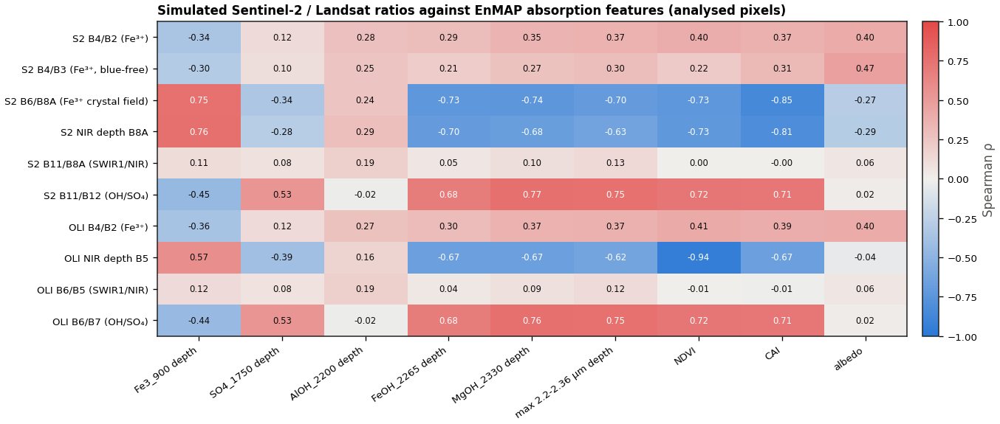

  saved  fig_29_multispectral_by_enmap_class.png  +  fig_29_multispectral_by_enmap_class.pdf   (400 dpi)


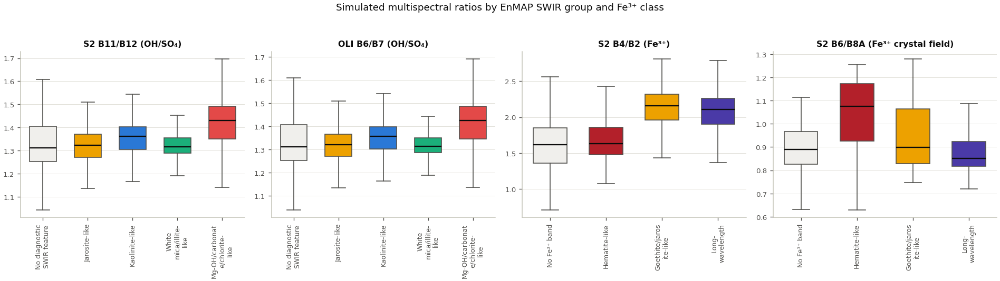

Real Sentinel-2 / Landsat rasters: none supplied (REFERENCE_RASTERS = {}).


In [17]:
from scipy.special import erf

S2A_BANDS = {"B2": (492.7, 65), "B3": (559.9, 35), "B4": (664.6, 31), "B5": (704.1, 15), "B6": (740.5, 13),
             "B7": (782.8, 19), "B8": (832.8, 118), "B8A": (864.7, 20), "B11": (1613.7, 89), "B12": (2202.4, 180)}
OLI_BANDS = {"B2": (452, 512), "B3": (533, 590), "B4": (636, 673), "B5": (851, 879), "B6": (1566, 1651), "B7": (2107, 2294)}

def simulate_band(lo, hi, X=XA):
    s = FWHM / 2.3548
    w_all = 0.5 * (erf((hi - WL) / (math.sqrt(2) * s)) - erf((lo - WL) / (math.sqrt(2) * s)))
    w = np.where(GOOD, w_all, 0.0)
    coverage = w.sum() / w_all.sum() if w_all.sum() > 0 else 0.0
    if coverage < 0.6:
        return np.full(len(X), np.nan, "float32"), coverage
    return (X[:, GOOD] @ (w[GOOD] / w.sum())).astype("float32"), coverage

SIM, cov_rows = {}, []
for b, (c, wdt) in S2A_BANDS.items():
    SIM[f"S2 {b}"], cv = simulate_band(c - wdt / 2, c + wdt / 2); cov_rows.append((f"S2 {b}", cv))
for b, (lo, hi) in OLI_BANDS.items():
    SIM[f"OLI {b}"], cv = simulate_band(lo, hi); cov_rows.append((f"OLI {b}", cv))
_low = [f"{n} ({100 * c:.0f} %)" for n, c in cov_rows if c < 0.9]
if _low:
    print("Simulated bands partly covered by used EnMAP bands: " + ", ".join(_low))

with np.errstate(invalid="ignore", divide="ignore"):
    _cont8a = SIM["S2 B6"] + (SIM["S2 B11"] - SIM["S2 B6"]) * (864.7 - 740.5) / (1613.7 - 740.5)
    _cont5 = SIM["OLI B4"] + (SIM["OLI B6"] - SIM["OLI B4"]) * (865 - 654.5) / (1608.5 - 654.5)
    PROXY = {"S2 B4/B2 (Fe³⁺)": SIM["S2 B4"] / SIM["S2 B2"], "S2 B4/B3 (Fe³⁺, blue-free)": SIM["S2 B4"] / SIM["S2 B3"],
             "S2 B6/B8A (Fe³⁺ crystal field)": SIM["S2 B6"] / SIM["S2 B8A"],
             "S2 NIR depth B8A": 1 - SIM["S2 B8A"] / _cont8a, "S2 B11/B8A (SWIR1/NIR)": SIM["S2 B11"] / SIM["S2 B8A"],
             "S2 B11/B12 (OH/SO₄)": SIM["S2 B11"] / SIM["S2 B12"],
             "OLI B4/B2 (Fe³⁺)": SIM["OLI B4"] / SIM["OLI B2"], "OLI NIR depth B5": 1 - SIM["OLI B5"] / _cont5,
             "OLI B6/B5 (SWIR1/NIR)": SIM["OLI B6"] / SIM["OLI B5"], "OLI B6/B7 (OH/SO₄)": SIM["OLI B6"] / SIM["OLI B7"]}
ENMAP_LAYERS = {f"{f} depth": np.clip(RES[f]["depth_any"], 0, None) for f in FEATURES}
ENMAP_LAYERS["max 2.2-2.36 µm depth"] = np.max(np.stack([ENMAP_LAYERS[f"{f} depth"] for f in ("AlOH_2200", "FeOH_2265", "MgOH_2330")]), axis=0)
ENMAP_LAYERS["NDVI"], ENMAP_LAYERS["CAI"], ENMAP_LAYERS["albedo"] = NDVI[ANALYSED], CAI[ANALYSED], ALBEDO[ANALYSED]
_sub = np.random.default_rng(RANDOM_STATE).choice(N_AN, min(N_AN, 50000), replace=False)
Mp = np.column_stack([PROXY[k][_sub] for k in PROXY]); Me = np.column_stack([ENMAP_LAYERS[k][_sub] for k in ENMAP_LAYERS])
okp = np.isfinite(Mp).all(axis=1) & np.isfinite(Me).all(axis=1)
_rho = np.asarray(stats.spearmanr(np.column_stack([Mp[okp], Me[okp]]))[0])
BRIDGE_RHO = pd.DataFrame(_rho[:len(PROXY), len(PROXY):], index=list(PROXY), columns=list(ENMAP_LAYERS))
BRIDGE_RHO.to_csv(TABLE_DIR / "tab_19_multispectral_proxies_vs_enmap.csv", float_format="%.3f", encoding="utf-8-sig")
print(f"Spearman ρ between simulated multispectral ratios and EnMAP layers (n = {okp.sum():,} analysed pixels):")
print(BRIDGE_RHO.round(2).to_string())

any_swir = DET["AlOH_2200"] | DET["FeOH_2265"] | DET["MgOH_2330"]
TARGETS = {"Fe³⁺ band": DET["Fe3_900"], "any 2.2-2.36 µm band": any_swir, **{GROUP_NAMES[k].split(" (")[0]: GROUPS == k
                                                                              for k in range(1, len(GROUP_NAMES))}}
jrows = []
for k, v in PROXY.items():
    ok = np.isfinite(v)
    top = ok & (v >= np.nanpercentile(v, 100 - TOP_PERCENT))
    row = {"proxy": k}
    for target, mask_ in TARGETS.items():
        row[target] = 100 * (mask_ & top).sum() / max(top.sum(), 1)
    jrows.append(row)
BRIDGE_TOP = pd.DataFrame(jrows).set_index("proxy")
BRIDGE_TOP.loc["share of all analysed pixels"] = [100 * m.mean() for m in TARGETS.values()]
BRIDGE_TOP.to_csv(TABLE_DIR / "tab_20_multispectral_top_pixels_composition.csv", float_format="%.1f", encoding="utf-8-sig")
print(f"\nComposition of the top {TOP_PERCENT} % pixels of each simulated ratio (% of those pixels with each EnMAP feature "
      "or group; last row = share among all analysed pixels, i.e. what an unrelated ratio would give):")
print(BRIDGE_TOP.round(1).to_string())

fig, ax = plt.subplots(figsize=(11.5, 5.0))
im = ax.imshow(BRIDGE_RHO.to_numpy(), cmap=DIVERGING, vmin=-1, vmax=1, aspect="auto")
ax.set_xticks(range(BRIDGE_RHO.shape[1])); ax.set_xticklabels(BRIDGE_RHO.columns, rotation=35, ha="right", fontsize=8)
ax.set_yticks(range(BRIDGE_RHO.shape[0])); ax.set_yticklabels(BRIDGE_RHO.index, fontsize=8)
for i in range(BRIDGE_RHO.shape[0]):
    for j in range(BRIDGE_RHO.shape[1]):
        ax.text(j, i, f"{BRIDGE_RHO.iat[i, j]:.2f}", ha="center", va="center", fontsize=7,
                color="white" if abs(BRIDGE_RHO.iat[i, j]) > 0.6 else INK)
fig.colorbar(im, ax=ax, fraction=0.03, pad=0.02).set_label("Spearman ρ", color=INK_2)
ax.set_title("Simulated Sentinel-2 / Landsat ratios against EnMAP absorption features (analysed pixels)", fontsize=10, loc="left")
fig.tight_layout(); save_fig(fig, "fig_28_multispectral_vs_enmap_rho"); plt.show()

_show = [("S2 B11/B12 (OH/SO₄)", GROUPS, GROUP_NAMES, GROUP_COLORS), ("OLI B6/B7 (OH/SO₄)", GROUPS, GROUP_NAMES, GROUP_COLORS),
         ("S2 B4/B2 (Fe³⁺)", FECLS, FE_NAMES, FE_COLORS), ("S2 B6/B8A (Fe³⁺ crystal field)", FECLS, FE_NAMES, FE_COLORS)]
fig, axes = plt.subplots(1, 4, figsize=(16, 4.6))
for ax, (k, lab_, names_, colors_) in zip(axes, _show):
    present = [c for c in range(len(names_)) if (lab_ == c).sum() >= 10]
    data = [PROXY[k][(lab_ == c) & np.isfinite(PROXY[k])] for c in present]
    bp = ax.boxplot(data, widths=0.6, patch_artist=True, showfliers=False,
                    medianprops=dict(color=INK, lw=1.4), whiskerprops=dict(color=INK_2), capprops=dict(color=INK_2))
    for patch, c in zip(bp["boxes"], present):
        patch.set_facecolor(colors_[c] if colors_[c] != "#ffffff" else "#f0efec"); patch.set_edgecolor(INK_2)
    ax.set_xticks(range(1, len(present) + 1))
    ax.set_xticklabels([textwrap.fill(names_[c].split(" (")[0], 14) for c in present], rotation=90, fontsize=7.5)
    ax.set_title(k, fontsize=9.5); style_chart(ax)
fig.suptitle("Simulated multispectral ratios by EnMAP SWIR group and Fe³⁺ class", fontsize=11, color=INK)
fig.tight_layout(rect=(0, 0, 1, 0.95)); save_fig(fig, "fig_29_multispectral_by_enmap_class"); plt.show()

REFERENCE = {}
if not REFERENCE_RASTERS:
    print("Real Sentinel-2 / Landsat rasters: none supplied (REFERENCE_RASTERS = {}).")
else:
    thin = np.zeros((H, W), bool); thin[::3, ::3] = True
    thin_a = thin[ANALYSED]
    ref_rows = []
    for label, path in REFERENCE_RASTERS.items():
        arr = read_layer_to_grid(path, categorical=False)
        REFERENCE[label] = arr
        v = arr[ANALYSED]; ok = np.isfinite(v) & thin_a
        print(f"{label}: {int(np.isfinite(v).sum()):,} analysed pixels with values ({int(ok.sum()):,} after thinning)")
        if ok.sum() < 30:
            print("  too few overlapping pixels - check CRS and extent"); continue
        for kk, lay in {**ENMAP_LAYERS, **{f"simulated {p}": PROXY[p] for p in PROXY}}.items():
            m = ok & np.isfinite(lay)
            ref_rows.append({"reference": label, "layer": kk, "n_thinned": int(m.sum()),
                             "spearman_rho": stats.spearmanr(v[m], lay[m])[0] if m.sum() >= 30 else np.nan})
        best = max([r for r in ref_rows if r["reference"] == label and not r["layer"].startswith("simulated")],
                   key=lambda r: abs(np.nan_to_num(r["spearman_rho"])))
        m = ok & np.isfinite(ENMAP_LAYERS[best["layer"]])
        fig, ax = plt.subplots(figsize=(5.2, 4.2))
        hb = ax.hexbin(ENMAP_LAYERS[best["layer"]][m], v[m], gridsize=40, cmap=SEQ_BLUE, mincnt=1, linewidths=0)
        ax.set_xlabel(f"EnMAP {best['layer']}"); ax.set_ylabel(label)
        ax.set_title(f"ρ = {best['spearman_rho']:.2f} (every 3rd pixel, n = {best['n_thinned']:,})", fontsize=9.5)
        style_chart(ax, grid_axis="both"); fig.colorbar(hb, ax=ax, fraction=0.046, pad=0.03).set_label("pixels", color=INK_2)
        fig.tight_layout(); save_fig(fig, f"fig_30_reference_{re.sub(r'[^A-Za-z0-9]+', '_', label).strip('_')}"); plt.show()
    if ref_rows:
        REF_TABLE = pd.DataFrame(ref_rows)
        REF_TABLE.to_csv(TABLE_DIR / "tab_21_reference_rasters.csv", index=False, float_format="%.4f", encoding="utf-8-sig")
        print(REF_TABLE.pivot_table(index="layer", columns="reference", values="spearman_rho").round(2).to_string())

## 13 · Validation against field samples (optional)

Each sample is represented by the analysed pixels of a `SAMPLE_WINDOW` × `SAMPLE_WINDOW` window: mean depth of
each feature (0 where not detected), share of pixels with the feature detected, mean Fe³⁺ and Al-OH positions of
detected pixels, and the most frequent SWIR group and Fe³⁺ class. Numeric attributes (e.g. Fe, S, As) are compared
with Spearman's ρ. An FTIR mineral column is cross-tabulated with the SWIR groups and Fe³⁺ classes and tested with
Kruskal–Wallis (or Mann–Whitney for two classes). A hand sample represents centimetres, a pixel 900 m² of mixed
surface, and sampling and image dates differ: read ρ as consistency, not calibration, and report n.

In [18]:
SAMPLES = None
if not SAMPLES_CSV:
    print("Sample validation skipped: set SAMPLES_CSV (and SAMPLE_VALUE_COLS / SAMPLE_CLASS_COL) in CONFIG.")
else:
    SAMPLES = pd.read_csv(_resolve(SAMPLES_CSV))
    xs = SAMPLES[SAMPLE_X_COL].astype(float).to_numpy(); ys = SAMPLES[SAMPLE_Y_COL].astype(float).to_numpy()
    if SAMPLE_CRS and rasterio.crs.CRS.from_user_input(SAMPLE_CRS) != CRS:
        xs, ys = warp_transform(SAMPLE_CRS, CRS, xs, ys); xs, ys = np.asarray(xs), np.asarray(ys)
    cols_f, rows_f = ~TRANSFORM * (xs, ys)
    rows_i, cols_i = np.floor(rows_f).astype(int), np.floor(cols_f).astype(int)
    half = SAMPLE_WINDOW // 2
    LAYERS_S = {f"{f}_depth": to_map(np.where(DET[f], RES[f]["depth"], 0.0)) for f in FEATURES}
    LAYERS_S.update({f"{f}_detected": to_map(DET[f].astype("float32")) for f in FEATURES})
    LAYERS_S.update({f"{f}_position_nm": to_map(np.where(DET[f], RES[f]["pos"], np.nan)) for f in ("Fe3_900", "AlOH_2200", "FeOH_2265")})
    LAYERS_S["CAI"] = np.where(ANALYSED, CAI, np.nan)
    recs = []
    for r0, c0 in zip(rows_i, cols_i):
        rec = {"inside_grid": bool(0 <= r0 < H and 0 <= c0 < W)}
        rs, cs = slice(max(r0 - half, 0), max(min(r0 + half + 1, H), 0)), slice(max(c0 - half, 0), max(min(c0 + half + 1, W), 0))
        an = ANALYSED[rs, cs]
        rec["analysed_px_in_window"] = int(an.sum())
        rec["mask_class_at_sample"] = (MASK_NAMES[int(MASK_CODE[r0, c0])] if rec["inside_grid"] and MASK_CODE[r0, c0] >= 0
                                       else "outside AOI")
        for k, lay in LAYERS_S.items():
            w_ = lay[rs, cs][an]
            rec[k] = float(np.nanmean(w_)) if w_.size and np.isfinite(w_).any() else np.nan
        for k, lay, names_ in (("swir_group", GROUP_MAP, GROUP_NAMES), ("fe3_class", FE_MAP, FE_NAMES)):
            w_ = lay[rs, cs][an]
            rec[k] = names_[int(np.bincount(w_).argmax())] if w_.size else "not analysed"
        recs.append(rec)
    SAMPLES = pd.concat([SAMPLES, pd.DataFrame(recs)], axis=1)
    SAMPLES.to_csv(TABLE_DIR / "tab_22_samples_with_enmap_features.csv", index=False, float_format="%.5f", encoding="utf-8-sig")
    n_ok = int((SAMPLES["analysed_px_in_window"] > 0).sum())
    print(f"Samples: {len(SAMPLES)} read, {int(SAMPLES['inside_grid'].sum())} inside the grid, {n_ok} with analysed pixels "
          f"in the {SAMPLE_WINDOW} × {SAMPLE_WINDOW} window")
    print("Mask class at the sample pixel: " + ", ".join(f"{k}: {v}" for k, v in SAMPLES["mask_class_at_sample"].value_counts().items()))
    if n_ok < 10:
        print("  NOTE: fewer than 10 usable samples - correlations are not meaningful.")
    MAIN_S = ["Fe3_900_depth", "FeOH_2265_depth", "AlOH_2200_depth", "Fe3_900_position_nm"]
    corr_rows = []
    for vc in SAMPLE_VALUE_COLS:
        yv = pd.to_numeric(SAMPLES[vc], errors="coerce")
        for k in LAYERS_S:
            ok = np.isfinite(SAMPLES[k]) & np.isfinite(yv)
            rho, pval = stats.spearmanr(SAMPLES.loc[ok, k], yv[ok]) if ok.sum() >= 5 else (np.nan, np.nan)
            corr_rows.append({"attribute": vc, "enmap_layer": k, "n": int(ok.sum()), "spearman_rho": rho, "p_value": pval})
    if corr_rows:
        SAMPLE_CORR = pd.DataFrame(corr_rows)
        SAMPLE_CORR.to_csv(TABLE_DIR / "tab_23_sample_spearman.csv", index=False, float_format="%.4f", encoding="utf-8-sig")
        print(SAMPLE_CORR.pivot_table(index="enmap_layer", columns="attribute", values="spearman_rho").round(2).to_string())
        vcs = SAMPLE_VALUE_COLS[:3]
        fig, axes = plt.subplots(len(vcs), len(MAIN_S), figsize=(3.1 * len(MAIN_S), 2.8 * len(vcs)), squeeze=False)
        for i, vc in enumerate(vcs):
            yv = pd.to_numeric(SAMPLES[vc], errors="coerce")
            for j, k in enumerate(MAIN_S):
                ax = axes[i, j]; ok = np.isfinite(SAMPLES[k]) & np.isfinite(yv)
                ax.scatter(SAMPLES.loc[ok, k], yv[ok], s=28, color=SERIES[0], edgecolor="white", linewidth=0.8)
                r_ = SAMPLE_CORR[(SAMPLE_CORR.attribute == vc) & (SAMPLE_CORR.enmap_layer == k)].iloc[0]
                ax.set_title(f"ρ = {r_.spearman_rho:.2f} (n = {r_.n})", fontsize=8.5)
                ax.set_xlabel(k, fontsize=8); ax.set_ylabel(vc if j == 0 else "", fontsize=8)
                style_chart(ax, grid_axis="both")
        fig.suptitle("EnMAP features vs sample attributes (window means)", fontsize=11, color=INK)
        fig.tight_layout(rect=(0, 0, 1, 0.96)); save_fig(fig, "fig_31_samples_scatter"); plt.show()
    if SAMPLE_CLASS_COL:
        grp = SAMPLES[SAMPLE_CLASS_COL].astype(str)
        for col in ("swir_group", "fe3_class"):
            ct = pd.crosstab(grp, SAMPLES[col])
            ct.to_csv(TABLE_DIR / f"tab_24_{SAMPLE_CLASS_COL}_vs_{col}.csv", encoding="utf-8-sig")
            print(f"\n{SAMPLE_CLASS_COL} (rows) vs {col} (columns), samples:"); print(ct.to_string())
        levels = sorted(grp.unique())
        test_rows = []
        fig, axes = plt.subplots(1, 3, figsize=(max(3.4, 0.6 * len(levels) + 1.8) * 3, 3.8), squeeze=False)
        for j, k in enumerate(["Fe3_900_depth", "FeOH_2265_depth", "AlOH_2200_depth"]):
            data = [SAMPLES.loc[(grp == g) & np.isfinite(SAMPLES[k]), k].to_numpy() for g in levels]
            ax = axes[0, j]
            ax.boxplot([d if len(d) else np.array([np.nan]) for d in data], widths=0.5, patch_artist=True,
                       boxprops=dict(facecolor="#cde2fb", edgecolor=SERIES[0]), medianprops=dict(color=INK, lw=1.5),
                       whiskerprops=dict(color=SERIES[0]), capprops=dict(color=SERIES[0]),
                       flierprops=dict(marker="o", ms=4, markerfacecolor=SERIES[0], markeredgecolor="white"))
            ax.set_xticks(range(1, len(levels) + 1)); ax.set_xticklabels([f"{g}\n(n={len(d)})" for g, d in zip(levels, data)], fontsize=7.5)
            ax.set_title(k, fontsize=10); style_chart(ax)
            usable = [d for d in data if len(d) >= 3]
            if len(usable) == 2 and len(levels) == 2:
                st, pv = stats.mannwhitneyu(usable[0], usable[1], alternative="two-sided"); test = "Mann–Whitney U"
            elif len(usable) >= 3:
                st, pv = stats.kruskal(*usable); test = "Kruskal–Wallis H"
            else:
                st, pv, test = np.nan, np.nan, "too few samples"
            test_rows.append({"layer": k, "test": test, "statistic": st, "p_value": pv,
                              **{f"median[{g}]": (np.median(d) if len(d) else np.nan) for g, d in zip(levels, data)}})
        fig.suptitle(f"EnMAP feature depths by {SAMPLE_CLASS_COL}", fontsize=11, color=INK)
        fig.tight_layout(rect=(0, 0, 1, 0.93)); save_fig(fig, "fig_32_samples_by_class"); plt.show()
        SAMPLE_TESTS = pd.DataFrame(test_rows)
        SAMPLE_TESTS.to_csv(TABLE_DIR / "tab_25_sample_group_tests.csv", index=False, float_format="%.4f", encoding="utf-8-sig")
        print(SAMPLE_TESTS.round(4).to_string(index=False))
    fig = plot_categorical(ASSEM_MAP, "Samples over the Fe-mineral assemblage", ASSEMBLAGE_COLORS, ASSEMBLAGE_NAMES,
                           fname="fig_33_samples_on_assemblage", key_title="Assemblage", points=(xs, ys),
                           extra=[f"{len(SAMPLES)} samples (black dots)"])
    plt.show()

Sample validation skipped: set SAMPLES_CSV (and SAMPLE_VALUE_COLS / SAMPLE_CLASS_COL) in CONFIG.


## 14 · Endmembers: how many spectrally distinct materials, and which

§6–§13 name each pixel by its deepest diagnostic absorption. A 30 m pixel of waste is, however, an areal mixture
of secondary minerals, host-rock detritus, plant cover and shade, and §11 shows that the 2.26 and 2.30–2.36 µm
depths rise with CAI (plant litter). §14–§19 therefore model each pixel as a mixture of a small set of
**endmembers** (spectrally distinct materials), which gives sub-pixel fractions instead of one label per pixel
(review of the methods: Bioucas-Dias et al., 2012).

**How many?** Three estimators bracket the number of spectrally distinct signals: the MNF eigenvalues above 2
(§9), noise-whitened HFC (Chang & Du, 2004) at false-alarm rates of 10⁻³ and 10⁻⁵ (noise covariance of §9), and
HySime (Bioucas-Dias & Nascimento, 2008). They disagree because variability *within* a material also counts as
signal, so they bound the number rather than fix it. The number used (`N_ENDMEMBERS`) is taken from the unmixing
itself: FCLS (§15) is run for every p in `EM_P_RANGE` on 3,000 random analysed pixels, and "auto" takes the
smallest p at which fewer than 2 % of pixels are poorly modelled (RMSE > `UNMIX_MAX_RMSE`) and every endmember is
used (mean abundance ≥ 0.02).

**Which?** Green vegetation, dry plant material and soil are the basic endmembers of sparsely vegetated scenes
(Roberts et al., 1993). Two vegetation references come from pixels of the same cube that §4 masked: green vegetation (GV,
median of the pixels above the `VEG_REF_PERCENTILE` NDVI percentile) and dry plant material (NPV, the same for
CAI among pixels with NDVI < 0.3). The other p − 2 endmembers are found among the analysed pixels by **N-FINDR**
(Winter, 1999): the vertices of the largest simplex in the first p − 1 MNF dimensions. The two vegetation
references are held fixed as vertices, so N-FINDR searches for substrate materials instead of the least vegetated
version of plant cover. ATGP initialisation (Ren & Chang, 2003) makes the result deterministic. Each endmember
spectrum is the median of the vertex pixel and its nearest neighbours in MNF space (`EM_NEIGHBOURS` pixels), which
suppresses pixel noise. A vertex that no other pixel resembles is an outlier or a small surface rather than a mappable
material: image endmembers with fewer than `EM_MIN_SUPPORT` pixels of FCLS abundance ≥ 0.5 are removed before the
final unmixing (FCLS would otherwise use them as filler for unrelated pixels) and are listed in `tab_27` as removed.

**Interpretation** applies the continuum removal, detection and rules of §6–§7 to the endmember spectra, plus
NDVI, CAI and the hydrocarbon index of Kühn et al. (2004), because image endmembers near mines can be man-made
surfaces (plastic sheeting, bitumen) with C–H bands at 1.73 and 2.31 µm. Each image endmember is named after the
absorption in which it is most extreme relative to the analysed pixels (percentile of its depth). N-FINDR selects
endmembers by geometry alone, independently of the rules, so the interpretation is not circular. Image endmembers
are still 30 m mixtures: their names describe diagnostic absorptions, not pure minerals. Image endmembers are
numbered by decreasing Fe³⁺ depth, as the domains in §9.

In [19]:
# 14 · Dimensionality, vegetation references and N-FINDR endmembers
from scipy.optimize import nnls
from scipy.special import ndtri

UNMIX_BANDS = np.where(GOOD & ~ART)[0]                  # used, non-artefact bands: the band set of §14-§17
X_UNMIX = XA[:, UNMIX_BANDS].astype("float64")
XM_MEAN = XA[:, MNF_BANDS].astype("float64").mean(axis=0)

def median_spectrum(M):
    """Median spectrum over rows of M (pixels x all bands); NaN outside the used bands."""
    out = np.full(NB, np.nan)
    out[GOOD] = np.median(np.asarray(M)[:, GOOD], axis=0)
    return out

def mnf_scores(S, k):
    """Scores of spectra S (n x all bands) on the first k MNF components of §9 (same centring as the MNF)."""
    return (np.atleast_2d(S)[:, MNF_BANDS].astype("float64") - XM_MEAN) @ MNF_VEC[:, :k]

def hysime(Y):
    """HySime (Bioucas-Dias & Nascimento, 2008): noise by multiple regression, then the signal-subspace size.
    Y: pixels x bands. Returns k and the noise correlation matrix (bands x bands)."""
    Yt = Y.T
    L, N = Yt.shape
    R = Yt @ Yt.T
    Ri = np.linalg.inv(R + 1e-6 * np.trace(R) / L * np.eye(L))
    Wn = np.empty_like(Yt)
    for i in range(L):
        XX = Ri - np.outer(Ri[:, i], Ri[i, :]) / Ri[i, i]
        r_ = R[:, i].copy(); r_[i] = 0.0
        beta = XX @ r_; beta[i] = 0.0
        Wn[i] = Yt[i] - beta @ Yt
    Rn = Wn @ Wn.T / N
    S_ = Yt - Wn
    ev, V = np.linalg.eigh(S_ @ S_.T / N)
    V = V[:, np.argsort(ev)[::-1]]
    Ry = R / N
    delta = -np.einsum("ij,jk,ki->i", V.T, Ry, V) + 2 * np.einsum("ij,jk,ki->i", V.T, Rn, V)
    return int(np.sum(delta < 0)), Rn

def nwhfc(Y, noise_cov, pf):
    """Noise-whitened Harsanyi-Farrand-Chang virtual dimensionality (Chang & Du, 2004)."""
    ev, V = np.linalg.eigh(noise_cov)
    Z = Y @ (V @ np.diag(1.0 / np.sqrt(np.maximum(ev, 1e-12 * ev.max()))) @ V.T)
    lr = np.sort(np.linalg.eigvalsh(Z.T @ Z / len(Z)))[::-1]
    lk = np.sort(np.linalg.eigvalsh(np.cov(Z, rowvar=False)))[::-1]
    return int(np.sum(lr - lk > ndtri(1 - pf) * np.sqrt(2 * (lr ** 2 + lk ** 2) / len(Z))))

def nfindr(Z, p, fixed=()):
    """N-FINDR (Winter, 1999), ATGP-initialised (Ren & Chang, 2003), with optional fixed vertices.
    Z: pixels x (p - 1) scores; fixed: coordinates of vertices that stay in the simplex. Returns pixel indices."""
    N, m = len(Z), len(fixed)
    U = np.vstack([np.ones(N), Z.T])                       # affine coordinates
    cols = [np.concatenate([[1.0], np.asarray(f, float)]) for f in fixed]
    idx = []
    for _ in range(p - m):                                 # ATGP: largest residual outside the span of the vertices so far
        if cols:
            B = np.column_stack(cols)
            res_ = U - B @ np.linalg.lstsq(B, U, rcond=None)[0]
        else:
            res_ = U
        nrm = np.linalg.norm(res_, axis=0); nrm[idx] = -1.0
        j = int(np.argmax(nrm)); idx.append(j); cols.append(U[:, j])
    M = np.column_stack(cols)
    for _ in range(50):                                    # replace vertices while the simplex volume grows
        changed = False
        for j in range(m, p):
            ratio = np.abs(np.linalg.solve(M, U)[j])       # volume after swapping vertex j for each pixel / current volume
            ratio[idx] = 0.0
            i = int(np.argmax(ratio))
            if ratio[i] > 1 + 1e-9:
                idx[j - m] = i; M[:, j] = U[:, i]; changed = True
        if not changed:
            break
    return idx

def fcls(X, E, delta=1e3):
    """Fully constrained least squares (Heinz & Chang, 2001): abundances >= 0 that sum to one (sum-to-one row
    weighted by delta). X: pixels x bands, E: endmembers x bands. Returns abundances and RMSE (reflectance)."""
    A = np.vstack([E.T, np.full(len(E), delta)])
    b = np.empty(A.shape[0]); b[-1] = delta
    F = np.empty((len(X), len(E)))
    for n, x in enumerate(X):
        b[:-1] = x
        F[n] = nnls(A, b)[0]
    return F, np.sqrt(((X - F @ E) ** 2).mean(axis=1))

# 1 - number of spectrally distinct signals
_t0 = time.time()
HYSIME_K, HYSIME_RN = hysime(X_UNMIX)
_Xmnf = XA[:, MNF_BANDS].astype("float64")
VD_TABLE = pd.DataFrame([
    {"estimator": "MNF eigenvalue > 2 (§9)", "k": int((MNF_EIG > 2).sum())},
    {"estimator": "NWHFC, Pf = 1e-3 (noise of §9)", "k": nwhfc(_Xmnf, NOISE_COV, 1e-3)},
    {"estimator": "NWHFC, Pf = 1e-5 (noise of §9)", "k": nwhfc(_Xmnf, NOISE_COV, 1e-5)},
    {"estimator": "HySime", "k": HYSIME_K}])
del _Xmnf
print("Number of spectrally distinct signals:")
print(VD_TABLE.to_string(index=False))
print(f"HySime noise (regression residual): median SD {np.median(np.sqrt(np.diag(HYSIME_RN))):.5f} reflectance "
      f"(adjacent-pixel differences of §9, which include texture: {np.median(np.sqrt(np.diag(NOISE_COV))):.4f})")

# 2 - vegetation references from pixels masked in §4
_valid = AOI_MASK & VALID_ALL & (R_RED > 0.005)
_gv_c = _valid & (NDVI <= 0.95)
GV_SEL = _gv_c & (NDVI >= np.nanpercentile(NDVI[_gv_c], VEG_REF_PERCENTILE))
_npv_c = _valid & (NDVI < NDVI_VEG_THRESHOLD)
NPV_SEL = _npv_c & (CAI >= np.nanpercentile(CAI[_npv_c], VEG_REF_PERCENTILE))
if GV_SEL.sum() < 5 or NPV_SEL.sum() < 5:
    raise RuntimeError("Fewer than 5 pixels for a vegetation reference: lower VEG_REF_PERCENTILE.")
GV_REF, NPV_REF = median_spectrum(CUBE[GV_SEL]), median_spectrum(CUBE[NPV_SEL])
print(f"\nVegetation references: GV = median of {int(GV_SEL.sum())} px (NDVI ≥ {np.nanpercentile(NDVI[_gv_c], VEG_REF_PERCENTILE):.2f}, "
      f"median NDVI {np.median(NDVI[GV_SEL]):.2f}); NPV = median of {int(NPV_SEL.sum())} px (CAI ≥ "
      f"{np.nanpercentile(CAI[_npv_c], VEG_REF_PERCENTILE):.3f}, median NDVI {np.median(NDVI[NPV_SEL]):.2f})")

# 3 - N-FINDR for each p, FCLS on a subset, choice of p
_sub_em = np.random.default_rng(RANDOM_STATE).choice(N_AN, min(N_AN, 3000), replace=False)
_p_rows, _cand = [], {}
for p in EM_P_RANGE:
    if p < 3 or p - 1 > len(MNF_EIG):
        continue
    Z_ = mnf_scores(XA, p - 1)
    vid = nfindr(Z_, p, fixed=mnf_scores(np.stack([GV_REF, NPV_REF]), p - 1))
    nbrs = [np.argsort(np.linalg.norm(Z_ - Z_[i], axis=1))[:max(EM_NEIGHBOURS, 1)] for i in vid]
    E_ = np.stack([GV_REF, NPV_REF] + [median_spectrum(XA[nn]) for nn in nbrs])
    F_, rm_ = fcls(X_UNMIX[_sub_em], E_[:, UNMIX_BANDS])
    _cand[p] = (vid, nbrs, E_)
    _p_rows.append({"p": p, "image_endmembers": p - 2, "rmse_median": float(np.median(rm_)),
                    "rmse_p95": float(np.percentile(rm_, 95)),
                    "pct_rmse_above_max": 100 * float((rm_ > UNMIX_MAX_RMSE).mean()),
                    "min_mean_abundance": float(F_.mean(axis=0).min()),
                    "n_unused_endmembers": int((F_.mean(axis=0) < 0.02).sum())})
EM_P_TABLE = pd.DataFrame(_p_rows)
if isinstance(N_ENDMEMBERS, str) and N_ENDMEMBERS == "auto":
    _ok = EM_P_TABLE[(EM_P_TABLE.pct_rmse_above_max < 2.0) & (EM_P_TABLE.n_unused_endmembers == 0)]
    P_EM = int(_ok.p.iloc[0]) if len(_ok) else int(EM_P_TABLE.loc[EM_P_TABLE.pct_rmse_above_max.idxmin(), "p"])
    P_WHY = ("smallest p with < 2 % poorly modelled pixels and every endmember used" if len(_ok)
             else "no p met the rule: p with the fewest poorly modelled pixels")
else:
    P_EM, P_WHY = int(N_ENDMEMBERS), "set in CONFIG"
    if P_EM not in _cand:
        raise ValueError(f"N_ENDMEMBERS = {P_EM} is not in EM_P_RANGE {list(EM_P_RANGE)}")
EM_P_TABLE["chosen"] = EM_P_TABLE.p == P_EM
EM_P_TABLE.to_csv(TABLE_DIR / "tab_26_endmember_number.csv", index=False, float_format="%.5f", encoding="utf-8-sig")
print(f"\nFCLS on {len(_sub_em):,} random analysed pixels for each number of endmembers p (incl. GV and NPV):")
print(EM_P_TABLE.round(4).to_string(index=False))
print(f"-> p = {P_EM} ({P_WHY}); {time.time() - _t0:.1f} s")

# 4 - final endmembers: isolated vertices removed, the rest ordered by decreasing Fe3+ depth (as the domains in §9)
_vid, _nbrs, _E = _cand[P_EM]
_F_all, _ = fcls(X_UNMIX, _E[:, UNMIX_BANDS])
_support = (_F_all >= 0.5).sum(axis=0)
_keep = [j for j in range(2, P_EM) if _support[j] >= EM_MIN_SUPPORT]
_drop = [j for j in range(2, P_EM) if _support[j] < EM_MIN_SUPPORT]
_r0, _ = analyse_spectra(_E[_keep], keep_cr=False)
_o = [_keep[i] for i in np.argsort(-_r0["Fe3_900"]["depth_any"])]
EM_PIX, EM_NBRS = [_vid[j - 2] for j in _o], [_nbrs[j - 2] for j in _o]
EM_SPEC = np.vstack([_E[:2], _E[_o]])
EM_IDS = ["GV", "NPV"] + [f"EM{k + 1}" for k in range(len(_o))]
N_EM = len(EM_IDS)
E_UNMIX = EM_SPEC[:, UNMIX_BANDS]
PRUNED_SPEC = _E[_drop] if _drop else np.empty((0, NB))
PRUNED_PIX, PRUNED_NBRS = [_vid[j - 2] for j in _drop], [_nbrs[j - 2] for j in _drop]
PRUNED_SUPPORT = [int(_support[j]) for j in _drop]
PRUNED_IDS = [f"X{k + 1}" for k in range(len(_drop))]
if _drop:
    print(f"Removed as isolated vertices (fewer than EM_MIN_SUPPORT = {EM_MIN_SUPPORT} px with FCLS abundance ≥ 0.5): "
          + ", ".join(f"{i} ({s} px)" for i, s in zip(PRUNED_IDS, PRUNED_SUPPORT))
          + f". Final model: {N_EM} endmembers (GV, NPV and {N_EM - 2} image endmembers).")

Number of spectrally distinct signals:
                     estimator  k
       MNF eigenvalue > 2 (§9) 46
NWHFC, Pf = 1e-3 (noise of §9) 12
NWHFC, Pf = 1e-5 (noise of §9)  7
                        HySime 39
HySime noise (regression residual): median SD 0.00087 reflectance (adjacent-pixel differences of §9, which include texture: 0.0198)

Vegetation references: GV = median of 297 px (NDVI ≥ 0.69, median NDVI 0.72); NPV = median of 148 px (CAI ≥ 0.046, median NDVI 0.18)

FCLS on 3,000 random analysed pixels for each number of endmembers p (incl. GV and NPV):
 p  image_endmembers  rmse_median  rmse_p95  pct_rmse_above_max  min_mean_abundance  n_unused_endmembers  chosen
 6                 4       0.0095    0.0646             16.4000              0.0874                    0   False
 8                 6       0.0080    0.0216              3.7000              0.0459                    0   False
10                 8       0.0068    0.0172              1.3333              0.0277             

 id                                               status                                                                                        label                                            host_group  mean_reflectance  NDVI    CAI
 GV                                                 used                                                           Green vegetation (scene reference)                                  Vegetation (GV, NPV)             0.145 0.740  0.006
NPV                                                 used                                                         Dry plant material (scene reference)                                  Vegetation (GV, NPV)             0.344 0.192  0.048
EM1                                                 used              Strong Fe³⁺ band 916 nm (goethite/jarosite-like) + 2.26 µm band (jarosite-like) Fe³⁺ oxyhydroxide / sulphate (goethite-jarosite-like)             0.234 0.015 -0.007
EM2                                                 used    

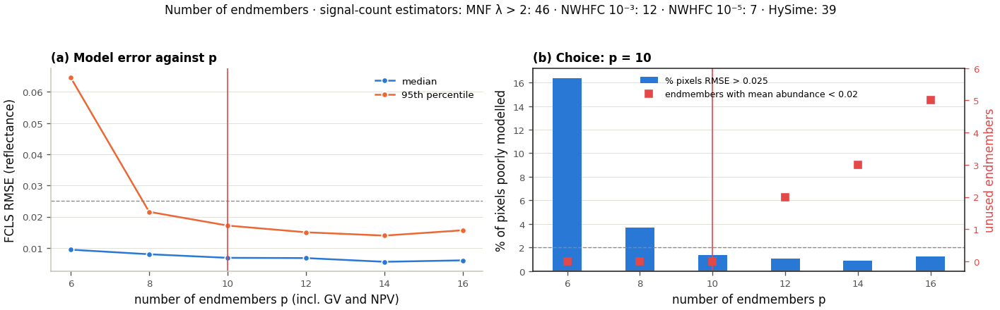

  saved  fig_35_endmember_spectra.png  +  fig_35_endmember_spectra.pdf   (400 dpi)


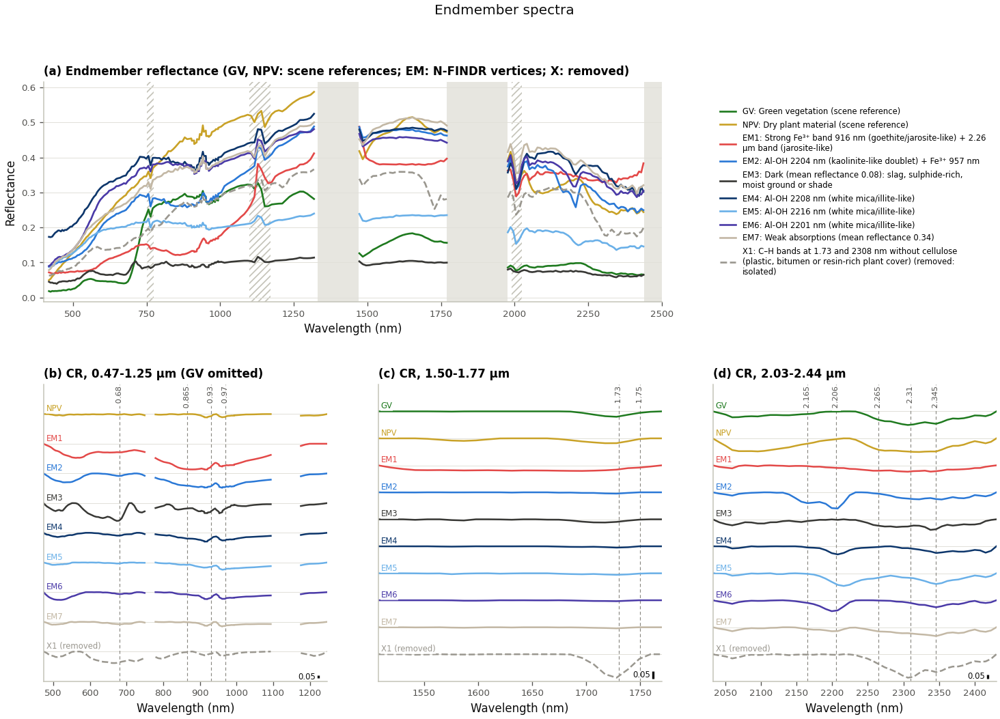

  saved  fig_36_endmember_locations.png  +  fig_36_endmember_locations.pdf   (400 dpi)


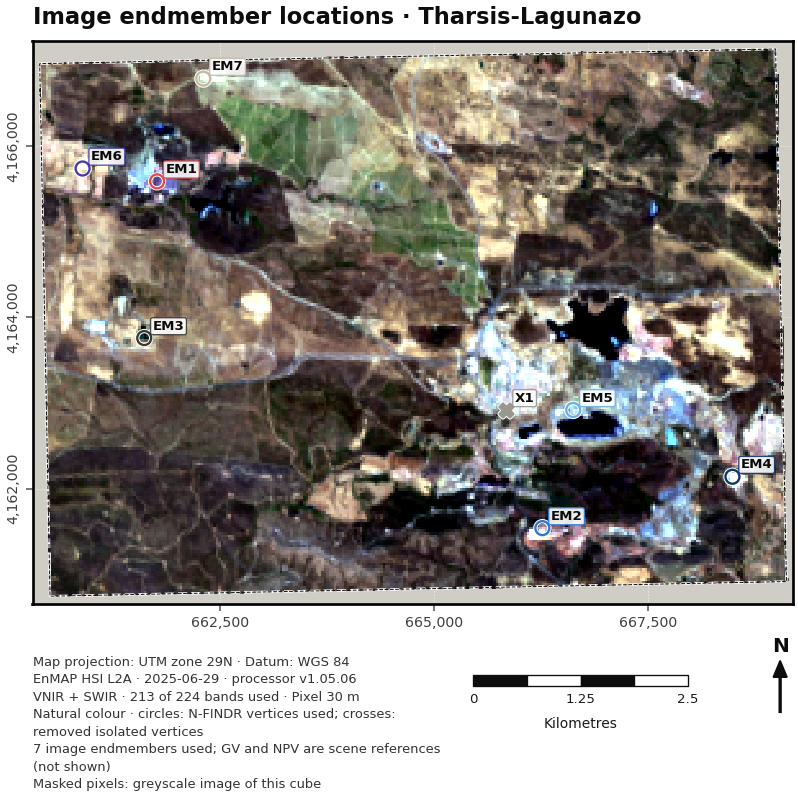

In [20]:
# 14 · Interpretation of the endmembers with the feature engine of §6-§7
def _bm_spec(S, lo, hi):
    j = np.where(GOOD & ~ART & (WL >= lo) & (WL <= hi))[0]
    return np.nanmean(np.atleast_2d(S)[:, j], axis=1)

def spectral_indices(S):
    """NDVI, CAI (§4 definitions), mean reflectance, hydrocarbon index (Kühn et al., 2004) of spectra S (n x all bands)."""
    S = np.atleast_2d(S)
    red, nir = _bm_spec(S, 650, 680), _bm_spec(S, 800, 870)
    with np.errstate(invalid="ignore", divide="ignore"):
        ndvi = (nir - red) / (nir + red)
    cai = 0.5 * (_bm_spec(S, 2015, 2045) + _bm_spec(S, 2195, 2225)) - _bm_spec(S, 2085, 2115)
    a, b, c = (int(np.argmin(np.abs(np.where(GOOD, WL, np.inf) - nm))) for nm in (1705, 1729, 1741))
    hi_ = (WL[b] - WL[a]) * (S[:, c] - S[:, a]) / (WL[c] - WL[a]) + S[:, a] - S[:, b]
    return ndvi, cai, np.nanmean(S[:, GOOD & ~ART], axis=1), hi_

HOST_GROUPS = ["Vegetation (GV, NPV)", "Fe³⁺ oxyhydroxide / sulphate (goethite-jarosite-like)", "Hematite-like Fe³⁺ oxide",
               "Al-OH phyllosilicate (kaolinite, white mica)", "Fe-Mg-OH phyllosilicate (chlorite-like)",
               "Sulphate (gypsum, alunite-like)", "Dark, weakly featured material", "Man-made C–H surface (plastic, bitumen-like)",
               "Background substrate (weak features)", "Unassigned"]
_FAMILY_COLORS = {HOST_GROUPS[1]: ["#e34948", "#eb6834", "#b3202a", "#f08a3c"], HOST_GROUPS[2]: ["#7a0c16", "#9c2d20"],
                  HOST_GROUPS[3]: ["#2a78d6", "#0d366b", "#6ab0e8", "#4a3aa7"], HOST_GROUPS[4]: ["#8e44ad", "#b07cc6"],
                  HOST_GROUPS[5]: ["#e87ba4"], HOST_GROUPS[6]: ["#383835", "#5a5955"], HOST_GROUPS[7]: ["#d63384"],
                  HOST_GROUPS[8]: ["#c3b8a5", "#a89f91", "#d8cfbf"], HOST_GROUPS[9]: ["#898781"]}
DARK_EM_ALBEDO = 0.10          # mean reflectance below which an endmember is "dark"
DISTINCT_PERCENTILE = 90       # an absorption names an endmember only if its depth is at or above this scene percentile

ALL_SPEC = np.vstack([EM_SPEC, PRUNED_SPEC])                        # kept endmembers, then removed isolated vertices
ALL_IDS = EM_IDS + PRUNED_IDS
N_ALL = len(ALL_IDS)
R_EM, CR_EM = analyse_spectra(ALL_SPEC)
D_EM = detect(R_EM)
G_EM, FE_EM = swir_groups(R_EM, D_EM), fe_classes(R_EM, D_EM)
EM_NDVI, EM_CAI, EM_ALB, EM_HI = spectral_indices(ALL_SPEC)
_x1 = WL[WIN_BANDS["SWIR1"]]
EM_CH173 = 1 - CR_EM["SWIR1"][:, (_x1 >= 1715) & (_x1 <= 1745)].min(axis=1)
_PCTL_FEATURES = ["Fe3_900", "AlOH_2200", "FeOH_2265", "MgOH_2330", "SO4_1750"]
EM_PCTL = {f: np.array([stats.percentileofscore(RES[f]["depth_any"], v) for v in R_EM[f]["depth_any"]]) for f in _PCTL_FEATURES}

def _fe_word(k):
    p = R_EM["Fe3_900"]["pos"][k]
    a, b, e = FE_POSITION_NM
    return ("hematite-like" if p < a else "intermediate" if p <= b else "goethite/jarosite-like" if p <= e
            else "long-wavelength (Fe²⁺, mixed or leaf water)")

_FEAT_SHORT = {"Fe3_900": "Fe³⁺", "AlOH_2200": "Al-OH", "FeOH_2265": "2.26 µm band", "MgOH_2330": "2.30-2.36 µm band",
               "SO4_1750": "1.75 µm band"}

def interpret_endmember(k):
    """Long label, short label and host group of endmember k, from its most extreme detected absorption (percentile
    of its depth among the analysed pixels)."""
    if k == 0:
        return "Green vegetation (scene reference)", "green vegetation (reference)", HOST_GROUPS[0]
    if k == 1:
        return "Dry plant material (scene reference)", "dry plant material (reference)", HOST_GROUPS[0]
    if EM_CH173[k] >= 0.05 and EM_CAI[k] <= 0.5 * CAI_NPV_THRESHOLD:
        return (f"C–H bands at 1.73 and {R_EM['MgOH_2330']['pos'][k]:.0f} nm without cellulose (plastic, bitumen or "
                "resin-rich plant cover)", "C–H 1.73 + 2.31 µm (plastic/bitumen-like)", HOST_GROUPS[7])
    if EM_ALB[k] < DARK_EM_ALBEDO:
        return (f"Dark (mean reflectance {EM_ALB[k]:.2f}): slag, sulphide-rich, moist ground or shade",
                "dark (slag, sulphide, moist or shade)", HOST_GROUPS[6])
    cand = sorted([f for f in _PCTL_FEATURES if D_EM[f][k] and EM_PCTL[f][k] >= DISTINCT_PERCENTILE],
                  key=lambda f: -EM_PCTL[f][k])
    if not cand:
        return (f"Weak absorptions (mean reflectance {EM_ALB[k]:.2f})", "weak absorptions (background substrate)",
                HOST_GROUPS[8])
    f, pos = cand[0], R_EM[cand[0]]["pos"][k]
    jar = bool(D_EM["FeOH_2265"][k] and D_EM["Fe3_900"][k] and R_EM["Fe3_900"]["pos"][k] >= FE_POSITION_NM[0])
    rest = [g for g in cand[1:] if not (jar and g == "FeOH_2265")][:1]
    tail = "".join(f" + {_FEAT_SHORT[g]} {R_EM[g]['pos'][k]:.0f} nm" for g in rest)
    if f == "Fe3_900":
        word = _fe_word(k)
        grp = HOST_GROUPS[2] if word == "hematite-like" else HOST_GROUPS[9] if word.startswith("long") else HOST_GROUPS[1]
        return (f"Strong Fe³⁺ band {pos:.0f} nm ({word}){' + 2.26 µm band (jarosite-like)' if jar else ''}{tail}",
                f"Fe³⁺ {pos:.0f} nm{' + 2.26 µm' if jar else ''} ({word.split(' (')[0]})", grp)
    if f == "AlOH_2200":
        kind = "kaolinite-like" if G_EM[k] == 3 else "white mica/illite-like" if G_EM[k] == 4 else "Al-OH"
        return f"Al-OH {pos:.0f} nm ({kind}{' doublet' if G_EM[k] == 3 else ''}){tail}", f"Al-OH {pos:.0f} nm ({kind})", HOST_GROUPS[3]
    if f == "FeOH_2265":
        kind = "jarosite-like" if jar else "jarosite, gypsum or Fe-chlorite"
        return (f"2.26 µm band {pos:.0f} nm ({kind}){tail}", f"2.26 µm {pos:.0f} nm ({kind})",
                HOST_GROUPS[1] if jar else HOST_GROUPS[9])
    if f == "MgOH_2330":
        return (f"2.30-2.36 µm band {pos:.0f} nm (chlorite / Fe-Mg-OH-like){tail}", f"2.3 µm {pos:.0f} nm (chlorite-like)",
                HOST_GROUPS[4])
    return f"1.75 µm band {pos:.0f} nm (gypsum/alunite-like){tail}", "1.75 µm (gypsum/alunite-like)", HOST_GROUPS[5]

ALL_LABELS, ALL_SHORT, ALL_HOST = [], [], []
for k in range(N_ALL):
    lab, short_, grp = interpret_endmember(k)
    if ALL_IDS[k] in EM_HOST_OVERRIDE:
        grp = EM_HOST_OVERRIDE[ALL_IDS[k]]
        if grp not in HOST_GROUPS:
            HOST_GROUPS.insert(-1, grp); _FAMILY_COLORS[grp] = ["#6d6a61"]
    ALL_LABELS.append(lab); ALL_SHORT.append(f"{ALL_IDS[k]}: {short_}"); ALL_HOST.append(grp)
EM_LABELS, EM_SHORT, EM_HOST = ALL_LABELS[:N_EM], ALL_SHORT[:N_EM], ALL_HOST[:N_EM]
_used = {}
ALL_COLORS = []
for k, grp in enumerate(ALL_HOST):
    if k == 0:
        ALL_COLORS.append("#1f7a1f"); continue
    if k == 1:
        ALL_COLORS.append("#c9a227"); continue
    if k >= N_EM:
        ALL_COLORS.append("#9a978f"); continue
    pal = _FAMILY_COLORS.get(grp, ["#898781"])
    ALL_COLORS.append(pal[_used.get(grp, 0) % len(pal)]); _used[grp] = _used.get(grp, 0) + 1
EM_COLORS = ALL_COLORS[:N_EM]

_rows_a, _cols_a = np.where(ANALYSED)
em_rows = []
_all_pix, _all_nbrs = EM_PIX + PRUNED_PIX, EM_NBRS + PRUNED_NBRS
for k in range(N_ALL):
    row = {"id": ALL_IDS[k], "status": "used" if k < N_EM else
           f"removed: isolated vertex ({PRUNED_SUPPORT[k - N_EM]} px with abundance ≥ 0.5)",
           "label": ALL_LABELS[k], "short_label": ALL_SHORT[k], "host_group": ALL_HOST[k] if k < N_EM else "-"}
    if k >= 2:
        i = _all_pix[k - 2]
        row["easting"] = float(TRANSFORM.c + (_cols_a[i] + 0.5) * TRANSFORM.a)
        row["northing"] = float(TRANSFORM.f + (_rows_a[i] + 0.5) * TRANSFORM.e)
        row["source"] = f"N-FINDR vertex, median of {len(_all_nbrs[k - 2])} px"
    else:
        row["source"] = f"median of {int((GV_SEL if k == 0 else NPV_SEL).sum())} masked px ({'NDVI' if k == 0 else 'CAI'} ≥ p{VEG_REF_PERCENTILE:g})"
    row.update({"mean_reflectance": EM_ALB[k], "NDVI": EM_NDVI[k], "CAI": EM_CAI[k], "hydrocarbon_index": EM_HI[k],
                "depth_1730nm": EM_CH173[k], "r7_swir_group": GROUP_NAMES[G_EM[k]], "r7_fe3_class": FE_NAMES[FE_EM[k]]})
    for f in _PCTL_FEATURES:
        row[f"{f}_depth"] = float(R_EM[f]["depth_any"][k]); row[f"{f}_detected"] = bool(D_EM[f][k])
        row[f"{f}_position_nm"] = float(R_EM[f]["pos"][k]) if D_EM[f][k] else np.nan
        row[f"{f}_scene_percentile"] = float(EM_PCTL[f][k])
    em_rows.append(row)
EM_TABLE = pd.DataFrame(em_rows)
if LIB_NAMES:                                                       # optional: SWIR2 library match as in §10
    _ang = spectral_angle(1 - CR_EM["SWIR2"].astype("float64"), LIB_ABS.astype("float64"))
    EM_TABLE["library_best_match_SWIR2"] = [LIB_NAMES[i] for i in _ang.argmin(axis=1)]
    EM_TABLE["library_best_angle_rad"] = _ang.min(axis=1)
EM_TABLE.to_csv(TABLE_DIR / "tab_27_endmembers.csv", index=False, float_format="%.4f", encoding="utf-8-sig")
_spec_em = {"wavelength_nm": WL, "used": (GOOD & ~ART).astype(int)}
_spec_em.update({f"{i}": ALL_SPEC[k] for k, i in enumerate(ALL_IDS)})
pd.DataFrame(_spec_em).to_csv(TABLE_DIR / "tab_28_endmember_spectra.csv", index=False, float_format="%.5f", encoding="utf-8-sig")
with pd.option_context("display.width", 250, "display.max_colwidth", 80):
    print(EM_TABLE[["id", "status", "label", "host_group", "mean_reflectance", "NDVI", "CAI"]].round(3).to_string(index=False))
print("\nDepth percentiles among analysed pixels (the basis of each name):")
print(EM_TABLE[["id"] + [f"{f}_scene_percentile" for f in _PCTL_FEATURES]].round(0).rename(
    columns=lambda c: c.replace("_scene_percentile", "")).to_string(index=False))
if LIB_NAMES:
    print("\nBest §10 library match of each endmember (continuum-removed SWIR2 absorption, SAM):")
    print(EM_TABLE[["id", "library_best_match_SWIR2", "library_best_angle_rad"]].round(3).to_string(index=False))
if EM_HOST_OVERRIDE:
    print(f"Host groups overridden in CONFIG: {EM_HOST_OVERRIDE}")

# figure 34 - number of endmembers
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
ax = axes[0]
ax.plot(EM_P_TABLE.p, EM_P_TABLE.rmse_median, "-o", color=SERIES[0], ms=5, mec="white", label="median")
ax.plot(EM_P_TABLE.p, EM_P_TABLE.rmse_p95, "-o", color=SERIES[1], ms=5, mec="white", label="95th percentile")
ax.axhline(UNMIX_MAX_RMSE, color=MUTED, lw=0.8, ls="--"); ax.axvline(P_EM, color=SERIES[7], lw=1.0)
ax.set_xlabel("number of endmembers p (incl. GV and NPV)"); ax.set_ylabel("FCLS RMSE (reflectance)")
ax.set_title("(a) Model error against p", fontsize=10, loc="left"); style_chart(ax); ax.legend(fontsize=8)
ax = axes[1]
ax.bar(EM_P_TABLE.p, EM_P_TABLE.pct_rmse_above_max, width=0.8, color=SERIES[0], label=f"% pixels RMSE > {UNMIX_MAX_RMSE:g}")
ax.axhline(2.0, color=MUTED, lw=0.8, ls="--")
ax2 = ax.twinx()
ax2.plot(EM_P_TABLE.p, EM_P_TABLE.n_unused_endmembers, "s", color=SERIES[7], ms=6, label="endmembers with mean abundance < 0.02")
ax2.set_ylabel("unused endmembers", color=SERIES[7]); ax2.set_ylim(-0.3, max(3, EM_P_TABLE.n_unused_endmembers.max() + 1))
ax2.tick_params(colors=SERIES[7], labelsize=8)
ax.axvline(P_EM, color=SERIES[7], lw=1.0)
ax.set_xlabel("number of endmembers p"); ax.set_ylabel("% of pixels poorly modelled")
ax.set_title(f"(b) Choice: p = {P_EM}", fontsize=10, loc="left"); style_chart(ax)
h1, l1 = ax.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels(); ax.legend(h1 + h2, l1 + l2, fontsize=7.5, loc="upper center")
_vd_short = ["MNF λ > 2", "NWHFC 10⁻³", "NWHFC 10⁻⁵", "HySime"]
fig.suptitle("Number of endmembers · signal-count estimators: " + " · ".join(f"{n}: {k}" for n, k in zip(_vd_short, VD_TABLE.k)),
             fontsize=10, color=INK)
fig.tight_layout(rect=(0, 0, 1, 0.95)); save_fig(fig, "fig_34_endmember_number"); plt.show()

# figure 35 - endmember spectra
def _stack_single(ax, window, marks, title, skip=()):
    x = WL[WIN_BANDS[window]]
    show = [k for k in range(N_ALL) if k not in skip]
    step = max(0.08, 1.15 * float(np.nanmax(1 - CR_EM[window][show])))
    for i, k in enumerate(show):
        off = -i * step
        ax.plot(*with_gaps(x, CR_EM[window][k] + off), color=ALL_COLORS[k], lw=1.5, ls="-" if k < N_EM else "--")
        ax.axhline(1 + off, color=GRID, lw=0.6, zorder=0)
        ax.text(x[0] + 0.01 * (x[-1] - x[0]), 1 + off + 0.03 * step, ALL_IDS[k] + ("" if k < N_EM else " (removed)"),
                fontsize=7, color=ALL_COLORS[k],
                va="bottom", ha="left", bbox=dict(boxstyle="square,pad=0.05", fc="white", ec="none", alpha=0.7))
    ax.set_xlim(x[0], x[-1]); ax.set_ylim(1 - (len(show) - 1) * step - step, 1 + step)
    mark_wavelengths(ax, marks, y_frac=0.995, fontsize=6.8)
    xb = x[-1] - 0.03 * (x[-1] - x[0]); yb = 1 - (len(show) - 1) * step - 0.9 * step
    ax.plot([xb, xb], [yb, yb + 0.05], color=INK, lw=2, solid_capstyle="butt")
    ax.text(xb - 0.01 * (x[-1] - x[0]), yb + 0.025, "0.05", fontsize=7, va="center", ha="right", color=INK)
    ax.set_yticks([]); ax.set_xlabel("Wavelength (nm)"); ax.set_title(title, fontsize=10, loc="left")
    style_chart(ax, grid_axis=None)

fig = plt.figure(figsize=(15, 9.5))
gs = fig.add_gridspec(2, 3, height_ratios=[1, 1.35], hspace=0.32, wspace=0.18)
ax = fig.add_subplot(gs[0, :2]); ax.set_xlim(400, 2500); shade_ranges(ax)
for k in range(N_ALL):
    ax.plot(*with_gaps(WL[GOOD], ALL_SPEC[k][GOOD]), color=ALL_COLORS[k], lw=1.6, ls="-" if k < N_EM else "--",
            label="\n".join(textwrap.wrap(f"{ALL_IDS[k]}: {ALL_LABELS[k]}" + ("" if k < N_EM else " (removed: isolated)"), 60)))
ax.set_ylabel("Reflectance"); ax.set_xlabel("Wavelength (nm)")
ax.set_title("(a) Endmember reflectance (GV, NPV: scene references; EM: N-FINDR vertices; X: removed)", fontsize=10, loc="left")
style_chart(ax)
lax = fig.add_subplot(gs[0, 2]); lax.axis("off")
lax.legend(*ax.get_legend_handles_labels(), loc="center left", fontsize=7, frameon=False, labelspacing=0.55)
_stack_single(fig.add_subplot(gs[1, 0]), "VNIR", [(680, "0.68"), (865, "0.865"), (930, "0.93"), (970, "0.97")],
              "(b) CR, 0.47-1.25 µm (GV omitted)", skip=(0,))
_stack_single(fig.add_subplot(gs[1, 1]), "SWIR1", [(1730, "1.73"), (1750, "1.75")], "(c) CR, 1.50-1.77 µm")
_stack_single(fig.add_subplot(gs[1, 2]), "SWIR2", [(2165, "2.165"), (2206, "2.206"), (2265, "2.265"), (2310, "2.31"),
                                                   (2345, "2.345")], "(d) CR, 2.03-2.44 µm")
fig.suptitle("Endmember spectra", fontsize=12, color=INK)
save_fig(fig, "fig_35_endmember_spectra"); plt.show()

# figure 36 - where the image endmembers come from
_nat = make_rgb(_ctx(band_mean(640, 660)), _ctx(band_mean(550, 570)), _ctx(band_mean(460, 480)))
fig = plot_rgb(_nat, f"Image endmember locations · {SITE_NAME}", subtitle="Natural colour · circles: N-FINDR vertices used; "
               "crosses: removed isolated vertices", extra=[f"{N_EM - 2} image endmembers used; GV and NPV are scene "
                                                         "references (not shown)"])
ax = fig.axes[0]
for k in range(2, N_ALL):
    e_, n_ = EM_TABLE.loc[k, "easting"], EM_TABLE.loc[k, "northing"]
    mk = "o" if k < N_EM else "X"
    ax.scatter([e_], [n_], s=70, marker=mk, facecolor="none" if k < N_EM else ALL_COLORS[k], edgecolor="white",
               linewidth=2.6, zorder=9)
    ax.scatter([e_], [n_], s=70, marker=mk, facecolor="none" if k < N_EM else ALL_COLORS[k], edgecolor=ALL_COLORS[k],
               linewidth=1.4, zorder=10)
    ax.annotate(ALL_IDS[k], (e_, n_), xytext=(5, 5), textcoords="offset points", fontsize=8, fontweight="bold", color=INK,
                zorder=11, bbox=dict(boxstyle="round,pad=0.15", fc="white", ec=ALL_COLORS[k], lw=0.8, alpha=0.9))
save_fig(fig, "fig_36_endmember_locations"); plt.show()

## 15 · Linear spectral unmixing: FCLS abundances and MESMA

**FCLS.** Each analysed spectrum is modelled as a linear combination of the p endmembers of §14 with abundances that
are non-negative and sum to one (fully constrained least squares; Heinz & Chang, 2001), over the used,
non-artefact bands. The linear model describes **areal** mixing, i.e. patches of different materials side by side
inside a pixel: plant cover over waste, or crusts next to bare tailings. Fine-grained intimate mixtures mix
non-linearly (Hapke, 1981; Mustard & Pieters, 1987), so abundances of intergrown minerals are relative, not
volumetric. The cell reports one abundance map per endmember, the RMSE of the fit and the residual spectrum. A
structured residual (e.g. at 0.9 or 2.2 µm) points to a material missing from the endmember set. The
**area equivalent** of an endmember is the sum of its abundances times the pixel area, i.e. the surface its
sub-pixel patches would cover if added up. FCLS has no shade endmember, so the darkest image endmember also takes
up brightness differences from illumination and moisture; MESMA (below) models shade explicitly. **Support** is the
number of pixels with an abundance ≥ 0.5 (isolated vertices were removed in §14). Pixels of a removed surface are
now poorly modelled, which the RMSE map shows.

**Consistency checks** that do not depend on the unmixing: the GV abundance should rise with NDVI and the NPV
abundance with CAI (§4), and the mean abundances in each SWIR group of §7 should follow the group names.

**MESMA** (multiple endmember spectral mixture analysis; Roberts et al., 1998) lets the endmember set change from
pixel to pixel. Every pixel is tested against all models made of **one** substrate endmember, optionally GV and/or
NPV, and photometric shade (a zero spectrum that absorbs brightness differences from illumination, roughness and
moisture), plus the vegetation-only models. A model is accepted when all fractions lie within
`MESMA_FRACTION_LIMITS`, shade does not exceed `MESMA_MAX_SHADE` and the RMSE is at most `UNMIX_MAX_RMSE`. Of the
accepted models the simplest is kept, unless a model with one more endmember lowers the RMSE by at least
`MESMA_MIN_GAIN`. The result is a **dominant-substrate map**, a sub-pixel classification made after plant cover
and shade are accounted for, and shade-normalised GV, NPV and substrate fractions (fraction / (1 − shade)). A
MESMA model holds one substrate, so a pixel that mixes two substrates in similar proportions is given the one that
fits better; the RMSE difference to FCLS shows where this simplification costs accuracy.

FCLS: 17,050 pixels, 9 endmembers, 200 bands in 10.1 s (largest deviation of the abundance sum from 1: 1.2e-05)
RMSE (reflectance): median 0.0070, 95th percentile 0.0166; 1.4 % of pixels above UNMIX_MAX_RMSE = 0.025
 id                                                                           label  mean_abundance  area_equivalent_km2  px_abundance_ge_0.25  support_px_ge_0.5  max_abundance  px_dominant
 GV                                              Green vegetation (scene reference)           0.177                2.721                  5756                  1          0.512         4407
NPV                                            Dry plant material (scene reference)           0.129                1.980                  3103                251          0.730         2439
EM1 Strong Fe³⁺ band 916 nm (goethite/jarosite-like) + 2.26 µm band (jarosite-like)           0.137                2.109                  1808                 84          1.000          749
EM2                     

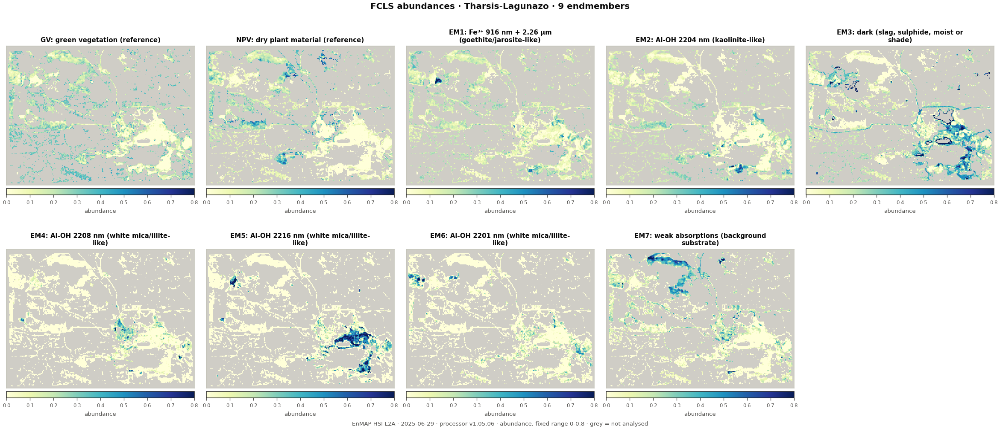

  saved  fig_38a_fcls_rmse.png  +  fig_38a_fcls_rmse.pdf   (400 dpi)


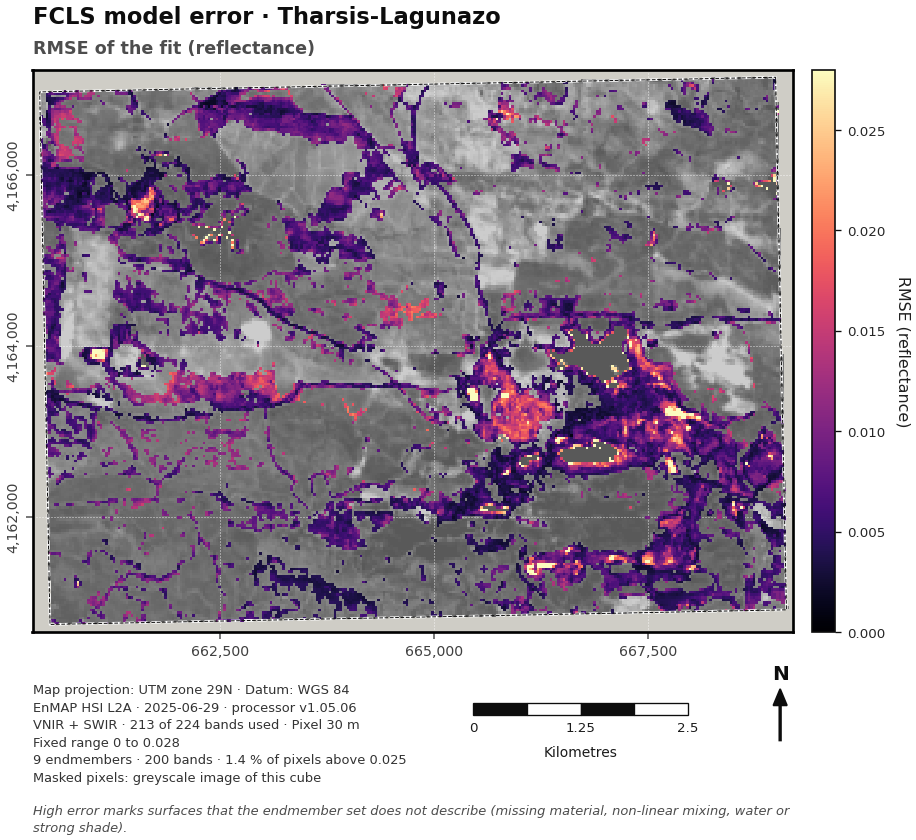

  saved  fig_38b_fcls_residual_spectra.png  +  fig_38b_fcls_residual_spectra.pdf   (400 dpi)


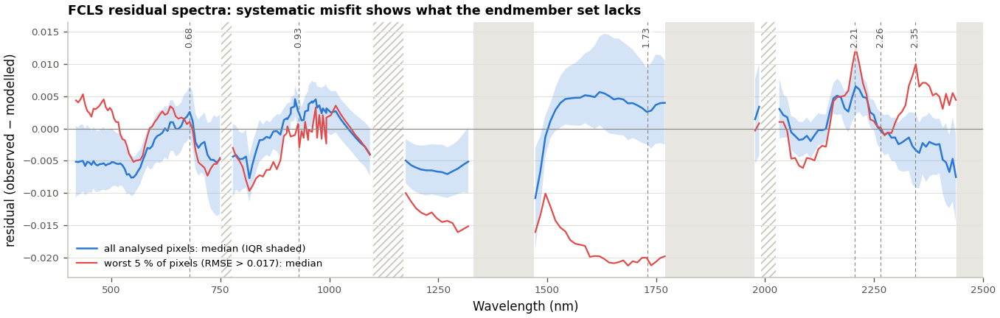

In [21]:
# 15 · FCLS abundances on all analysed pixels
def fraction_panels(layers, titles, suptitle, fname=None, vmin=0.0, vmax=1.0, cmaps="YlGnBu", ncols=4, cbar_label="fraction",
                    note="fixed colour range"):
    """Small multiples of fraction maps on one fixed colour range (comparable between panels); masked pixels grey."""
    n = len(layers); ncols = min(ncols, n); nrows = int(math.ceil(n / ncols))
    aspect = (EXTENT[3] - EXTENT[2]) / (EXTENT[1] - EXTENT[0])
    cmaps = [cmaps] * n if isinstance(cmaps, str) else list(cmaps)
    fig, axes = plt.subplots(nrows, ncols, figsize=(3.9 * ncols, (3.9 * aspect + 0.95) * nrows + 0.7), squeeze=False,
                             layout="constrained")
    for i, ax in enumerate(axes.ravel()):
        if i >= n:
            ax.axis("off"); continue
        cmo = plt.get_cmap(cmaps[i]).copy(); cmo.set_bad(CONT_BG)
        im = ax.imshow(np.ma.masked_invalid(np.asarray(layers[i], dtype="float32")), cmap=cmo, vmin=vmin, vmax=vmax,
                       extent=EXTENT, origin="upper", interpolation="nearest")
        ax.set_title("\n".join(textwrap.wrap(titles[i], 38)), fontsize=9, color=INK)
        ax.set_xticks([]); ax.set_yticks([])
        for s in ax.spines.values():
            s.set_edgecolor("#c3c2b7")
        cb = fig.colorbar(im, ax=ax, orientation="horizontal", fraction=0.06, pad=0.02, aspect=30)
        cb.ax.tick_params(labelsize=7, colors=INK_2); cb.set_label(cbar_label, fontsize=8, color=INK_2)
    fig.suptitle(suptitle, fontsize=12, fontweight="bold", color=INK)
    fig.supxlabel(f"{SENSOR_LABEL} · {note} {vmin:g}-{vmax:g} · grey = not analysed", fontsize=8, color=INK_2)
    if fname:
        save_fig(fig, fname)
    return fig

_t0 = time.time()
FCLS_F, FCLS_RMSE = fcls(X_UNMIX, E_UNMIX)
FCLS_RESID = X_UNMIX - FCLS_F @ E_UNMIX
print(f"FCLS: {N_AN:,} pixels, {N_EM} endmembers, {len(UNMIX_BANDS)} bands in {time.time() - _t0:.1f} s "
      f"(largest deviation of the abundance sum from 1: {np.abs(FCLS_F.sum(axis=1) - 1).max():.1e})")
print(f"RMSE (reflectance): median {np.median(FCLS_RMSE):.4f}, 95th percentile {np.percentile(FCLS_RMSE, 95):.4f}; "
      f"{100 * (FCLS_RMSE > UNMIX_MAX_RMSE).mean():.1f} % of pixels above UNMIX_MAX_RMSE = {UNMIX_MAX_RMSE:g}")

FCLS_TABLE = pd.DataFrame([{"id": EM_IDS[k], "label": EM_LABELS[k], "host_group": EM_HOST[k],
                            "mean_abundance": float(FCLS_F[:, k].mean()),
                            "area_equivalent_km2": float(FCLS_F[:, k].sum() * PIXEL_AREA_KM2),
                            "px_abundance_ge_0.25": int((FCLS_F[:, k] >= 0.25).sum()),
                            "support_px_ge_0.5": int((FCLS_F[:, k] >= 0.5).sum()),
                            "max_abundance": float(FCLS_F[:, k].max()),
                            "px_dominant": int((FCLS_F.argmax(axis=1) == k).sum())} for k in range(N_EM)])
FCLS_TABLE.to_csv(TABLE_DIR / "tab_29_fcls_abundance_summary.csv", index=False, float_format="%.4f", encoding="utf-8-sig")
with pd.option_context("display.width", 250, "display.max_colwidth", 60):
    print(FCLS_TABLE.drop(columns=["host_group"]).round(3).to_string(index=False))
_iso = [EM_IDS[k] for k in range(2, N_EM) if FCLS_TABLE.loc[k, "support_px_ge_0.5"] < EM_MIN_SUPPORT]
if _iso:
    print(f"  NOTE: {', '.join(_iso)} now has fewer than {EM_MIN_SUPPORT} px with abundance ≥ 0.5 in the final model; "
          "read it as a minor component rather than a mappable material.")
if PRUNED_IDS:
    print(f"  Removed in §14 as isolated vertices: {', '.join(PRUNED_IDS)}; their pixels are modelled without them "
          f"(see the RMSE map).")

_rho_gv = stats.spearmanr(FCLS_F[:, 0], NDVI[ANALYSED])[0]
_rho_npv = stats.spearmanr(FCLS_F[:, 1], CAI[ANALYSED])[0]
print(f"\nConsistency: Spearman ρ(GV abundance, NDVI) = {_rho_gv:.2f}; ρ(NPV abundance, CAI) = {_rho_npv:.2f}")
_grp_rows = []
for g in range(len(GROUP_NAMES)):
    s_ = GROUPS == g
    if s_.sum() >= 10:
        _grp_rows.append({"swir_group": GROUP_NAMES[g], "pixels": int(s_.sum()),
                          **{EM_IDS[k]: float(FCLS_F[s_, k].mean()) for k in range(N_EM)}})
FCLS_BY_GROUP = pd.DataFrame(_grp_rows)
FCLS_BY_GROUP.to_csv(TABLE_DIR / "tab_30_fcls_by_swir_group.csv", index=False, float_format="%.4f", encoding="utf-8-sig")
print("Mean FCLS abundance by SWIR group of §7 (rows) and endmember (columns):")
with pd.option_context("display.width", 250):
    print(FCLS_BY_GROUP.assign(swir_group=FCLS_BY_GROUP.swir_group.str.split(" \\(").str[0]).round(2).to_string(index=False))

# figure 37 - abundance maps
fig = fraction_panels([to_map(FCLS_F[:, k]) for k in range(N_EM)],
                      EM_SHORT,
                      f"FCLS abundances · {SITE_NAME} · {N_EM} endmembers", fname="fig_37_fcls_abundances", vmax=0.8,
                      cmaps="YlGnBu", ncols=5, cbar_label="abundance", note="abundance, fixed range")
plt.show()

# figure 38 - model error: map and residual spectra
fig = plot_single_band(to_map(FCLS_RMSE), f"FCLS model error · {SITE_NAME}\nRMSE of the fit (reflectance)",
                       "RMSE (reflectance)", cmap="magma", vmin=0,
                       vmax=round(max(UNMIX_MAX_RMSE, float(np.percentile(FCLS_RMSE, 99))), 3),
                       fname="fig_38a_fcls_rmse",
                       extra=[f"{N_EM} endmembers · {len(UNMIX_BANDS)} bands · {100 * (FCLS_RMSE > UNMIX_MAX_RMSE).mean():.1f} % "
                              f"of pixels above {UNMIX_MAX_RMSE:g}"],
                       caption="High error marks surfaces that the endmember set does not describe (missing material, "
                               "non-linear mixing, water or strong shade).")
plt.show()
fig, ax = plt.subplots(figsize=(11.5, 3.8))
ax.set_xlim(400, 2500); shade_ranges(ax)
_q = np.percentile(FCLS_RESID, [25, 50, 75], axis=0)
_xw = WL[UNMIX_BANDS]
ax.fill_between(*with_gaps(_xw, _q[0]), with_gaps(_xw, _q[2])[1], color=SERIES[0], alpha=0.2, lw=0)
ax.plot(*with_gaps(_xw, _q[1]), color=SERIES[0], lw=1.5, label=f"all analysed pixels: median (IQR shaded)")
_bad = FCLS_RMSE > np.percentile(FCLS_RMSE, 95)
ax.plot(*with_gaps(_xw, np.median(FCLS_RESID[_bad], axis=0)), color=SERIES[7], lw=1.3,
        label=f"worst 5 % of pixels (RMSE > {np.percentile(FCLS_RMSE, 95):.3f}): median")
ax.axhline(0, color=MUTED, lw=0.7)
mark_wavelengths(ax, [(680, "0.68"), (930, "0.93"), (1730, "1.73"), (2206, "2.21"), (2265, "2.26"), (2345, "2.35")])
ax.set_xlabel("Wavelength (nm)"); ax.set_ylabel("residual (observed − modelled)")
ax.set_title("FCLS residual spectra: systematic misfit shows what the endmember set lacks", fontsize=10.5, loc="left")
style_chart(ax); ax.legend(fontsize=8, loc="lower left")
fig.tight_layout(); save_fig(fig, "fig_38b_fcls_residual_spectra"); plt.show()

MESMA: 31 models x 17,050 pixels in 2.5 s; 97.9 % of pixels modelled (RMSE ≤ 0.025, plausible fractions)
Selected model complexity (materials + shade): 2 endmembers 16.9 %, 3 endmembers 47.5 %, 4 endmembers 33.5 %
RMSE of modelled pixels: median 0.0091 (FCLS 0.0070, all substrates at once)
Plant-dominated (shade-normalised GV + NPV > 50 %): 50.0 % of analysed pixels; ambiguous substrate: 8.8 %
                                              class  pixels  percent_of_analysed  area_km2  median_substrate_fraction  median_GV_fraction  median_NPV_fraction  median_shade  median_rmse  pixels_incl_plant_dominated_and_ambiguous
EM1: Fe³⁺ 916 nm + 2.26 µm (goethite/jarosite-like)     359                  2.1     0.323                      0.601               0.000                0.347         0.231        0.012                                       7135
                EM2: Al-OH 2204 nm (kaolinite-like)     516                  3.0     0.464                      0.869               0.000        

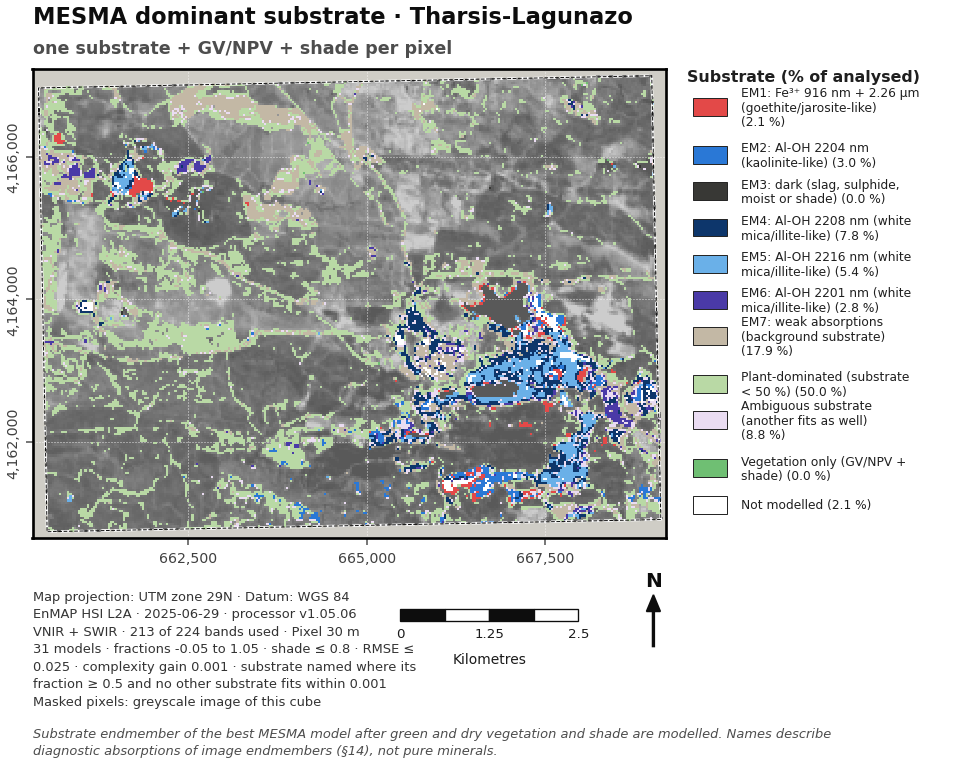

  saved  fig_40_mesma_fractions.png  +  fig_40_mesma_fractions.pdf   (400 dpi)


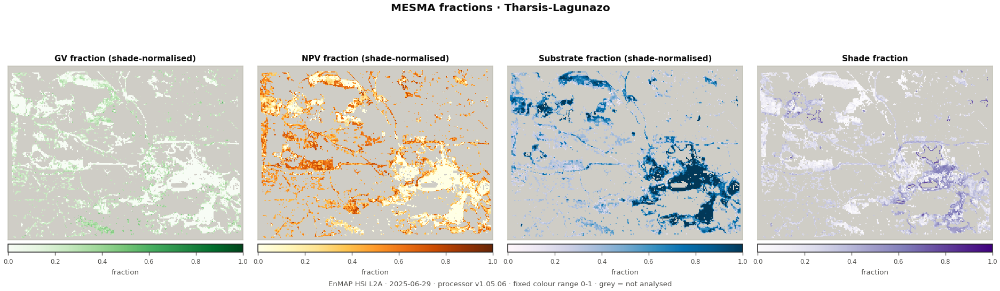

In [22]:
# 15 · MESMA: one substrate endmember + optional GV and NPV + photometric shade
SUB_IDX = list(range(2, N_EM))                                      # substrate (image) endmembers
MESMA_MODELS = ([tuple(sorted((s,) + v)) for s in SUB_IDX for v in ((), (0,), (1,), (0, 1))]
                + [(0,), (1,), (0, 1)])                            # + vegetation-only models
_fmin, _fmax = MESMA_FRACTION_LIMITS
_best = {c: [np.full(N_AN, np.inf), np.full(N_AN, -1), np.zeros((N_AN, N_EM))] for c in (1, 2, 3)}
_best_by_sub = np.full((N_AN, len(SUB_IDX)), np.inf)                # best accepted RMSE of each substrate (any model)
_t0 = time.time()
for mi, m in enumerate(MESMA_MODELS):
    M_ = E_UNMIX[list(m)].T                                         # bands x materials; shade is the zero spectrum
    f_ = X_UNMIX @ np.linalg.pinv(M_).T                            # least squares; shade = 1 - sum(f) closes the sum
    rm_ = np.sqrt(((X_UNMIX - f_ @ M_.T) ** 2).mean(axis=1))
    sh_ = 1.0 - f_.sum(axis=1)
    ok_ = ((f_ >= _fmin) & (f_ <= _fmax)).all(axis=1) & (sh_ >= _fmin) & (sh_ <= MESMA_MAX_SHADE) & (rm_ <= UNMIX_MAX_RMSE)
    b_ = _best[len(m)]
    up_ = ok_ & (rm_ < b_[0])
    b_[0][up_], b_[1][up_] = rm_[up_], mi
    tmp_ = np.zeros((int(up_.sum()), N_EM)); tmp_[:, list(m)] = f_[up_]; b_[2][up_] = tmp_
    s_ = next((e for e in m if e >= 2), None)
    if s_ is not None:
        j_ = SUB_IDX.index(s_)
        _best_by_sub[:, j_] = np.where(ok_, np.minimum(_best_by_sub[:, j_], rm_), _best_by_sub[:, j_])
MESMA_RMSE, MESMA_MODEL, MESMA_F = (a.copy() for a in _best[1])
for c in (2, 3):                                                   # one more endmember only if it pays off
    r_, m_, f_ = _best[c]
    better = np.isfinite(r_) & (~np.isfinite(MESMA_RMSE) | (r_ <= MESMA_RMSE - MESMA_MIN_GAIN))
    MESMA_RMSE[better], MESMA_MODEL[better], MESMA_F[better] = r_[better], m_[better], f_[better]
MODELLED = MESMA_MODEL >= 0
MESMA_RMSE[~MODELLED] = np.nan
MESMA_SHADE = np.where(MODELLED, 1.0 - MESMA_F.sum(axis=1), np.nan)
_den = np.where(MODELLED, MESMA_F.sum(axis=1), np.nan)
with np.errstate(invalid="ignore", divide="ignore"):
    MESMA_GV_N, MESMA_NPV_N = MESMA_F[:, 0] / _den, MESMA_F[:, 1] / _den
    MESMA_SUB_N = MESMA_F[:, 2:].sum(axis=1) / _den
MESMA_N_MAT = np.array([len(MESMA_MODELS[m]) if m >= 0 else 0 for m in MESMA_MODEL])
_sub_of = [next((e for e in m if e >= 2), None) for m in MESMA_MODELS]
MESMA_SUB = np.full(N_AN, -1, dtype=int)                           # position in SUB_IDX of the selected substrate
for mi, s_ in enumerate(_sub_of):
    if s_ is not None:
        MESMA_SUB[MESMA_MODEL == mi] = SUB_IDX.index(s_)
_other = _best_by_sub.copy()
_has = MESMA_SUB >= 0
_other[np.flatnonzero(_has), MESMA_SUB[_has]] = np.inf
MESMA_AMBIGUOUS = _has & (_other.min(axis=1) <= MESMA_RMSE + MESMA_MIN_GAIN)   # another substrate fits as well
MESMA_PLANT_DOM = _has & (MESMA_SUB_N < MESMA_MIN_SUBSTRATE)

nS = len(SUB_IDX)
MESMA_NAMES = [EM_SHORT[s] for s in SUB_IDX] + [f"Plant-dominated (substrate < {100 * MESMA_MIN_SUBSTRATE:.0f} %)",
                                                "Ambiguous substrate (another fits as well)", "Vegetation only (GV/NPV + shade)",
                                                "Not modelled"]
MESMA_COLORS = [EM_COLORS[s] for s in SUB_IDX] + ["#b9d9a5", "#eadcf2", "#6fbf73", "#ffffff"]
MESMA_CLASS = np.full(N_AN, nS + 3, dtype=np.int16)                # not modelled
MESMA_CLASS[MODELLED & ~_has] = nS + 2                             # vegetation-only model
MESMA_CLASS[_has] = MESMA_SUB[_has]
MESMA_CLASS[MESMA_AMBIGUOUS] = nS + 1
MESMA_CLASS[MESMA_PLANT_DOM] = nS                                  # plant dominance overrides ambiguity
print(f"MESMA: {len(MESMA_MODELS)} models x {N_AN:,} pixels in {time.time() - _t0:.1f} s; "
      f"{100 * MODELLED.mean():.1f} % of pixels modelled (RMSE ≤ {UNMIX_MAX_RMSE:g}, plausible fractions)")
print("Selected model complexity (materials + shade): "
      + ", ".join(f"{c + 1} endmembers {100 * (MESMA_N_MAT == c).mean():.1f} %" for c in (1, 2, 3)))
print(f"RMSE of modelled pixels: median {np.nanmedian(MESMA_RMSE):.4f} (FCLS {np.median(FCLS_RMSE):.4f}, all substrates at once)")
print(f"Plant-dominated (shade-normalised GV + NPV > {100 * (1 - MESMA_MIN_SUBSTRATE):.0f} %): "
      f"{100 * MESMA_PLANT_DOM.mean():.1f} % of analysed pixels; ambiguous substrate: "
      f"{100 * (MESMA_AMBIGUOUS & ~MESMA_PLANT_DOM).mean():.1f} %")

mesma_rows = []
for c, n in enumerate(MESMA_NAMES):
    s_ = MESMA_CLASS == c
    med = lambda a: float(np.nanmedian(a[s_])) if s_.any() and np.isfinite(a[s_]).any() else np.nan
    row = {"class": n, "pixels": int(s_.sum()), "percent_of_analysed": round(100 * s_.mean(), 1),
           "area_km2": round(int(s_.sum()) * PIXEL_AREA_KM2, 3), "median_substrate_fraction": med(MESMA_SUB_N),
           "median_GV_fraction": med(MESMA_GV_N), "median_NPV_fraction": med(MESMA_NPV_N), "median_shade": med(MESMA_SHADE),
           "median_rmse": med(MESMA_RMSE)}
    if c < nS:                                                      # same substrate, before the confidence rules
        row["pixels_incl_plant_dominated_and_ambiguous"] = int((MESMA_SUB == c).sum())
    mesma_rows.append(row)
MESMA_TABLE = pd.DataFrame(mesma_rows)
MESMA_TABLE["pixels_incl_plant_dominated_and_ambiguous"] = MESMA_TABLE["pixels_incl_plant_dominated_and_ambiguous"].astype("Int64")
MESMA_TABLE.to_csv(TABLE_DIR / "tab_31_mesma_substrates.csv", index=False, float_format="%.4f", encoding="utf-8-sig")
with pd.option_context("display.width", 250, "display.max_colwidth", 60):
    print(MESMA_TABLE.round(3).to_string(index=False))
print(f"Consistency: ρ(MESMA GV fraction, NDVI) = {stats.spearmanr(MESMA_GV_N[MODELLED], NDVI[ANALYSED][MODELLED])[0]:.2f}; "
      f"ρ(MESMA NPV fraction, CAI) = {stats.spearmanr(MESMA_NPV_N[MODELLED], CAI[ANALYSED][MODELLED])[0]:.2f}")

# figure 39 - dominant substrate
fig = plot_categorical(to_map(MESMA_CLASS, -1, "int16"), f"MESMA dominant substrate · {SITE_NAME}\n"
                       "one substrate + GV/NPV + shade per pixel", MESMA_COLORS,
                       [f"{n} ({p:.1f} %)" for n, p in zip(MESMA_NAMES, MESMA_TABLE.percent_of_analysed)],
                       fname="fig_39_mesma_dominant_substrate", key_title="Substrate (% of analysed)",
                       extra=[f"{len(MESMA_MODELS)} models · fractions {_fmin:g} to {_fmax:g} · shade ≤ {MESMA_MAX_SHADE:g} · "
                              f"RMSE ≤ {UNMIX_MAX_RMSE:g} · complexity gain {MESMA_MIN_GAIN:g} · substrate named where its "
                              f"fraction ≥ {MESMA_MIN_SUBSTRATE:g} and no other substrate fits within {MESMA_MIN_GAIN:g}"],
                       caption="Substrate endmember of the best MESMA model after green and dry vegetation and shade are "
                               "modelled. Names describe diagnostic absorptions of image endmembers (§14), not pure minerals.")
plt.show()
# figure 40 - fractions
fig = fraction_panels([to_map(MESMA_GV_N), to_map(MESMA_NPV_N), to_map(MESMA_SUB_N), to_map(MESMA_SHADE)],
                      ["GV fraction (shade-normalised)", "NPV fraction (shade-normalised)",
                       "Substrate fraction (shade-normalised)", "Shade fraction"],
                      f"MESMA fractions · {SITE_NAME}", fname="fig_40_mesma_fractions",
                      cmaps=["Greens", "YlOrBr", "PuBu", "Purples"], ncols=4, cbar_label="fraction")
plt.show()

## 16 · Vegetation-aware reinterpretation of the absorption features

§11 flagged that the 2.26 and 2.30–2.36 µm depths rise with CAI, and §15 finds many analysed pixels
plant-dominated even after the NDVI and CAI masks of §4. This section asks how much of the rule-based picture of §7
is plant cover.

1. **Class shares against plant fractions.** The SWIR groups and Fe³⁺ classes of §7 are tabulated by bins of the
   FCLS GV and NPV abundances (§15). A class whose share rises steadily with GV or NPV tracks plant cover rather
   than mineralogy. Leaf water absorbs near 0.97 µm (Peñuelas et al., 1993), so green cover moves the apparent Fe³⁺
   minimum beyond 950 nm; dry plant material absorbs near 2.1 and 2.3 µm (lignin and cellulose; Nagler et al.,
   2003).
2. **Vegetation stripping.** The modelled plant contribution is removed,
   s = (x − f_GV · e_GV − f_NPV · e_NPV) / (1 − f_GV − f_NPV), for pixels with f_GV + f_NPV ≤ 0.6, and s runs
   through the unchanged §6–§7 engine (continuum removal, detection with its own pixel noise, rules). Stripping is
   only as good as the two scene references: real shrubs, grasses and litter differ from them, and the division
   amplifies noise and any plant signal left over. The bin table therefore reports stripped results in every bin,
   but **stripped classes are interpreted only in the low-vegetation subset** (FCLS GV ≤ `STRIP_MAX_GV` and
   NPV ≤ `STRIP_MAX_NPV`), where the correction is small. A stripped result that keeps changing with the plant
   fraction (for example an Fe³⁺ minimum that moves towards hematite-like positions as GV rises) is an
   over-correction, not mineralogy.

What this section can support: which §7 classes are robust to plant cover, and whether the 2.30–2.36 µm band
belongs to the substrate (depth unchanged by stripping and independent of NPV) or to litter (depth removed by
stripping). Where the long-wavelength Fe³⁺ class persists in bare, low-vegetation pixels, leaf water is not the
cause; a minimum at 0.95–0.98 µm there coincides with the VNIR/SWIR detector overlap and the 0.94 µm water-vapour
band (§3, §6) or reflects Fe²⁺-bearing phases, which this dataset cannot separate.

Vegetation stripping: 16,100 of 17,050 analysed pixels (f_GV + f_NPV ≤ 0.6) in 5.2 s; low-vegetation subset (GV ≤ 0.15, NPV ≤ 0.15): 5,286 px (31.0 %)

By plant-fraction bin (FCLS), before and after stripping (full table: tab_32):
fraction       bin  pixels  Fe³⁺ Long-wavelength before %  Fe³⁺ Long-wavelength after %  Fe³⁺ Hematite-like before %  Fe³⁺ Hematite-like after %  Fe³⁺ position before nm  Fe³⁺ position after nm  Mg-OH/chlorite-like before %  Mg-OH/chlorite-like after %  MgOH_2330 depth before  MgOH_2330 depth after  FeOH_2265 depth before  FeOH_2265 depth after  AlOH_2200 depth before  AlOH_2200 depth after
      GV 0.00-0.10    5287                         70.531                        62.366                        1.910                       4.064                  956.963                 956.871                        79.346                       72.335                   0.092                  0.088                   0.053                  0.049                   0.046     

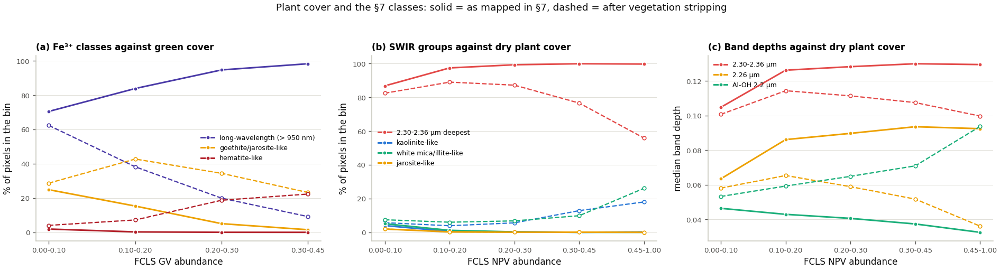

  saved  fig_42a_swir_groups_stripped.png  +  fig_42a_swir_groups_stripped.pdf   (400 dpi)


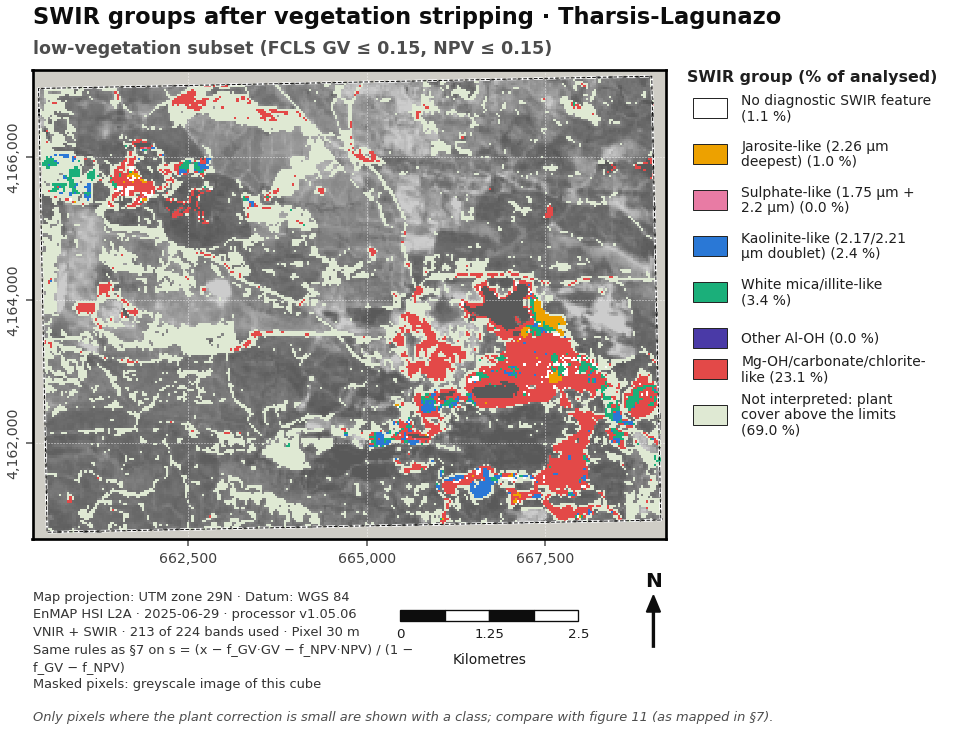

  saved  fig_42b_fe3_classes_stripped.png  +  fig_42b_fe3_classes_stripped.pdf   (400 dpi)


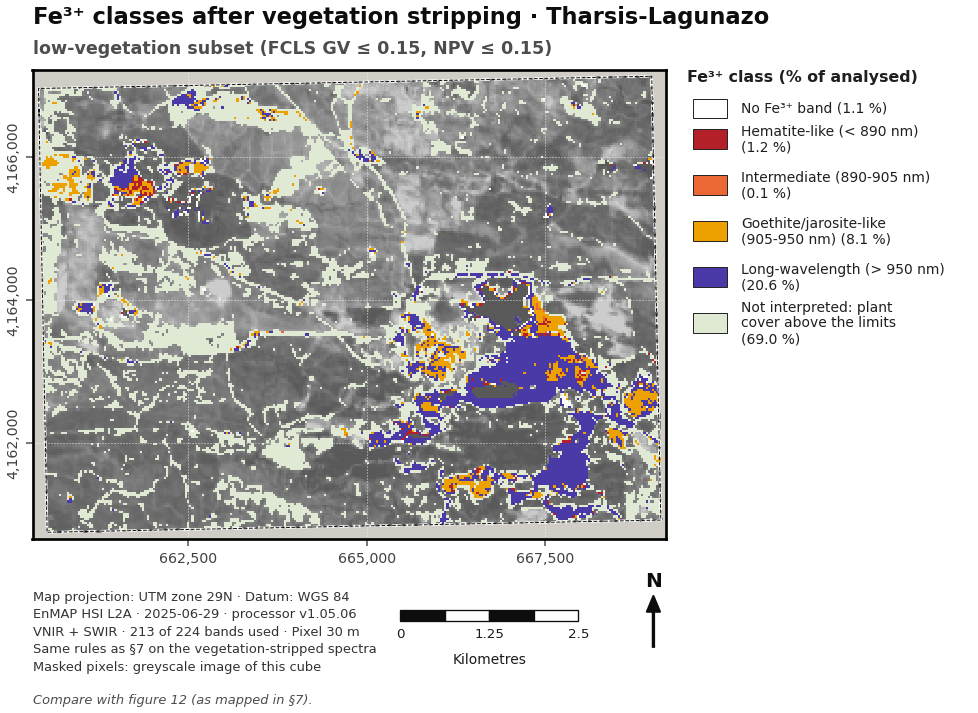

In [23]:
# 16 · Vegetation-aware reinterpretation of the §7 classes
F_GV, F_NPV = FCLS_F[:, 0], FCLS_F[:, 1]
F_VEG = F_GV + F_NPV
STRIPPED = F_VEG <= 0.6                                             # noise amplification at most 2.5 x
RELIABLE_STRIP = (F_GV <= STRIP_MAX_GV) & (F_NPV <= STRIP_MAX_NPV)
_t0 = time.time()
with np.errstate(invalid="ignore"):
    _XS = ((XA[STRIPPED].astype("float64") - F_GV[STRIPPED, None] * GV_REF - F_NPV[STRIPPED, None] * NPV_REF)
           / (1.0 - F_VEG[STRIPPED])[:, None])
RES_S, _ = analyse_spectra(_XS, keep_cr=False)
del _XS
DET_S = detect(RES_S)
G_STRIP = np.full(N_AN, -1, dtype=np.int16); FE_STRIP = np.full(N_AN, -1, dtype=np.int16)
G_STRIP[STRIPPED], FE_STRIP[STRIPPED] = swir_groups(RES_S, DET_S), fe_classes(RES_S, DET_S)
DEPTH_S = {f: np.full(N_AN, np.nan, "float32") for f in FEATURES}
POS_S = {f: np.full(N_AN, np.nan, "float32") for f in FEATURES}
for f in FEATURES:
    DEPTH_S[f][STRIPPED] = np.clip(RES_S[f]["depth_any"], 0, None)
    POS_S[f][STRIPPED] = np.where(DET_S[f], RES_S[f]["pos"], np.nan)
print(f"Vegetation stripping: {int(STRIPPED.sum()):,} of {N_AN:,} analysed pixels (f_GV + f_NPV ≤ 0.6) in "
      f"{time.time() - _t0:.1f} s; low-vegetation subset (GV ≤ {STRIP_MAX_GV:g}, NPV ≤ {STRIP_MAX_NPV:g}): "
      f"{int(RELIABLE_STRIP.sum()):,} px ({100 * RELIABLE_STRIP.mean():.1f} %)")

# 1 - class shares and depths by plant-fraction bin, before and after stripping
VEG_BINS = [0.0, 0.1, 0.2, 0.3, 0.45, 1.01]
_short = lambda n: n.split(" (")[0]
vd_rows = []
for frac_name, frac in (("GV", F_GV), ("NPV", F_NPV)):
    for lo, hi in zip(VEG_BINS[:-1], VEG_BINS[1:]):
        b_ = (frac >= lo) & (frac < hi)
        bs_ = b_ & STRIPPED
        if b_.sum() < 20:
            continue
        row = {"fraction": frac_name, "bin": f"{lo:.2f}-{min(hi, 1):.2f}", "pixels": int(b_.sum()),
               "pixels_stripped": int(bs_.sum())}
        for k in range(len(GROUP_NAMES)):
            row[f"SWIR {_short(GROUP_NAMES[k])} before %"] = 100 * float((GROUPS[b_] == k).mean())
            row[f"SWIR {_short(GROUP_NAMES[k])} after %"] = 100 * float((G_STRIP[bs_] == k).mean()) if bs_.any() else np.nan
        for k in range(len(FE_NAMES)):
            row[f"Fe3 {_short(FE_NAMES[k])} before %"] = 100 * float((FECLS[b_] == k).mean())
            row[f"Fe3 {_short(FE_NAMES[k])} after %"] = 100 * float((FE_STRIP[bs_] == k).mean()) if bs_.any() else np.nan
        for f in ("Fe3_900", "AlOH_2200", "FeOH_2265", "MgOH_2330"):
            row[f"{f} median depth before"] = float(np.median(np.clip(RES[f]["depth_any"][b_], 0, None)))
            row[f"{f} median depth after"] = float(np.nanmedian(DEPTH_S[f][bs_])) if bs_.any() else np.nan
        row["Fe3 median position before nm"] = float(np.nanmedian(np.where(DET["Fe3_900"], RES["Fe3_900"]["pos"], np.nan)[b_]))
        row["Fe3 median position after nm"] = float(np.nanmedian(POS_S["Fe3_900"][bs_])) if bs_.any() else np.nan
        vd_rows.append(row)
VEG_DEP = pd.DataFrame(vd_rows)
VEG_DEP.to_csv(TABLE_DIR / "tab_32_vegetation_dependence.csv", index=False, float_format="%.3f", encoding="utf-8-sig")
_show_cols = ["fraction", "bin", "pixels", "Fe3 Long-wavelength before %", "Fe3 Long-wavelength after %",
              "Fe3 Hematite-like before %", "Fe3 Hematite-like after %", "Fe3 median position before nm",
              "Fe3 median position after nm", "SWIR Mg-OH/carbonate/chlorite-like before %",
              "SWIR Mg-OH/carbonate/chlorite-like after %", "MgOH_2330 median depth before", "MgOH_2330 median depth after",
              "FeOH_2265 median depth before", "FeOH_2265 median depth after", "AlOH_2200 median depth before",
              "AlOH_2200 median depth after"]
with pd.option_context("display.width", 300, "display.max_columns", 30):
    print("\nBy plant-fraction bin (FCLS), before and after stripping (full table: tab_32):")
    print(VEG_DEP[[c for c in _show_cols if c in VEG_DEP]].round(3).rename(columns=lambda c: c.replace("carbonate/", "")
          .replace(" median ", " ").replace("SWIR ", "").replace("Fe3 ", "Fe³⁺ ")).to_string(index=False))

_rho_rows = []
for f in ("Fe3_900", "AlOH_2200", "FeOH_2265", "MgOH_2330"):
    d0 = np.clip(RES[f]["depth_any"][STRIPPED], 0, None); d1 = DEPTH_S[f][STRIPPED]
    _rho_rows.append({"feature": f, "rho_CAI_before": stats.spearmanr(d0, CAI[ANALYSED][STRIPPED])[0],
                      "rho_CAI_after": stats.spearmanr(d1, CAI[ANALYSED][STRIPPED])[0],
                      "rho_NDVI_before": stats.spearmanr(d0, NDVI[ANALYSED][STRIPPED])[0],
                      "rho_NDVI_after": stats.spearmanr(d1, NDVI[ANALYSED][STRIPPED])[0]})
VEG_RHO = pd.DataFrame(_rho_rows)
print("\nSpearman ρ of feature depths with CAI and NDVI, before and after stripping (stripped pixels):")
print(VEG_RHO.round(2).to_string(index=False))

# 2 - areas in the low-vegetation subset
rel_rows = []
for kind, names_, before, after in (("SWIR group", GROUP_NAMES, GROUPS, G_STRIP), ("Fe³⁺ class", FE_NAMES, FECLS, FE_STRIP)):
    for k, n in enumerate(names_):
        b0, b1 = before[RELIABLE_STRIP] == k, after[RELIABLE_STRIP] == k
        rel_rows.append({"type": kind, "class": n, "pixels_before": int(b0.sum()), "pixels_after": int(b1.sum()),
                         "percent_before": 100 * float(b0.mean()), "percent_after": 100 * float(b1.mean()),
                         "jaccard": jaccard(b0, b1)})
STRIP_TABLE = pd.DataFrame(rel_rows)
STRIP_TABLE.to_csv(TABLE_DIR / "tab_33_stripping_low_vegetation_subset.csv", index=False, float_format="%.3f", encoding="utf-8-sig")
print(f"\nLow-vegetation subset ({int(RELIABLE_STRIP.sum()):,} px): classes before and after stripping "
      "(Jaccard ≥ 0.7 = robust to the plant correction):")
print(STRIP_TABLE[(STRIP_TABLE.pixels_before + STRIP_TABLE.pixels_after) > 0].round(2).to_string(index=False))

# figure 41 - dependence on plant fractions
fig, axes = plt.subplots(1, 3, figsize=(16, 4.4))
def _bin_lines(ax, frac_name, cols, colors, labels, ylab, title):
    """Solid: as mapped in §7; dashed: after stripping. cols contain '{}' where 'before'/'after' goes."""
    t_ = VEG_DEP[VEG_DEP.fraction == frac_name]
    x_ = np.arange(len(t_))
    for c, col, lab in zip(cols, colors, labels):
        ax.plot(x_, t_[c.format("before")], "-o", color=col, lw=1.8, ms=4.5, mec="white", label=lab)
        ax.plot(x_, t_[c.format("after")], "--o", color=col, lw=1.4, ms=4, mfc="white")
    ax.set_xticks(x_); ax.set_xticklabels(t_["bin"], fontsize=8)
    ax.set_xlabel(f"FCLS {frac_name} abundance"); ax.set_ylabel(ylab); ax.set_title(title, fontsize=10, loc="left")
    style_chart(ax); ax.legend(fontsize=7.5)

_bin_lines(axes[0], "GV", ["Fe3 Long-wavelength {} %", "Fe3 Goethite/jarosite-like {} %", "Fe3 Hematite-like {} %"],
           [FE_COLORS[4], FE_COLORS[3], FE_COLORS[1]], ["long-wavelength (> 950 nm)", "goethite/jarosite-like", "hematite-like"],
           "% of pixels in the bin", "(a) Fe³⁺ classes against green cover")
_bin_lines(axes[1], "NPV", ["SWIR Mg-OH/carbonate/chlorite-like {} %", "SWIR Kaolinite-like {} %",
                            "SWIR White mica/illite-like {} %", "SWIR Jarosite-like {} %"],
           [GROUP_COLORS[6], GROUP_COLORS[3], GROUP_COLORS[4], GROUP_COLORS[1]],
           ["2.30-2.36 µm deepest", "kaolinite-like", "white mica/illite-like", "jarosite-like"],
           "% of pixels in the bin", "(b) SWIR groups against dry plant cover")
_bin_lines(axes[2], "NPV", ["MgOH_2330 median depth {}", "FeOH_2265 median depth {}", "AlOH_2200 median depth {}"],
           [GROUP_COLORS[6], GROUP_COLORS[1], GROUP_COLORS[4]], ["2.30-2.36 µm", "2.26 µm", "Al-OH 2.2 µm"],
           "median band depth", "(c) Band depths against dry plant cover")
fig.suptitle("Plant cover and the §7 classes: solid = as mapped in §7, dashed = after vegetation stripping", fontsize=11, color=INK)
fig.tight_layout(rect=(0, 0, 1, 0.94)); save_fig(fig, "fig_41_vegetation_dependence"); plt.show()

# figure 42 - stripped classes in the low-vegetation subset
_g_map = np.where(RELIABLE_STRIP, G_STRIP, len(GROUP_NAMES)).astype(np.int16)
_g_share = [100 * float((_g_map == k).mean()) for k in range(len(GROUP_NAMES) + 1)]
fig = plot_categorical(to_map(_g_map, -1, "int16"), f"SWIR groups after vegetation stripping · {SITE_NAME}\n"
                       f"low-vegetation subset (FCLS GV ≤ {STRIP_MAX_GV:g}, NPV ≤ {STRIP_MAX_NPV:g})",
                       GROUP_COLORS + ["#dfe9d3"],
                       [f"{n} ({p:.1f} %)" for n, p in zip(GROUP_NAMES + ["Not interpreted: plant cover above the limits"], _g_share)],
                       fname="fig_42a_swir_groups_stripped", key_title="SWIR group (% of analysed)",
                       extra=["Same rules as §7 on s = (x − f_GV·GV − f_NPV·NPV) / (1 − f_GV − f_NPV)"],
                       caption="Only pixels where the plant correction is small are shown with a class; compare with figure "
                               "11 (as mapped in §7).")
plt.show()
_f_map = np.where(RELIABLE_STRIP, FE_STRIP, len(FE_NAMES)).astype(np.int16)
_f_share = [100 * float((_f_map == k).mean()) for k in range(len(FE_NAMES) + 1)]
fig = plot_categorical(to_map(_f_map, -1, "int16"), f"Fe³⁺ classes after vegetation stripping · {SITE_NAME}\n"
                       f"low-vegetation subset (FCLS GV ≤ {STRIP_MAX_GV:g}, NPV ≤ {STRIP_MAX_NPV:g})",
                       FE_COLORS + ["#dfe9d3"],
                       [f"{n} ({p:.1f} %)" for n, p in zip(FE_NAMES + ["Not interpreted: plant cover above the limits"], _f_share)],
                       fname="fig_42b_fe3_classes_stripped", key_title="Fe³⁺ class (% of analysed)",
                       extra=["Same rules as §7 on the vegetation-stripped spectra"],
                       caption="Compare with figure 12 (as mapped in §7).")
plt.show()

## 17 · How accurate are the abundances? Synthetic mixtures and detection limits

Sub-pixel abundances have no ground truth at 30 m, so their accuracy is estimated by simulation with this scene's
own endmembers and noise. Synthetic pixels mix 2–4 randomly chosen endmembers with random (Dirichlet) abundances
and are unmixed by the same FCLS as in §15.

* **Scenario A, sensor noise:** Gaussian noise with the HySime noise covariance of §14 (regression residuals, i.e.
  random noise without spatial texture). This is the best case.
* **Scenario B, scene residuals:** the FCLS residual spectrum of a randomly drawn analysed pixel is added instead.
  It carries real noise plus everything the linear model misses (variability within a material, non-linear
  mixing, materials outside the endmember set). This is the realistic case.

**Limit of detection (LOD).** For each endmember, synthetic pixels with a known abundance (`LOD_LEVELS`) of it in a
random background of the other endmembers are unmixed under scenario B. The detection threshold is the 95th
percentile of its estimated abundance where it is absent (5 % false alarms). The LOD is the smallest abundance
detected in at least 95 % of the pixels, interpolated linearly between levels. It plays the same role as the
detection limit of the pXRF data: a mapped abundance below the threshold is not distinguishable from absence, and
an endmember that is not mapped can still be present below its LOD. §19 uses the thresholds to blank abundances
that cannot be told from zero.

The simulation assumes a complete endmember set and linear mixing. Its errors are therefore lower bounds for real
pixels, and scenario B is the one to report.

Synthetic mixtures: 3,000 pixels per scenario, 2-4 endmembers each; FCLS fit RMSE median 0.0011 (A) and 0.0059 (B; real pixels 0.0070)
                                                               rmse                               bias                                 r2                   
scenario                                            A: sensor noise B: scene residuals A: sensor noise B: scene residuals A: sensor noise B: scene residuals
endmember                                                                                                                                                   
GV: green vegetation (reference)                              0.001              0.030             0.0             -0.005             1.0              0.980
NPV: dry plant material (reference)                           0.001              0.047             0.0              0.008             1.0              0.954
EM1: Fe³⁺ 916 nm + 2.26 µm (goethite/jarosite-like)           0.001             

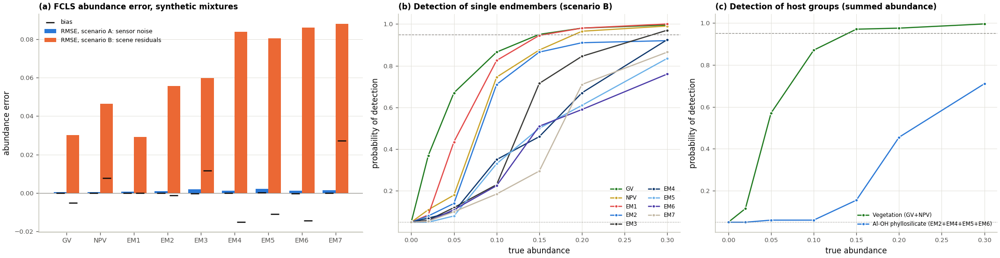

  saved  fig_44_synthetic_true_vs_estimated.png  +  fig_44_synthetic_true_vs_estimated.pdf   (400 dpi)


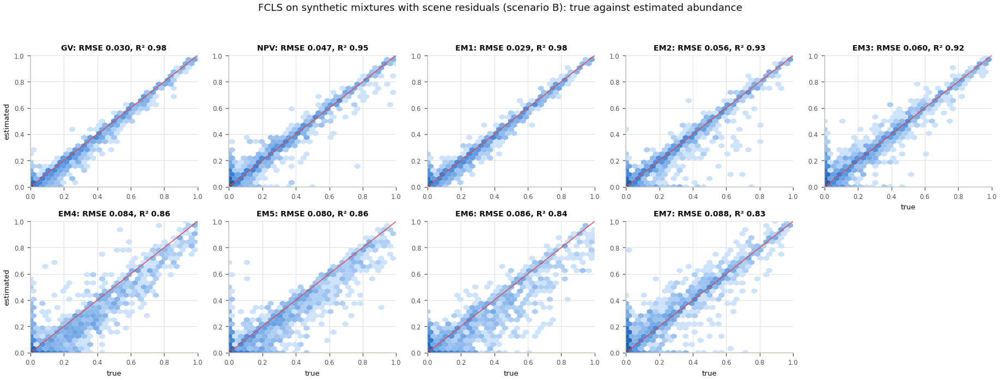

In [24]:
# 17 · Accuracy and detection limits of the FCLS abundances from synthetic mixtures
if not LOD_LEVELS or LOD_LEVELS[0] != 0:
    raise ValueError("LOD_LEVELS must start with 0 (absence), e.g. (0.0, 0.02, 0.05, 0.10, 0.15, 0.20, 0.30)")
_rng_s = np.random.default_rng(RANDOM_STATE + 17)
_ev_n, _V_n = np.linalg.eigh(HYSIME_RN)
_NOISE_SQRT = _V_n @ np.diag(np.sqrt(np.clip(_ev_n, 0, None)))

def synthetic_noise(n, scenario):
    """Scenario A: Gaussian sensor noise (HySime covariance); B: FCLS residuals of random analysed pixels."""
    if scenario == "A":
        return _rng_s.standard_normal((n, len(UNMIX_BANDS))) @ _NOISE_SQRT.T
    return FCLS_RESID[_rng_s.integers(0, N_AN, n)]

def random_abundances(n, exclude=(), k_range=(2, 4)):
    """Rows of abundances: 2-4 random endmembers (never those in `exclude`), Dirichlet(1) weights summing to one."""
    pool = np.array([k for k in range(N_EM) if k not in set(exclude)])
    A = np.zeros((n, N_EM))
    ks = _rng_s.integers(k_range[0], min(k_range[1], len(pool)) + 1, n)
    for i, m in enumerate(ks):
        A[i, _rng_s.choice(pool, m, replace=False)] = _rng_s.dirichlet(np.ones(m))
    return A

_t0 = time.time()
acc_rows, SYNTH = [], {}
for sc, sc_name in (("A", "A: sensor noise"), ("B", "B: scene residuals")):
    A_true = random_abundances(N_SYNTHETIC)
    A_est, rm_syn = fcls(A_true @ E_UNMIX + synthetic_noise(N_SYNTHETIC, sc), E_UNMIX)
    SYNTH[sc] = (A_true, A_est)
    for k in range(N_EM):
        e_ = A_est[:, k] - A_true[:, k]
        ss = float(((A_true[:, k] - A_true[:, k].mean()) ** 2).sum())
        acc_rows.append({"scenario": sc_name, "endmember": EM_SHORT[k], "bias": float(e_.mean()),
                         "mae": float(np.abs(e_).mean()), "rmse": float(np.sqrt((e_ ** 2).mean())),
                         "r2": float(1 - (e_ ** 2).sum() / ss) if ss > 0 else np.nan,
                         "median_fit_rmse": float(np.median(rm_syn))})
ACC_TABLE = pd.DataFrame(acc_rows)
ACC_TABLE.to_csv(TABLE_DIR / "tab_34_synthetic_abundance_accuracy.csv", index=False, float_format="%.4f", encoding="utf-8-sig")
print(f"Synthetic mixtures: {N_SYNTHETIC:,} pixels per scenario, 2-4 endmembers each; FCLS fit RMSE median "
      f"{ACC_TABLE[ACC_TABLE.scenario.str.startswith('A')].median_fit_rmse.iloc[0]:.4f} (A) and "
      f"{ACC_TABLE[ACC_TABLE.scenario.str.startswith('B')].median_fit_rmse.iloc[0]:.4f} (B; real pixels "
      f"{np.median(FCLS_RMSE):.4f})")
with pd.option_context("display.width", 250):
    print(ACC_TABLE.pivot_table(index="endmember", columns="scenario", values=["rmse", "bias", "r2"], sort=False)
          .round(3).to_string())

def detection_curve(members):
    """Estimated summed abundance of `members` at each LOD level (level split at random among them) in random
    backgrounds of the other endmembers, scenario B. Returns the 5 % false-alarm threshold, P(detect) and the LOD."""
    members = list(members)
    est_levels = []
    for a in LOD_LEVELS:
        A_ = random_abundances(LOD_REPLICATES, exclude=members) * (1 - a)
        A_[:, members] = a * (_rng_s.dirichlet(np.ones(len(members)), LOD_REPLICATES) if len(members) > 1
                              else np.ones((LOD_REPLICATES, 1)))
        est_levels.append(fcls(A_ @ E_UNMIX + synthetic_noise(LOD_REPLICATES, "B"), E_UNMIX)[0][:, members].sum(axis=1))
    thr = float(np.percentile(est_levels[0], 95))
    pdet = np.array([float((e_ > thr).mean()) for e_ in est_levels])
    lod = np.nan
    for i in range(1, len(LOD_LEVELS)):
        if pdet[i] >= 0.95:
            a0, a1, p0, p1 = LOD_LEVELS[i - 1], LOD_LEVELS[i], pdet[i - 1], pdet[i]
            lod = a1 if p1 <= p0 else a0 + (0.95 - p0) * (a1 - a0) / (p1 - p0)
            break
    return thr, pdet, lod, est_levels

HOST_MEMBERS = {g: [k for k in range(N_EM) if EM_HOST[k] == g] for g in HOST_GROUPS if g in EM_HOST}
_targets = [("endmember", EM_SHORT[k], [k]) for k in range(N_EM)] + \
           [("host group", g, m) for g, m in HOST_MEMBERS.items() if len(m) > 1]
lod_rows, LOD_CURVES, ABUND_THRESHOLD, GROUP_THRESHOLD = [], {}, np.zeros(N_EM), {}
for kind, name, members in _targets:
    thr, pdet, lod, est_levels = detection_curve(members)
    LOD_CURVES[(kind, name)] = pdet
    if kind == "endmember":
        ABUND_THRESHOLD[members[0]] = thr
    lod_rows.append({"type": kind, "target": name, "members": ", ".join(EM_IDS[k] for k in members),
                     "threshold_5pct_false_alarm": thr,
                     "LOD_95pct_detection": round(lod, 3) if np.isfinite(lod) else f"> {LOD_LEVELS[-1]:g}",
                     **{f"P(detect) at {a:g}": p for a, p in zip(LOD_LEVELS[1:], pdet[1:])},
                     **{f"mean estimate at {a:g}": float(np.mean(e_)) for a, e_ in zip(LOD_LEVELS, est_levels)}})
for g, m in HOST_MEMBERS.items():                                   # single-member groups share their endmember threshold
    GROUP_THRESHOLD[g] = next(r["threshold_5pct_false_alarm"] for r in lod_rows
                              if (r["type"] == "host group" and r["target"] == g) or
                              (len(m) == 1 and r["type"] == "endmember" and r["target"] == EM_SHORT[m[0]]))
LOD_TABLE = pd.DataFrame(lod_rows)
LOD_TABLE.to_csv(TABLE_DIR / "tab_35_detection_limits.csv", index=False, float_format="%.4f", encoding="utf-8-sig")
print(f"\nDetection limits under scenario B ({LOD_REPLICATES} pixels per level; {time.time() - _t0:.1f} s in total). "
      "Host groups sum the abundances of their endmembers:")
with pd.option_context("display.width", 250, "display.max_colwidth", 55):
    print(LOD_TABLE[["type", "target", "threshold_5pct_false_alarm", "LOD_95pct_detection"]
                    + [c for c in LOD_TABLE if c.startswith("P(detect)")]].round(3).to_string(index=False))

# figure 43 - accuracy and detection
fig, axes = plt.subplots(1, 3, figsize=(18, 4.8), gridspec_kw={"width_ratios": [1.15, 1, 1]})
ax = axes[0]
x_ = np.arange(N_EM)
for j, (sc, col) in enumerate((("A: sensor noise", SERIES[0]), ("B: scene residuals", SERIES[1]))):
    t_ = ACC_TABLE[ACC_TABLE.scenario == sc]
    ax.bar(x_ + (j - 0.5) * 0.38, t_.rmse, width=0.38, color=col, label=f"RMSE, scenario {sc}")
    ax.scatter(x_ + (j - 0.5) * 0.38, t_.bias, marker="_", s=120, color=INK, zorder=5, label="bias" if j == 1 else None)
ax.axhline(0, color=MUTED, lw=0.7)
ax.set_xticks(x_); ax.set_xticklabels(EM_IDS, fontsize=8.5)
ax.set_ylabel("abundance error"); ax.set_title("(a) FCLS abundance error, synthetic mixtures", fontsize=10, loc="left")
style_chart(ax); ax.legend(fontsize=7.5)
for ax, kind, title in ((axes[1], "endmember", "(b) Detection of single endmembers (scenario B)"),
                        (axes[2], "host group", "(c) Detection of host groups (summed abundance)")):
    keys = [key for key in LOD_CURVES if key[0] == kind]
    for key in keys:
        if kind == "endmember":
            k = EM_SHORT.index(key[1]); col, lab = EM_COLORS[k], EM_IDS[k]
        else:
            m = HOST_MEMBERS[key[1]]; col = EM_COLORS[m[0]]
            lab = f"{key[1].split(' (')[0]} ({'+'.join(EM_IDS[k] for k in m)})"
        ax.plot(LOD_LEVELS, LOD_CURVES[key], "-o", color=col, lw=1.5, ms=4, mec="white", label=lab)
    ax.axhline(0.95, color=MUTED, lw=0.8, ls="--"); ax.axhline(0.05, color=MUTED, lw=0.8, ls=":")
    ax.set_xlabel("true abundance"); ax.set_ylabel("probability of detection")
    ax.set_title(title, fontsize=10, loc="left"); style_chart(ax, grid_axis="both")
    if keys:
        ax.legend(fontsize=7, ncol=2 if kind == "endmember" else 1, loc="lower right")
    else:
        ax.text(0.5, 0.5, "no host group with more than one endmember", ha="center", va="center", transform=ax.transAxes,
                color=INK_2, fontsize=9)
fig.tight_layout(); save_fig(fig, "fig_43_synthetic_accuracy_lod"); plt.show()

# figure 44 - true against estimated (scenario B)
A_true, A_est = SYNTH["B"]
ncol_ = min(5, N_EM); nrow_ = int(math.ceil(N_EM / ncol_))
fig, axes = plt.subplots(nrow_, ncol_, figsize=(3.1 * ncol_, 3.0 * nrow_), squeeze=False)
for k, ax in enumerate(axes.ravel()):
    if k >= N_EM:
        ax.axis("off"); continue
    ax.hexbin(A_true[:, k], A_est[:, k], gridsize=28, extent=(0, 1, 0, 1), bins="log", cmap=SEQ_BLUE, mincnt=1, linewidths=0)
    ax.plot([0, 1], [0, 1], color=SERIES[7], lw=0.9)
    r_ = ACC_TABLE[(ACC_TABLE.scenario.str.startswith("B")) & (ACC_TABLE.endmember == EM_SHORT[k])].iloc[0]
    ax.set_title(f"{EM_IDS[k]}: RMSE {r_.rmse:.3f}, R² {r_.r2:.2f}", fontsize=8.5)
    ax.set_xlim(0, 1); ax.set_ylim(0, 1); ax.tick_params(labelsize=7)
    if k % ncol_ == 0:
        ax.set_ylabel("estimated", fontsize=8)
    if k >= N_EM - ncol_:
        ax.set_xlabel("true", fontsize=8)
    style_chart(ax, grid_axis="both")
fig.suptitle("FCLS on synthetic mixtures with scene residuals (scenario B): true against estimated abundance",
             fontsize=11, color=INK)
fig.tight_layout(rect=(0, 0, 1, 0.95)); save_fig(fig, "fig_44_synthetic_true_vs_estimated"); plt.show()

## 18 · Sub-pixel target detection (MTMF) for rare, CRM-relevant phases

FCLS and MESMA need an endmember set that describes every pixel. Jarosite-, hematite- or kaolinite-bearing surfaces
cover a few per cent of the analysed area at most, so they rarely form their own N-FINDR vertex and their signal
is spread over other endmembers. **Mixture-tuned matched filtering** (MTMF; Boardman & Kruse, 2011)
looks for one target at a time against the statistics of the whole scene and needs no complete endmember set.

* **Targets** are the §7 class spectra, made purer: the median spectrum of the class pixels whose diagnostic depth
  lies above the `MTMF_TARGET_QUANTILE` quantile (jarosite-like: 2.26 µm depth; sulphate-like: 1.75 µm depth;
  kaolinite-like and white mica/illite-like: Al-OH depth; hematite-like and goethite/jarosite-like Fe³⁺: 0.9 µm
  depth). Classes with fewer than 10 pixels are skipped. The MTMF maps extend these classes to mixed pixels; they are not an independent test
  of them.
* **Space:** the noise-whitened MNF space of §9, components with eigenvalue above `MTMF_MIN_EIGENVALUE`.
* **MF score:** the matched-filter estimate of the target fraction. MF = 1 means as much target material as in the
  pixels the target came from, not 100 % cover; MF around 0 is background.
* **Infeasibility:** the distance of a pixel from the mixing line between the background and the target, in noise
  standard deviations. The allowed spread narrows from the background distribution at MF = 0 to the noise at
  MF = 1, and the value is scaled so that about 1 is feasible. A high MF with a high infeasibility is a false
  positive: the pixel is unusual, but not in the direction of the target.
* **Detection:** MF at or above its median plus `MTMF_MF_K` robust standard deviations (the scatter of MF about 0
  comes from background clutter) and infeasibility at or below the 99th percentile of the background pixels.

The table compares the detections with the rule-based class of the same name: how many detections fall outside that
class (sub-pixel occurrences that the deepest-feature rule does not reach) and the Jaccard index.

**Shoreline check.** Pixels within 60 m of open water or dark pixels (§4) mix water, wet ground and precipitates.
Water absorbs strongly in the NIR and can shift or create apparent Fe³⁺ minima, so every MTMF target and every §7
class is tested for concentration along shorelines (`tab_37`). A layer with three or more times the share of shore
pixels of the analysed area is flagged: it may record genuine Fe-precipitate rims around the acidic pit lakes or a
water-mixing artefact, and only a field check can tell them apart.

  skipped Sulphate-like (1.75 µm): 4 pixels in the §7 class (< 10)
MTMF in 26 MNF components (eigenvalue > 3); detection: MF ≥ median + 3 robust SD and infeasibility ≤ 99th percentile of background pixels
                     target  mf_threshold  infeasibility_threshold  detected_px  detected_pct_of_analysed  detected_km2  area_equivalent_km2  median_mf_detected  rule_class_px  pct_of_detections_outside_rule_class  pct_of_rule_class_detected  jaccard_with_rule_class  false_positive_candidates_px  pct_of_detections_near_water  pct_of_rule_class_near_water
              Jarosite-like         0.185                    1.923          243                     1.425         0.219                0.066               0.282            183                                67.901                      42.623                    0.224                           127                         1.646                         3.279
             Kaolinite-like         0.193                    2.036          518  

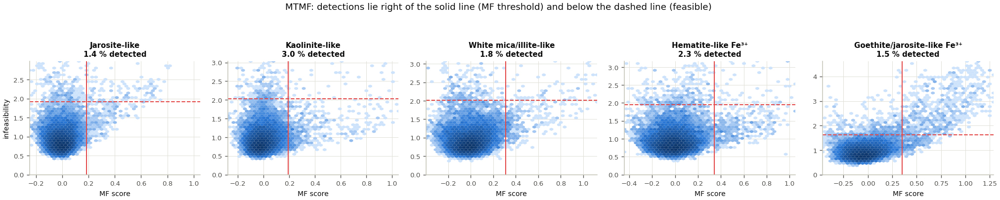

  saved  fig_46_mtmf_detections.png  +  fig_46_mtmf_detections.pdf   (400 dpi)


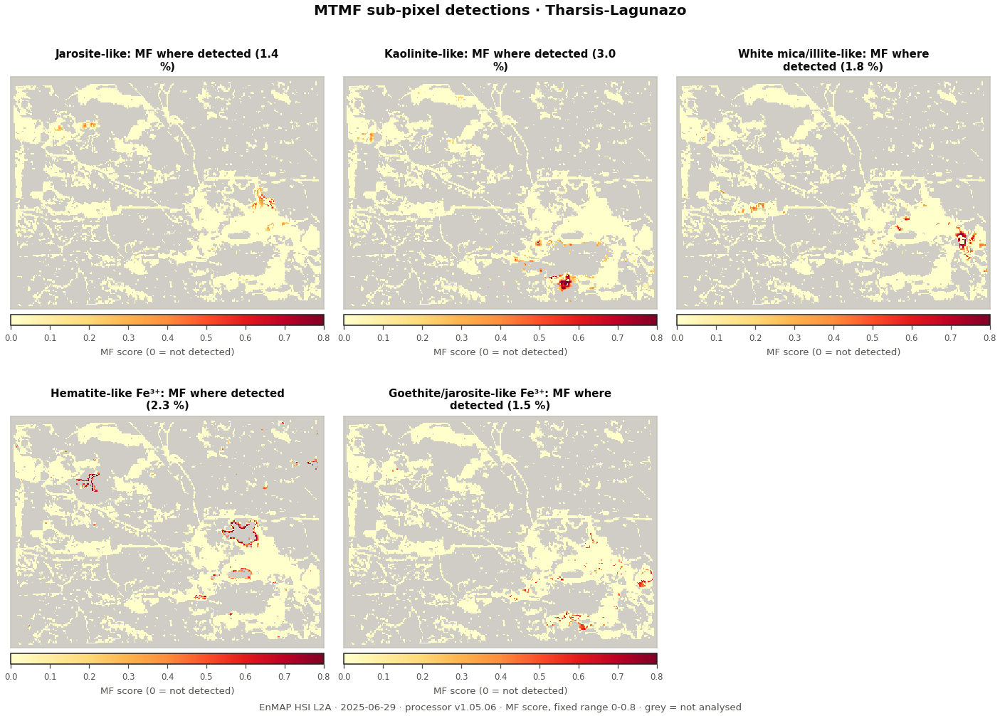

In [25]:
# 18 · MTMF for rare, CRM-relevant phases
from scipy import ndimage
NEAR_WATER = ndimage.binary_dilation(WATER | DARK, iterations=2)[ANALYSED]   # within 2 pixels (60 m) of water or dark pixels
K_MTMF = int(np.sum(MNF_EIG > MTMF_MIN_EIGENVALUE))
if K_MTMF < 3:
    raise RuntimeError(f"Only {K_MTMF} MNF components above MTMF_MIN_EIGENVALUE = {MTMF_MIN_EIGENVALUE}: lower it.")
LAM_MTMF = MNF_EIG[:K_MTMF]
Z_MTMF = mnf_scores(XA, K_MTMF)                                    # centred: background mean at the origin

def mtmf(target_spectrum):
    """MF score and infeasibility of every analysed pixel for one target (Boardman & Kruse, 2011)."""
    tz = mnf_scores(target_spectrum, K_MTMF)[0]
    w = tz / LAM_MTMF
    mf = Z_MTMF @ w / (tz @ w)
    a = np.clip(mf, 0, 1)[:, None]
    sig = (1 - a) * np.sqrt(LAM_MTMF)[None, :] + a                   # background spread -> noise (1 in MNF units)
    inf = np.sqrt((((Z_MTMF - mf[:, None] * tz[None, :]) / sig) ** 2).mean(axis=1))
    return mf.astype("float32"), inf.astype("float32")

_TARGET_DEFS = [("Jarosite-like", GROUPS == 1, "FeOH_2265", GROUP_NAMES[1]),
                ("Sulphate-like (1.75 µm)", GROUPS == 2, "SO4_1750", GROUP_NAMES[2]),
                ("Kaolinite-like", GROUPS == 3, "AlOH_2200", GROUP_NAMES[3]),
                ("White mica/illite-like", GROUPS == 4, "AlOH_2200", GROUP_NAMES[4]),
                ("Hematite-like Fe³⁺", FECLS == 1, "Fe3_900", FE_NAMES[1]),
                ("Goethite/jarosite-like Fe³⁺", FECLS == 3, "Fe3_900", FE_NAMES[3])]
MTMF_TARGETS, MTMF_MF, MTMF_INF, MTMF_DET = [], {}, {}, {}
mt_rows = []
for name, cls_mask, feat, cls_name in _TARGET_DEFS:
    if cls_mask.sum() < 10:
        print(f"  skipped {name}: {int(cls_mask.sum())} pixels in the §7 class (< 10)")
        continue
    d_ = RES[feat]["depth"]
    src = cls_mask & (d_ >= np.quantile(d_[cls_mask], MTMF_TARGET_QUANTILE))
    t_spec = median_spectrum(XA[src])
    mf, inf = mtmf(t_spec)
    med = float(np.median(mf)); rsd = float(1.4826 * np.median(np.abs(mf - med)))
    mf_thr = med + MTMF_MF_K * rsd
    bg = np.abs(mf - med) <= rsd
    inf_thr = float(np.percentile(inf[bg], 99))
    det = (mf >= mf_thr) & (inf <= inf_thr)
    MTMF_TARGETS.append(name); MTMF_MF[name], MTMF_INF[name], MTMF_DET[name] = mf, inf, det
    mt_rows.append({"target": name, "source": f"{int(src.sum())} px of '{cls_name}' above the {MTMF_TARGET_QUANTILE:g} "
                                              f"quantile of {feat} depth",
                    "mf_threshold": mf_thr, "infeasibility_threshold": inf_thr, "detected_px": int(det.sum()),
                    "detected_pct_of_analysed": 100 * float(det.mean()), "detected_km2": float(det.sum() * PIXEL_AREA_KM2),
                    "area_equivalent_km2": float(np.clip(mf[det], 0, 1).sum() * PIXEL_AREA_KM2),
                    "median_mf_detected": float(np.median(mf[det])) if det.any() else np.nan,
                    "rule_class_px": int(cls_mask.sum()),
                    "pct_of_detections_outside_rule_class": 100 * float((det & ~cls_mask).sum() / max(det.sum(), 1)),
                    "pct_of_rule_class_detected": 100 * float((det & cls_mask).sum() / max(cls_mask.sum(), 1)),
                    "jaccard_with_rule_class": jaccard(det, cls_mask),
                    "false_positive_candidates_px": int(((mf >= mf_thr) & (inf > inf_thr)).sum()),
                    "pct_of_detections_near_water": 100 * float(NEAR_WATER[det].mean()) if det.any() else np.nan,
                    "pct_of_rule_class_near_water": 100 * float(NEAR_WATER[cls_mask].mean())})
MTMF_TABLE = pd.DataFrame(mt_rows)
MTMF_TABLE.to_csv(TABLE_DIR / "tab_36_mtmf_targets.csv", index=False, float_format="%.4f", encoding="utf-8-sig")
print(f"MTMF in {K_MTMF} MNF components (eigenvalue > {MTMF_MIN_EIGENVALUE:g}); detection: MF ≥ median + {MTMF_MF_K:g} "
      "robust SD and infeasibility ≤ 99th percentile of background pixels")
with pd.option_context("display.width", 250):
    print(MTMF_TABLE.drop(columns=["source"]).round(3).to_string(index=False))

# shoreline check: pixels next to open water mix water, wet ground and precipitates
sh_rows = [{"layer": f"MTMF {n}", "pixels": int(MTMF_DET[n].sum()), "pct_near_water": 100 * float(NEAR_WATER[MTMF_DET[n]].mean())
            if MTMF_DET[n].any() else np.nan} for n in MTMF_TARGETS]
sh_rows += [{"layer": f"§7 SWIR group: {n}", "pixels": int((GROUPS == k).sum()),
             "pct_near_water": 100 * float(NEAR_WATER[GROUPS == k].mean()) if (GROUPS == k).any() else np.nan}
            for k, n in enumerate(GROUP_NAMES)]
sh_rows += [{"layer": f"§7 Fe³⁺ class: {n}", "pixels": int((FECLS == k).sum()),
             "pct_near_water": 100 * float(NEAR_WATER[FECLS == k].mean()) if (FECLS == k).any() else np.nan}
            for k, n in enumerate(FE_NAMES)]
SHORE_TABLE = pd.DataFrame(sh_rows)
SHORE_TABLE["enrichment_vs_all_analysed"] = SHORE_TABLE.pct_near_water / (100 * NEAR_WATER.mean())
SHORE_TABLE.to_csv(TABLE_DIR / "tab_37_shoreline_check.csv", index=False, float_format="%.3f", encoding="utf-8-sig")
_flag = SHORE_TABLE[(SHORE_TABLE.pixels >= 10) & (SHORE_TABLE.enrichment_vs_all_analysed >= 3)]
print(f"\nShoreline check: {100 * NEAR_WATER.mean():.1f} % of analysed pixels lie within 60 m of open water or dark pixels (§4).")
if len(_flag):
    print("Layers concentrated at shorelines (≥ 3 x that share; ≥ 10 px). Water absorbs strongly in the NIR and shifts or "
          "creates apparent Fe³⁺ minima; shore pixels also mix wet ground and Fe precipitates. Check these in the field:")
    print(_flag.round(1).to_string(index=False))

if MTMF_TARGETS:
    # figure 45 - MF against infeasibility
    n_t = len(MTMF_TARGETS)
    fig, axes = plt.subplots(1, n_t, figsize=(3.4 * n_t, 3.5), squeeze=False)
    for ax, name in zip(axes.ravel(), MTMF_TARGETS):
        mf, inf = MTMF_MF[name], MTMF_INF[name]
        r_ = MTMF_TABLE[MTMF_TABLE.target == name].iloc[0]
        x_hi = max(1.05, float(np.percentile(mf, 99.9))); y_hi = float(np.percentile(inf, 99.8))
        ax.hexbin(mf, inf, gridsize=45, extent=(float(np.percentile(mf, 0.1)), x_hi, 0, y_hi), bins="log", cmap=SEQ_BLUE,
                  mincnt=1, linewidths=0)
        ax.axvline(r_.mf_threshold, color=SERIES[7], lw=1.2); ax.axhline(r_.infeasibility_threshold, color=SERIES[7], lw=1.2, ls="--")
        ax.set_xlim(float(np.percentile(mf, 0.1)), x_hi); ax.set_ylim(0, y_hi)
        ax.set_title(f"{name}\n{r_.detected_pct_of_analysed:.1f} % detected", fontsize=9)
        ax.set_xlabel("MF score", fontsize=8.5); ax.set_ylabel("infeasibility" if ax is axes[0, 0] else "", fontsize=8.5)
        style_chart(ax, grid_axis="both")
    fig.suptitle("MTMF: detections lie right of the solid line (MF threshold) and below the dashed line (feasible)",
                 fontsize=11, color=INK)
    fig.tight_layout(rect=(0, 0, 1, 0.92)); save_fig(fig, "fig_45_mtmf_scatter"); plt.show()
    # figure 46 - detection maps (0 = analysed, not detected)
    fig = fraction_panels([to_map(np.where(MTMF_DET[n], np.clip(MTMF_MF[n], 0, 1), 0.0)) for n in MTMF_TARGETS],
                          [f"{n}: MF where detected ({MTMF_TABLE.loc[MTMF_TABLE.target == n, 'detected_pct_of_analysed'].iloc[0]:.1f} %)"
                           for n in MTMF_TARGETS],
                          f"MTMF sub-pixel detections · {SITE_NAME}", fname="fig_46_mtmf_detections", vmax=0.8, cmaps="YlOrRd",
                          ncols=3, cbar_label="MF score (0 = not detected)", note="MF score, fixed range")
    plt.show()

## 19 · From mineral proxies to CRM host phases

None of the EnMAP layers measures a critical raw material. Bi, Sb, Co, In, Ga and Ge occur at ppm levels and have
no diagnostic absorption between 0.4 and 2.5 µm. Imaging spectroscopy maps the surface phases that **host or sorb**
such elements, and the materials that dilute them. This section groups the endmembers of §14 into **host-phase
groups** and states for each what its presence can and cannot mean for CRM characterisation. The link is an
inference from mineral chemistry that must be tested against the pXRF and FTIR results of the thesis before it
carries weight; `[CONFIRM]` marks what only the site data can decide.

| Host-phase group | Spectral basis | Relevance for CRMs | Caveat |
|---|---|---|---|
| Fe³⁺ oxyhydroxide / sulphate (goethite–jarosite-like) | Fe³⁺ band 0.90–0.95 µm; 2.26 µm band where jarosite-like | Secondary Fe(III) phases of oxidised pyritic waste and gossan. Jarosite-group minerals take up Pb, Ag and As (Dutrizac & Jambor, 2000); Fe(III) oxyhydroxides sorb As and Sb (Cornell & Schwertmann, 2003; Wilson et al., 2010). The most plausible surface proxy for elements retained in the oxidised zone, for this thesis Sb and possibly Bi `[CONFIRM with the pXRF data]` | Goethite and jarosite are not separable by the Fe³⁺ band alone (§7) |
| Hematite-like Fe³⁺ oxide | Fe³⁺ band below 0.89 µm | Aged or dehydrated oxidised material, gossan, or thermally treated (roasted) ore residues `[CONFIRM which occur at Tharsis–Lagunazo]` | Check the shoreline test of §18 |
| Al-OH phyllosilicate (kaolinite, white mica) | Al-OH 2.16–2.23 µm | Host-rock detritus, altered volcanic rock, clay-rich fine tailings. Ga follows Al geochemically (Moskalyk, 2003), so the group can indicate background-level Ga at most, not enrichment | Poorly resolved by reflectance unmixing (§17); the Al-OH depth maps (§6) are more sensitive |
| Fe-Mg-OH phyllosilicate (chlorite-like) | 2.30–2.36 µm band | Chlorite of host shales and altered volcanics; no CRM enrichment expected | Shares the 2.3 µm region with plant litter (§16) |
| Sulphate (gypsum, alunite-like) | 1.75 µm band | Efflorescent salts of acid drainage; soluble metal sulphates store metals temporarily (Jambor et al., 2000) | Seasonal; next to the 1.8–1.95 µm water window |
| Dark, weakly featured material | mean reflectance below 0.10 | Slag, unoxidised sulphide-rich tailings, moist ground or shade. If slag or sulphide-rich tailings, this is where primary slag- or sulphide-hosted metals remain `[CONFIRM in the field]` | Spectrally ambiguous |
| Background substrate (weak features) | no absorption above the 90th scene percentile | Soils and weathered host rock: background | – |
| Man-made C–H surface | 1.73 + 2.31 µm bands without cellulose | Not a mineral; excluded | Could also be resin-rich plant cover |
| Vegetation (GV, NPV) | scene references | Hides the substrate (§15–§16) | – |

**Maps and areas.** For each group the FCLS abundances of its endmembers are summed, and sums below the group's 5 %
false-alarm threshold (§17) are set to zero, so every mapped value is distinguishable from absence. The **area
equivalent** (sum of abundance × pixel area) is the sub-pixel surface of a group. It complements the MESMA area
(pixels where an endmember of the group is the confident dominant substrate) and the MTMF detections of related
targets. Fe(III) oxyhydroxides also form in weathered soils, so outside mapped waste units the Fe³⁺ group is not
specific to waste: low abundances spread over vegetated ground are soil, not a CRM target.

**Links to the thesis data (optional).**

* **pXRF / FTIR samples** (`SAMPLES_CSV`, `SAMPLE_VALUE_COLS`, `SAMPLE_WINDOW` as in §13): the window mean of every
  host-group fraction, MESMA fraction and MTMF score over analysed pixels is correlated with each element by
  Spearman's ρ, and the Benjamini–Hochberg false-discovery rate (Benjamini & Hochberg, 1995) is applied across all
  tests. With 20 samples, |ρ| must exceed about 0.45 to be significant even before that correction. Report n, ρ
  and q, and read the result as consistency, not calibration: a hand sample represents centimetres, a pixel 900 m²
  (§13).
* **Waste units** (`WASTE_UNITS_FILE`: KML/KMZ in WGS 84, or GeoJSON in WGS 84 or in the cube CRS, one name per
  polygon): per unit, the analysed share, the mean composition by host-phase group and the MESMA substrate shares.
  This ties the spectral mapping to the unit-by-unit tonnage and grade estimates. Units with fewer than 10 analysed
  pixels (0.9 ha) are flagged.

                                           host_group         endmembers  threshold_5pct_false_alarm LOD_95pct  fcls_px_above_threshold  fcls_area_equivalent_km2  mesma_confident_dominant_km2  mtmf_detected_km2
                                 Vegetation (GV, NPV)            GV, NPV                       0.048      0.14                    13938                     4.686                         0.000              0.000
Fe³⁺ oxyhydroxide / sulphate (goethite-jarosite-like)                EM1                       0.044     0.157                    13968                     2.075                         0.323              0.429
         Al-OH phyllosilicate (kaolinite, white mica) EM2, EM4, EM5, EM6                       0.165     > 0.3                     9640                     3.346                         2.908              0.725
                       Dark, weakly featured material                EM3                       0.126     0.284                     9386                     

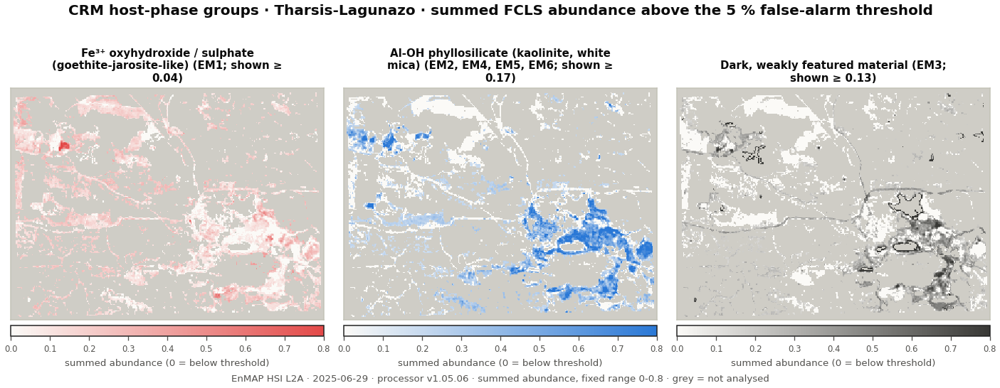

In [26]:
# 19 · Host-phase groups: fractions above the detection threshold, areas and map
HOST_INFO = {
    HOST_GROUPS[1]: ("Fe³⁺ band 0.90-0.95 µm; 2.26 µm band where jarosite-like",
                     "Secondary Fe(III) phases of oxidised pyritic waste and gossan; jarosite-group minerals take up Pb, Ag, As "
                     "(Dutrizac & Jambor, 2000); Fe(III) oxyhydroxides sorb As and Sb (Cornell & Schwertmann, 2003; Wilson "
                     "et al., 2010). Proxy for elements retained in the oxidised zone, here Sb and possibly Bi [CONFIRM with pXRF]",
                     "Goethite and jarosite not separable by the Fe³⁺ band alone"),
    HOST_GROUPS[2]: ("Fe³⁺ band < 0.89 µm", "Aged or dehydrated oxidised material, gossan or roasted ore residues "
                     "[CONFIRM which occur at the site]", "Check the shoreline test (§18)"),
    HOST_GROUPS[3]: ("Al-OH 2.16-2.23 µm", "Host-rock detritus, altered volcanics, clay-rich fine tailings; Ga follows Al "
                     "(Moskalyk, 2003): background-level Ga at most", "Weakly resolved by reflectance unmixing (§17)"),
    HOST_GROUPS[4]: ("2.30-2.36 µm band", "Chlorite of host shales; no CRM enrichment expected", "Overlaps plant litter (§16)"),
    HOST_GROUPS[5]: ("1.75 µm band", "Efflorescent salts; transient metal store (Jambor et al., 2000)", "Seasonal"),
    HOST_GROUPS[6]: ("Mean reflectance < 0.10", "Slag, sulphide-rich tailings, moist ground or shade; if slag or sulphide-rich, "
                     "primary metal hosts [CONFIRM in the field]", "Spectrally ambiguous"),
    HOST_GROUPS[7]: ("1.73 + 2.31 µm without cellulose", "Not a mineral; excluded", "Could be resin-rich plant cover"),
    HOST_GROUPS[8]: ("No absorption above the 90th scene percentile", "Soils and weathered host rock: background", "-"),
    HOST_GROUPS[0]: ("NDVI / CAI scene references", "Hides the substrate", "-"),
    HOST_GROUPS[9]: ("See figure 35", "Interpret from the spectra", "-")}
_MTMF_TO_GROUP = {"Jarosite-like": HOST_GROUPS[1], "Goethite/jarosite-like Fe³⁺": HOST_GROUPS[1],
                  "Hematite-like Fe³⁺": HOST_GROUPS[2], "Kaolinite-like": HOST_GROUPS[3],
                  "White mica/illite-like": HOST_GROUPS[3], "Sulphate-like (1.75 µm)": HOST_GROUPS[5]}
HG_FRAC, HG_FRAC_T = {}, {}
hg_rows = []
for g, members in HOST_MEMBERS.items():
    frac = FCLS_F[:, members].sum(axis=1)
    thr = GROUP_THRESHOLD[g]
    HG_FRAC[g] = frac
    HG_FRAC_T[g] = np.where(frac >= thr, frac, 0.0)
    mesma_px = int(sum((MESMA_CLASS == SUB_IDX.index(k)).sum() for k in members if k in SUB_IDX))
    tg = [n for n in MTMF_TARGETS if _MTMF_TO_GROUP.get(n) == g]
    mt_det = np.any(np.stack([MTMF_DET[n] for n in tg]), axis=0) if tg else np.zeros(N_AN, bool)
    lod_ = LOD_TABLE.loc[(LOD_TABLE.type == ("host group" if len(members) > 1 else "endmember"))
                         & (LOD_TABLE.target == (g if len(members) > 1 else EM_SHORT[members[0]])), "LOD_95pct_detection"]
    basis, relevance, caveat = HOST_INFO.get(g, ("-", "-", "-"))
    hg_rows.append({"host_group": g, "endmembers": ", ".join(EM_IDS[k] for k in members), "spectral_basis": basis,
                    "crm_relevance": relevance, "caveat": caveat, "threshold_5pct_false_alarm": thr,
                    "LOD_95pct": lod_.iloc[0] if len(lod_) else np.nan,
                    "fcls_px_above_threshold": int((frac >= thr).sum()),
                    "fcls_area_equivalent_km2": float(HG_FRAC_T[g].sum() * PIXEL_AREA_KM2),
                    "mesma_confident_dominant_km2": mesma_px * PIXEL_AREA_KM2,
                    "mtmf_targets": ", ".join(tg) if tg else "-", "mtmf_detected_km2": float(mt_det.sum() * PIXEL_AREA_KM2)})
HOST_TABLE = pd.DataFrame(hg_rows)
HOST_TABLE.to_csv(TABLE_DIR / "tab_38_crm_host_phase_groups.csv", index=False, float_format="%.4f", encoding="utf-8-sig")
with pd.option_context("display.width", 250, "display.max_colwidth", 48):
    print(HOST_TABLE[["host_group", "endmembers", "threshold_5pct_false_alarm", "LOD_95pct", "fcls_px_above_threshold",
                      "fcls_area_equivalent_km2", "mesma_confident_dominant_km2", "mtmf_detected_km2"]].round(3).to_string(index=False))
print(f"(areas refer to the {N_AN * PIXEL_AREA_KM2:.2f} km² of analysed pixels; tab_38 holds the spectral basis, CRM relevance "
      "and caveats of each group)")

_MAP_GROUPS = [g for g in HOST_MEMBERS if g not in (HOST_GROUPS[0], HOST_GROUPS[7], HOST_GROUPS[8], HOST_GROUPS[9])]
if _MAP_GROUPS:
    _cm = [LinearSegmentedColormap.from_list(f"hg{i}", ["#fbfaf7", EM_COLORS[HOST_MEMBERS[g][0]]])
           for i, g in enumerate(_MAP_GROUPS)]
    fig = fraction_panels([to_map(HG_FRAC_T[g]) for g in _MAP_GROUPS],
                          [f"{g} ({', '.join(EM_IDS[k] for k in HOST_MEMBERS[g])}; shown ≥ {GROUP_THRESHOLD[g]:.2f})"
                           for g in _MAP_GROUPS],
                          f"CRM host-phase groups · {SITE_NAME} · summed FCLS abundance above the 5 % false-alarm threshold",
                          fname="fig_47_crm_host_phase_groups", vmax=0.8, cmaps=_cm, ncols=min(3, len(_MAP_GROUPS)),
                          cbar_label="summed abundance (0 = below threshold)", note="summed abundance, fixed range")
    plt.show()

In [27]:
# 19 · Optional links: pXRF/FTIR samples and waste units
def to_cube_xy(xs, ys, src_crs):
    """Sample coordinates into the cube CRS; tolerant of a missing EPSG database when both are the cube's UTM zone."""
    xs, ys = np.asarray(xs, float), np.asarray(ys, float)
    if not src_crs:
        return xs, ys
    try:
        same = rasterio.crs.CRS.from_user_input(src_crs) == CRS
    except Exception:
        code = str(src_crs).upper().replace("EPSG:", "").strip()
        if CUBE_UTM_EPSG and code.isdigit() and int(code) == CUBE_UTM_EPSG:
            return xs, ys
        raise ValueError(f"Cannot interpret SAMPLE_CRS = {src_crs!r} (EPSG database unavailable?): give the coordinates "
                         "in the cube CRS and set SAMPLE_CRS = None.")
    if same:
        return xs, ys
    xt, yt = warp_transform(src_crs, CRS, xs, ys)
    return np.asarray(xt), np.asarray(yt)

def window_mean(layer_map, x, y, half):
    """Mean of a map over analysed pixels of the (2 half + 1)^2 window around (x, y); NaN outside or without data."""
    c_f, r_f = ~TRANSFORM * (x, y)
    r0, c0 = int(math.floor(r_f)), int(math.floor(c_f))
    if not (0 <= r0 < H and 0 <= c0 < W):
        return np.nan, 0
    rs, cs = slice(max(r0 - half, 0), min(r0 + half + 1, H)), slice(max(c0 - half, 0), min(c0 + half + 1, W))
    v = layer_map[rs, cs][ANALYSED[rs, cs]]
    v = v[np.isfinite(v)]
    return (float(v.mean()) if v.size else np.nan), int(v.size)

LINK_LAYERS = {f"host: {g}": to_map(HG_FRAC_T[g]) for g in HOST_MEMBERS if g != HOST_GROUPS[0]}
LINK_LAYERS.update({"MESMA GV fraction": to_map(MESMA_GV_N), "MESMA NPV fraction": to_map(MESMA_NPV_N),
                    "MESMA substrate fraction": to_map(MESMA_SUB_N)})
LINK_LAYERS.update({f"MTMF {n} (MF, 0 if not detected)": to_map(np.where(MTMF_DET[n], MTMF_MF[n], 0.0)) for n in MTMF_TARGETS})

SAMPLE_LINK = None
if not SAMPLES_CSV or not SAMPLE_VALUE_COLS:
    print("Sample linkage skipped: set SAMPLES_CSV and SAMPLE_VALUE_COLS (e.g. ['Bi_ppm', 'Sb_ppm', 'Cu_ppm']) in CONFIG.")
else:
    _smp = pd.read_csv(_resolve(SAMPLES_CSV))
    _sx, _sy = to_cube_xy(_smp[SAMPLE_X_COL], _smp[SAMPLE_Y_COL], SAMPLE_CRS)
    _half = SAMPLE_WINDOW // 2
    _feat = {k: np.array([window_mean(m, x, y, _half)[0] for x, y in zip(_sx, _sy)]) for k, m in LINK_LAYERS.items()}
    _n_an = np.array([window_mean(np.ones((H, W), "float32"), x, y, _half)[1] for x, y in zip(_sx, _sy)])
    print(f"Samples: {len(_smp)} read, {int((_n_an > 0).sum())} with analysed pixels in the {SAMPLE_WINDOW} x {SAMPLE_WINDOW} window")
    link_rows = []
    for vc in SAMPLE_VALUE_COLS:
        yv = pd.to_numeric(_smp[vc], errors="coerce").to_numpy(float)
        for k, xv in _feat.items():
            ok = np.isfinite(xv) & np.isfinite(yv)
            if ok.sum() >= 5 and np.ptp(xv[ok]) > 0 and np.ptp(yv[ok]) > 0:
                rho, pval = stats.spearmanr(xv[ok], yv[ok])
            else:
                rho, pval = np.nan, np.nan
            link_rows.append({"element_or_attribute": vc, "enmap_layer": k, "n": int(ok.sum()), "spearman_rho": rho,
                              "p_value": pval})
    SAMPLE_LINK = pd.DataFrame(link_rows)
    _okp = SAMPLE_LINK.p_value.notna()
    SAMPLE_LINK["q_value_BH"] = np.nan
    if _okp.any():
        SAMPLE_LINK.loc[_okp, "q_value_BH"] = stats.false_discovery_control(SAMPLE_LINK.loc[_okp, "p_value"].to_numpy(), method="bh")
    SAMPLE_LINK.to_csv(TABLE_DIR / "tab_39_samples_vs_host_phases.csv", index=False, float_format="%.4f", encoding="utf-8-sig")
    _top = SAMPLE_LINK.dropna(subset=["spearman_rho"]).reindex(
        SAMPLE_LINK.spearman_rho.abs().dropna().sort_values(ascending=False).index)
    print("Strongest associations (all tests with n, ρ, p and Benjamini-Hochberg q in tab_39):")
    print(_top.head(12).round(3).to_string(index=False))
    if (_top.q_value_BH < 0.1).any():
        print(f"  {int((_top.q_value_BH < 0.1).sum())} association(s) with q < 0.1.")
    else:
        print("  No association survives the false-discovery-rate correction (q < 0.1).")
    _pairs = _top.head(6)
    if len(_pairs):
        fig, axes = plt.subplots(1, len(_pairs), figsize=(3.2 * len(_pairs), 3.2), squeeze=False)
        for ax, r_ in zip(axes.ravel(), _pairs.itertuples()):
            xv = _feat[r_.enmap_layer]; yv = pd.to_numeric(_smp[r_.element_or_attribute], errors="coerce").to_numpy(float)
            ok = np.isfinite(xv) & np.isfinite(yv)
            ax.scatter(xv[ok], yv[ok], s=26, color=SERIES[0], edgecolor="white", linewidth=0.8)
            ax.set_xlabel("\n".join(textwrap.wrap(r_.enmap_layer, 30)), fontsize=7.5)
            ax.set_ylabel(r_.element_or_attribute, fontsize=8)
            ax.set_title(f"ρ = {r_.spearman_rho:.2f}, q = {r_.q_value_BH:.2f} (n = {r_.n})", fontsize=8.5)
            style_chart(ax, grid_axis="both")
        fig.suptitle("Samples against host-phase layers (window means over analysed pixels)", fontsize=11, color=INK)
        fig.tight_layout(rect=(0, 0, 1, 0.9)); save_fig(fig, "fig_48_samples_vs_host_phases"); plt.show()

# waste units
def read_named_polygons(path, name_field="name"):
    """[(name, GeoJSON geometry in the cube CRS)] from a KML/KMZ (WGS 84) or GeoJSON (WGS 84 or cube CRS) file."""
    p = str(_resolve(path))
    out = []
    if p.lower().endswith((".kml", ".kmz")):
        if p.lower().endswith(".kmz"):
            with zipfile.ZipFile(p) as z:
                kml_bytes = z.read(next(n for n in z.namelist() if n.lower().endswith(".kml")))
        else:
            kml_bytes = Path(p).read_bytes()
        root = ET.fromstring(kml_bytes)
        local = lambda e: e.tag.split("}")[-1]
        for pm in (e for e in root.iter() if local(e) == "Placemark"):
            name = next((c.text.strip() for c in pm if local(c) == "name" and c.text and c.text.strip()),
                        f"unit {len(out) + 1}")
            polys = []
            for poly in (e for e in pm.iter() if local(e) == "Polygon"):
                outer, inner = [], []
                for bnd in (e for e in poly if local(e) in ("outerBoundaryIs", "innerBoundaryIs")):
                    for c in (e for e in bnd.iter() if local(e) == "coordinates"):
                        ring = [[float(t.split(",")[0]), float(t.split(",")[1])] for t in (c.text or "").split()]
                        if len(ring) >= 3:
                            if ring[0] != ring[-1]:
                                ring.append(ring[0])
                            (outer if local(bnd) == "outerBoundaryIs" else inner).append(ring)
                if outer:
                    polys.append([outer[0]] + inner)
            if polys:
                out.append((name, transform_geom("EPSG:4326", CRS, {"type": "MultiPolygon", "coordinates": polys})))
    else:
        gj = json.loads(Path(p).read_text(encoding="utf-8"))
        feats = gj["features"] if gj.get("type") == "FeatureCollection" else [gj]
        for i, f_ in enumerate(feats):
            geom = f_.get("geometry") if f_.get("type") == "Feature" else f_
            if not geom or geom.get("type") not in ("Polygon", "MultiPolygon"):
                continue
            name = str((f_.get("properties") or {}).get(name_field, f"unit {i + 1}"))
            first = np.asarray(geom["coordinates"][0] if geom["type"] == "Polygon" else geom["coordinates"][0][0], float)
            projected = np.nanmax(np.abs(first[:, :2])) > 180
            out.append((name, geom if projected else transform_geom("EPSG:4326", CRS, geom)))
    if not out:
        raise ValueError(f"No named polygons found in {p}")
    return out

WASTE_UNIT_TABLE = None
if not WASTE_UNITS_FILE:
    print("\nWaste-unit summary skipped: set WASTE_UNITS_FILE to a KML/KMZ or GeoJSON of the waste units (one name per polygon).")
else:
    _units = read_named_polygons(WASTE_UNITS_FILE, WASTE_UNIT_NAME_FIELD)
    _an_map = ANALYSED
    _comp_groups = list(HOST_MEMBERS)
    wu_rows = []
    for name, geom in _units:
        m_ = geometry_mask([geom], out_shape=(H, W), transform=TRANSFORM, invert=True)
        a_ = (m_ & _an_map)[ANALYSED]                                  # analysed pixels of this unit, in XA order
        row = {"unit": name, "pixels_in_unit": int(m_.sum()), "area_ha": round(int(m_.sum()) * PIXEL_M ** 2 / 1e4, 2),
               "analysed_px": int(a_.sum()), "analysed_pct": round(100 * a_.sum() / max(m_.sum(), 1), 1),
               "flag": "fewer than 10 analysed px" if a_.sum() < 10 else ""}
        for g in _comp_groups:
            row[f"mean fraction: {g}"] = float(HG_FRAC[g][a_].mean()) if a_.any() else np.nan
        for c, n in enumerate(MESMA_NAMES):
            row[f"MESMA share: {n}"] = 100 * float((MESMA_CLASS[a_] == c).mean()) if a_.any() else np.nan
        for n in MTMF_TARGETS:
            row[f"MTMF detected %: {n}"] = 100 * float(MTMF_DET[n][a_].mean()) if a_.any() else np.nan
        wu_rows.append(row)
    WASTE_UNIT_TABLE = pd.DataFrame(wu_rows)
    WASTE_UNIT_TABLE.to_csv(TABLE_DIR / "tab_40_waste_units.csv", index=False, float_format="%.4f", encoding="utf-8-sig")
    print(f"\nWaste units: {len(_units)} polygons")
    with pd.option_context("display.width", 250, "display.max_colwidth", 40):
        print(WASTE_UNIT_TABLE[["unit", "pixels_in_unit", "area_ha", "analysed_px", "analysed_pct", "flag"]
                               + [f"mean fraction: {g}" for g in _comp_groups]].round(3).to_string(index=False))
    _wu = WASTE_UNIT_TABLE[WASTE_UNIT_TABLE.analysed_px > 0]
    if len(_wu):
        fig, ax = plt.subplots(figsize=(10, 0.8 + 0.45 * len(_wu)))
        left = np.zeros(len(_wu))
        for g in _comp_groups:
            v = _wu[f"mean fraction: {g}"].to_numpy()
            ax.barh(np.arange(len(_wu)), v, left=left, color=EM_COLORS[HOST_MEMBERS[g][0]], edgecolor="white", lw=0.5,
                    label=g)
            left += v
        ax.set_yticks(np.arange(len(_wu)))
        ax.set_yticklabels([f"{u} (n = {n})" for u, n in zip(_wu.unit, _wu.analysed_px)], fontsize=8)
        ax.invert_yaxis(); ax.set_xlim(0, 1); ax.set_xlabel("mean FCLS abundance (analysed pixels of the unit)")
        ax.set_title("Composition of the waste units by host-phase group", fontsize=10.5, loc="left")
        style_chart(ax, grid_axis="x"); ax.legend(fontsize=7, loc="upper left", bbox_to_anchor=(1.01, 1), frameon=False)
        fig.tight_layout(); save_fig(fig, "fig_49_waste_unit_composition"); plt.show()

Sample linkage skipped: set SAMPLES_CSV and SAMPLE_VALUE_COLS (e.g. ['Bi_ppm', 'Sb_ppm', 'Cu_ppm']) in CONFIG.

Waste-unit summary skipped: set WASTE_UNITS_FILE to a KML/KMZ or GeoJSON of the waste units (one name per polygon).


## 20 · Export: GeoTIFFs

All layers are written on the grid of the loaded window (same CRS and pixel size as the cube). Float layers use NaN
as no-data; class layers use −1. Depth layers are 0 where a pixel was analysed but the feature was not detected, and
NaN where the pixel was masked. `detection_flags.tif` stores one bit per feature (1 Fe³⁺, 2 1.75 µm, 4 Al-OH,
8 2.26 µm, 16 Mg-OH; 255 = not analysed).

Layers of §14–§19: `fcls_abundances.tif` (one band per endmember; band list in `fcls_abundances_bands.csv`),
`fcls_rmse.tif`, `mesma_dominant_substrate.tif` (classes in its legend CSV), `mesma_fractions.tif` (GV, NPV and
substrate, shade-normalised, and shade), `mesma_rmse.tif`, `swir_groups_stripped_lowveg.tif` and
`fe3_classes_stripped_lowveg.tif` (§16; the last code means not interpreted), `mtmf_mf_scores.tif`,
`mtmf_infeasibility.tif` and `mtmf_detected.tif` (one band per target; 1 detected, 0 not, 255 not analysed), and
`crm_host_phase_groups.tif` (summed abundance above the detection threshold, one band per group).

In [28]:
def write_geotiff(name, arr, dtype="float32", nodata=np.nan, descriptions=None):
    arr = np.asarray(arr)
    data = arr[None] if arr.ndim == 2 else arr
    path = RASTER_DIR / f"{name}.tif"
    profile = dict(driver="GTiff", height=H, width=W, count=data.shape[0], dtype=dtype, crs=CRS, transform=TRANSFORM,
                   nodata=nodata, compress="deflate")
    with rasterio.open(path, "w", **profile) as dst:
        dst.write(data.astype(dtype))
        for i, d in enumerate(descriptions or []):
            dst.set_band_description(i + 1, d)
    return path.name

if EXPORT_GEOTIFF:
    written = []
    flags = np.zeros(N_AN, np.uint8)
    for bit, f in zip((1, 2, 4, 8, 16), REQUIRED_FEATURES):
        flags |= (DET[f].astype(np.uint8) * bit)
    for f in FEATURES:
        written.append(write_geotiff(f"depth_{f}", to_map(np.where(DET[f], RES[f]["depth"], 0.0))))
        written.append(write_geotiff(f"position_{f}", to_map(np.where(DET[f], RES[f]["pos"], np.nan))))
    written += [write_geotiff("detection_flags", to_map(flags, 255, "uint8"), "uint8", 255),
                write_geotiff("kaolinite_doublet_ratio", to_map(np.where(DET["AlOH_2200"], RES["doublet"], np.nan))),
                write_geotiff("swir_groups", GROUP_MAP, "int16", -1), write_geotiff("fe3_classes", FE_MAP, "int16", -1),
                write_geotiff("fe_mineral_assemblage", ASSEM_MAP, "int16", -1),
                write_geotiff("mask_classes", MASK_CODE, "int16", -1), write_geotiff("ndvi", NDVI), write_geotiff("cai", CAI),
                write_geotiff("mnf_components", np.stack([to_map(MNF[:, j]) for j in range(N_KEEP)]),
                              descriptions=[f"MNF {j + 1}" for j in range(N_KEEP)]),
                write_geotiff("spectral_domains", DOMAIN_MAP, "int16", -1)]
    if SAM_CLASS is not None:
        written += [write_geotiff("sam_library_classes", to_map(SAM_CLASS, -1, "int16"), "int16", -1),
                    write_geotiff("sam_best_angle", to_map(SAM_ANGLE))]
    # layers of §14-§19
    written += [write_geotiff("fcls_abundances", np.stack([to_map(FCLS_F[:, k]) for k in range(N_EM)]), descriptions=EM_SHORT),
                write_geotiff("fcls_rmse", to_map(FCLS_RMSE)),
                write_geotiff("mesma_dominant_substrate", to_map(MESMA_CLASS, -1, "int16"), "int16", -1),
                write_geotiff("mesma_fractions", np.stack([to_map(MESMA_GV_N), to_map(MESMA_NPV_N), to_map(MESMA_SUB_N),
                                                           to_map(MESMA_SHADE)]),
                              descriptions=["GV (shade-normalised)", "NPV (shade-normalised)", "substrate (shade-normalised)", "shade"]),
                write_geotiff("mesma_rmse", to_map(MESMA_RMSE)),
                write_geotiff("swir_groups_stripped_lowveg",
                              to_map(np.where(RELIABLE_STRIP, G_STRIP, len(GROUP_NAMES)).astype("int16"), -1, "int16"), "int16", -1),
                write_geotiff("fe3_classes_stripped_lowveg",
                              to_map(np.where(RELIABLE_STRIP, FE_STRIP, len(FE_NAMES)).astype("int16"), -1, "int16"), "int16", -1),
                write_geotiff("crm_host_phase_groups", np.stack([to_map(HG_FRAC_T[g]) for g in HOST_MEMBERS]),
                              descriptions=list(HOST_MEMBERS))]
    if MTMF_TARGETS:
        written += [write_geotiff("mtmf_mf_scores", np.stack([to_map(MTMF_MF[n]) for n in MTMF_TARGETS]), descriptions=MTMF_TARGETS),
                    write_geotiff("mtmf_infeasibility", np.stack([to_map(MTMF_INF[n]) for n in MTMF_TARGETS]),
                                  descriptions=MTMF_TARGETS),
                    write_geotiff("mtmf_detected", np.stack([to_map(MTMF_DET[n].astype("uint8"), 255, "uint8") for n in MTMF_TARGETS]),
                                  "uint8", 255, descriptions=MTMF_TARGETS)]
    _not_int = "Not interpreted: plant cover above the limits"
    pd.DataFrame({"band": range(1, N_EM + 1), "endmember": EM_SHORT, "host_group": EM_HOST}).to_csv(
        RASTER_DIR / "fcls_abundances_bands.csv", index=False, encoding="utf-8-sig")
    pd.DataFrame({"code": range(len(MESMA_NAMES)), "mesma_class": MESMA_NAMES}).to_csv(
        RASTER_DIR / "mesma_dominant_substrate_legend.csv", index=False, encoding="utf-8-sig")
    pd.DataFrame({"code": range(len(GROUP_NAMES) + 1), "swir_group": GROUP_NAMES + [_not_int]}).to_csv(
        RASTER_DIR / "swir_groups_stripped_lowveg_legend.csv", index=False, encoding="utf-8-sig")
    pd.DataFrame({"code": range(len(FE_NAMES) + 1), "fe3_class": FE_NAMES + [_not_int]}).to_csv(
        RASTER_DIR / "fe3_classes_stripped_lowveg_legend.csv", index=False, encoding="utf-8-sig")
    pd.DataFrame({"band": range(1, len(HOST_MEMBERS) + 1), "host_group": list(HOST_MEMBERS),
                  "endmembers": [", ".join(EM_IDS[k] for k in m) for m in HOST_MEMBERS.values()],
                  "threshold": [GROUP_THRESHOLD[g] for g in HOST_MEMBERS]}).to_csv(
        RASTER_DIR / "crm_host_phase_groups_bands.csv", index=False, float_format="%.4f", encoding="utf-8-sig")
    pd.DataFrame({"code": range(len(GROUP_NAMES)), "swir_group": GROUP_NAMES}).to_csv(RASTER_DIR / "swir_groups_legend.csv", index=False, encoding="utf-8-sig")
    pd.DataFrame({"code": range(len(FE_NAMES)), "fe3_class": FE_NAMES}).to_csv(RASTER_DIR / "fe3_classes_legend.csv", index=False, encoding="utf-8-sig")
    pd.DataFrame({"code": range(len(ASSEMBLAGE_NAMES)), "assemblage": ASSEMBLAGE_NAMES}).to_csv(RASTER_DIR / "fe_mineral_assemblage_legend.csv", index=False, encoding="utf-8-sig")
    pd.DataFrame({"code": range(len(MASK_NAMES)), "mask_class": MASK_NAMES}).to_csv(RASTER_DIR / "mask_classes_legend.csv", index=False, encoding="utf-8-sig")
    print(f"{len(written)} GeoTIFFs written to {RASTER_DIR} (legends as CSV):")
    print("  " + "\n  ".join(written))

31 GeoTIFFs written to enmap_outputs_r8\rasters (legends as CSV):
  depth_Fe3_900.tif
  position_Fe3_900.tif
  depth_SO4_1750.tif
  position_SO4_1750.tif
  depth_AlOH_2200.tif
  position_AlOH_2200.tif
  depth_FeOH_2265.tif
  position_FeOH_2265.tif
  depth_MgOH_2330.tif
  position_MgOH_2330.tif
  detection_flags.tif
  kaolinite_doublet_ratio.tif
  swir_groups.tif
  fe3_classes.tif
  fe_mineral_assemblage.tif
  mask_classes.tif
  ndvi.tif
  cai.tif
  mnf_components.tif
  spectral_domains.tif
  fcls_abundances.tif
  fcls_rmse.tif
  mesma_dominant_substrate.tif
  mesma_fractions.tif
  mesma_rmse.tif
  swir_groups_stripped_lowveg.tif
  fe3_classes_stripped_lowveg.tif
  crm_host_phase_groups.tif
  mtmf_mf_scores.tif
  mtmf_infeasibility.tif
  mtmf_detected.tif


In [29]:
def _this_run(folder, pattern):
    files = sorted(folder.glob(pattern))
    new = [p.name for p in files if p.stat().st_mtime >= RUN_STARTED - 1]
    return new, len(files) - len(new)
(figs, old_f), (tabs, old_t), (rasters, old_r) = (_this_run(FIG_DIR, "*.png"), _this_run(TABLE_DIR, "*.csv"),
                                                   _this_run(RASTER_DIR, "*.tif"))
print(f"Run: {SENSOR_LABEL} · {MODE_LABEL} · {PIXEL_NOTE} · {N_AN:,} analysed pixels")
print(f"\nFigures ({len(figs)}) in {FIG_DIR}  [PNG {FIG_DPI} dpi + vector PDF]:")
print("  " + "\n  ".join(figs))
print(f"\nTables ({len(tabs)}) in {TABLE_DIR}  [UTF-8 with BOM, so Excel shows Fe³⁺ and ρ correctly]:")
print("  " + "\n  ".join(tabs))
print(f"\nGeoTIFFs ({len(rasters)}) in {RASTER_DIR}:")
print("  " + "\n  ".join(rasters))
if old_f + old_t + old_r:
    print(f"\nNOT listed: {old_f} figures, {old_t} tables and {old_r} GeoTIFFs in these folders are older than this run "
          "(earlier runs or other settings). Delete them before copying the folder into the thesis.")

Run: EnMAP HSI L2A · 2025-06-29 · processor v1.05.06 · VNIR + SWIR · 213 of 224 bands used · Pixel 30 m · 17,050 analysed pixels

Figures (46) in enmap_outputs_r8\figures  [PNG 400 dpi + vector PDF]:
  fig_00_band_quality.png
  fig_01_analysis_mask.png
  fig_02_mask_indices.png
  fig_03_natural_colour.png
  fig_04_colour_infrared.png
  fig_05_swir_composite.png
  fig_06_mean_spectra_overlap.png
  fig_07_detection_diagnostics.png
  fig_08a_depth_Fe3_900.png
  fig_08b_depth_SO4_1750.png
  fig_08c_depth_AlOH_2200.png
  fig_08d_depth_FeOH_2265.png
  fig_08e_depth_MgOH_2330.png
  fig_09a_position_Fe3.png
  fig_09b_position_AlOH.png
  fig_10_position_histograms.png
  fig_11_swir_groups.png
  fig_12_fe3_classes.png
  fig_13_fe_mineral_assemblage.png
  fig_14_depth_rgb.png
  fig_15_swir_group_spectra.png
  fig_16_fe3_class_spectra.png
  fig_19_mnf_eigenvalues_loadings.png
  fig_20_mnf_components.png
  fig_21_spectral_domains.png
  fig_22_domain_spectra.png
  fig_26_threshold_sensitivity.png
  